In [ ]:
h

# Nelson-Siegel Residual Reversal: Power Futures

## Research specification and reproducibility

This notebook studies one signal: **reversal of deviations from a Nelson-Siegel fit of the power-futures curve**. The curve may be estimated on the deepest valid contiguous strip up to M8, while the production trade is deliberately capped at **M5 for liquidity governance**. M6-M8 can improve curve estimation but are not production trading legs.

The notebook is designed so that empirical results come from executable cells rather than frozen prose. **All saved outputs are intentionally cleared in this version. Re-run from the top against the source workbooks before using any reported statistic.**

Key implementation conventions in this version:

- `LAMBDA_TRADE` is **selected by the existing TRAIN-only optimization**. It is not hardcoded. The selected value is printed explicitly when the optimization runs.
- The NS projection is expressed first in **contract-quantity space**. It is then converted to price-consistent notional weights before percentage-return P&L is calculated, so factor neutrality and P&L use the same economic units.
- Roll protection is **all-or-nothing at the market-spread level**: if any required leg is inside the roll-out buffer, the complete spread is flattened for that formation date. Intentional flat days remain zero-P&L observations and their exit/re-entry turnover is charged.
- Generic ranks are labels only. P&L is calculated on the same **specific contract** across dates.
- No signal or ticker forward filling is allowed: `ffill_limit=None` throughout.
- The ADF diagnostic is run on a consistently oriented **signed null-space residual coordinate**, with lags constructed only inside uninterrupted specific-contract segments.
- EWMA covariance matrices are projected to PSD after missing-data updates and after shrinkage; market/pair overlap is checked causally before a covariance is used.
- HAC inference reports sensitivity to Newey-West lags **5, 10, 21 and 42**; the default summary uses 21 lags.

### M5 trading-depth governance

M1-M4 is the permanent production floor. M5 is the only deferred contract eligible for trading, and only when the causal liquidity/capacity framework can support the desired allocation. M6-M8 are **fit-only inputs**. In this version it is a frozen liquidity/governance rule: the production code does not use TEST Sharpe to choose trading depth.

---


---

## Second hardening pass

This version incorporates a second independent audit of the research and execution
plumbing. The changes are deliberately split into **mechanical corrections** and
**diagnostics** so research choices are not silently changed after looking at TEST.

Mechanical corrections:
- contract-level roll protection uses actual business days remaining in the contract month,
  rather than the NS maturity coordinate;
- partial P&L coverage is no longer booked by replacing an unmeasured held leg with
  a zero return; a held market requires complete measurable P&L;
- portfolio aggregation is based on ex-ante live markets rather than ex-post
  availability;
- covariance EWMA no longer contains an arbitrary identity-matrix prior;
- repeated maturity parsing and covariance shrinkage are cached;
- rebalance tests cannot carry stale positions indefinitely;
- linear algebra projects directly from `X`/SVD rather than inverting `X'X`.

Diagnostics / disclosure:
- M1-M4 is explicitly identified as a one-dimensional **sign × fixed asset** signal;
  residual magnitude is not used by the production baseline;
- `lag=1` is explicitly labelled **zero additional implementation delay** because
  the signal formed from settlement t-1 earns the t-1 -> t close-to-close return;
- the lag ladder benchmarks decay using the traded signed null coordinate `z=n'e`;
- fit-depth-change P&L is reported because `LAMBDA_FIT=None` is intentionally retained;
- ADF inference uses a train-only empirical unit-root bootstrap on the traded
  coordinate rather than textbook Dickey-Fuller critical values;
- NS R² is reported by fit depth;
- Sharpe uncertainty uses block-bootstrap / serial-correlation-aware diagnostics;
- multiple-testing sensitivity is reported rather than hidden behind a single
  headline Sharpe.

`LAMBDA_FIT` and the TRAIN-only `LAMBDA_TRADE` optimization are intentionally left
unchanged in this pass.


---

## Validation upgrades in this version

- strict 100% held-leg return coverage; no missing held return is booked as zero;
- all-or-nothing roll flattening is audited by market and year;
- fit-depth-change P&L attribution is reported for FULL and TEST;
- the 2021H2-2022 power-crisis contribution is reported separately;
- ADF inference uses a 1,999-draw TRAIN-only empirical unit-root block bootstrap,
  with BH/Holm multiple-testing adjustments and a global Cauchy combination test.
- executed production P&L is attributed exactly by formation rank M1-M5 and reconciled back to portfolio P&L;
- a liquidity-aware equal-weight long-M1 power benchmark uses the same causal capacity, roll, coverage and transaction-cost conventions;
- adaptive `LAMBDA_FIT=None` is compared against a fixed-fit-lambda diagnostic without changing the production specification.

Empirical values are intentionally printed by code rather than frozen into markdown.

## Third hardening pass

This version closes the remaining code-review issues from the v2/v3 audit:

- execution-cache keys identify the actual price/ticker DataFrame objects, and a cache-clear helper is exposed for deliberate in-place data mutation;
- the no-contract (`C == 0`) branch populates every execution output panel and asserts column alignment before aggregation;
- circular-block bootstrap infrastructure is defined before any consumer, eliminating cell-order-dependent behavior;
- deflated-Sharpe sensitivity uses a serial-dependence-aware circular-block-bootstrap Sharpe SE;
- production sizing is selected only on the **back half of TRAIN FULL**, using causal sizing rules;
- the M4-versus-M5 comparison is explicitly labelled a strategy-extension test because M5 increases the NS null-space dimension from one to two;
- the research universe is defined from the configured market list plus M1-M4 schema presence, not full-sample observation counts; historical rank eligibility remains causal;
- the magnitude diagnostic is written explicitly in formation-time coordinates before being shifted to execution time;
- duplicate NS-curvature code is removed.

Empirical outputs remain generated by code and saved outputs are cleared before distribution.


In [1]:
# ============================================================
# NELSON-SIEGEL POWER FUTURES PROJECT
# DATA, ROLL-SAFE RETURNS, NS FITTING & ROBUSTNESS
# ============================================================

import numpy as np
import pandas as pd
import re
from scipy.stats import skew, kurtosis, norm
import statsmodels.api as sm
import matplotlib.pyplot as plt


TRADING_DAYS = 252


# ============================================================
# DATA VERSIONING FOR EXECUTION CACHE
# ============================================================
# Increment this whenever the authoritative price/ticker panels are loaded
# or deliberately mutated in place. Cache keys never depend on CPython
# object addresses, which may be recycled.
_DATA_VERSION = 0
_EXECUTION_DATA_CACHE = {}

def bump_data_version():
    """Call after loading or mutating prices/tickers in place."""
    global _DATA_VERSION
    _DATA_VERSION += 1
    _EXECUTION_DATA_CACHE.clear()
    return _DATA_VERSION


# ============================================================
# 1. POWER MARKET UNIVERSE
# ============================================================
#
# Labels are deliberately kept neutral because the Bloomberg
# roots themselves are the authoritative identifiers in the files.
#
# The complete configured universe is loaded. Any exclusion must be explicit
# and data-supported in EXCLUDED_POWER_MARKETS; no market is excluded by a
# stale comment or hidden assertion.
# ============================================================

POWER_MARKETS_ALL = {
    "ZUB": "ZUB",
    "ITP": "ITP",
    "DET": "DET",
    "FAC": "FAC",
    "DFP": "DFP",
    "SXD": "SXD",
    "UTD": "UTD",
    "MSP": "MSP",
    "PHB": "PHB",
    "PCB": "PCB",
}

EXCLUDED_POWER_MARKETS = {}

POWER_MARKETS = {
    root: label
    for root, label in POWER_MARKETS_ALL.items()
    if root not in EXCLUDED_POWER_MARKETS
}


# ============================================================
# 2. ROBUST BLOOMBERG EXCEL LOADER
# ============================================================

def convert_excel_dates(s):
    """
    Convert a Bloomberg Excel date column robustly.

    Bloomberg exports can contain a MIX of true Excel datetimes and raw Excel
    serial numbers in the same column (for example, the last few rows after a
    refresh).  A whole-column dtype test is therefore not sufficient: passing
    an isolated serial such as 46241 to pd.to_datetime() interprets it as
    nanoseconds since 1970 rather than as an Excel day number.

    Parse numeric cells element-by-element as Excel serial days and parse all
    other cells as normal datetimes.
    """
    s = s.copy()

    if pd.api.types.is_datetime64_any_dtype(s):
        return pd.to_datetime(s, errors="coerce")

    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")

    def _is_numeric_cell(x):
        return (
            isinstance(x, (int, float, np.integer, np.floating))
            and not isinstance(x, (bool, np.bool_))
            and pd.notna(x)
        )

    numeric_mask = s.map(_is_numeric_cell)

    if numeric_mask.any():
        serial = pd.to_numeric(s.loc[numeric_mask], errors="coerce")
        out.loc[numeric_mask] = pd.to_datetime(
            serial,
            unit="D",
            origin="1899-12-30",
            errors="coerce",
        ).to_numpy()

    if (~numeric_mask).any():
        out.loc[~numeric_mask] = pd.to_datetime(
            s.loc[~numeric_mask],
            errors="coerce",
        ).to_numpy()

    return out


def clean_contract_name(x):
    return str(x).replace(" ", "")


def load_and_align_excel(path, numeric=True, sheet_name=0):
    """Load Bloomberg paired (date, value) columns onto one DatetimeIndex."""
    raw = pd.read_excel(path, sheet_name=sheet_name)
    aligned = []

    for i in range(0, raw.shape[1] - 1, 2):
        name = clean_contract_name(raw.columns[i + 1])
        tmp = raw.iloc[:, [i, i + 1]].copy()
        tmp.columns = ["Date", name]
        tmp["Date"] = convert_excel_dates(tmp["Date"])

        if numeric:
            tmp[name] = pd.to_numeric(tmp[name], errors="coerce")

        tmp = (
            tmp.dropna(subset=["Date"])
               .drop_duplicates(subset="Date", keep="last")
               .set_index("Date")
        )
        aligned.append(tmp)

    df = pd.concat(aligned, axis=1, join="outer", sort=True).sort_index()
    df.index = pd.DatetimeIndex(df.index)
    df.index.name = "Date"
    return df


def canonicalize_power_columns(df, max_rank=8):
    """Canonicalize generic columns, e.g. PHB5M -> PHB5, for ranks 1..max_rank."""
    rename = {}
    for col in df.columns:
        s = clean_contract_name(col)
        m = re.fullmatch(r"([A-Za-z]+)(\d+)M?", s)
        if m and 1 <= int(m.group(2)) <= max_rank:
            rename[col] = f"{m.group(1)}{int(m.group(2))}"
        else:
            rename[col] = s
    return df.rename(columns=rename)


In [2]:
# ============================================================
# 3. LOAD POWER DATA
# ============================================================
#
# M1-M4 come from the original four files. M5-M8 come from the extra
# workbook, which uses the same paired date/value layout but holds several
# sheets, so the loader needs a sheet_name argument.
#
# Deferred depth differs by market and by data vintage. `market_max_rank`
# below is a SCHEMA upper bound based only on which contiguous generic columns
# exist, not on full-sample observation counts. Historical rank eligibility is
# decided causally inside the fitter.
# ============================================================

from pathlib import Path


def resolve_input_file(filename):
    """
    Resolve either the canonical filename or a versioned browser/download copy
    such as POWER_PRICE(6).xlsx.  If several versioned copies exist, use the
    highest numeric suffix deterministically.
    """
    p = Path(filename)
    if p.exists():
        return str(p)

    rx = re.compile(
        rf"^{re.escape(p.stem)}\((\d+)\){re.escape(p.suffix)}$",
        flags=re.IGNORECASE,
    )
    candidates = []
    for q in Path(".").glob(f"{p.stem}(*){p.suffix}"):
        m = rx.fullmatch(q.name)
        if m:
            candidates.append((int(m.group(1)), q))

    if not candidates:
        raise FileNotFoundError(
            f"Could not find {filename} or a versioned copy such as "
            f"{p.stem}(N){p.suffix} in {Path('.').resolve()}"
        )

    chosen = max(candidates, key=lambda x: x[0])[1]
    print(f"Resolved {filename} -> {chosen.name}")
    return str(chosen)


FRONT_PRICE_FILE = resolve_input_file("POWER_PRICE.xlsx")
FRONT_TICKER_FILE = resolve_input_file("POWER_TICKERS.xlsx")
FRONT_OI_FILE = resolve_input_file("POWER_OI.xlsx")
FRONT_OI_AGG_FILE = resolve_input_file("POWER_OI_AGG.xlsx")
VOLUME_FILE = resolve_input_file("Volume_power.xlsx")
EXTRA_CURVE_FILE = resolve_input_file("ULTIMO_TOMMI_BBG.xlsx")

EXTRA_SHEETS = {"prices": "price power",
                "tickers": "ticker power",
                "open_interest": "OI power"}
VOLUME_SHEETS = {"front": "Sheet1", "deferred": "Sheet2"}
MIN_OBS_FOR_RANK = 250          # a rank counts as present only above this


# Canonical loader/canonicalizer are defined once in the infrastructure cell above.

def merge_curve(front, deferred, numeric=True):
    """
    Join M5-M8 onto the M1-M4 TRADING CALENDAR.

    M1-M4 are the traded contracts, so their date index is authoritative.
    Deferred contracts may add information to the NS fit, but they must NOT
    add new calendar rows. Using front.index.union(deferred.index) creates
    artificial all-NaN M1-M4 dates and can punch long holes into rolling
    statistics.
    """
    idx = front.index
    out = front.copy()
    for col in deferred.columns:
        if col not in out.columns:
            out[col] = deferred[col].reindex(idx)
    return out.sort_index()


prices = canonicalize_power_columns(load_and_align_excel(FRONT_PRICE_FILE, True))
tickers = canonicalize_power_columns(load_and_align_excel(FRONT_TICKER_FILE, False))
open_interest = canonicalize_power_columns(load_and_align_excel(FRONT_OI_FILE, True))
aggregate_oi = canonicalize_power_columns(load_and_align_excel(FRONT_OI_AGG_FILE, True))
volume_front = canonicalize_power_columns(
    load_and_align_excel(VOLUME_FILE, True, VOLUME_SHEETS["front"])
)
volume_deferred = canonicalize_power_columns(
    load_and_align_excel(VOLUME_FILE, True, VOLUME_SHEETS["deferred"])
)
volume = merge_curve(volume_front, volume_deferred)

prices = merge_curve(prices, canonicalize_power_columns(
    load_and_align_excel(EXTRA_CURVE_FILE, True, EXTRA_SHEETS["prices"])))
tickers = merge_curve(tickers, canonicalize_power_columns(
    load_and_align_excel(EXTRA_CURVE_FILE, False, EXTRA_SHEETS["tickers"])))
open_interest = merge_curve(open_interest, canonicalize_power_columns(
    load_and_align_excel(EXTRA_CURVE_FILE, True, EXTRA_SHEETS["open_interest"])))

# ============================================================
# AUTHORITATIVE TRADING CALENDAR
# ============================================================
# The M1-M4 PRICE file defines the only dates on which the strategy can trade.
# Force every auxiliary panel onto that calendar. This prevents ticker/OI or
# deferred-curve files from adding rows that later appear as missing returns.
# ============================================================

TRADING_INDEX = prices.index.copy()
tickers = tickers.reindex(TRADING_INDEX)
open_interest = open_interest.reindex(TRADING_INDEX)
aggregate_oi = aggregate_oi.reindex(TRADING_INDEX)
volume = volume.reindex(TRADING_INDEX)

# ============================================================
# KEEP ONLY THE POWER RESEARCH UNIVERSE
# ============================================================

MAX_AVAILABLE_RANK = 8


def keep_research_universe(df, universe=POWER_MARKETS):
    keep = []
    roots = sorted(universe.keys(), key=len, reverse=True)
    for col in df.columns:
        s = str(col)
        for root in roots:
            tail = s[len(root):]
            if s.startswith(root) and tail.isdigit() and 1 <= int(tail) <= MAX_AVAILABLE_RANK:
                keep.append(col)
                break
    return df.loc[:, keep].copy()


prices = keep_research_universe(prices)
tickers = keep_research_universe(tickers)
open_interest = keep_research_universe(open_interest)
aggregate_oi = keep_research_universe(aggregate_oi)
volume = keep_research_universe(volume)

# New authoritative data load: invalidate every execution-map cache entry.
bump_data_version()


# ============================================================
# HOW FAR DOES EACH MARKET'S CURVE EXTEND?
# ============================================================
#
# A rank counts only if it has both prices and tickers on enough days AND
# every shallower rank does too. A gap disqualifies everything beyond it,
# because an NS fit needs a contiguous strip.
# ============================================================

def curve_schema_depth(prices, tickers, universe):
    """
    Static schema upper bound only. A market enters the research universe when
    the configured M1-M4 columns exist in both panels. Deferred ranks are an
    upper bound by column presence; their historical use is gated causally by
    cumulative observation counts inside `estimate_ns_panel`.
    """
    depth = {}
    for root in universe:
        n = 0
        for k in range(1, MAX_AVAILABLE_RANK + 1):
            c = f"{root}{k}"
            if c not in prices.columns or c not in tickers.columns:
                break
            n = k
        if n >= 4:
            depth[root] = n
    return pd.Series(depth, dtype=int).sort_values(ascending=False)


market_max_rank = curve_schema_depth(prices, tickers, POWER_MARKETS)
price_universe = list(market_max_rank.index)

rows = []
for root in price_universe:
    r = {"Market": root, "max rank": market_max_rank[root]}
    for k in range(1, MAX_AVAILABLE_RANK + 1):
        c = f"{root}{k}"
        r[f"M{k}"] = (int((prices[c].notna() & tickers[c].notna()).sum())
                      if c in prices.columns and c in tickers.columns else 0)
    rows.append(r)

display(pd.DataFrame(rows).set_index("Market"))

print(f"markets in the study : {len(price_universe)} / {len(POWER_MARKETS)}")
print(f"curve schema depth   : {market_max_rank.to_dict()}")
print()
print("Excluded markets:")
for root, reason in EXCLUDED_POWER_MARKETS.items():
    print(f"  {root}: {reason}")

# ============================================================
# CALENDAR SANITY CHECK
# ============================================================
# M1-M4 define the trading calendar. Adding M5-M8 must never increase
# the number of rows in prices/tickers. If this assertion fires, deferred
# data are leaking non-trading dates into the backtest.
# ============================================================

_front_calendar_check = canonicalize_power_columns(
    load_and_align_excel(FRONT_PRICE_FILE, True)
).index

assert prices.index.equals(_front_calendar_check), (
    "Deferred-curve data changed the M1-M4 trading calendar. "
    "M5-M8 must be reindexed onto the front calendar, not unioned with it."
)
assert tickers.index.equals(prices.index), "Ticker calendar differs from price calendar"
assert open_interest.index.equals(prices.index), "OI calendar differs from price calendar"
assert aggregate_oi.index.equals(prices.index), "Aggregate OI calendar differs from price calendar"
assert volume.index.equals(prices.index), "Volume calendar differs from price calendar"

print(f"Trading-calendar rows: {len(prices.index)}")
print("Calendar source: M1-M4 prices only (all auxiliary panels reindexed)")

# ============================================================
# EXECUTION-DATA VERSIONING
# ============================================================
# Each successful rerun of the authoritative data-load cell receives a fresh,
# monotonic version. The execution cache keys production maps on this version
# rather than CPython object addresses, which can be recycled after an object
# is freed. If this cell is rerun after the execution engine has been defined,
# invalidate the old maps immediately.
EXECUTION_DATA_VERSION = int(globals().get("EXECUTION_DATA_VERSION", 0)) + 1
if "_EXECUTION_DATA_CACHE" in globals():
    _EXECUTION_DATA_CACHE.clear()
print(f"Execution data version: {EXECUTION_DATA_VERSION}")


,max rank,M1,M2,M3,M4,M5,M6,M7,M8
Market,,,,,,,,,
ZUB,8,2649,2650,2017,1996,0,0,0,0
ITP,8,3204,3139,3157,3155,2876,2605,2244,0
DET,8,2373,2377,2377,2377,2377,2377,2377,2271
FAC,8,3687,3656,3637,3614,2671,2454,2346,493
DFP,8,2850,2851,2848,2840,1597,720,426,0
SXD,8,2850,2844,2820,2058,473,362,0,773
UTD,8,2334,2334,2334,2334,2334,2334,2320,226
MSP,8,3114,2991,2906,2801,2461,2418,2309,0
PHB,8,4343,4372,4377,4373,4373,4235,0,0


markets in the study : 10 / 10
curve schema depth   : {'ZUB': 8, 'ITP': 8, 'DET': 8, 'FAC': 8, 'DFP': 8, 'SXD': 8, 'UTD': 8, 'MSP': 8, 'PHB': 8, 'PCB': 8}

Excluded markets:


Trading-calendar rows: 4418
Calendar source: M1-M4 prices only (all auxiliary panels reindexed)
Execution data version: 1


In [3]:
# ============================================================
# CONSISTENT PER-MARKET COLOR MAP
# ============================================================
# A fixed root -> color assignment used by every per-market chart in the
# notebook (Figure 16, Figure 21, and any other multi-market panel), so the
# same market is always drawn in the same color whether it appears in an
# unconstrained panel, a constrained panel, or a different AUM level.
# ============================================================

import matplotlib

_MARKET_ORDER = list(POWER_MARKETS_ALL.keys())
_TAB10 = matplotlib.colormaps["tab10"].colors
MARKET_COLORS = {m: _TAB10[i % len(_TAB10)] for i, m in enumerate(_MARKET_ORDER)}


In [4]:
prices.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 4418 entries, 2009-03-23 to 2026-08-07
Data columns (total 80 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ZUB1    2649 non-null   float64
 1   ZUB2    2650 non-null   float64
 2   ZUB3    2017 non-null   float64
 3   ZUB4    1996 non-null   float64
 4   ITP1    3204 non-null   float64
 5   ITP2    3139 non-null   float64
 6   ITP3    3157 non-null   float64
 7   ITP4    3155 non-null   float64
 8   DET1    2373 non-null   float64
 9   DET2    2377 non-null   float64
 10  DET3    2377 non-null   float64
 11  DET4    2377 non-null   float64
 12  FAC1    3687 non-null   float64
 13  FAC2    3656 non-null   float64
 14  FAC3    3637 non-null   float64
 15  FAC4    3614 non-null   float64
 16  DFP1    2850 non-null   float64
 17  DFP2    2851 non-null   float64
 18  DFP3    2848 non-null   float64
 19  DFP4    2840 non-null   float64
 20  SXD1    2850 non-null   float64
 21  SXD2    2844 non-null   float6

In [5]:
print("PRICES")
print(prices.index.min())
print(prices.index.max())

print("\nTICKERS")
print(tickers.index.min())
print(tickers.index.max())

print("\nOI")
print(open_interest.index.min())
print(open_interest.index.max())

print("\nAGG OI")
print(aggregate_oi.index.min())
print(aggregate_oi.index.max())

print("\nNON-POSITIVE PRICE OBSERVATIONS")
nonpositive = (prices <= 0).sum()
print(nonpositive[nonpositive > 0])

print("\nCOMPLETE M1-M4 SAMPLE BY MARKET")
rows = []

for root in price_universe:
    cols = [f"{root}{k}" for k in range(1, 5)]
    complete = prices[cols].notna().all(axis=1) & tickers[cols].notna().all(axis=1)
    valid = complete[complete].index

    rows.append({
        "Market": root,
        "Start": valid.min() if len(valid) else pd.NaT,
        "End": valid.max() if len(valid) else pd.NaT,
        "N complete": len(valid),
    })

display(pd.DataFrame(rows).set_index("Market"))


PRICES
2009-03-23 00:00:00
2026-08-07 00:00:00

TICKERS
2009-03-23 00:00:00
2026-08-07 00:00:00

OI
2009-03-23 00:00:00
2026-08-07 00:00:00

AGG OI
2009-03-23 00:00:00
2026-08-07 00:00:00

NON-POSITIVE PRICE OBSERVATIONS
Series([], dtype: int64)

COMPLETE M1-M4 SAMPLE BY MARKET


,Start,End,N complete
Market,,,
ZUB,2018-09-20,2026-08-07,1993
ITP,2014-04-28,2026-08-07,3133
DET,2017-04-25,2026-08-07,2373
FAC,2012-05-31,2026-08-07,3614
DFP,2015-06-29,2026-08-07,2839
SXD,2015-09-29,2026-08-07,2057
UTD,2017-06-26,2026-08-07,2334
MSP,2015-03-19,2026-08-07,2783
PHB,2009-03-23,2026-08-07,4338


In [6]:
# ============================================================
# 6. LIQUIDITY ALONG THE CURVE
# ============================================================

def compute_oi_concentration(
    oi,
    agg_oi,
    universe=POWER_MARKETS
):
    """
    For each market calculate:
        COI4_t = OI1 + OI2 + OI3 + OI4
        COI4 / TOI = cumulative OI first four contracts
                     -----------------------------------
                     total aggregate OI for curve

    This is the liquidity diagnostic used to justify
    concentrating on the nearest four contracts.
    """

    ratios = {}

    for root in universe:

        cols = [
            f"{root}1",
            f"{root}2",
            f"{root}3",
            f"{root}4" ]

        agg_col = f"{root}1"

        if not all(c in oi.columns for c in cols):
            continue

        if agg_col not in agg_oi.columns:
            continue

        # Require all four OI observations.
        coi4 = oi[cols].sum(axis=1,min_count=4)
        total = agg_oi[agg_col]
        ratio = coi4 / total

        # Basic sanity cleaning
        ratio = ratio.where((ratio >= 0) &(ratio <= 1))
        ratios[root] = ratio
        
    ratios = pd.DataFrame(ratios)
    return ratios


oi_share4 = compute_oi_concentration(open_interest,aggregate_oi)


In [7]:
def summarize_oi_concentration(oi_share4):
    rows = []

    for root in oi_share4.columns:
        x = oi_share4[root].dropna()

        rows.append({
            "Market": POWER_MARKETS.get(root, root),
            "Ticker": root,
            "N": len(x),
            "Mean COI4 / Total OI": x.mean(),
            "Median COI4 / Total OI": x.median(),
            "% Days > 80%": (x >= 0.80).mean(),
            "% Days > 70%": (x >= 0.70).mean(),
            "Start": x.index.min(),
            "End": x.index.max(),
        })

    return (
        pd.DataFrame(rows)
        .set_index("Ticker")
        .sort_values("Mean COI4 / Total OI", ascending=False)
    )


oi_summary = summarize_oi_concentration(oi_share4)

display(oi_summary)


,Market,N,Mean COI4 / Total OI,Median COI4 / Total OI,% Days > 80%,% Days > 70%,Start,End
Ticker,,,,,,,,
ZUB,ZUB,32,1.000000,1.000000,1.000000,1.000000,2019-12-27,2026-06-26
UTD,UTD,732,0.999543,1.000000,1.000000,1.000000,2018-12-27,2026-06-26
DFP,DFP,2080,0.997199,0.999763,0.998558,0.999519,2015-09-28,2026-08-07
ITP,ITP,2735,0.997180,0.999550,0.997806,0.999269,2014-07-01,2026-08-07
MSP,MSP,1988,0.996241,0.998477,0.998994,0.999497,2015-03-19,2026-08-07
FAC,FAC,2948,0.994199,0.999466,0.998304,0.999661,2012-07-19,2026-08-07
SXD,SXD,232,0.994159,1.000000,0.982759,1.000000,2016-12-28,2026-05-29
DET,DET,2219,0.993540,0.997487,0.997296,0.999099,2017-06-02,2026-08-07
PHB,PHB,1172,0.583437,0.587976,0.062287,0.243174,2017-11-09,2026-07-29


In [8]:
overall_oi_concentration = (oi_summary["Mean COI4 / Total OI"].mean())

print(
    f"Average share of OI in first four contracts: "
    f"{overall_oi_concentration:.2%}")

Average share of OI in first four contracts: 91.01%


In [9]:
# ============================================================
# PCB / PHB: OI DISTRIBUTION BY CONTRACT
# ============================================================

markets = ["PCB", "PHB"]
max_maturity = 8

rows = []

for market in markets:

    # Individual generic-contract OI
    cols = [
        f"{market}{m}"
        for m in range(1, max_maturity + 1)
        if f"{market}{m}" in open_interest.columns
    ]

    market_oi = open_interest[cols].copy()

    # Total market OI from Bloomberg aggregate OI
    total_col = f"{market}1"

    if total_col not in aggregate_oi.columns:
        continue

    total_oi = aggregate_oi[total_col]

    for m in range(1, max_maturity + 1):

        col = f"{market}{m}"

        if col not in market_oi.columns:
            continue

        share = market_oi[col] / total_oi

        # Remove bad Bloomberg observations
        share = share.where(
            (share >= 0) &
            (share <= 1)
        )

        rows.append({
            "Ticker": market,
            "Contract": f"M{m}",
            "N": share.notna().sum(),
            "Mean OI": market_oi[col].mean(),
            "Median OI": market_oi[col].median(),
            "Mean % Total OI": 100 * share.mean(),
            "Median % Total OI": 100 * share.median(),
            "% Days > 10%": 100 * (share >= 0.10).mean(),
            "% Days > 5%": 100 * (share >= 0.05).mean(),
        })

oi_by_contract = pd.DataFrame(rows)

display(
    oi_by_contract
    .set_index(["Ticker", "Contract"])
    .round(2)
)

N  Mean OI  Median OI  Mean % Total OI  Median % Total OI  \
Ticker Contract                                                                 
PCB    M1        2058  2102.37     1969.0            25.80              24.50   
       M2        2041  1538.65     1590.0            16.74              19.61   
       M3        1484  1137.17     1350.0            11.08              15.83   
       M4         408   714.26       12.0             5.46               0.23   
       M5          93  1471.15       16.0             9.59               0.20   
       M6          30  2415.47     3055.5            14.28              18.12   
       M7           9   661.11        2.0             3.64               0.03   
       M8           0      NaN        NaN              NaN                NaN   
PHB    M1        2225  8960.78     9823.0            30.40              29.15   
       M2        2271  6422.14     6410.0            19.03              22.55   
       M3        2053  3347.37      325.0             8.52               1.27   
       M4        1331   512.86       50.0             1.31               0.17   
       M5         635    44.77       21.0             0.18               0.06   
       M6         190    53.88       10.0             0.21               0.03   
       M7           0      NaN        NaN              NaN                NaN   
       M8           0      NaN        NaN              NaN                NaN   

                 % Days > 10%  % Days > 5%  
Ticker Contract                             
PCB    M1               44.98        45.61  
       M2               32.44        33.18  
       M3               17.84        17.84  
       M4                2.54         2.54  
       M5                0.95         0.95  
       M6                0.52         0.52  
       M7                0.05         0.05  
       M8                0.00         0.00  
PHB    M1               48.51        49.28  
       M2               35.67        39.11  
       M3               17.72        18.11  
       M4                1.63         1.65  
       M5                0.00         0.00  
       M6                0.00         0.00  
       M7                0.00         0.00  
       M8                0.00         0.00

## Execution and P&L architecture

Signal formation is separated from trade execution.

1. The Nelson-Siegel model uses the observed M1-M4 curve on date *t* to form the view.
2. A single execution engine converts any generic-rank trade into genuine
   same-contract returns.
3. A single portfolio P&L function applies weights to those returns.

The execution convention on a standard one-step Bloomberg front roll. Suppose

$$(M1,M2,M3,M4)_{t-1}=(A,B,C,D), \qquad (M1,M2,M3,M4)_t=(B,C,D,E).$$

For legs inside the observable curve, execution rolls forward into tomorrow's
generic structure: an M1 leg earns the return of contract B, an M2 leg earns C.
For the back M4 leg we cannot roll into E, because its *t-1* price would require
M5, which is unavailable. We therefore hold D through the boundary and locate it
at M3 on day *t*.

Every return entering P&L is a return on the **same specific futures contract**
on both dates. No generic roll gap is treated as investment return, and no
unavailable M5 price is fabricated.

### Two return conventions are built

- **`strict_rank_returns`** (Section 7.3). A rank-*k* return exists only when the
  same specific contract sits at rank *k* on both dates. Roll days are dropped
  entirely. This is the conservative default and reproduces all existing results.
- **`rollsafe_rank_returns`** (Section 4). The same per-rank return, but roll
  boundaries are mapped through using the convention above instead of being
  dropped.

The strict panel excludes roll-day P&L *and* roll-day turnover, so it understates
both. The roll-safe panel lets you measure what the roll actually costs. Swap
`resid_strict_returns_panel` for the roll-safe stack to run that comparison.

In [10]:
# ============================================================
# 8. GENERIC PORTFOLIO P&L ENGINE
# ============================================================
CURVE_MAX_RANK = 8     # use every available contract M1..M8 to fit the NS curve
TRADE_MAX_RANK = 4     # express / execute views only in liquid M1..M4
MAX_RANK = TRADE_MAX_RANK  # backward-compatible alias for downstream trading code


In [11]:
# ============================================================
# VALID SAMPLE FOR EACH COMMODITY
# ============================================================

market_sample = {}

for root in price_universe:

    cols = [f"{root}{k}" for k in range(1, 5)]

    complete_curve = prices[cols].notna().all(axis=1)

    valid_dates = complete_curve[complete_curve].index

    if len(valid_dates) == 0:
        continue

    market_sample[root] = {
        "start": valid_dates.min(),
        "end": valid_dates.max()
    }

sample_dates = pd.DataFrame(market_sample).T

display(sample_dates)


,start,end
ZUB,2018-09-20,2026-08-07
ITP,2014-04-28,2026-08-07
DET,2017-04-25,2026-08-07
FAC,2012-05-31,2026-08-07
DFP,2015-06-29,2026-08-07
SXD,2015-09-29,2026-08-07
UTD,2017-06-26,2026-08-07
MSP,2015-03-19,2026-08-07
PHB,2009-03-23,2026-08-07
PCB,2009-03-23,2026-08-07


In [12]:
# ============================================================
# INTERNAL MISSING CURVE DIAGNOSTIC
# Only between each market's first and last complete curve
# ============================================================

rows = []

for root in price_universe:

    cols = [f"{root}{k}" for k in range(1, 5)]

    complete = prices[cols].notna().all(axis=1)

    valid = complete[complete].index

    if len(valid) == 0:
        continue

    start = valid.min()
    end = valid.max()

    # Only inspect INSIDE the market's actual sample
    x = complete.loc[start:end]

    missing = ~x

    # Consecutive missing-run lengths
    groups = (missing != missing.shift()).cumsum()

    gaps = (
        missing[missing]
        .groupby(groups[missing])
        .size()
    )

    rows.append({
        "Market": root,
        "Start": start,
        "End": end,
        "Total Days": len(x),
        "Missing Days": missing.sum(),
        "Missing %": 100 * missing.mean(),
        "Number of Gaps": len(gaps),
        "Max Gap": gaps.max() if len(gaps) else 0,
        "Median Gap": gaps.median() if len(gaps) else 0,
        "1-Day Gaps": (gaps == 1).sum(),
        "2-5 Day Gaps": ((gaps >= 2) & (gaps <= 5)).sum(),
        ">5 Day Gaps": (gaps > 5).sum(),
    })

internal_gap_stats = (
    pd.DataFrame(rows)
    .set_index("Market")
)

display(
    internal_gap_stats.sort_values(
        "Missing %",
        ascending=False
    )
)


,Start,End,Total Days,Missing Days,Missing %,Number of Gaps,Max Gap,Median Gap,1-Day Gaps,2-5 Day Gaps,>5 Day Gaps
Market,,,,,,,,,,,
SXD,2015-09-29,2026-08-07,2779,722,25.980569,19,89,22.0,8,0,11
PCB,2009-03-23,2026-08-07,4418,1028,23.268447,39,623,1.0,27,4,8
MSP,2015-03-19,2026-08-07,2914,131,4.495539,9,60,1.0,5,0,4
PHB,2009-03-23,2026-08-07,4418,77,1.742870,46,22,1.0,39,6,1
ZUB,2018-09-20,2026-08-07,2017,24,1.189886,18,2,1.0,12,6,0
FAC,2012-05-31,2026-08-07,3626,12,0.330943,8,5,1.0,7,1,0
ITP,2014-04-28,2026-08-07,3142,9,0.286442,9,1,1.0,9,0,0
DFP,2015-06-29,2026-08-07,2845,6,0.210896,6,1,1.0,6,0,0
DET,2017-04-25,2026-08-07,2377,4,0.168279,4,1,1.0,4,0,0


In [13]:
# ============================================================
# CORE PERFORMANCE-METRIC INFRASTRUCTURE
# ============================================================
# The strategy is fixed-notional additive P&L. There is no reinvestment, so
# drawdowns and monthly aggregation are additive throughout this notebook.
# ============================================================

MONTH_END = "ME" if tuple(int(x) for x in pd.__version__.split(".")[:2]) >= (2, 2) else "M"

PNL_MODE = "additive"
NW_LAG_GRID = (5, 10, 21, 42)
DEFAULT_NW_LAGS = 21


def circular_blocks(n, block_length, rng):
    """Return circular moving-block bootstrap indices of length n."""
    n = int(n); block_length = int(block_length)
    if n <= 0 or block_length <= 0:
        raise ValueError("n and block_length must be positive")
    n_blocks = int(np.ceil(n / block_length))
    starts = rng.integers(0, n, n_blocks)
    return np.concatenate([
        np.arange(start, start + block_length) % n for start in starts
    ])[:n]


def mean_regression(r, nw_lags=DEFAULT_NW_LAGS):
    """Intercept-only regression with Newey-West / HAC standard errors."""
    r = pd.Series(r).dropna()
    if len(r) < 2:
        return None
    X = np.ones((len(r), 1))
    return sm.OLS(r.values, X).fit(
        cov_type="HAC", cov_kwds={"maxlags": int(nw_lags)}
    )


def hac_mean_sensitivity(r, lags=NW_LAG_GRID, trading_days=TRADING_DAYS):
    """Mean-return inference across several HAC bandwidths."""
    x = pd.Series(r).dropna()
    rows = []
    for L in lags:
        reg = mean_regression(x, nw_lags=L)
        if reg is None:
            continue
        rows.append({
            "NW lags": int(L),
            "N": len(x),
            "Ann. mean": float(reg.params[0]) * trading_days,
            "t-stat": float(reg.tvalues[0]),
            "p-value": float(reg.pvalues[0]),
        })
    return pd.DataFrame(rows).set_index("NW lags") if rows else pd.DataFrame()



def lo_adjusted_sharpe(r, max_lag=21, annualization=TRADING_DAYS):
    """
    Serial-correlation-adjusted Sharpe using a Bartlett long-run variance factor.
    This is reported alongside, not as a replacement for, the conventional Sharpe.
    """
    x = pd.Series(r).dropna()
    if len(x) <= max_lag + 5 or x.std(ddof=1) <= 0:
        return np.nan
    rho = np.array([x.autocorr(k) for k in range(1, max_lag + 1)], float)
    weights = 1.0 - np.arange(1, max_lag + 1) / (max_lag + 1.0)
    lrv_factor = 1.0 + 2.0 * np.nansum(weights * rho)
    if not np.isfinite(lrv_factor) or lrv_factor <= 0:
        return np.nan
    return float(x.mean() / x.std(ddof=1) * np.sqrt(annualization / lrv_factor))


def block_bootstrap_sharpe_se(r, block_length=21, n_boot=300, seed=123):
    """Circular-block bootstrap SE for annualized Sharpe."""
    x = pd.Series(r).dropna().to_numpy(float)
    if len(x) < max(60, 2 * block_length):
        return np.nan
    rng = np.random.default_rng(seed)
    vals = np.empty(int(n_boot), dtype=float)
    for b in range(int(n_boot)):
        ix = circular_blocks(len(x), block_length, rng)
        xb = x[ix]
        sd = np.std(xb, ddof=1)
        vals[b] = np.mean(xb) / sd * np.sqrt(TRADING_DAYS) if sd > 0 else np.nan
    return float(np.nanstd(vals, ddof=1))

def sharpe(
    r,
    window=None,
    min_periods=None,
    annualization=TRADING_DAYS,
    ddof=1,
    min_obs=2,
):
    """Canonical annualized Sharpe for Series or DataFrame."""
    x = r.copy() if isinstance(r, (pd.Series, pd.DataFrame)) else pd.Series(r)
    if window is None:
        count = x.count(); mu = x.mean(); sd = x.std(ddof=ddof)
        out = mu / sd * np.sqrt(annualization)
        if np.isscalar(out):
            if count < min_obs or not np.isfinite(sd) or sd <= 0:
                return np.nan
            return float(out)
        return out.where((count >= min_obs) & sd.gt(0))
    if window == "expanding":
        mp = min_obs if min_periods is None else int(min_periods)
        obj = x.expanding(min_periods=mp)
    else:
        window = int(window)
        mp = window if min_periods is None else int(min_periods)
        obj = x.rolling(window, min_periods=mp)
    mu = obj.mean(); sd = obj.std(ddof=ddof)
    out = mu / sd * np.sqrt(annualization)
    return out.where(sd > 0)


def drawdown(r, mode=PNL_MODE):
    """Drawdown path under the notebook's explicit P&L convention."""
    x = r.copy() if isinstance(r, (pd.Series, pd.DataFrame)) else pd.Series(r)
    if mode == "additive":
        curve = x.cumsum(); return curve - curve.cummax()
    if mode == "compound":
        wealth = (1.0 + x).cumprod(); return wealth / wealth.cummax() - 1.0
    raise ValueError(f"Unknown P&L mode: {mode}")


def performance_stats(r, nw_lags=DEFAULT_NW_LAGS, trading_days=TRADING_DAYS):
    """Canonical full-sample statistics for one additive P&L/return Series."""
    r = pd.Series(r).dropna()
    if len(r) < 2:
        return pd.Series(dtype=float)
    reg = mean_regression(r, nw_lags=nw_lags)
    alpha_daily = reg.params[0]; alpha_tstat = reg.tvalues[0]; alpha_pvalue = reg.pvalues[0]
    ann_mean = alpha_daily * trading_days
    ann_vol = r.std(ddof=1) * np.sqrt(trading_days)
    downside = r[r < 0]
    downside_vol = downside.std(ddof=1) * np.sqrt(trading_days) if len(downside) > 1 else np.nan
    sharpe_ratio = sharpe(r, annualization=trading_days)
    lo_sharpe_21 = lo_adjusted_sharpe(r, max_lag=21, annualization=trading_days)
    sortino = ann_mean / downside_vol if downside_vol > 0 else np.nan
    gains = r[r > 0].sum(); losses = -r[r < 0].sum(); omega = gains / losses if losses > 0 else np.nan
    skewness = skew(r, bias=False); excess_kurtosis = kurtosis(r, fisher=True, bias=False)
    q01 = r.quantile(0.01)
    hist_var_99 = -q01
    hist_es_99 = -r[r <= q01].mean() if (r <= q01).any() else np.nan
    z = norm.ppf(0.01)
    z_cf = z + (z**2 - 1) * skewness / 6 + (z**3 - 3*z) * excess_kurtosis / 24 - (2*z**3 - 5*z) * skewness**2 / 36
    var_cf = -(r.mean() + z_cf * r.std(ddof=1))
    monthly = r.resample(MONTH_END).sum()
    positive_months = (monthly > 0).mean() if len(monthly) else np.nan
    max_drawdown = drawdown(r).min()
    return pd.Series({
        "N": len(r), "Mean": ann_mean, "Alpha daily": alpha_daily,
        "Alpha t-stat (NW)": alpha_tstat, "Alpha p-value (NW)": alpha_pvalue,
        "NW lags": int(nw_lags), "Volatility": ann_vol, "Downside volatility": downside_vol,
        "Sharpe ratio": sharpe_ratio, #"Lo-adjusted Sharpe (21)": lo_sharpe_21, "Sortino ratio": sortino, "Omega ratio": omega,
        "Skewness": skewness, "Excess kurtosis": excess_kurtosis,
        "99% historical VaR": hist_var_99, "99% historical ES": hist_es_99,
        #"99% VaR (Cornish-Fisher, diagnostic)": var_cf,
        "% positive months": positive_months, "Maximum drawdown": max_drawdown,
    })


def book_metrics(book, period=slice(None), cost_bps=None, aum=None):
    """Canonical portfolio/book summary from one gross/turnover position path."""
    gross = book["gross"].loc[period]
    turnover = book.get("turnover", pd.Series(0.0, index=gross.index, dtype=float)).reindex(gross.index)
    if cost_bps is None and "net" in book:
        net = book["net"].reindex(gross.index)
    else:
        c = 0.0 if cost_bps is None else float(cost_bps)
        net = gross - c / 1e4 * turnover
    net = net.dropna(); gross = gross.reindex(net.index); turnover = turnover.reindex(net.index)
    sn = performance_stats(net); sg = performance_stats(gross)
    ann_turn = turnover.mean() * TRADING_DAYS
    out = {
        "N": sn.get("N", np.nan), "Gross Sharpe": sg.get("Sharpe ratio", np.nan),
        "Net Sharpe": sn.get("Sharpe ratio", np.nan), "Net Mean": sn.get("Mean", np.nan),
        "Net Vol": sn.get("Volatility", np.nan), "MaxDD (additive)": sn.get("Maximum drawdown", np.nan),
        "Annual turnover": ann_turn,
        "Break-even bps": sg.get("Mean", np.nan) / ann_turn * 1e4 if np.isfinite(ann_turn) and ann_turn > 0 else np.nan,
    }
    if aum is not None:
        out["AUM"] = float(aum); out["Annual $ P&L"] = sn.get("Mean", np.nan) * float(aum)
    if "alloc" in book: out["Mean utilisation"] = book["alloc"].reindex(net.index).sum(axis=1).mean()
    if "capped" in book: out["Markets capped (avg)"] = book["capped"].reindex(net.index).sum(axis=1).mean()
    if "selected_depth" in book: out["Average selected depth"] = book["selected_depth"].reindex(net.index).stack().mean()
    return pd.Series(out)


In [14]:
# ============================================================
# 4.1. NELSON-SIEGEL IN-SAMPLE GOODNESS OF FIT
# ============================================================

import re
import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy.optimize import minimize_scalar
from statsmodels.stats.diagnostic import acorr_ljungbox


# ============================================================
# FUTURES MONTH CODES
# ============================================================

MONTH_CODES = {
    "F": 1,
    "G": 2,
    "H": 3,
    "J": 4,
    "K": 5,
    "M": 6,
    "N": 7,
    "Q": 8,
    "U": 9,
    "V": 10,
    "X": 11,
    "Z": 12,
}


In [15]:
def parse_contract_month_year(
    ticker,
    observation_date
):
    """
    Parse Bloomberg power futures ticker into contract year/month.

    Supported examples in the uploaded power files include:
        ZUBJ16
        ITPQ6
        PHBK9M09
        PHBQ6M
        PCBJ9M09
        PCBQ6M

    For PHB/PCB-style strings we use the FIRST futures
    month-code/year pair after the root. Thus PHBK9M09 -> K9.
    One-digit years are resolved relative to observation_date.
    """

    if pd.isna(ticker):
        return None

    ticker = str(ticker).strip().upper()

    # Find the first standard futures month-code immediately
    # followed by a 1- or 2-digit year.
    m = re.search(r"([FGHJKMNQUVXZ])(\d{1,2})", ticker)

    if m is None:
        return None

    month_code = m.group(1)
    year_code = m.group(2)

    month = MONTH_CODES[month_code]
    obs_year = observation_date.year

    if len(year_code) == 2:
        year = 1900 + int(year_code)

        if year < obs_year - 50:
            year += 100

    else:
        digit = int(year_code)
        decade = (obs_year // 10) * 10

        candidates = [
            decade - 10 + digit,
            decade + digit,
            decade + 10 + digit
        ]

        year = min(
            candidates,
            key=lambda y: abs(y - obs_year)
        )

    return year, month


In [16]:
def months_to_maturity(
    ticker,
    observation_date
):
    """
    Approximate NS maturity coordinate in months.

    This coordinate is used ONLY by the Nelson-Siegel design. It is not used
    for roll protection because the latter requires an actual calendar/business
    day distance to delivery.
    """
    parsed = parse_contract_month_year(ticker, observation_date)
    if parsed is None:
        return np.nan

    year, month = parsed
    month_distance = 12 * (year - observation_date.year) + month - observation_date.month
    days_in_month = observation_date.days_in_month
    fraction = (days_in_month - observation_date.day) / days_in_month
    M = month_distance + fraction
    if M <= 0:
        return np.nan
    return M


def business_days_to_delivery_month_end(ticker, observation_date):
    """
    Business days remaining in the contract's delivery month.

    In these Bloomberg generic histories M1 is the CURRENT delivery-month
    contract and rolls around the final business day of that month. Roll
    protection therefore needs distance to month-end, not distance to delivery
    start. This is separate from the NS maturity coordinate.
    """
    parsed = parse_contract_month_year(ticker, observation_date)
    if parsed is None:
        return np.nan
    year, month = parsed
    obs = pd.Timestamp(observation_date).normalize()
    month_start = pd.Timestamp(year=int(year), month=int(month), day=1)
    next_month = month_start + pd.offsets.MonthBegin(1)
    if obs >= next_month:
        return 0.0
    # Count business days from the observation date up to (but excluding)
    # the first day of the next month. For a business-day observation this
    # includes today, which makes buffer=2 flatten the last two business days.
    return float(np.busday_count(
        np.datetime64(obs.date()),
        np.datetime64(next_month.date())
    ))


# Parse Bloomberg contract strings once. These panels are authoritative caches
# for every downstream fitter/weight/diagnostic call.
#
# IMPORTANT: build the cache vectorially.  The previous implementation called
# regex/date parsing once per cell (~350k Python calls for the current panel),
# which made clean reruns unnecessarily slow.  The scalar helpers above remain
# the reference definitions and are used for readable spot checks.

def _vectorized_maturity_and_roll(ticker_series, idx):
    # Object dtype end to end, deliberately. astype("string") gives the nullable
    # StringDtype, whose .str.len() returns Int64; converting Int64 to float
    # raises on pandas < 2 as soon as one ticker is missing, and every panel here
    # has missing tickers before a market lists.
    s = ticker_series.map(
        lambda x: str(x).strip().upper() if pd.notna(x) else np.nan
    ).astype(object)
    parts = s.str.extract(r"([FGHJKMNQUVXZ])(\d{1,2})")

    month = pd.to_numeric(parts[0].map(MONTH_CODES), errors="coerce").to_numpy(dtype=float)
    year_num = pd.to_numeric(parts[1], errors="coerce").to_numpy(dtype=float)
    year_len = parts[1].map(
        lambda x: len(x) if isinstance(x, str) else np.nan
    ).to_numpy(dtype=float)

    obs_year = idx.year.to_numpy(dtype=int)
    year = np.full(len(idx), np.nan, dtype=float)

    two_digit = (year_len == 2) & np.isfinite(year_num)
    yy = 1900.0 + year_num[two_digit]
    yy = np.where(yy < obs_year[two_digit] - 50, yy + 100.0, yy)
    year[two_digit] = yy

    one_digit = (year_len == 1) & np.isfinite(year_num)
    digit = year_num[one_digit]
    decade = (obs_year[one_digit] // 10) * 10
    candidates = np.column_stack([
        decade - 10 + digit,
        decade + digit,
        decade + 10 + digit,
    ])
    if len(candidates):
        pick = np.argmin(np.abs(candidates - obs_year[one_digit, None]), axis=1)
        year[one_digit] = candidates[np.arange(len(candidates)), pick]

    valid = np.isfinite(year) & np.isfinite(month)
    maturity = np.full(len(idx), np.nan, dtype=float)
    business_days = np.full(len(idx), np.nan, dtype=float)

    ii = np.flatnonzero(valid)
    if len(ii):
        idx_month = idx.month.to_numpy(dtype=int)
        idx_day = idx.day.to_numpy(dtype=int)
        idx_dim = idx.days_in_month.to_numpy(dtype=int)

        month_distance = 12.0 * (year[ii] - obs_year[ii]) + month[ii] - idx_month[ii]
        fraction = (idx_dim[ii] - idx_day[ii]) / idx_dim[ii]
        m = month_distance + fraction
        maturity[ii] = np.where(m > 0, m, np.nan)

        contract_start = pd.to_datetime(pd.DataFrame({
            "year": year[ii].astype(int),
            "month": month[ii].astype(int),
            "day": 1,
        })).to_numpy(dtype="datetime64[D]")
        next_month = (
            pd.DatetimeIndex(contract_start.astype("datetime64[ns]"))
            + pd.offsets.MonthBegin(1)
        ).to_numpy(dtype="datetime64[D]")
        obs = idx.to_numpy(dtype="datetime64[D]")[ii]
        bd = np.busday_count(obs, next_month).astype(float)
        business_days[ii] = np.where(obs >= next_month, 0.0, bd)

    return maturity, business_days


MATURITY = pd.DataFrame(index=tickers.index, columns=tickers.columns, dtype=float)
BUSINESS_DAYS_TO_MONTH_END = pd.DataFrame(index=tickers.index, columns=tickers.columns, dtype=float)
for _c in tickers.columns:
    MATURITY[_c], BUSINESS_DAYS_TO_MONTH_END[_c] = _vectorized_maturity_and_roll(
        tickers[_c], tickers.index
    )

# Reference spot-check: vectorized cache must match the scalar definitions.
_rng_maturity_check = np.random.default_rng(12345)
_check_cols = list(tickers.columns)
for _c in _rng_maturity_check.choice(_check_cols, size=min(8, len(_check_cols)), replace=False):
    _rows = _rng_maturity_check.choice(len(tickers.index), size=min(20, len(tickers.index)), replace=False)
    for _i in _rows:
        _t = tickers[_c].iloc[_i]
        _d = tickers.index[_i]
        _m_scalar = months_to_maturity(_t, _d)
        _b_scalar = business_days_to_delivery_month_end(_t, _d)
        _m_vec = MATURITY[_c].iloc[_i]
        _b_vec = BUSINESS_DAYS_TO_MONTH_END[_c].iloc[_i]
        assert (pd.isna(_m_scalar) and pd.isna(_m_vec)) or np.isclose(_m_scalar, _m_vec, atol=1e-12), (
            f"Vectorized maturity mismatch for {_c} on {_d}: {_m_scalar} vs {_m_vec}"
        )
        assert (pd.isna(_b_scalar) and pd.isna(_b_vec)) or np.isclose(_b_scalar, _b_vec, atol=1e-12), (
            f"Vectorized roll-calendar mismatch for {_c} on {_d}: {_b_scalar} vs {_b_vec}"
        )

print(f"Cached maturity / roll-calendar panels: {MATURITY.shape[0]} dates x {MATURITY.shape[1]} contract ranks")


Cached maturity / roll-calendar panels: 4418 dates x 80 contract ranks


In [17]:
def ns_loadings(M, lam):
    """
    Nelson-Siegel loadings:

        Level     = 1

        Slope     = (1 - exp(-lambda*M)) / (lambda*M)

        Curvature = Slope - exp(-lambda*M)
    """

    M = np.asarray(M, dtype=float)
    x = lam * M
    slope = (1 - np.exp(-x)) / x
    curvature = ( slope - np.exp(-x))

    return slope, curvature

In [18]:
# ============================================================
# CURVATURE-LOADING PEAK
# ============================================================
# Reuse the canonical `ns_loadings` implementation rather than duplicating
# the Nelson-Siegel curvature formula. Setting lambda=1 makes M numerically
# equal to x=lambda*M.
# ============================================================

def _negative_ns_curvature_at_x(x):
    if x <= 0:
        return np.inf
    _, curvature = ns_loadings(np.array([x], dtype=float), 1.0)
    return -float(curvature[0])

_result = minimize_scalar(
    _negative_ns_curvature_at_x,
    bounds=(1e-6, 20),
    method="bounded",
)
NS_CURVATURE_PEAK_X = float(_result.x)
print("x maximizing NS curvature loading:", NS_CURVATURE_PEAK_X)


x maximizing NS curvature loading: 1.7932821136203656


In [19]:
# ============================================================
# LAMBDA: TWO JOBS, TWO SETTINGS
# ============================================================
#
# lambda has three roles and the original rule tied all of them to the
# length of the fitted strip:
#
#   1. where the model is flexible          -> a property of the FIT strip
#   2. what counts as rich (the residual)   -> a property of the FIT
#   3. what "factor neutral" means on M1-M4 -> a property of the TRADED strip
#
# Fit depth and traded-hedge definition are separate jobs. The fit may remain
# depth-adaptive, but the traded lambda is selected once on the TRAIN window
# and is then held fixed for subsequent evaluation. This prevents deferred-data
# availability from mechanically redefining the traded null space day by day.
#
# LAMBDA_TRADE is selected and printed in 7.0b; it is not hardcoded here.
#
# LAMBDA_FIT is optional. Leave it None to keep the depth-adaptive estimation
# lambda, or set a float to freeze the fit too, which removes the last depth
# dependence from the signal.
#
# WHY IT IS NOT SET HERE. An earlier version hardcoded a value on the strength
# of a standalone measurement that used a different train cut and its own
# return calculation rather than run_residual_portfolio. Scored properly the
# answer was different. Selection now lives in 7.0b, driven by the data, so
# the number and its evidence cannot drift apart again.
# ============================================================

# LAMBDA_TRADE is selected in 7.0b. Only the estimation lambda is set here.
LAMBDA_FIT = None        # None = depth-adaptive (original). float = frozen.

# The fitter implements the frozen/adaptive lambda rule directly.


In [20]:
def estimate_ns_panel(prices, tickers, universe, market_depth=None, max_curve_rank=CURVE_MAX_RANK):
    """
    Estimate Nelson-Siegel using the DEEPEST VALID contiguous front strip
    available on each market/date, with a minimum of four contracts.

    Fallback logic
    --------------
    For each market/date, try the deepest permitted curve first:

        M1-M8 -> M1-M7 -> ... -> M1-M4

    If the back of the curve is present but invalid (bad/duplicate ticker,
    invalid/duplicate maturity, missing/invalid price, or failed fit), the date
    is NOT discarded. It remains eligible for the next shallower fit.

    Each market/date therefore receives at most one NS fit: the deepest valid
    one. Trading remains a separate M1-M4 layer downstream.
    """
    common_dates = prices.index.intersection(tickers.index).sort_values()
    prices_ = prices.loc[common_dates]
    tickers_ = tickers.loc[common_dates]
    frames = []

    for root in universe:
        root_cap = max_curve_rank
        if market_depth is not None and root in market_depth.index:
            root_cap = min(root_cap, int(market_depth.loc[root]))

        cols = [f"{root}{k}" for k in range(1, root_cap + 1)]
        if root_cap < 4 or not all(
            c in prices_.columns and c in tickers_.columns
            for c in cols[:4]
        ):
            continue

        # Some markets may not have every deferred generic column globally.
        # Keep only the contiguous columns that actually exist, but never go
        # below M1-M4.
        existing = []
        for c in cols:
            if c in prices_.columns and c in tickers_.columns:
                existing.append(c)
            else:
                break

        root_cap = len(existing)
        cols = existing
        if root_cap < 4:
            continue

        y_all = prices_[cols]
        tk_all = tickers_[cols]

        # ----------------------------------------------------------
        # CAUSAL RANK MATURITY
        #
        # `market_depth` is only a schema upper bound. Historical availability
        # is accumulated causally through each date using MIN_OBS_FOR_RANK.
        # A rank is usable on date t only once it has reached MIN_OBS_FOR_RANK
        # observations BY t, so future data availability cannot backfill history.
        # ----------------------------------------------------------
        _obs = (y_all.notna() & tk_all.notna())
        _mature = (_obs.cumsum() >= MIN_OBS_FOR_RANK)
        mature_through = _mature.cummin(axis=1).to_numpy()   # ranks 1..k all mature

        # Cached maturities. Invalid deferred maturities are allowed here
        # because the fallback loop can later use a shallower valid strip.
        M_all = MATURITY.reindex(common_dates)[cols].to_numpy(float)

        # A date is resolved only after a valid fit is produced. Starting from
        # the deepest curve and walking backward implements true fallback.
        unresolved = np.ones(len(common_dates), dtype=bool)

        def batched_fit(X, yy):
            """Least squares directly on X; avoid squaring the condition number via X'X."""
            try:
                pinv_x = np.linalg.pinv(X)
                return np.einsum("nij,nj->ni", pinv_x, yy)
            except np.linalg.LinAlgError:
                out = np.full((len(yy), X.shape[2]), np.nan)
                for ii in range(len(yy)):
                    try:
                        out[ii] = np.linalg.lstsq(X[ii], yy[ii], rcond=None)[0]
                    except np.linalg.LinAlgError:
                        pass
                return out

        for n_points in range(root_cap, 3, -1):
            front_cols = cols[:n_points]

            # Candidate dates must have a complete contiguous M1-Mn strip.
            # Dates that fail validation at this depth remain unresolved and
            # are retried at n-1 on the next pass.
            front_obs = (
                y_all[front_cols].notna()
                & tk_all[front_cols].notna()
            ).all(axis=1).to_numpy()

            candidate = unresolved & front_obs & mature_through[:, n_points - 1]
            if not candidate.any():
                continue

            candidate_idx = np.flatnonzero(candidate)
            dates_n = common_dates[candidate_idx]
            y = y_all.loc[dates_n, front_cols].to_numpy(dtype=float)
            tk = tk_all.loc[dates_n, front_cols]
            M = M_all[candidate_idx, :n_points]

            distinct_tk = tk.nunique(axis=1).to_numpy() == n_points
            distinct_M = np.array([
                len(np.unique(np.round(row, 10))) == n_points
                if np.isfinite(row).all() else False
                for row in M
            ])

            valid = (
                np.isfinite(y).all(axis=1)
                & np.isfinite(M).all(axis=1)
                & (M > 0).all(axis=1)
                & distinct_tk
                & distinct_M
            )
            if not valid.any():
                continue

            dates_v = dates_n[valid]
            y_v = y[valid]
            M_v = M[valid]

            M_bar = M_v.mean(axis=1)
            # Canonical fit-lambda rule: frozen if LAMBDA_FIT is set, else adaptive.
            lam = (
                np.full(len(M_bar), float(LAMBDA_FIT))
                if LAMBDA_FIT is not None
                else NS_CURVATURE_PEAK_X / M_bar
            )

            x = lam[:, None] * M_v
            slope = (1.0 - np.exp(-x)) / x
            curvature = slope - np.exp(-x)
            ones = np.ones_like(slope)

            X_full = np.stack([ones, slope, curvature], axis=2)
            beta_full = batched_fit(X_full, y_v)
            fitted_full = np.einsum("nij,nj->ni", X_full, beta_full)

            X_LS = np.stack([ones, slope], axis=2)
            beta_LS = batched_fit(X_LS, y_v)
            fitted_LS = np.einsum("nij,nj->ni", X_LS, beta_LS)

            X_LC = np.stack([ones, curvature], axis=2)
            beta_LC = batched_fit(X_LC, y_v)
            fitted_LC = np.einsum("nij,nj->ni", X_LC, beta_LC)

            # A numerically failed fit must ALSO fall back. Do not mark the
            # date resolved until the three-factor coefficients are finite.
            fit_ok = np.isfinite(beta_full).all(axis=1)
            if not fit_ok.any():
                continue

            dates_v = dates_v[fit_ok]
            y_v = y_v[fit_ok]
            M_v = M_v[fit_ok]
            lam = lam[fit_ok]
            beta_full = beta_full[fit_ok]
            fitted_full = fitted_full[fit_ok]
            fitted_LS = fitted_LS[fit_ok]
            fitted_LC = fitted_LC[fit_ok]

            y_mean = y_v.mean(axis=1, keepdims=True)
            sst = ((y_v - y_mean) ** 2).sum(axis=1)

            def batch_r2(fitted):
                sse = ((y_v - fitted) ** 2).sum(axis=1)
                return np.where(sst > 0, 1.0 - sse / sst, np.nan)

            data = {
                "Date": dates_v,
                "Commodity": root,
                "beta_L": beta_full[:, 0],
                "beta_S": beta_full[:, 1],
                "beta_C": beta_full[:, 2],
                "lambda": lam,
                "R2_full": batch_r2(fitted_full),
                "R2_LS": batch_r2(fitted_LS),
                "R2_LC": batch_r2(fitted_LC),
                "N_contracts": n_points,
            }
            for j in range(n_points):
                data[f"M{j+1}"] = M_v[:, j]

            frame = pd.DataFrame(data).replace([np.inf, -np.inf], np.nan)
            frame = frame.dropna(subset=["beta_L", "beta_S", "beta_C"])

            if frame.empty:
                continue

            frames.append(frame)

            # Mark only successfully fitted market/dates as resolved. Anything
            # rejected above is automatically retried at the shallower depth.
            resolved_dates = frame["Date"].to_numpy()
            resolved_pos = common_dates.get_indexer(resolved_dates)
            unresolved[resolved_pos] = False

    if not frames:
        return pd.DataFrame()

    out = (
        pd.concat(frames, ignore_index=True)
        .set_index(["Date", "Commodity"])
        .sort_index()
    )

    # There must be exactly one selected depth per fitted market/date.
    assert not out.index.duplicated().any(),         "Fallback fitter produced duplicate market/date NS fits"

    return out


In [21]:
# ============================================================
# RUN THE NELSON-SIEGEL PANEL FIT
# ============================================================
# Curve estimation uses the deepest VALID contiguous strip available each day.
# If a deferred contract makes the deeper fit invalid, the fitter falls back
# stepwise to a shallower strip, never below M1-M4. Trading remains M1-M4.
# ============================================================

ns_results = estimate_ns_panel(
    prices=prices,
    tickers=tickers,
    universe=price_universe,
    market_depth=market_max_rank,
    max_curve_rank=CURVE_MAX_RANK,
)

print("NS fit rows:", len(ns_results))
print("markets:", ns_results.index.get_level_values("Commodity").nunique())
print("curve points used after deepest-valid fallback:")
display(ns_results["N_contracts"].value_counts().sort_index().rename("N fits").to_frame())

assert not ns_results.index.duplicated().any(), "More than one NS fit per market/date"


NS fit rows: 26280
markets: 10
curve points used after deepest-valid fallback:


,N fits
N_contracts,
4,6129
5,1725
6,6332
7,9841
8,2253


In [22]:
# ============================================================
# 6.0b UNIVERSE INTEGRITY — ADAPTED TO DEEPEST-VALID M1-M8 FIT
# ============================================================
#
# Every market admitted to `price_universe` must produce actual NS fits.
# Notebook A can fit anywhere from M1-M4 through M1-M8, so this guardrail
# checks both fit existence and the selected fit-depth range.
# ============================================================

fit_counts = (
    ns_results.index.get_level_values("Commodity")
    .value_counts()
    .reindex(price_universe)
    .fillna(0)
    .astype(int)
)

rows = []

for root in price_universe:

    cols4 = [
        f"{root}{k}"
        for k in range(1, TRADE_MAX_RANK + 1)
    ]

    px4 = prices.reindex(columns=cols4)
    tk4 = tickers.reindex(prices.index).reindex(columns=cols4)

    have4 = (
        px4.notna().all(axis=1)
        & tk4.notna().all(axis=1)
    )

    distinct4 = (
        have4
        & tk4.nunique(axis=1).eq(TRADE_MAX_RANK)
    )

    if fit_counts[root] > 0:

        x = (
            ns_results
            .xs(root, level="Commodity")
            .sort_index()
        )

        depth = (
            x["N_contracts"]
            .astype(int)
        )

        rows.append({
            "Market": root,
            "days with M1-M4 px+tk": int(have4.sum()),
            "days with 4 distinct traded contracts": int(distinct4.sum()),
            "NS fits": int(fit_counts[root]),
            "min fit depth": int(depth.min()),
            "median fit depth": float(depth.median()),
            "max fit depth": int(depth.max()),
            "first fit": x.index.min(),
            "last fit": x.index.max(),
        })

    else:

        rows.append({
            "Market": root,
            "days with M1-M4 px+tk": int(have4.sum()),
            "days with 4 distinct traded contracts": int(distinct4.sum()),
            "NS fits": 0,
            "min fit depth": np.nan,
            "median fit depth": np.nan,
            "max fit depth": np.nan,
            "first fit": pd.NaT,
            "last fit": pd.NaT,
        })


universe_integrity = (
    pd.DataFrame(rows)
    .set_index("Market")
)

display(universe_integrity)

dead = (
    fit_counts[
        fit_counts == 0
    ]
    .index
    .tolist()
)

if dead:

    raise ValueError(
        f"Markets in price_universe with zero NS fits: {dead}. "
        "Fix the data or ticker mapping before running the "
        "risk/capacity book."
    )


if (
    ns_results["N_contracts"]
    < TRADE_MAX_RANK
).any():

    raise ValueError(
        "Found an NS fit using fewer contracts "
        "than the traded M1-M4 strip."
    )


if (
    ns_results["N_contracts"]
    > CURVE_MAX_RANK
).any():

    raise ValueError(
        "Found an NS fit deeper than CURVE_MAX_RANK."
    )


print(
    f"all {len(price_universe)} markets produce valid NS fits; "
    f"selected depth is always M{TRADE_MAX_RANK}-M{CURVE_MAX_RANK}"
)


,days with M1-M4 px+tk,days with 4 distinct traded contracts,NS fits,min fit depth,median fit depth,max fit depth,first fit,last fit
Market,,,,,,,,
ZUB,1993,1993,1735,4,4.0,4,2019-09-12,2026-08-07
ITP,3133,3133,2874,4,7.0,7,2015-04-22,2026-08-07
DET,2373,2373,2114,7,8.0,8,2018-04-17,2026-08-07
FAC,3614,3614,3356,4,7.0,8,2013-06-03,2026-08-07
DFP,2839,2839,2578,4,5.0,7,2016-06-20,2026-08-07
SXD,2057,2057,1800,4,4.0,6,2017-01-26,2026-08-07
UTD,2334,2334,2076,6,7.0,7,2018-06-18,2026-08-07
MSP,2783,2783,2537,4,7.0,7,2016-08-18,2026-08-07
PHB,4338,4338,4079,5,6.0,6,2010-03-25,2026-08-07


all 10 markets produce valid NS fits; selected depth is always M4-M8


In [23]:
def build_ns_fit_table(ns_results, universe):
    """
    Fit diagnostics reported by N_contracts.

    R² values from four-point and eight-point fits are not comparable evidence:
    with three NS coefficients a four-point fit has only one residual degree of
    freedom. Keep depth visible rather than averaging it away.
    """
    rows = []
    for root in universe:
        try:
            x = ns_results.xs(root, level="Commodity").sort_index()
        except KeyError:
            continue
        for depth, d in x.groupby("N_contracts"):
            rows.append({
                "Commodity": root,
                "N_contracts": int(depth),
                "R2 L+S+C": 100 * d["R2_full"].mean(),
                "R2 L+S": 100 * d["R2_LS"].mean(),
                "R2 L+C": 100 * d["R2_LC"].mean(),
                "Incremental Curvature": 100 * (d["R2_full"] - d["R2_LS"]).mean(),
                "Incremental Slope": 100 * (d["R2_full"] - d["R2_LC"]).mean(),
                "N": len(d),
            })
    return pd.DataFrame(rows).set_index(["Commodity", "N_contracts"]).sort_index()


In [24]:
ns_fit_table = build_ns_fit_table(ns_results, price_universe)
display(ns_fit_table.round(2))

print("\nCross-market average R² by fit depth (descriptive only):")
display(
    ns_fit_table.reset_index()
    .groupby("N_contracts")[["R2 L+S+C", "R2 L+S", "R2 L+C", "N"]]
    .mean()
    .round(2)
)
print("\nFour-point R² is not treated as evidence of model quality: three factors on")
print("four prices leave only one residual degree of freedom.")


R2 L+S+C  R2 L+S  R2 L+C  Incremental Curvature  \
Commodity N_contracts                                                    
DET       7               47.19   41.04   22.90                   6.15   
          8               74.81   51.60   33.63                  23.20   
DFP       4               88.49   61.76   44.43                  26.73   
          5               82.46   63.74   40.02                  18.72   
          6               87.65   64.67   38.07                  22.98   
          7               76.94   55.28   33.18                  21.66   
FAC       4               88.37   61.21   39.71                  27.17   
          5               81.89   58.91   33.33                  22.98   
          6               79.05   59.25   35.26                  19.80   
          7               79.56   50.69   31.03                  28.87   
          8               83.03   55.72   23.36                  27.31   
ITP       4               86.56   64.81   41.89                  21.75   
          5               76.85   50.44   36.95                  26.41   
          6               67.56   43.20   34.59                  24.36   
          7               71.41   44.25   31.00                  27.16   
MSP       4               87.84   58.88   39.54                  28.96   
          5               55.48   25.67   22.39                  29.82   
          6               85.60   67.06   55.79                  18.54   
          7               77.18   53.40   38.10                  23.78   
PCB       4               75.33   26.22   11.14                  49.11   
          5               67.57   39.42   20.63                  28.15   
          6               59.99   43.76   24.60                  16.24   
          7               80.66   55.46   34.50                  25.20   
PHB       5               64.84   52.91   25.38                  11.93   
          6               73.19   53.17   32.73                  20.03   
SXD       4               88.84   64.71   45.93                  24.13   
          5               83.53   60.64   38.33                  22.89   
          6               62.89   44.05   28.07                  18.83   
UTD       6               86.47   69.88   24.53                  16.59   
          7               79.95   55.46   33.95                  24.48   
ZUB       4               88.09   65.94   46.73                  22.14   

                       Incremental Slope     N  
Commodity N_contracts                           
DET       7                        24.29   105  
          8                        41.18  2009  
DFP       4                        44.06  1236  
          5                        42.44   875  
          6                        49.58   290  
          7                        43.76   177  
FAC       4                        48.66   943  
          5                        48.56   217  
          6                        43.79   108  
          7                        48.52  1844  
          8                        59.67   244  
ITP       4                        44.67   261  
          5                        39.90   271  
          6                        32.97   361  
          7                        40.41  1981  
MSP       4                        48.31   339  
          5                        33.09    43  
          6                        29.81   108  
          7                        39.07  2047  
PCB       4                        64.19    39  
          5                        46.94    73  
          6                        35.39  1394  
          7                        46.16  1625  
PHB       5                        39.47   135  
          6                        40.47  3944  
SXD       4                        42.91  1576  
          5                        45.20   111  
          6                        34.82   113  
UTD       6                        61.94    14  
          7                        46.00  2062  
ZUB       4 


Cross-market average R² by fit depth (descriptive only):


,R2 L+S+C,R2 L+S,R2 L+C,N
N_contracts,,,,
4,86.22,57.65,38.48,875.57
5,73.23,50.25,31.00,246.43
6,75.30,55.63,34.21,791.50
7,73.27,50.80,32.09,1405.86
8,78.92,53.66,28.49,1126.50



Four-point R² is not treated as evidence of model quality: three factors on
four prices leave only one residual degree of freedom.


In [25]:
_depth_summary = (
    ns_fit_table.reset_index()
    .groupby("N_contracts")
    .agg(
        markets=("Commodity", "nunique"),
        observations=("N", "sum"),
        mean_R2=("R2 L+S+C", "mean"),
        mean_incremental_curvature=("Incremental Curvature", "mean"),
        mean_incremental_slope=("Incremental Slope", "mean"),
    )
)
display(_depth_summary.round(2))


,markets,observations,mean_R2,mean_incremental_curvature,mean_incremental_slope
N_contracts,,,,,
4,7,6129,86.22,28.57,47.74
5,7,1725,73.23,22.99,42.23
6,8,6332,75.30,19.67,41.09
7,7,9841,73.27,22.47,41.17
8,2,2253,78.92,25.26,50.42


PCA cumulative variance explained by market and curve depth (%)


PC1  PC1-2  PC1-3
Depth Market                    
4     DET     72.7   90.9   96.1
      DFP     70.9   89.4   95.3
      FAC     54.0   78.5   92.4
      ITP     76.6   93.7   98.4
      MSP     75.9   93.5   98.0
      PCB     72.8   90.7   96.1
      PHB     70.8   89.3   95.5
      SXD     75.6   93.0   97.4
      UTD     71.9   90.0   95.5
      ZUB     55.4   82.4   92.3
5     DET     71.3   87.7   94.4
      DFP     81.3   92.5   96.8
      FAC     45.3   75.7   87.5
      ITP     76.2   90.6   95.1
      MSP     75.6   91.0   96.2
      PCB     71.3   87.4   94.1
      PHB     69.3   86.0   93.5
      SXD     96.6   98.4   99.3
      UTD     70.4   86.9   94.0
6     DET     69.4   85.0   92.8
      DFP     87.5   93.8   98.3
      FAC     41.3   74.4   84.8
      ITP     75.8   88.0   92.3
      MSP     75.4   88.5   93.9
      PCB     69.4   84.8   92.6
      PHB     67.7   84.1   91.6
      SXD     74.1   88.1   92.5
      UTD     68.3   84.5   92.3
7     DET     68.2   83.7   91.5
      DFP     86.4   92.4   95.8
      FAC     41.3   70.6   80.2
      ITP     75.7   86.5   90.8
      MSP     74.2   86.0   91.1
      PCB     68.5   84.0   91.7
      UTD     67.2   83.7   91.1
8     DET     67.9   83.1   90.8
      FAC     43.9   63.8   81.7


Cross-market average cumulative variance explained, by curve depth (%)


,PC1,PC1-2,PC1-3,markets
Depth,,,,
4,69.7,89.1,95.7,10
5,73.0,88.5,94.6,9
6,69.9,85.7,92.4,9
7,68.8,83.8,90.3,7
8,55.9,73.5,86.3,2


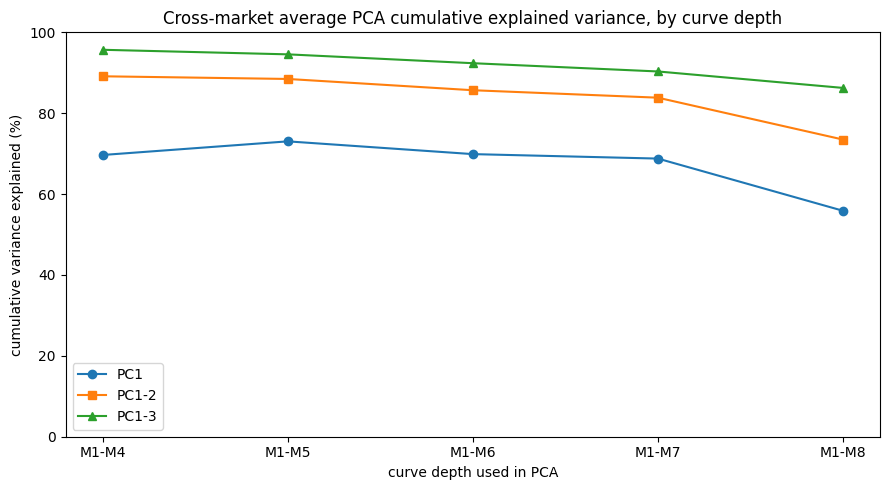


Markets whose schema depth is below d are excluded from the depth-d average
entirely (same universe convention as the NS R-squared-by-depth table above),
which is why the market count falls from 10 at M1-M4 to 3 at M1-M8.


In [26]:
# ============================================================
# 5.x PRINCIPAL-COMPONENT DESCRIPTIVE CHECK, BY CURVE DEPTH
# ============================================================
# Independent descriptive check (not used anywhere in signal formation, and
# not mechanically identified with the NS Level/Slope/Curvature factors)
# that the front curve is low-dimensional -- extended across every fit
# depth the NS estimator can use (M1-M4 through M1-M8), mirroring the
# NS R-squared-by-depth table above rather than reporting M1-M4 alone.
#
# For each market and each contiguous depth d, take daily price changes on
# M1..Md over the dates where the whole d-contract strip has genuine data,
# standardize each column to unit variance, and take the eigen-decomposition
# of the resulting correlation matrix. Report the cumulative fraction of
# variance explained by the first 1, 2 and 3 principal components, then
# average across the markets that actually reach that depth.
# ============================================================

PCA_DEPTHS = [4, 5, 6, 7, 8]
_MIN_PCA_OBS = 250  # a correlation matrix needs materially more rows than columns


def market_pca_cumvar(root, depth):
    cols = [f"{root}{k}" for k in range(1, depth + 1)]
    if not all(c in prices.columns for c in cols):
        return None
    px = prices[cols].dropna()
    chg = px.diff().dropna()
    if len(chg) < max(_MIN_PCA_OBS, depth + 20):
        return None
    sd = chg.std(ddof=0)
    if (sd <= 0).any():
        return None
    z = (chg - chg.mean()) / sd
    corr = np.corrcoef(z.to_numpy(), rowvar=False)
    eigvals = np.clip(np.linalg.eigvalsh(corr)[::-1], 0.0, None)
    total = eigvals.sum()
    if total <= 0:
        return None
    cum = np.cumsum(eigvals) / total
    out = {"N": len(z)}
    for k in range(1, min(3, depth) + 1):
        label = "PC1" if k == 1 else f"PC1-{k}"
        out[label] = cum[k - 1]
    return out


_pca_rows = []
for depth in PCA_DEPTHS:
    for root in price_universe:
        res = market_pca_cumvar(root, depth)
        if res is None:
            continue
        _pca_rows.append({"Depth": depth, "Market": root, **res})

pca_by_market_depth = pd.DataFrame(_pca_rows).set_index(["Depth", "Market"]).sort_index()
print("PCA cumulative variance explained by market and curve depth (%)")
display((100 * pca_by_market_depth[["PC1", "PC1-2", "PC1-3"]]).round(1))

pca_depth_summary = (
    pca_by_market_depth.reset_index()
    .groupby("Depth")
    .agg(
        markets=("Market", "nunique"),
        PC1=("PC1", "mean"),
        PC1_2=("PC1-2", "mean"),
        PC1_3=("PC1-3", "mean"),
    )
    .rename(columns={"PC1_2": "PC1-2", "PC1_3": "PC1-3"})
)

print("\nCross-market average cumulative variance explained, by curve depth (%)")
display(
    (100 * pca_depth_summary[["PC1", "PC1-2", "PC1-3"]])
    .round(1)
    .assign(markets=pca_depth_summary["markets"].astype(int))
)

plt.figure(figsize=(9, 5))
_x = pca_depth_summary.index.to_numpy()
for col, marker in zip(["PC1", "PC1-2", "PC1-3"], ["o", "s", "^"]):
    plt.plot(_x, 100 * pca_depth_summary[col], marker=marker, label=col)
plt.xticks(_x, [f"M1-M{d}" for d in _x])
plt.ylabel("cumulative variance explained (%)")
plt.xlabel("curve depth used in PCA")
plt.title("Cross-market average PCA cumulative explained variance, by curve depth")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

print("\nMarkets whose schema depth is below d are excluded from the depth-d average")
print("entirely (same universe convention as the NS R-squared-by-depth table above),")
print("which is why the market count falls from 10 at M1-M4 to 3 at M1-M8.")


In [27]:
# ============================================================
# NS FIT SANITY CHECK
# ============================================================
#
# Everything here comes from the stored panel. There is no second fitter.
#
# The check is the OLS normal equation, X'e = 0, which every correct
# least-squares fit satisfies by construction. It catches a wrong design
# matrix, a wrong lambda, a misaligned maturity vector or a shifted beta
# without reimplementing the regression.
#
# Run over a sample of market-dates, not one, so the contiguity masking and
# the depth fallback in estimate_ns_panel are actually exercised. The residual
# panel is checked where it is built, in 6.1.
# ============================================================

SANITY_N = 300

rng_chk = np.random.default_rng(0)
pick = rng_chk.choice(len(ns_results), size=min(SANITY_N, len(ns_results)),
                      replace=False)

worst_orth = 0.0
checked = 0

for p in pick:
    date, root = ns_results.index[p]
    row = ns_results.iloc[p]
    n = int(row["N_contracts"])
    cols = [f"{root}{k}" for k in range(1, n + 1)]

    M = row[[f"M{k}" for k in range(1, n + 1)]].to_numpy(float)
    y = prices.loc[date, cols].to_numpy(float)
    if not (np.isfinite(M).all() and np.isfinite(y).all()):
        continue

    sl, cv = ns_loadings(M, float(row["lambda"]))
    X = np.column_stack([np.ones(n), sl, cv])
    e = y - X @ row[["beta_L", "beta_S", "beta_C"]].to_numpy(float)

    worst_orth = max(worst_orth,
                     float(np.max(np.abs(X.T @ e)) / max(np.abs(y).max(), 1.0)))
    checked += 1

print(f"checked {checked} market-dates, depths "
      f"{sorted(ns_results.iloc[pick]['N_contracts'].unique())}")
print(f"  max |X'e| / |y|  {worst_orth:.3e}")
assert worst_orth < 1e-9, "NS fit does not satisfy the OLS normal equation"

root = price_universe[0]
root_ns = ns_results.xs(root, level="Commodity").sort_index()
date = root_ns.index[-1]
n = int(root_ns.loc[date, "N_contracts"])
cols = [f"{root}{k}" for k in range(1, n + 1)]
M = root_ns.loc[date, [f"M{k}" for k in range(1, n + 1)]].to_numpy(float)
sl, cv = ns_loadings(M, float(root_ns.loc[date, "lambda"]))
fitted = np.column_stack([np.ones(n), sl, cv]) @ \
    root_ns.loc[date, ["beta_L", "beta_S", "beta_C"]].to_numpy(float)
y = prices.loc[date, cols].to_numpy(float)

display(pd.DataFrame({
    "Rank": [f"M{k}" for k in range(1, n + 1)],
    "Ticker": tickers.loc[date, cols].values,
    "Maturity": M, "Actual": y, "Fitted": fitted, "Residual": y - fitted,
    "Traded": [k <= TRADE_MAX_RANK for k in range(1, n + 1)],
}).round(4))
print(f"{root}  {date.date()}  lambda {root_ns.loc[date,'lambda']:.4f}  "
      f"R2 {root_ns.loc[date,'R2_full']:.4f}  "
      f"(L+S only {root_ns.loc[date,'R2_LS']:.4f}, "
      f"L+C only {root_ns.loc[date,'R2_LC']:.4f})")


checked 300 market-dates, depths [np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
  max |X'e| / |y|  1.086e-14


,Rank,Ticker,Maturity,Actual,Fitted,Residual,Traded
0,M1,ZUBQ6,0.7742,118.13,118.7423,-0.6123,True
1,M2,ZUBU6,1.7742,115.98,113.1731,2.8069,True
2,M3,ZUBV6,2.7742,112.06,116.1191,-4.0591,True
3,M4,ZUBX6,3.7742,123.28,121.4155,1.8645,True


ZUB  2026-08-07  lambda 0.7885  R2 0.5702  (L+S only 0.0275, L+C only 0.1414)


# 6. Nelson-Siegel residual reversal strategy

For market \(i\), rank \(k\), and date \(t\), the fitted residual is

\[e_{i,k,t}=P_{i,k,t}-\widehat P^{NS}_{i,k,t}.\]

A positive residual is rich to the fitted curve; a negative residual is cheap. The reversal view is projected onto the null space of the traded Nelson-Siegel Level/Slope/Curvature loadings. Projection is performed in **contract-quantity space**.

If \(q_t\) is the projected quantity vector, then \(q_t'X_t=0\). The execution engine works with notional weights and percentage returns, so the notebook converts quantities to

\[w_{i,t}=\frac{q_{i,t}P_{i,t}}{\sum_j |q_{j,t}P_{j,t}|}.\]

Therefore \((w_t/P_t)'X_t=0\): the portfolio whose P&L is calculated is the same factor-neutral economic hedge that was constructed.

Residuals belong to **specific contracts**, not generic ranks. The signal observed at date \(t\) is lagged before execution, and every P&L observation uses the same specific contract on both price dates. No generic roll gap is treated as return. If any required leg is inside the roll-out buffer, the complete market spread is flattened rather than trading an incomplete butterfly. No ticker or signal forward filling is permitted.


In [28]:
# ============================================================
# 6.1 RECONSTRUCT NS FITTED CURVES AND RESIDUALS
# ============================================================

def build_ns_residual_panels(ns_results, prices, tickers, universe,
                             max_curve_rank=CURVE_MAX_RANK):
    """
    Reconstruct fitted prices and residuals for each rank that participated
    in that day's NS fit. Vectorized by market/rank for speed.

    Curve information can use M1-M8. The trading signal is restricted to
    M1-M4 in the next cell.
    """
    idx = prices.index
    actual_panels = {
        k: pd.DataFrame(np.nan, index=idx, columns=universe, dtype=float)
        for k in range(1, max_curve_rank + 1)
    }
    fitted_panels = {
        k: pd.DataFrame(np.nan, index=idx, columns=universe, dtype=float)
        for k in range(1, max_curve_rank + 1)
    }
    residual_panels = {
        k: pd.DataFrame(np.nan, index=idx, columns=universe, dtype=float)
        for k in range(1, max_curve_rank + 1)
    }

    for root in universe:
        try:
            x = ns_results.xs(root, level="Commodity").sort_index()
        except KeyError:
            continue

        for k in range(1, max_curve_rank + 1):
            col = f"{root}{k}"
            if col not in prices.columns or col not in tickers.columns:
                continue

            dates = x.index[x["N_contracts"] >= k]
            if len(dates) == 0:
                continue

            px = pd.to_numeric(prices.loc[dates, col], errors="coerce")
            tk = tickers.loc[dates, col]
            M = np.asarray([
                months_to_maturity(ticker, date)
                for ticker, date in zip(tk.values, dates)
            ], dtype=float)

            beta_L = x.loc[dates, "beta_L"].to_numpy(float)
            beta_S = x.loc[dates, "beta_S"].to_numpy(float)
            beta_C = x.loc[dates, "beta_C"].to_numpy(float)
            lam = x.loc[dates, "lambda"].to_numpy(float)

            good = (px.notna().to_numpy() & np.isfinite(M) & (M > 0)
                    & np.isfinite(lam))
            if not good.any():
                continue

            dates_g = dates[good]
            M_g = M[good]
            lam_g = lam[good]
            slope, curvature = ns_loadings(M_g, lam_g)
            fitted = (beta_L[good] + beta_S[good] * slope
                      + beta_C[good] * curvature)
            actual = px.to_numpy(float)[good]

            actual_panels[k].loc[dates_g, root] = actual
            fitted_panels[k].loc[dates_g, root] = fitted
            residual_panels[k].loc[dates_g, root] = actual - fitted

    return actual_panels, fitted_panels, residual_panels


(ns_actual_by_rank, ns_fitted_by_rank, ns_residual_by_rank) = build_ns_residual_panels(
    ns_results=ns_results,
    prices=prices,
    tickers=tickers,
    universe=price_universe,
)

# M1-M4 feed the baseline signal used for diagnostics and the market risk model. Section 14 later builds M4-M5 liquidity-aware production candidates from the same raw residual panels.
residual_panel = pd.concat(
    {f"M{k}": ns_residual_by_rank[k] for k in range(1, TRADE_MAX_RANK + 1)},
    axis=1,
)
print("Tradable residual panel shape:", residual_panel.shape)
print("Tradable ranks: M1-M4 only")
print("Note: M1-M4 residuals need not sum to zero because deferred contracts can help fit the curve.")


# The traded residual panel must equal price minus fitted, on the same random
# sample of market-dates used for the normal-equation check in 6.0.
_worst = 0.0
for _p in pick:
    _date, _root = ns_results.index[_p]
    _row = ns_results.iloc[_p]
    _n = int(_row["N_contracts"])
    _M = _row[[f"M{k}" for k in range(1, _n + 1)]].to_numpy(float)
    _y = prices.loc[_date, [f"{_root}{k}" for k in range(1, _n + 1)]].to_numpy(float)
    if not (np.isfinite(_M).all() and np.isfinite(_y).all()):
        continue
    _sl, _cv = ns_loadings(_M, float(_row["lambda"]))
    _e = _y - np.column_stack([np.ones(_n), _sl, _cv]) @ \
        _row[["beta_L", "beta_S", "beta_C"]].to_numpy(float)
    _stored = np.array([ns_residual_by_rank[k][_root].get(_date, np.nan)
                        for k in range(1, TRADE_MAX_RANK + 1)])
    _worst = max(_worst, float(np.nanmax(np.abs(_stored - _e[:TRADE_MAX_RANK]))))

print(f"panel residual vs (price - fitted): max |d| {_worst:.3e}")
assert _worst < 1e-9, "residual panel disagrees with the stored NS fit"


Tradable residual panel shape: (4418, 40)
Tradable ranks: M1-M4 only
Note: M1-M4 residuals need not sum to zero because deferred contracts can help fit the curve.


panel residual vs (price - fitted): max |d| 1.137e-13


In [29]:
# ============================================================
# 7.2 CANONICAL CONTRACT-INDEXED EXECUTION / P&L ENGINE
# ============================================================
# Generic ranks only label contracts on the formation date. Both the fixed
# M1-M4 book and the variable-depth production book use this exact engine for
# contract mapping, lagging, coverage, P&L and turnover.
# ============================================================

# IMPORTANT TIMING CONVENTION:
# lag=1 means the signal formed from settlement t-1 earns the t-1 -> t
# close-to-close return. It therefore represents ZERO additional delay after
# observing the settlement. The lag ladder reports delay = lag - 1 explicitly.
LAG_BASE = 1
EXECUTION_DELAY_DAYS = LAG_BASE - 1

# Never fabricate a zero return for an unmeasured held leg.
COVERAGE_FLOOR = 1.00
ROLL_OUT_BUFFER = 2


def surviving_legs(tickers, root, idx, buffer, max_rank=TRADE_MAX_RANK):
    """Causal mask: hold a leg only when it is > buffer business days from delivery."""
    cols = [f"{root}{k}" for k in range(1, max_rank + 1)]
    dtd = BUSINESS_DAYS_TO_MONTH_END.reindex(idx).reindex(columns=cols)
    out = pd.DataFrame(False, index=idx, columns=range(1, max_rank + 1))
    for j, k in enumerate(range(1, max_rank + 1)):
        out[k] = np.isfinite(dtd[cols[j]]) & (dtd[cols[j]] > float(buffer))
    return out


def clear_execution_data_cache():
    """Clear cached generic-to-specific execution maps."""
    _EXECUTION_DATA_CACHE.clear()


def execution_contract_map(prices, tickers, root, idx, max_rank):
    """Build generic->specific mapping with monotonic data-version cache key."""
    idx = pd.DatetimeIndex(idx)
    key = (_DATA_VERSION, root, int(max_rank), hash(idx.asi8.tobytes()))
    cached = _EXECUTION_DATA_CACHE.get(key)
    if cached is not None:
        return cached

    cols = [f"{root}{k}" for k in range(1, max_rank + 1)]
    tk = tickers.reindex(idx).reindex(columns=cols)
    px = prices.reindex(idx).reindex(columns=cols)

    flat_tk = tk.to_numpy().ravel()
    labels, contracts = pd.factorize(flat_tk, sort=False)
    rows = np.repeat(np.arange(len(idx)), max_rank)
    vals = px.to_numpy(float).ravel()
    valid_label = labels >= 0

    P = np.full((len(idx), len(contracts)), np.nan)
    good_p = valid_label & np.isfinite(vals)
    if len(contracts):
        P[rows[good_p], labels[good_p]] = vals[good_p]

    cached = {
        "cols": cols,
        "tk": tk,
        "px": px,
        "labels": labels,
        "contracts": contracts,
        "rows": rows,
        "valid_label": valid_label,
        "P": P,
    }
    _EXECUTION_DATA_CACHE[key] = cached
    return cached


def run_contract_positions(
    weights_by_rank,
    prices,
    tickers,
    universe,
    *,
    index=None,
    max_rank=TRADE_MAX_RANK,
    depth_panel=None,
    min_depth=1,
    lag=LAG_BASE,
    cost_bps=0.0,
    coverage_floor=COVERAGE_FLOOR,
    ffill_limit=None,
    roll_out_buffer=ROLL_OUT_BUFFER,
    market_aggregation="sum",
    trade_cap=None,
    trade_aum=None,
):
    """
    Canonical specific-contract execution engine.

    `depth_panel=None` means all ranks 1..max_rank are active. Supplying a
    depth panel activates ranks <= selected depth. `market_aggregation` is
    either:
        "sum"             final weights already contain market allocation;
        "equal_available" unit-gross market assets are equally averaged.
    """
    idx = (
        prices.index.intersection(tickers.index).sort_values()
        if index is None else pd.DatetimeIndex(index)
    )

    market_gross, market_turnover, market_coverage = {}, {}, {}
    market_unfilled, market_exposure, market_active, market_roll_flat = {}, {}, {}, {}

    for root in universe:
        _emap = execution_contract_map(prices, tickers, root, idx, max_rank)
        cols = _emap["cols"]
        tk = _emap["tk"]
        px = _emap["px"]
        wdf = pd.concat(
            [weights_by_rank[k][root].rename(k) for k in range(1, max_rank + 1)],
            axis=1,
        ).reindex(idx)

        if ffill_limit is not None:
            raise ValueError("Forward filling is disabled. Use ffill_limit=None.")

        if depth_panel is None:
            formed = wdf.notna().all(axis=1) & tk.notna().all(axis=1)
            active = np.ones((len(idx), max_rank), dtype=bool)
            W = wdf.to_numpy(float)
        else:
            dep = depth_panel[root].reindex(idx)
            active = np.column_stack([
                dep.to_numpy(float) >= k for k in range(1, max_rank + 1)
            ])
            W0 = wdf.to_numpy(float)
            required_ok = (~active) | (np.isfinite(W0) & tk.notna().to_numpy())
            formed = (
                dep.ge(min_depth).fillna(False).to_numpy()
                & required_ok.all(axis=1)
            )
            W = np.where(active, np.nan_to_num(W0, nan=0.0), 0.0)

        # np.asarray on a pandas Series returns a READ-ONLY view under
        # copy-on-write, and formed_arr is mutated in place below.
        formed_arr = np.array(formed, dtype=bool, copy=True)

        # All-or-nothing roll protection. A relative-value spread is a complete
        # hedge: if ANY required leg is inside the roll-out buffer, flatten the
        # whole market spread for that formation date. Do not amputate one leg.
        # `formed_arr` stays True on an intentional flat date so the subsequent
        # executed flat day is recorded as zero P&L and its exit/re-entry turnover
        # is charged rather than disappearing as a missing observation.
        if roll_out_buffer:
            surv = surviving_legs(tickers, root, idx, roll_out_buffer, max_rank).to_numpy()
            all_required_survive = ((~active) | surv).all(axis=1)
            roll_flat_raw = formed_arr & ~all_required_survive
            W[roll_flat_raw] = 0.0
        else:
            roll_flat_raw = np.zeros(len(idx), dtype=bool)

        labels = _emap["labels"]
        contracts = _emap["contracts"]
        rows = _emap["rows"]
        valid_label = _emap["valid_label"]
        wvals = W.ravel()

        n = len(idx)
        C = len(contracts)
        if C == 0:
            market_gross[root] = pd.Series(np.nan, index=idx, dtype=float)
            market_turnover[root] = pd.Series(np.nan, index=idx, dtype=float)
            market_coverage[root] = pd.Series(np.nan, index=idx, dtype=float)
            market_unfilled[root] = pd.Series(0.0, index=idx, dtype=float)
            market_exposure[root] = pd.Series(0.0, index=idx, dtype=float)
            market_active[root] = pd.Series(False, index=idx, dtype=bool)
            market_roll_flat[root] = pd.Series(False, index=idx, dtype=bool)
            continue

        P = _emap["P"]
        pos_raw = np.zeros((n, C))

        good_w = (
            valid_label
            & np.isfinite(wvals)
            & (wvals != 0)
            & np.repeat(formed_arr, max_rank)
        )
        np.add.at(pos_raw, (rows[good_w], labels[good_w]), wvals[good_w])
        pos_raw[~formed_arr] = 0.0

        pos = np.zeros_like(pos_raw)
        if lag > 0:
            pos[lag:] = pos_raw[:-lag]
            live = np.r_[np.zeros(lag, dtype=bool), formed_arr[:-lag]]
            intentional_flat = np.r_[np.zeros(lag, dtype=bool), roll_flat_raw[:-lag]]
        else:
            pos[:] = pos_raw
            live = formed_arr.copy()
            intentional_flat = roll_flat_raw.copy()

        # ----------------------------------------------------------
        # OPTIONAL DAILY TRADE LIMIT (partial fills).
        #
        # trade_cap[(market, rank)] is a DOLLAR limit on how much of that
        # contract may be traded in one day. Applied at CONTRACT level after
        # the lag, so a roll or a depth change costs a real fill. With
        # trade_cap=None this block is skipped and the engine is unchanged.
        #
        # The book CHASES the target rather than silently smoothing it. Any
        # alternative fill/smoothing rule should be evaluated explicitly in the
        # execution diagnostics rather than justified by a frozen result here.
        # ----------------------------------------------------------
        gap_daily = np.zeros(n)
        if trade_cap is not None:
            if trade_aum is None:
                raise ValueError("trade_cap requires trade_aum")
            capmat = np.full((n, max_rank), np.inf)
            for j, k in enumerate(range(1, max_rank + 1)):
                if (root, k) in trade_cap:
                    capmat[:, j] = trade_cap[(root, k)].reindex(idx).to_numpy(float)
            capmat = np.where(np.isfinite(capmat), capmat, np.inf)

            CAPC = np.full((n, C), np.inf)
            cvals = capmat.ravel()
            CAPC[rows[valid_label], labels[valid_label]] = cvals[valid_label]
            CAPC = np.where(np.isfinite(CAPC), CAPC / float(trade_aum), np.inf)

            held_c = np.zeros(C)
            filled = np.zeros_like(pos)
            for t in range(n):
                mv = np.clip(pos[t] - held_c, -CAPC[t], CAPC[t])
                held_c = held_c + mv
                filled[t] = held_c
                gap_daily[t] = np.abs(pos[t] - held_c).sum()
            pos = filled

        ret = np.full_like(P, np.nan)
        ret[1:] = P[1:] / P[:-1] - 1.0
        leg = pos * ret

        gross_w = np.abs(pos).sum(axis=1)
        seen_w = np.abs(np.where(np.isfinite(ret), pos, 0.0)).sum(axis=1)
        coverage = np.where(
            gross_w > 0,
            seen_w / np.maximum(gross_w, 1e-12),
            np.nan,
        )
        # An intentional roll-flat day has zero exposure and therefore zero P&L.
        # Any NON-flat held market requires complete measurable P&L. Missing held
        # returns are never replaced by zero.
        flat_exec = intentional_flat & (gross_w <= 1e-12)
        complete = coverage >= (coverage_floor - 1e-12)
        ok = live & (flat_exec | complete)

        pnl = np.where(np.isfinite(leg), leg, 0.0).sum(axis=1)
        turn = np.r_[
            np.abs(pos[0]).sum(),
            np.abs(np.diff(pos, axis=0)).sum(axis=1),
        ]

        # Carry market-level turnover from an unmeasurable date to the next
        # measurable date. No transaction cost disappears with a missing mark.
        bucket = 0.0
        charged = np.full(n, np.nan)
        for i in range(n):
            bucket += turn[i]
            if ok[i]:
                charged[i] = bucket
                bucket = 0.0

        active_market = live & ((gross_w > 1e-12) | flat_exec)
        market_gross[root] = pd.Series(np.where(ok, pnl, np.nan), index=idx)
        market_turnover[root] = pd.Series(charged, index=idx)
        coverage_report = np.where(flat_exec, 1.0, coverage)
        market_coverage[root] = pd.Series(np.where(live, coverage_report, np.nan), index=idx)
        market_unfilled[root] = pd.Series(gap_daily, index=idx)
        market_exposure[root] = pd.Series(gross_w, index=idx)
        market_active[root] = pd.Series(active_market, index=idx)
        market_roll_flat[root] = pd.Series(intentional_flat, index=idx)

    MG = pd.DataFrame(market_gross)
    MT = pd.DataFrame(market_turnover)
    CV = pd.DataFrame(market_coverage)
    UF = pd.DataFrame(market_unfilled)
    ME = pd.DataFrame(market_exposure)
    MA = pd.DataFrame(market_active).fillna(False).astype(bool)
    RF = pd.DataFrame(market_roll_flat).fillna(False).astype(bool)

    # Every market must be represented in every execution-output panel, even
    # when its generic-to-specific map contains zero contracts. Fail loudly if
    # a future branch forgets to populate one of them.
    _expected_cols = pd.Index(universe)
    for _name, _panel in {
        "market_gross": MG, "market_turnover": MT, "market_coverage": CV,
        "market_unfilled": UF, "market_exposure": ME, "market_active": MA,
        "market_roll_flat": RF,
    }.items():
        assert _panel.columns.equals(_expected_cols), (
            f"{_name} columns {_panel.columns.tolist()} != universe {_expected_cols.tolist()}"
        )

    # Ex-ante aggregation. A market does not receive more weight merely because
    # another market's return is missing. If ANY market that was supposed to be
    # live is unmeasurable, the portfolio day is marked missing.
    portfolio_ok = ((~MA) | MG.notna()).all(axis=1)

    if market_aggregation == "equal_available":
        MW = MA.astype(float)
        MW = MW.div(MW.sum(axis=1).replace(0, np.nan), axis=0)
    elif market_aggregation == "sum":
        # final weights already contain the market allocation
        MW = MA.astype(float)
    else:
        raise ValueError(f"Unknown market aggregation: {market_aggregation}")

    gross_raw = (MW * MG).sum(axis=1, min_count=1)
    turn_raw = (MW * MT).sum(axis=1, min_count=1)
    gross = gross_raw.where(portfolio_ok)

    # If the whole portfolio cannot be marked today, carry its measurable
    # turnover into the next valid portfolio day rather than losing the cost.
    turnover = pd.Series(np.nan, index=idx, dtype=float)
    bucket = 0.0
    for i, dt in enumerate(idx):
        if np.isfinite(turn_raw.iloc[i]):
            bucket += float(turn_raw.iloc[i])
        if bool(portfolio_ok.iloc[i]) and np.isfinite(gross.iloc[i]):
            turnover.iloc[i] = bucket
            bucket = 0.0

    rate = cost_bps / 1e4

    return {
        "unfilled": UF.sum(axis=1, min_count=1),
        "gross": gross,
        "net": gross - rate * turnover,
        "turnover": turnover,
        "market_gross": MG,
        "market_net": MG - rate * MT,
        "market_turnover": MT,
        "market_coverage": CV,
        "market_exposure": ME,
        "market_active": MA,
        "market_roll_flat": RF,
        "portfolio_complete": portfolio_ok,
        "market_weights": MW,
    }


def run_residual_portfolio(
    weights_by_rank,
    prices,
    tickers,
    universe,
    lag=LAG_BASE,
    cost_bps=0.0,
    max_rank=TRADE_MAX_RANK,
    coverage_floor=COVERAGE_FLOOR,
    ffill_limit=None,
    roll_out_buffer=ROLL_OUT_BUFFER,
):
    """Thin fixed-depth wrapper around `run_contract_positions`."""
    return run_contract_positions(
        weights_by_rank,
        prices,
        tickers,
        universe,
        max_rank=max_rank,
        lag=lag,
        cost_bps=cost_bps,
        coverage_floor=coverage_floor,
        ffill_limit=ffill_limit,
        roll_out_buffer=roll_out_buffer,
        market_aggregation="equal_available",
    )


In [30]:
# ============================================================
# 6.2 RESIDUAL-REVERSAL WEIGHTS
# ============================================================
#
# Economic units:
#   q = contract-quantity exposure in null(X')
#   w ∝ q * price = notional weights consumed by the percentage-return engine
#
# IMPORTANT DESIGN FACT.
# With four legs and three NS factors, null(X4') is one-dimensional. Therefore
# after unit-gross normalization the M1-M4 baseline is exactly:
#
#       sign(n'e) × fixed hedge shape
#
# Residual magnitude |n'e| is discarded. That is a deliberate property of the
# baseline, not evidence that tiny and huge dislocations should economically
# receive the same risk. Magnitude diagnostics are reported separately and are
# not used to tune production on TEST.
# ============================================================

def build_projected_residual_weights(
    residual_by_rank,
    ns_results,
    tickers,
    prices,
    universe,
    depth,
    lambda_trade,
):
    """General price-consistent NS-null residual portfolio for any traded depth >=4."""
    idx = residual_by_rank[1].index
    weights = {
        k: pd.DataFrame(np.nan, index=idx, columns=universe, dtype=float)
        for k in range(1, depth + 1)
    }
    projected_gross = pd.DataFrame(np.nan, index=idx, columns=universe, dtype=float)

    for root in universe:
        try:
            x = ns_results.xs(root, level="Commodity").sort_index()
        except KeyError:
            continue

        # Candidate exists only when the fitted strip is at least this deep.
        dates = x.index[x["N_contracts"].ge(depth)].intersection(idx)
        if len(dates) == 0:
            continue

        e = pd.concat(
            [residual_by_rank[k][root].rename(k) for k in range(1, depth + 1)],
            axis=1,
        ).reindex(dates)
        cols = [f"{root}{k}" for k in range(1, depth + 1)]
        if any(c not in tickers.columns or c not in prices.columns for c in cols):
            continue

        E = e.to_numpy(float)
        PX = prices.reindex(dates)[cols].to_numpy(float)
        M = MATURITY.reindex(dates)[cols].to_numpy(float)
        good = (
            np.isfinite(E).all(axis=1)
            & np.isfinite(PX).all(axis=1)
            & (np.abs(PX) > 1e-12).all(axis=1)
            & np.isfinite(M).all(axis=1)
            & (M > 0).all(axis=1)
        )
        if not good.any():
            continue

        dates_g = dates[good]
        E_g, PX_g, M_g = E[good], PX[good], M[good]
        lam = (
            x.loc[dates_g, "lambda"].to_numpy(float)
            if lambda_trade is None
            else np.full(len(dates_g), float(lambda_trade))
        )

        slope, curv = ns_loadings(M_g, lam[:, None])
        X = np.stack([np.ones_like(M_g), slope, curv], axis=2)  # n x depth x 3

        # SVD directly on X, not on X'X. Null basis is U[:, :, 3:].
        U, S, _ = np.linalg.svd(X, full_matrices=True)
        N = U[:, :, 3:]
        coeff = np.einsum("ndq,nd->nq", N, E_g)
        Q = -np.einsum("ndq,nq->nd", N, coeff)

        qgross = np.abs(Q).sum(axis=1)
        notional = Q * PX_g
        ngross = np.abs(notional).sum(axis=1)
        ok = (
            np.isfinite(qgross) & (qgross > 1e-12)
            & np.isfinite(ngross) & (ngross > 1e-12)
        )

        W = np.full_like(notional, np.nan)
        W[ok] = notional[ok] / ngross[ok, None]
        for j, k in enumerate(range(1, depth + 1)):
            weights[k].loc[dates_g, root] = W[:, j]
        projected_gross.loc[dates_g, root] = qgross

    return weights, projected_gross


def build_residual_reversal_weights(
    residual_by_rank, ns_results, tickers, prices, universe,
    trade_max_rank=TRADE_MAX_RANK, lambda_trade=None,
):
    """M1-M4 wrapper used by the TRAIN-only lambda optimization and risk model."""
    w, g = build_projected_residual_weights(
        residual_by_rank=residual_by_rank,
        ns_results=ns_results,
        tickers=tickers,
        prices=prices,
        universe=universe,
        depth=trade_max_rank,
        lambda_trade=lambda_trade,
    )

    # Preserve the historical third return value for downstream compatibility.
    dropped = pd.Series(dtype=float, name="gross removed")
    return w, g, dropped


In [31]:
# ============================================================
# 7.0b SELECT LAMBDA_TRADE ON THE TRAIN WINDOW
# ============================================================
#
# LAMBDA_TRADE defines the traded quantity-space null direction. The projector
# onto null(X4') is built from the M1-M4 loadings at this lambda. Notional leg
# weights may still move with prices because q is converted to w proportional
# to q * price. LAMBDA_TRADE is derived on the TRAIN window only.
#
# Two columns matter, because train Sharpe alone picks a degenerate basis:
#
#   cond(X4)  As lambda -> 0 the NS basis expands toward {1, M, M^2}, the
#             design on the traded strip goes collinear, and the null
#             direction collapses onto the third difference (-1,3,-3,1)/8.
#             Fit R2 IMPROVES as that happens, which is why R2 is not the
#             criterion and is not a column here.
#
#   TRAIN Sharpe of the projected M1-M4 book at unit gross, per market,
#             through the real engine, averaged across markets.
#
# The split is computed here from the trading calendar, which is
# lambda-invariant: RISK_INDEX == prices.index exactly, and the weight index is
# identical at every lambda in the grid. So the evaluation window can be fixed
# before the parameter is chosen, with no circularity. 13.4 re-derives the
# boundary from RISK_INDEX and asserts it agrees.
#
# Runs the grid through run_residual_portfolio. About a minute.
# ============================================================

# FROZEN SPLIT.
#
# Originally derived as 70% of the trading calendar as of the 2026-08-07
# vintage. Hardcoded so the boundary stops moving every time data is appended:
# a fraction-of-length rule made the split date a function of how much history
# happened to be loaded, which is reproducible only by accident.
#
# This is a research-design choice, not a lookahead: the split never touches
# the signal, the weights or the capacity model. It decides which dates get
# reported in which column.
TRAIN_FRACTION = 0.70                     # kept for the 13.4 cross-check only
TRAIN_END = pd.Timestamp("2021-06-04")
TEST_START = pd.Timestamp("2021-06-07")

assert TRAIN_END in prices.index, "frozen TRAIN_END is not a trading day"
assert TEST_START in prices.index, "frozen TEST_START is not a trading day"
assert prices.index[prices.index.get_loc(TRAIN_END) + 1] == TEST_START, \
    "frozen split dates are not adjacent trading days"


PERIODS = {
    "FULL": slice(None),
    "TRAIN": slice(None, TRAIN_END),
    "TEST": slice(TEST_START, None),
}
# "TRAIN FULL" is added at the end of this cell, once the weight panel
# exists to tell us when the tenth market appears.


LAMBDA_GRID = [0.15, 0.30, 0.45, 0.60, 0.75, 0.90, 1.10, 1.40, 1.80, 2.40]
_Mref = np.array([0.75, 1.75, 2.75, 3.75])   # typical M1-M4 maturities, months

_rows = []
for _lam in LAMBDA_GRID:
    _w, _, _ = build_residual_reversal_weights(
        residual_by_rank=ns_residual_by_rank, ns_results=ns_results,
        tickers=tickers, prices=prices, universe=price_universe,
        trade_max_rank=TRADE_MAX_RANK, lambda_trade=_lam)
    _mg = run_residual_portfolio(_w, prices, tickers, price_universe,
                                 lag=LAG_BASE, cost_bps=0.0)["market_gross"]
    _per = sharpe(_mg.loc[:TRAIN_END], min_obs=251)
    _sl, _cv = ns_loadings(_Mref, _lam)
    _X4 = np.column_stack([np.ones(4), _sl, _cv])
    _v = np.linalg.svd(_X4)[0][:, 3]
    _v = _v / np.abs(_v).sum()
    _v = _v * np.sign(-_v[2])
    _rows.append({"lambda": _lam,
                  "peak (months)": NS_CURVATURE_PEAK_X / _lam,
                  "cond(X4)": np.linalg.cond(_X4),
                  "TRAIN Sharpe mean": _per.mean(),
                  "TRAIN Sharpe median": _per.median(),
                  "n mkts": int(_per.notna().sum()),
                  "M1": _v[0], "M2": _v[1], "M3": _v[2], "M4": _v[3]})

lambda_choice = pd.DataFrame(_rows).set_index("lambda")
display(lambda_choice.round(3))

LAMBDA_TRADE = float(lambda_choice["TRAIN Sharpe mean"].idxmax())

print(f"train window : {prices.index[0].date()} -> {TRAIN_END.date()}")
print(f"Selected LAMBDA_TRADE by TRAIN optimization: {LAMBDA_TRADE:.4f}")
print(f"cond(X4)     : {lambda_choice.loc[LAMBDA_TRADE, 'cond(X4)']:.1f}")
print("quantity leg profile:",
      lambda_choice.loc[LAMBDA_TRADE, ["M1", "M2", "M3", "M4"]].round(3).to_dict())

# Parameter-stability diagnostic: show how isolated the TRAIN winner is.
_ranked_lambda = lambda_choice["TRAIN Sharpe mean"].sort_values(ascending=False)
if len(_ranked_lambda) >= 2:
    print(f"TRAIN lambda winner gap to runner-up: "
          f"{_ranked_lambda.iloc[0] - _ranked_lambda.iloc[1]:.4f} Sharpe")
    print("Top TRAIN lambdas:")
    display(_ranked_lambda.head(5).to_frame("TRAIN Sharpe mean").round(4))


assert LAMBDA_TRADE not in (LAMBDA_GRID[0], LAMBDA_GRID[-1]), (
    "train argmax sits at a grid edge; widen LAMBDA_GRID. cond(X4) blows up at "
    "both ends, so an edge solution is a degenerate basis, not an optimum.")

residual_weights_rev, residual_gross_raw, _dropped = build_residual_reversal_weights(
    residual_by_rank=ns_residual_by_rank,
    ns_results=ns_results,
    tickers=tickers,
    prices=prices,
    universe=price_universe,
    trade_max_rank=TRADE_MAX_RANK,
    lambda_trade=LAMBDA_TRADE,
)

# Hard guardrail: no M5+ key can enter any downstream position engine.
assert set(residual_weights_rev) == set(range(1, TRADE_MAX_RANK + 1))

# ------------------------------------------------------------
# REGRESSION / UNIT-CONSISTENCY TEST
# ------------------------------------------------------------
# The traded weights are notionals. Effective contract quantities are w / price.
# Those quantities must be orthogonal to level/slope/curvature at LAMBDA_TRADE.
# ------------------------------------------------------------

_worst_level = _worst_slope = _worst_curv = 0.0
for root in price_universe:
    w = pd.concat([residual_weights_rev[k][root].rename(k) for k in range(1, TRADE_MAX_RANK + 1)], axis=1).dropna()
    if w.empty:
        continue
    cols = [f"{root}{k}" for k in range(1, TRADE_MAX_RANK + 1)]
    d = w.index.intersection(prices.index).intersection(tickers.index)
    W = w.loc[d].to_numpy(float)
    PX = prices.loc[d, cols].to_numpy(float)
    TK = tickers.loc[d, cols]
    M = MATURITY.reindex(d)[cols].to_numpy(float)
    good = (np.isfinite(W).all(axis=1) & np.isfinite(PX).all(axis=1)
            & (np.abs(PX) > 1e-12).all(axis=1) & np.isfinite(M).all(axis=1) & (M > 0).all(axis=1))
    if not good.any():
        continue
    qeff = W[good] / PX[good]
    sl, cv = ns_loadings(M[good], LAMBDA_TRADE)
    _worst_level = max(_worst_level, float(np.max(np.abs(qeff.sum(axis=1)))))
    _worst_slope = max(_worst_slope, float(np.max(np.abs(np.sum(qeff * sl, axis=1)))))
    _worst_curv = max(_worst_curv, float(np.max(np.abs(np.sum(qeff * cv, axis=1)))))

print("Effective-quantity neutrality check (w / price):")
print(f"  max |q'1|     = {_worst_level:.3e}")
print(f"  max |q'slope| = {_worst_slope:.3e}")
print(f"  max |q'curv|  = {_worst_curv:.3e}")
assert max(_worst_level, _worst_slope, _worst_curv) < 1e-8, "price-consistent hedge lost NS neutrality"


# ============================================================
# 7.0c FULL-UNIVERSE TRAIN WINDOW
# ============================================================
# Markets enter the sample at different dates. Keep the full TRAIN window for
# parameter selection, and also define TRAIN FULL as the balanced-panel portion
# for like-for-like reporting. All dates and counts below are generated live.
# ============================================================

_first_live = {m: residual_weights_rev[1][m].first_valid_index() for m in price_universe}
UNIVERSE_COMPLETE = max(v for v in _first_live.values() if v is not None)
PERIODS["TRAIN FULL"] = slice(UNIVERSE_COMPLETE, TRAIN_END)
_fl = pd.Series(_first_live).sort_values()
print("first date each market has a tradable weight")
print(_fl.dt.date.to_string())
print(f"\nfull universe from {UNIVERSE_COMPLETE.date()}")
print(f"  TRAIN      {prices.index[0].date()} -> {TRAIN_END.date()}  "
      f"({len(prices.index[(prices.index <= TRAIN_END)])} days)")
print(f"  TRAIN FULL {UNIVERSE_COMPLETE.date()} -> {TRAIN_END.date()}  "
      f"({len(prices.index[(prices.index >= UNIVERSE_COMPLETE) & (prices.index <= TRAIN_END)])} days)")
print(f"  TEST       {TEST_START.date()} -> {prices.index[-1].date()}  "
      f"({len(prices.index[prices.index >= TEST_START])} days)")


,peak (months),cond(X4),TRAIN Sharpe mean,TRAIN Sharpe median,n mkts,M1,M2,M3,M4
lambda,,,,,,,,,
0.15,11.955,702.543,0.958,1.009,10,-0.111,0.361,-0.389,0.139
0.30,5.978,197.033,0.970,0.946,10,-0.099,0.346,-0.401,0.154
0.45,3.985,101.526,0.994,0.933,10,-0.088,0.332,-0.412,0.168
0.60,2.989,68.020,1.053,1.064,10,-0.077,0.318,-0.423,0.182
0.75,2.391,53.003,1.054,0.975,10,-0.068,0.304,-0.432,0.196
0.90,1.993,45.591,1.033,0.943,10,-0.059,0.291,-0.441,0.209
1.10,1.630,41.368,1.069,0.955,10,-0.050,0.274,-0.450,0.226
1.40,1.281,41.187,1.019,0.890,10,-0.038,0.251,-0.462,0.249
1.80,0.996,47.495,0.952,0.864,10,-0.026,0.226,-0.474,0.274


train window : 2009-03-23 -> 2021-06-04
Selected LAMBDA_TRADE by TRAIN optimization: 1.1000
cond(X4)     : 41.4
quantity leg profile: {'M1': -0.05, 'M2': 0.274, 'M3': -0.45, 'M4': 0.226}
TRAIN lambda winner gap to runner-up: 0.0152 Sharpe
Top TRAIN lambdas:


,TRAIN Sharpe mean
lambda,
1.10,1.0694
0.75,1.0542
0.60,1.0533
0.90,1.0334
1.40,1.0192


Effective-quantity neutrality check (w / price):
  max |q'1|     = 1.041e-17
  max |q'slope| = 5.204e-18
  max |q'curv|  = 3.469e-18
first date each market has a tradable weight
PHB    2010-03-25
PCB    2010-05-17
FAC    2013-06-03
ITP    2015-04-22
DFP    2016-06-20
MSP    2016-08-18
SXD    2017-01-26
DET    2018-04-17
UTD    2018-06-18
ZUB    2019-09-12

full universe from 2019-09-12
  TRAIN      2009-03-23 -> 2021-06-04  (3092 days)
  TRAIN FULL 2019-09-12 -> 2021-06-04  (442 days)
  TEST       2021-06-07 -> 2026-08-07  (1326 days)


In [32]:
# ============================================================
# CURVE AVAILABILITY AUDIT
# ============================================================
#
# Measured inside each market's OWN sample window, so the numbers are not
# contaminated by days before a market had listed data.
#
#   Curve fits      NS fit exists using >=4 contiguous contracts (up to M8)
#   Signal formed   the NS fit produced a usable weight vector
#   P&L measurable  every leg's contract prices on both t-1 and t, allowing
#                   for the roll (a contract that shifts rank is still held)
#   M4 absent       M1 prints, M4 does not
# ============================================================

idx = ns_residual_by_rank[1].index
rows = []

for root in price_universe:

    cols = [f"{root}{k}" for k in range(1, TRADE_MAX_RANK + 1)]
    px = prices.reindex(idx)[cols]
    tk = tickers.reindex(idx)[cols]

    curve = pd.Series(False, index=idx)
    try:
        fit_dates = ns_results.xs(root, level="Commodity").index
        curve.loc[curve.index.intersection(fit_dates)] = True
    except KeyError:
        pass

    signal = pd.concat(
        [residual_weights_rev[k][root] for k in range(1, TRADE_MAX_RANK + 1)], axis=1
    ).notna().all(axis=1).reindex(idx).fillna(False)

    # P&L availability, contract-indexed: a contract you hold is measurable if
    # it prices on both days, whatever rank it occupies. Rank labels are
    # irrelevant, which is the whole point of the contract-indexed engine.
    price_of = {}
    for i in range(MAX_RANK):
        for t, c, p in zip(idx, tk.iloc[:, i].values, px.iloc[:, i].values):
            if pd.notna(c) and np.isfinite(p):
                price_of.setdefault(c, {})[t] = p

    measurable = []
    prev_date = None
    for t in idx:
        if prev_date is None or not curve.loc[prev_date]:
            measurable.append(False)
        else:
            held = tk.loc[prev_date].dropna().values
            ok = sum(
                1 for c in held
                if t in price_of.get(c, {}) and prev_date in price_of.get(c, {})
            )
            measurable.append(ok >= TRADE_MAX_RANK - 1)   # front leg may roll off
        prev_date = t
    measurable = pd.Series(measurable, index=idx)

    live = curve[curve].index
    if len(live) == 0:
        continue
    win = (idx >= live.min()) & (idx <= live.max())

    rows.append({
        "Market": root,
        "Start": live.min().date(),
        "N in sample": int(win.sum()),
        "Curve fits": curve[win].mean(),
        "Signal formed": signal[win].mean(),
        "P&L measurable": measurable[win].mean(),
        "M4 absent": (
            px[f"{root}{TRADE_MAX_RANK}"].isna()[win] & px[f"{root}1"].notna()[win]
        ).mean(),
    })

curve_audit = pd.DataFrame(rows).set_index("Market").sort_values("Curve fits")
display(curve_audit.round(4))

print("Specific-contract mapping keeps valid P&L when a contract changes generic rank.")
print("Any remaining curve-fit or P&L gaps shown above come from the current data, not from hardcoded market assumptions.")

,Start,N in sample,Curve fits,Signal formed,P&L measurable,M4 absent
Market,,,,,,
SXD,2017-01-26,2438,0.7383,0.7383,0.7379,0.2580
PCB,2010-05-17,4130,0.7581,0.7579,0.7504,0.1622
PHB,2010-03-25,4166,0.9791,0.9791,0.9705,0.0010
ZUB,2019-09-12,1768,0.9813,0.9813,0.9808,0.0119
DET,2018-04-17,2128,0.9934,0.9934,0.9930,0.0000
DFP,2016-06-20,2595,0.9934,0.9934,0.9931,0.0015
ITP,2015-04-22,2892,0.9938,0.9938,0.9927,0.0007
MSP,2016-08-18,2552,0.9941,0.9941,0.9937,0.0000
FAC,2013-06-03,3371,0.9956,0.9956,0.9941,0.0006


Specific-contract mapping keeps valid P&L when a contract changes generic rank.
Any remaining curve-fit or P&L gaps shown above come from the current data, not from hardcoded market assumptions.


### Canonical return path only

The older rank-return reference implementation has been removed from active
research. All P&L, roll handling and turnover diagnostics use the single
specific-contract execution engine in section 7.2.


# 7. Residual Tradability Dashboard

The residual tests above establish whether deviations from the fitted Nelson-Siegel curve converge statistically. This section asks the harder economic question:

\[
\boxed{\text{Can that convergence actually be monetized?}}
\]

The dashboard keeps the existing **same-specific-contract execution rule** and tests four dimensions:

1. **Turnover and transaction costs**: net performance across a cost grid and the break-even cost.
2. **Residual entry thresholds**: only trade sufficiently large cross-sectional residual distortions.
3. **Holding/rebalancing frequency**: rebalance every 1, 2, 3, 5, or 10 trading days.
4. **Roll exclusion**: remove observations within progressively wider windows around generic roll events.

Transaction costs are expressed in **basis points per unit of one-way turnover**. If a position changes from +0.20 to -0.20, turnover is 0.40 and the assumed cost is applied to that 0.40 change.

Because exact exchange, clearing, bid-ask, and market-impact costs are not yet supplied in the notebook, the cost grid is a **stress test**, not a claim about realized execution costs.


### No duplicate execution panels

Signal weights are consumed directly by `run_contract_positions`. The previous
`resid_signal_weights_panel`, `resid_exec_weights_panel` and strict-rank return
panels were dead state and have been removed to prevent out-of-order notebook
execution from reusing stale globals.


In [33]:
resid_base_trade = run_residual_portfolio(
    residual_weights_rev,
    prices,
    tickers,
    price_universe,
    lag=LAG_BASE,
    cost_bps=0.0,
)

_cov = resid_base_trade["market_coverage"].stack().dropna()
print(f"days kept        : {resid_base_trade['gross'].notna().sum()}")
print(f"coverage median  : {_cov.median():.4f}")
print(f"coverage 1st pct : {_cov.quantile(0.01):.4f}")
print(f"share below {COVERAGE_FLOOR:.2f} : {(_cov < COVERAGE_FLOOR).mean():.4f}")
print(f"portfolio days incomplete and therefore dropped: "
      f"{(~resid_base_trade['portfolio_complete']).sum()}")

# Strict-coverage audit. Production uses 100% measurable held gross. The
# 90%-coverage run exists only to quantify how much the old accounting rule
# mattered; it is never used downstream.
_coverage_loose = run_residual_portfolio(
    residual_weights_rev, prices, tickers, price_universe,
    lag=LAG_BASE, cost_bps=2.0, coverage_floor=0.90,
)
_coverage_strict = run_residual_portfolio(
    residual_weights_rev, prices, tickers, price_universe,
    lag=LAG_BASE, cost_bps=2.0, coverage_floor=1.00,
)
_cov_rows = []
for _label, _r in [("old 90% diagnostic", _coverage_loose), ("strict 100% production", _coverage_strict)]:
    for _period, _sl in [("FULL", slice(None)), ("TEST", slice(TEST_START, None))]:
        _x = _r["net"].loc[_sl].dropna()
        _cov_rows.append({
            "coverage rule": _label,
            "period": _period,
            "N": len(_x),
            "net Sharpe @2bps": sharpe(_x),
            "ann net mean": _x.mean() * TRADING_DAYS,
            "ann turnover": _r["turnover"].loc[_sl].mean() * TRADING_DAYS,
        })
coverage_audit = pd.DataFrame(_cov_rows).set_index(["coverage rule", "period"])
print("\nStrict-coverage audit (90% is diagnostic only):")
display(coverage_audit.round(4))

_roll_counts = resid_base_trade["market_roll_flat"].sum().astype(int)
print("\nExecuted all-or-nothing roll-flat days by market:")
display(_roll_counts.to_frame("flat days"))
print("\nExecuted roll-flat days by calendar year and market:")
roll_flat_by_year = (
    resid_base_trade["market_roll_flat"]
    .groupby(resid_base_trade["market_roll_flat"].index.year)
    .sum()
    .astype(int)
)
display(roll_flat_by_year)

# Guardrail: once a market has at least one year of live observations, the
# configured roll protection should have fired at least once in its history.
_live_obs = resid_base_trade["market_active"].sum()
_dead_roll_guard = [m for m in price_universe if _live_obs.get(m, 0) >= TRADING_DAYS and _roll_counts.get(m, 0) == 0]
assert not _dead_roll_guard, f"roll protection never fires for live markets: {_dead_roll_guard}"

print(f"annual turnover  : {resid_base_trade['turnover'].mean() * TRADING_DAYS:.1f}")

print("\nHAC sensitivity of the baseline mean return:")
_hac_gross = hac_mean_sensitivity(resid_base_trade["gross"].dropna()).add_prefix("gross ")
_hac_net2 = hac_mean_sensitivity((resid_base_trade["gross"] - 2/1e4 * resid_base_trade["turnover"]).dropna()).add_prefix("net2 ")
display(_hac_gross.join(_hac_net2).round(4))


days kept        : 4006
coverage median  : 1.0000
coverage 1st pct : 1.0000
share below 1.00 : 0.0085
portfolio days incomplete and therefore dropped: 134



Strict-coverage audit (90% is diagnostic only):


N  net Sharpe @2bps  ann net mean  \
coverage rule          period                                         
old 90% diagnostic     FULL    4103            1.7632        0.1012   
                       TEST    1322            2.3725        0.1337   
strict 100% production FULL    4006            1.7065        0.0979   
                       TEST    1320            2.3618        0.1331   

                               ann turnover  
coverage rule          period                
old 90% diagnostic     FULL         52.3645  
                       TEST         56.1467  
strict 100% production FULL         53.6420  
                       TEST         56.2319


Executed all-or-nothing roll-flat days by market:


,flat days
ZUB,104
ITP,170
DET,124
FAC,203
DFP,154
SXD,109
UTD,126
MSP,150
PHB,123
PCB,115



Executed roll-flat days by calendar year and market:


,ZUB,ITP,DET,FAC,DFP,SXD,UTD,MSP,PHB,PCB
Date,,,,,,,,,,
2009,0,0,0,0,0,0,0,0,0,0
2010,0,0,0,0,0,0,0,0,0,0
2011,0,0,0,0,0,0,0,0,0,0
2012,0,0,0,0,0,0,0,0,0,0
2013,0,0,0,10,0,0,0,0,0,0
2014,0,0,0,15,0,0,0,0,0,0
2015,0,11,0,16,0,0,0,0,0,0
2016,0,15,0,15,8,0,0,5,0,0
2017,0,15,0,15,15,9,0,15,0,3


annual turnover  : 53.6

HAC sensitivity of the baseline mean return:


,gross N,gross Ann. mean,gross t-stat,gross p-value,net2 N,net2 Ann. mean,net2 t-stat,net2 p-value
NW lags,,,,,,,,
5,4006,0.1086,8.0106,0.0,4006,0.0979,7.2790,0.0
10,4006,0.1086,7.7971,0.0,4006,0.0979,7.1137,0.0
21,4006,0.1086,7.6406,0.0,4006,0.0979,7.0122,0.0
42,4006,0.1086,7.3646,0.0,4006,0.0979,6.7921,0.0


In [34]:
# ============================================================
# 7.2 MARKET-LEVEL UNIT-ROOT TEST
#     SIGNED M1-M4 NELSON-SIEGEL NULL-SPACE COORDINATE
# ============================================================
#
# Rather than testing M1, M2, M3, M4 separately, construct the
# single economically relevant residual coordinate for each market:
#
#       z_t = n_t' e_t
#
# where:
#   e_t = vector of M1-M4 NS residuals
#   n_t = one-dimensional null-space vector of the M1-M4 NS design
#
# Since M1-M4 has 4 contracts and 3 NS factors, the null space is
# one-dimensional. Therefore there is ONE residual state per market.
#
# ADF regression:
#
#   dz_t = a + gamma*z_(t-1)
#              + sum_i delta_i*dz_(t-i) + eps_t
#
# Mean reversion implies gamma < 0.
#
# IMPORTANT:
# - one test per MARKET, not one test per generic rank
# - the complete ADF lag window must remain inside the same set of
#   specific contracts
# - no roll transition is allowed into dz_t or any ADF lag
# - min_obs=250 is only an ADF sample-size requirement
# ============================================================

DF_CRIT = {
    "10%": -2.57,
    "5%":  -2.86,
    "1%":  -3.43,
}

ADF_LAGS = 5

# Explicitly freeze this diagnostic to M1-M4.
ADF_MARKET_MAX_RANK = 4


# ============================================================
# MARKET-LEVEL RESIDUAL COORDINATE
# ============================================================

def signed_null_coordinate(root, max_rank=ADF_MARKET_MAX_RANK):
    """
    Construct the unique signed NS residual coordinate for M1-M4:

        z_t = n_t' e_t

    where n_t spans the one-dimensional null space of the
    Nelson-Siegel loading matrix.

    Sign orientation is made deterministic so SVD sign flips do
    not create artificial jumps in the time series.
    """

    if max_rank != 4:
        raise ValueError(
            "Market-level scalar ADF is defined here for M1-M4 only. "
            "M1-M5 has a two-dimensional null space."
        )

    ranks = range(1, max_rank + 1)

    # NS residuals
    e = pd.concat(
        [
            ns_residual_by_rank[k][root].rename(k)
            for k in ranks
        ],
        axis=1,
    )

    cols = [f"{root}{k}" for k in ranks]

    idx = (
        e.index
        .intersection(tickers.index)
        .intersection(MATURITY.index)
    )

    E = e.reindex(idx).to_numpy(dtype=float)
    M = MATURITY.reindex(idx)[cols].to_numpy(dtype=float)
    TK = tickers.reindex(idx)[cols]

    # Require complete M1-M4 information on date t
    good = (
        np.isfinite(E).all(axis=1)
        & np.isfinite(M).all(axis=1)
        & (M > 0).all(axis=1)
        & TK.notna().all(axis=1).to_numpy()
    )

    out = pd.Series(
        np.nan,
        index=idx,
        dtype=float,
        name=root,
    )

    if not good.any():
        return out

    Mg = M[good]
    Eg = E[good]

    # Nelson-Siegel design matrix
    sl, cv = ns_loadings(Mg, LAMBDA_TRADE)

    X = np.stack(
        [
            np.ones_like(Mg),
            sl,
            cv,
        ],
        axis=2,
    )

    # X is [date, 4 contracts, 3 NS factors].
    # The fourth column of U spans the 1-D orthogonal complement.
    U, _, _ = np.linalg.svd(
        X,
        full_matrices=True,
    )

    n = U[:, :, 3].copy()

    # --------------------------------------------------------
    # DETERMINISTIC ORIENTATION
    # --------------------------------------------------------
    # SVD eigenvectors are defined only up to sign.
    # Without fixing orientation, n could randomly flip from
    # +n to -n across dates and fabricate "mean reversion".
    #
    # Force the M3 loading to be non-positive.
    # --------------------------------------------------------
    flip = n[:, 2] > 0
    n[flip] *= -1.0

    z = np.sum(n * Eg, axis=1)

    out.iloc[np.flatnonzero(good)] = z

    return out


# ============================================================
# ROLL-SAFE MARKET-LEVEL ADF
# ============================================================

def adf_market_test(
    z,
    ticker_panel,
    n_lags=ADF_LAGS,
    min_obs=250,
):
    """
    ADF on one market-level residual coordinate.

    A regression observation at t is accepted only when the COMPLETE
    interval needed for:

        dz_t, dz_(t-1), ..., dz_(t-n_lags)

    lies inside one uninterrupted specific-contract segment.

    Therefore neither the current difference nor any ADF lag can
    contain a generic-contract roll splice.
    """

    z = pd.Series(z)

    idx = z.index.intersection(ticker_panel.index)

    z = z.reindex(idx)
    tk = ticker_panel.reindex(idx)

    Z = z.to_numpy(dtype=float)

    # --------------------------------------------------------
    # SPECIFIC-CONTRACT SEGMENTS
    # --------------------------------------------------------
    #
    # If ANY leg changes its specific contract, the market-level
    # residual coordinate enters a new segment.
    # --------------------------------------------------------
    changed = (
        tk.ne(tk.shift(1)).any(axis=1)
        | tk.isna().any(axis=1)
        | tk.shift(1).isna().any(axis=1)
    ).to_numpy()

    segment = np.cumsum(changed)

    dz = np.r_[np.nan, np.diff(Z)]

    rows = []

    for t in range(n_lags + 1, len(Z)):

        # Complete ADF window must belong to one contract segment.
        #
        # dz_(t-n_lags) uses levels:
        # z_(t-n_lags) - z_(t-n_lags-1)
        #
        # so we need to look back n_lags + 1 levels.
        if segment[t] != segment[t - (n_lags + 1)]:
            continue

        if not (
            np.isfinite(Z[t])
            and np.isfinite(Z[t - 1])
        ):
            continue

        # Current dz plus all lagged dz must exist
        if not np.isfinite(
            dz[t - n_lags:t + 1]
        ).all():
            continue

        rows.append(
            [
                dz[t],
                Z[t - 1],
                *[
                    dz[t - L]
                    for L in range(1, n_lags + 1)
                ],
            ]
        )

    if len(rows) < min_obs:
        return None

    arr = np.asarray(rows, dtype=float)

    y = arr[:, 0]

    # columns:
    # z_(t-1), dz_(t-1), ..., dz_(t-p)
    X = sm.add_constant(arr[:, 1:])

    fit = sm.OLS(y, X).fit()

    gamma = float(fit.params[1])
    adf_stat = float(fit.tvalues[1])

    halflife = (
        np.log(0.5) / np.log(1.0 + gamma)
        if -1 < gamma < 0
        else np.nan
    )

    return {
        "N": len(arr),
        "ADF stat": adf_stat,
        "gamma": gamma,
        "halflife": halflife,
    }


# ============================================================
# RUN: ONE ADF PER MARKET
# ============================================================

rows = []

for root in price_universe:

    # One scalar residual state for this market
    z = signed_null_coordinate(root)

    # M1-M4 specific-contract identities
    cols = [
        f"{root}{k}"
        for k in range(1, ADF_MARKET_MAX_RANK + 1)
    ]

    tk_panel = tickers.reindex(z.index)[cols]

    res = adf_market_test(
        z,
        tk_panel,
        n_lags=ADF_LAGS,
        min_obs=250,
    )

    if res is not None:
        rows.append({
            "Market": root,
            **res,
        })


market_adf = (
    pd.DataFrame(rows)
    .set_index("Market")
    .sort_values("ADF stat")
)


# ============================================================
# RESULTS
# ============================================================

display(market_adf.round(3))

n_markets = len(market_adf)

print("\nMARKET-LEVEL ADF BREADTH")
print("=" * 55)

for level, crit in DF_CRIT.items():

    n_reject = (
        market_adf["ADF stat"] < crit
    ).sum()

    print(
        f"{level:>4}  "
        f"(crit {crit:5.2f}): "
        f"{n_reject:2d}/{n_markets} markets"
    )


failing = market_adf[
    market_adf["ADF stat"] >= DF_CRIT["5%"]
]

if len(failing):

    print("\nMarkets failing to reject at 5%:")

    for market, row in failing.iterrows():
        print(
            f"  {market:4s} : "
            f"ADF={row['ADF stat']:.2f}, "
            f"half-life={row['halflife']:.1f}d"
        )

else:

    print("\nAll markets reject the unit-root null at 5%.")


print("\nInterpretation:")
print(
    "Each row is one independent economic market diagnostic, "
    "not a separate test for M1/M2/M3/M4."
)
print(
    "The tested state is the signed M1-M4 NS null-space "
    "coordinate z = n'e used by the baseline reversal strategy."
)

,N,ADF stat,gamma,halflife
Market,,,,
FAC,2398,-6.849,-0.032,21.504
PCB,2134,-6.695,-0.029,23.541
PHB,2780,-6.642,-0.030,22.513
UTD,1482,-5.470,-0.034,19.961
DFP,1840,-5.090,-0.041,16.497
DET,1508,-4.967,-0.026,26.431
ITP,2048,-4.889,-0.042,15.965
MSP,1811,-4.860,-0.057,11.836
ZUB,1231,-4.007,-0.024,28.839



MARKET-LEVEL ADF BREADTH
 10%  (crit -2.57):  9/10 markets
  5%  (crit -2.86):  9/10 markets
  1%  (crit -3.43):  9/10 markets

Markets failing to reject at 5%:
  SXD  : ADF=0.19, half-life=nand

Interpretation:
Each row is one independent economic market diagnostic, not a separate test for M1/M2/M3/M4.
The tested state is the signed M1-M4 NS null-space coordinate z = n'e used by the baseline reversal strategy.


In [35]:
# ============================================================
# 7.2c SIGNAL-MAGNITUDE DIAGNOSTIC (NOT A PRODUCTION OVERLAY)
# ============================================================
# M1-M4 is sign × fixed asset after unit-gross normalization. Test whether the
# discarded magnitude |z| contains information without changing production.
# Buckets are formed causally from each market's expanding TRAIN history.
# ============================================================

_mag_rows = []
for root in price_universe:
    z = signed_null_coordinate(root)
    pnl = resid_base_trade["market_gross"][root].reindex(z.index)
    # Build the normalized magnitude entirely in FORMATION time first. The
    # trailing scale at s uses only observations through s-1; the completed
    # formation-time statistic is then shifted once to the execution date.
    formation_scale = z.abs().expanding(min_periods=252).median().shift(1)
    mag_formation = (z.abs() / formation_scale).replace([np.inf, -np.inf], np.nan)
    mag = mag_formation.shift(LAG_BASE)
    d = pd.DataFrame({"mag": mag, "pnl": pnl}).dropna()
    if len(d) < 250:
        continue
    q = pd.qcut(d["mag"].rank(method="first"), 5, labels=False)
    for bucket, g in d.groupby(q):
        _mag_rows.append({
            "Market": root,
            "|z| bucket": int(bucket) + 1,
            "N": len(g),
            "Mean pnl": g["pnl"].mean() * TRADING_DAYS,
            "Sharpe": sharpe(g["pnl"], min_obs=30),
        })

magnitude_diagnostic = pd.DataFrame(_mag_rows)
print("M1-M4 production does NOT use residual magnitude. Descriptive quintiles:")
display(
    magnitude_diagnostic.groupby("|z| bucket")[["N", "Mean pnl", "Sharpe"]]
    .mean().round(4)
)


M1-M4 production does NOT use residual magnitude. Descriptive quintiles:


,N,Mean pnl,Sharpe
|z| bucket,,,
1,471.5,0.0314,0.3682
2,471.0,0.0590,0.7484
3,470.8,0.0535,0.7293
4,471.0,0.1510,1.8345
5,471.3,0.3150,2.1236


In [36]:
# ============================================================
# 7.5 MARKET-LEVEL RESULTS, TURNOVER AND BREADTH
# ============================================================

residual_asset_stats = pd.DataFrame({
    root: performance_stats(
        resid_base_trade["market_gross"][root].dropna()
    )
    for root in price_universe
}).T


# ------------------------------------------------------------
# MARKET-LEVEL CONTRACT TURNOVER
# ------------------------------------------------------------
# Annualized turnover from the same specific-contract execution
# engine used for strategy P&L.
# ------------------------------------------------------------

residual_asset_stats["Annualized Turnover"] = pd.Series({
    root: (
        resid_base_trade["market_turnover"][root]
        .dropna()
        .mean()
        * TRADING_DAYS
    )
    for root in price_universe
})


# ------------------------------------------------------------
# MARKET-LEVEL PERFORMANCE TABLE
# ------------------------------------------------------------

display(
    residual_asset_stats[[
        "N",
        "Mean",
        "Alpha t-stat (NW)",
        "Alpha p-value (NW)",
        "Volatility",
        "Sharpe ratio",
        "Maximum drawdown",
        "Annualized Turnover",
    ]]
    .sort_values("Sharpe ratio", ascending=False)
    .round(4)
)


# ------------------------------------------------------------
# BREADTH
# ------------------------------------------------------------

n_markets = len(residual_asset_stats)

p = residual_asset_stats["Alpha p-value (NW)"]
positive = residual_asset_stats["Mean"] > 0

bonferroni = 0.05 / n_markets

residual_breadth = pd.Series({

    "Number markets":
        n_markets,

    "% positive mean":
        positive.mean(),

    "% significant positive at 5%":
        (positive & (p < 0.05)).mean(),

    f"% significant at {bonferroni:.4f} (Bonferroni)":
        (positive & (p < bonferroni)).mean(),

    "Median market Sharpe":
        residual_asset_stats["Sharpe ratio"].median(),

    "Weakest market Sharpe":
        residual_asset_stats["Sharpe ratio"].min(),

    "Median annualized turnover":
        residual_asset_stats["Annualized Turnover"].median(),

    "Highest annualized turnover":
        residual_asset_stats["Annualized Turnover"].max(),
})

display(
    residual_breadth
    .to_frame("Residual Reversal")
    .round(4)
)


# ------------------------------------------------------------
# CROSS-MARKET DIVERSIFICATION
# ------------------------------------------------------------

corr = resid_base_trade["market_gross"].corr()

off = corr.values[np.triu_indices(n_markets, 1)]

avg_corr = np.nanmean(off)

print(f"average pairwise correlation : {avg_corr:.3f}")

#print(
 #   f"effective independent bets   : "
  #  f"{n_markets / (1 + (n_markets - 1) * max(avg_corr, 0)):.2f}"
#)

print(f"\n{n_markets} markets are not {n_markets} independent tests.")

,N,Mean,Alpha t-stat (NW),Alpha p-value (NW),Volatility,Sharpe ratio,Maximum drawdown,Annualized Turnover
PHB,3948.0,0.1464,6.9964,0.0000,0.0887,1.6512,-0.1395,55.5830
MSP,2535.0,0.1587,4.9789,0.0000,0.1021,1.5545,-0.1680,63.2731
UTD,2075.0,0.1174,3.4757,0.0005,0.0931,1.2609,-0.0994,55.7162
ITP,2871.0,0.0754,4.9524,0.0000,0.0631,1.1935,-0.0834,57.8237
DFP,2576.0,0.1204,3.8206,0.0001,0.1035,1.1635,-0.1172,47.2534
SXD,1798.0,0.1454,3.3845,0.0007,0.1307,1.1128,-0.1758,59.7380
ZUB,1733.0,0.1181,2.6743,0.0075,0.1100,1.0735,-0.1667,59.4725
DET,2111.0,0.0714,2.8451,0.0044,0.0704,1.0141,-0.1156,46.0174
PCB,3044.0,0.0721,3.5903,0.0003,0.0731,0.9868,-0.1089,47.9631
FAC,3354.0,0.0959,3.0454,0.0023,0.1217,0.7881,-0.2804,48.3774


,Residual Reversal
Number markets,10.0000
% positive mean,1.0000
% significant positive at 5%,1.0000
% significant at 0.0050 (Bonferroni),0.9000
Median market Sharpe,1.1381
Weakest market Sharpe,0.7881
Median annualized turnover,55.6496
Highest annualized turnover,63.2731


average pairwise correlation : 0.177

10 markets are not 10 independent tests.


In [37]:
# ============================================================
# 7.5b CALENDAR / EPISODE ROBUSTNESS
# ============================================================

_base = resid_base_trade["gross"].dropna()
_dom = pd.DataFrame({"pnl": _base, "day": _base.index.day})
_dom_stats = _dom.groupby("day")["pnl"].agg(["count", "mean", "std"])
_dom_stats["ann mean"] = _dom_stats["mean"] * TRADING_DAYS
_dom_stats["Sharpe"] = _dom_stats["mean"] / _dom_stats["std"] * np.sqrt(TRADING_DAYS)
print("P&L by calendar day-of-month:")
display(_dom_stats[["count", "ann mean", "Sharpe"]].round(4))

# Days since the M1 generic rolled, averaged across market-level P&L observations.
_roll_rows = []
for root in price_universe:
    tk = tickers[f"{root}1"].reindex(resid_base_trade["market_gross"].index)
    roll = tk.ne(tk.shift(1)) | tk.isna()
    dsr = (~roll).groupby(roll.cumsum()).cumcount()
    pnl = resid_base_trade["market_gross"][root]
    d = pd.DataFrame({"pnl": pnl, "days_since_roll": dsr}).dropna()
    d["bucket"] = pd.cut(
        d["days_since_roll"],
        bins=[-1, 0, 1, 2, 5, 10, np.inf],
        labels=["0", "1", "2", "3-5", "6-10", "11+"]
    )
    d["Market"] = root
    _roll_rows.append(d)
_roll_diag = pd.concat(_roll_rows)
print("\nP&L by days since M1 generic roll:")
display(
    _roll_diag.groupby("bucket", observed=True)["pnl"]
    .agg(["count", "mean", "std"])
    .assign(
        **{
            "ann mean": lambda x: x["mean"] * TRADING_DAYS,
            "Sharpe": lambda x: x["mean"] / x["std"] * np.sqrt(TRADING_DAYS),
        }
    )[["count", "ann mean", "Sharpe"]].round(4)
)

# Energy-crisis exclusion diagnostic. No parameter is reselected. Report both
# FULL and TEST, gross and 2-bps net, so the reader can see exactly how much the
# 2021H2-2022 episode contributes to the headline.
_crisis_rows = []
for _series_name, _s in [
    ("gross", resid_base_trade["gross"]),
    ("net @2bps", resid_base_trade["gross"] - 2/1e4 * resid_base_trade["turnover"]),
]:
    for _period, _sl in [("FULL", slice(None)), ("TEST", slice(TEST_START, None))]:
        _x0 = _s.loc[_sl].dropna()
        _crisis = (_x0.index >= "2021-07-01") & (_x0.index <= "2022-12-31")
        for _sample, _x in [
            ("all", _x0),
            ("exclude 2021H2-2022", _x0.loc[~_crisis]),
            ("2021H2-2022 only", _x0.loc[_crisis]),
        ]:
            if len(_x) < 20:
                continue
            _crisis_rows.append({
                "series": _series_name,
                "period": _period,
                "sample": _sample,
                "N": len(_x),
                "ann mean": _x.mean() * TRADING_DAYS,
                "Sharpe": sharpe(_x),
                "Lo21 Sharpe": lo_adjusted_sharpe(_x, 21),
            })
crisis_exclusion = pd.DataFrame(_crisis_rows).set_index(["series", "period", "sample"])
print("\nEnergy-crisis exclusion (no parameter re-selection):")
display(crisis_exclusion.round(4))


P&L by calendar day-of-month:


,count,ann mean,Sharpe
day,,,
1,99,0.0671,1.3766
2,119,-0.0332,-0.6012
3,137,0.1083,1.9272
4,140,0.1672,2.8452
5,133,0.1452,2.6421
6,133,0.1718,3.5344
7,139,0.1447,2.7476
8,133,-0.0137,-0.2674
9,135,0.1125,2.3806



P&L by days since M1 generic roll:

,count,ann mean,Sharpe
bucket,,,
0,975,0.0000,NaN
1,1192,0.0905,0.8972
2,1233,0.1748,1.9338
3-5,3673,0.1102,1.2062
6-10,6104,0.1474,1.5758
11+,12868,0.0995,0.9671



Energy-crisis exclusion (no parameter re-selection):


N  ann mean  Sharpe  Lo21 Sharpe
series    period sample                                                  
gross     FULL   all                  4006    0.1086  1.8939       1.9160
                 exclude 2021H2-2022  3620    0.0928  1.6997       1.9659
                 2021H2-2022 only      386    0.2570  3.2897       2.5503
          TEST   all                  1320    0.1443  2.5600       2.0061
                 exclude 2021H2-2022   934    0.0978  2.2164       1.9950
                 2021H2-2022 only      386    0.2570  3.2897       2.5503
net @2bps FULL   all                  4006    0.0979  1.7065       1.7584
                 exclude 2021H2-2022  3620    0.0823  1.5077       1.7845
                 2021H2-2022 only      386    0.2437  3.1195       2.4405
          TEST   all                  1320    0.1331  2.3618       1.8743
                 exclude 2021H2-2022   934    0.0874  1.9825       1.8168
                 2021H2-2022 only      386    0.2437  3.1195       2.4405

,Residual Reversal
N,4006.0000
Mean,0.1086
Alpha daily,0.0004
Alpha t-stat (NW),7.6406
Alpha p-value (NW),0.0000
NW lags,21.0000
Volatility,0.0573
Downside volatility,0.0425
Sharpe ratio,1.8939
Skewness,0.1078


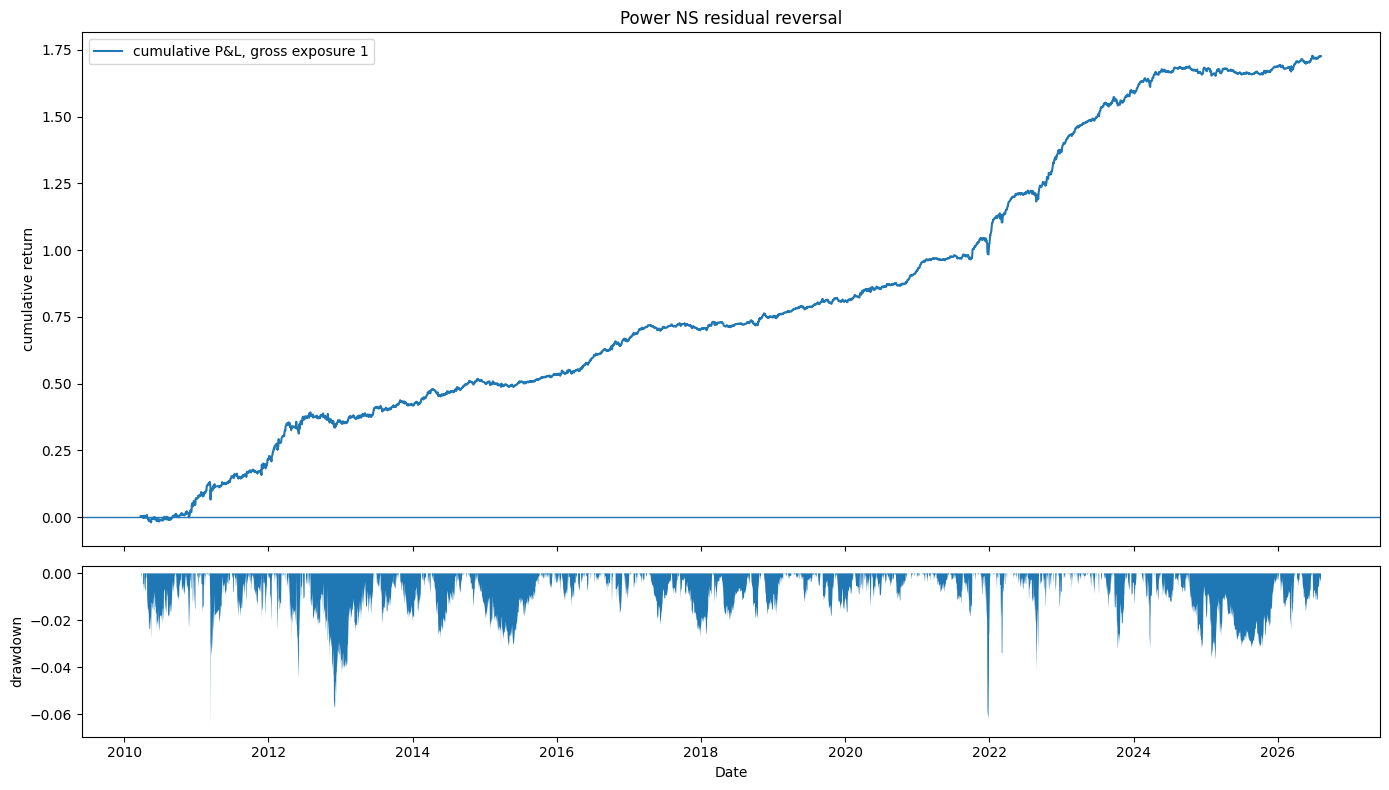

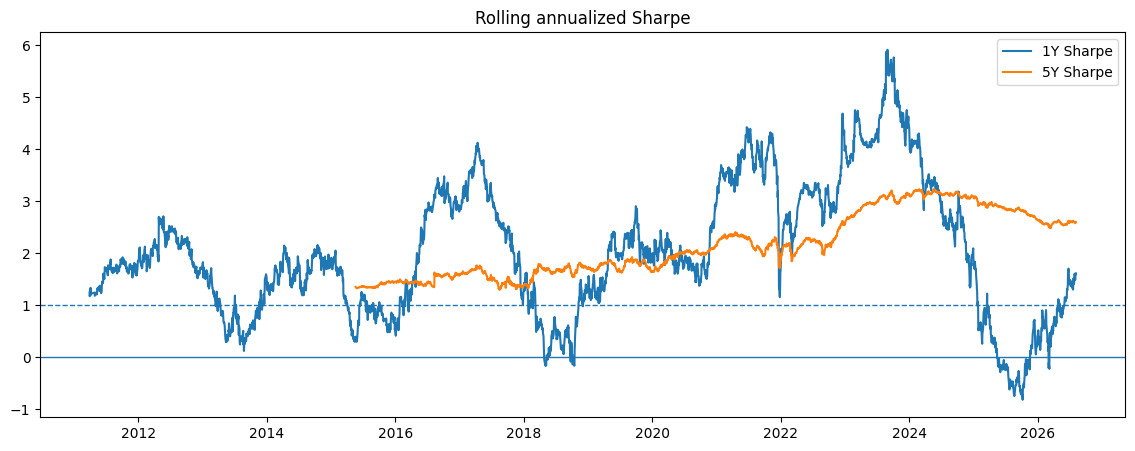

,1Y Sharpe,5Y Sharpe
count,3768.000,2810.000
mean,2.055,2.165
std,1.284,0.598
min,-0.815,1.298
25%,1.123,1.658
50%,1.885,2.041
75%,2.990,2.726
max,5.912,3.237


share of 1Y windows below 0 : 0.039
share of 1Y windows below 1 : 0.210


In [38]:
# ============================================================
# 7.6 PORTFOLIO RESULTS, WEALTH CURVE, ROLLING SHARPE
# ============================================================

residual_portfolio = resid_base_trade["gross"].dropna()

display(performance_stats(residual_portfolio).to_frame("Residual Reversal").round(4))

assert residual_portfolio.notna().sum() >= \
    resid_base_trade["market_gross"].notna().sum().max(), \
    "portfolio N below the largest market N -- stale panel"

# Additive P&L on fixed notional. The legs are a spread with gross exposure 1,
# so returns are on notional, not on capital, and (1+r).cumprod() implies a
# reinvestment that does not happen. Compounding also distorts drawdown badly
# (the benchmark tables in the original notebook showed -99% for this reason).
cum = residual_portfolio.cumsum()
drawdown_path = drawdown(residual_portfolio)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                       gridspec_kw={"height_ratios": [3, 1]})
ax[0].plot(cum.index, cum, label="cumulative P&L, gross exposure 1")
ax[0].axhline(0, linewidth=1)
ax[0].set_ylabel("cumulative return")
ax[0].set_title("Power NS residual reversal")
ax[0].legend()
ax[1].fill_between(drawdown_path.index, drawdown_path, 0)
ax[1].set_ylabel("drawdown")
ax[1].set_xlabel("Date")
plt.tight_layout()
plt.show()



roll = pd.DataFrame({
    "1Y Sharpe": sharpe(residual_portfolio, window=1 * TRADING_DAYS, min_periods=int(0.95 * TRADING_DAYS)),
    "5Y Sharpe": sharpe(residual_portfolio, window=5 * TRADING_DAYS, min_periods=int(0.95 * 5 * TRADING_DAYS)),
})

plt.figure(figsize=(14, 5))
for c in roll.columns:
    plt.plot(roll.index, roll[c], label=c)
plt.axhline(0, linewidth=1)
plt.axhline(1, linestyle="--", linewidth=1)
plt.title("Rolling annualized Sharpe")
plt.legend()
plt.show()

display(roll.describe().round(3))
print(f"share of 1Y windows below 0 : {(roll['1Y Sharpe'] < 0).mean():.3f}")
print(f"share of 1Y windows below 1 : {(roll['1Y Sharpe'] < 1).mean():.3f}")


In [39]:
# ============================================================
# 7.3 TURNOVER + TRANSACTION-COST STRESS TEST
# ============================================================

COST_GRID_BPS = [0.0, 1.0, 2.0, 3.0, 5.0, 8.0, 10.0, 13.0, 15.0]

cost_rows = {}

for cost_bps in COST_GRID_BPS:

    result = run_residual_portfolio(
        residual_weights_rev,
        prices,
        tickers,
        price_universe,
        lag=LAG_BASE,
        cost_bps=cost_bps,
    )

    stats = performance_stats(result["net"].dropna())

    cost_rows[cost_bps] = {
        "Annualized Mean": stats["Mean"],
        "Volatility": stats["Volatility"],
        "Sharpe": stats["Sharpe ratio"],
        "Maximum drawdown": stats["Maximum drawdown"],
        "Annualized Turnover": result["turnover"].mean() * TRADING_DAYS,
    }

residual_cost_dashboard = pd.DataFrame(cost_rows).T
residual_cost_dashboard.index.name = "Cost (bps / unit turnover)"

display(residual_cost_dashboard.round(4))


# ------------------------------------------------------------
# BREAK-EVEN COST
#
#   E[r_net] = E[r_gross] - c * E[turnover]
#
# Turnover here is contract-level and includes the roll, so this is
# the break-even that governs.
# ------------------------------------------------------------

gross_mean_daily = resid_base_trade["gross"].dropna().mean()
turnover_mean_daily = resid_base_trade["turnover"].dropna().mean()

break_even_cost_bps = (
    gross_mean_daily / turnover_mean_daily * 10000.0
    if turnover_mean_daily > 0 else np.nan
)

print(f"Average daily gross return : {gross_mean_daily:.6f}")
print(f"Average daily turnover     : {turnover_mean_daily:.4f}")
print(f"Annualized turnover        : {turnover_mean_daily * TRADING_DAYS:.1f}")
print(f"Break-even cost            : {break_even_cost_bps:.1f} bps / unit turnover")

,Annualized Mean,Volatility,Sharpe,Maximum drawdown,Annualized Turnover
Cost (bps / unit turnover),,,,,
0.0,0.1086,0.0573,1.8939,-0.0662,53.642
1.0,0.1032,0.0573,1.8003,-0.0662,53.642
2.0,0.0979,0.0573,1.7065,-0.0662,53.642
3.0,0.0925,0.0574,1.6124,-0.0662,53.642
5.0,0.0818,0.0574,1.4240,-0.0662,53.642
8.0,0.0657,0.0576,1.1410,-0.0695,53.642
10.0,0.0549,0.0577,0.9524,-0.0824,53.642
13.0,0.0388,0.0579,0.6706,-0.1044,53.642
15.0,0.0281,0.0581,0.4837,-0.1191,53.642


Average daily gross return : 0.000431
Average daily turnover     : 0.2129
Annualized turnover        : 53.6
Break-even cost            : 20.2 bps / unit turnover


## 7.3b Contract-level turnover

Everything above measures turnover on **generic rank** weights, and skips any
day on which the strict panel cannot measure a return. Both choices understate
what the strategy actually trades.

A generic rank is a label, not a position. On a standard roll the strip
`(A,B,C,D)` becomes `(B,C,D,E)`, so holding the same generic weights means
selling A outright, moving B from `w2` to `w1`, C from `w3` to `w2`, and D from
`w4` to `w3`. The generic weight vector is unchanged and rank-level turnover
reads zero, but roughly two units of notional have changed hands.

The functions below rebuild the position at the level of the **specific futures
contract** and difference that. Turnover accrues whether or not P&L is
measurable on the day, because a roll costs money even when the strict panel
drops the return. Unmeasurable-day turnover is carried forward and charged on
the next measurable day, so the net series stays daily and nothing is lost.

In [40]:
# ============================================================
# 7.3b TURNOVER AUDIT: SIGNAL VS ROLL
# ============================================================
#
# The engine's `market_turnover` is an ACCRUED series: turnover on a day
# with unmeasurable P&L is carried and charged later. That is right for
# costing, wrong for attribution, because roll days are exactly the days
# most likely to be displaced.
#
# So attribute over a window around each roll rather than on a single
# shifted flag. The window absorbs the roll-out buffer (which exits early)
# and the execution lag (which trades late) without assuming their net
# offset.
# ============================================================

def build_market_roll_flags(
    tickers,
    universe,
    max_rank=TRADE_MAX_RANK,     # was 8: a caller who omitted this counted
                                 # rolls in M5-M8, which are never held
):
    idx = tickers.index

    flags = pd.DataFrame(
        False,
        index=idx,
        columns=universe
    )

    for root in universe:

        cols = [
            f"{root}{k}"
            for k in range(1, max_rank + 1)
            if f"{root}{k}" in tickers.columns
        ]

        if len(cols) == 0:
            continue

        tk = tickers[cols]

        changed = (
            tk.ne(tk.shift(1))
            & tk.notna()
            & tk.shift(1).notna()
        )

        flags[root] = changed.any(axis=1)

    return flags


ROLL_ATTRIBUTION_WINDOW = (-ROLL_OUT_BUFFER, LAG_BASE + 1)

market_roll_flags = build_market_roll_flags(tickers, price_universe, MAX_RANK)

rows = []
for root in price_universe:

    to = resid_base_trade["market_turnover"][root]
    n = to.notna().sum()
    if n == 0:
        continue

    flag = market_roll_flags[root].reindex(to.index).fillna(False)
    near_roll = pd.Series(False, index=to.index)
    for off in range(ROLL_ATTRIBUTION_WINDOW[0], ROLL_ATTRIBUTION_WINDOW[1] + 1):
        near_roll |= flag.shift(off).fillna(False)

    baseline = to.where(~near_roll).mean()          # per-day, away from rolls
    total = to.mean() * TRADING_DAYS

    rows.append({
        "Market": root,
        "Total": total,
        "Baseline (non-roll)": baseline * TRADING_DAYS,
        "Roll excess": total - baseline * TRADING_DAYS,
        "Rolls / yr": flag[to.notna()].sum() / n * TRADING_DAYS,
        "Per roll": (total - baseline * TRADING_DAYS)
                    / max(flag[to.notna()].sum() / n * TRADING_DAYS, 1e-9),
        "Coverage": resid_base_trade["market_coverage"][root].median(),
    })

turnover_audit = pd.DataFrame(rows).set_index("Market")
display(turnover_audit.round(2))

print(f"Portfolio turnover : {turnover_audit['Total'].mean():.1f} / yr")
print(f"  roll excess      : {turnover_audit['Roll excess'].mean():.1f}"
      f"  ({turnover_audit['Roll excess'].mean() / turnover_audit['Total'].mean():.0%})")
print(f"  per roll         : {turnover_audit['Per roll'].mean():.2f} units")
print()
print("The roll is a standing cost. It does not shrink when you rebalance")
print("more slowly, so it sets a floor under the holding-period test below.")

,Total,Baseline (non-roll),Roll excess,Rolls / yr,Per roll,Coverage
Market,,,,,,
ZUB,59.47,39.65,19.82,10.32,1.92,1.0
ITP,57.82,38.68,19.15,10.71,1.79,1.0
DET,46.02,23.51,22.50,10.27,2.19,1.0
FAC,48.38,27.66,20.71,11.19,1.85,1.0
DFP,47.25,27.05,20.20,10.66,1.89,1.0
SXD,59.74,40.88,18.86,10.79,1.75,1.0
UTD,55.72,34.31,21.41,10.81,1.98,1.0
MSP,63.27,44.17,19.10,10.44,1.83,1.0
PHB,55.58,36.71,18.87,5.49,3.44,1.0


Portfolio turnover : 54.1 / yr
  roll excess      : 20.3  (37%)
  per roll         : 2.19 units

The roll is a standing cost. It does not shrink when you rebalance
more slowly, so it sets a floor under the holding-period test below.


In [41]:
# ============================================================
# 7.3c IMPLEMENTATION-DELAY LADDER
# ============================================================
#
# ENGINE lag L uses signal t-L on return t-1 -> t.
# Therefore:
#       L = 1  => 0 additional days after observing settlement t-1
#       L = 2  => 1 full trading-day implementation delay
#
# Decay is benchmarked against AR(1) of the ACTUAL traded coordinate z=n'e,
# not the raw individual NS residuals.
# ============================================================

rho_rows = []
for market in price_universe:
    z = signed_null_coordinate(market)
    cols = [f"{market}{k}" for k in range(1, TRADE_MAX_RANK + 1)]
    tk = tickers.reindex(z.index)[cols]
    changed = tk.ne(tk.shift(1)).any(axis=1) | tk.isna().any(axis=1)
    same = ~changed
    d = pd.DataFrame({"z": z, "lag": z.shift(1)}).where(same).dropna()
    if len(d) >= 100:
        rho_rows.append(sm.OLS(d["z"], sm.add_constant(d["lag"])).fit().params["lag"])
RHO = float(np.mean(rho_rows))

lag_rows = {}
for L in [1, 2, 3, 4, 5]:
    r = run_residual_portfolio(
        residual_weights_rev, prices, tickers, price_universe,
        lag=L, cost_bps=2.0,
    )
    g = performance_stats(r["gross"].dropna())
    n = performance_stats(r["net"].dropna())
    delay = L - 1
    lag_rows[delay] = {
        "engine lag": L,
        "N": r["net"].notna().sum(),
        "Gross Mean": g["Mean"],
        "Gross Sharpe": g["Sharpe ratio"],
        "Net Sharpe @ 2bps": n["Sharpe ratio"],
        "Ann Turnover": r["turnover"].mean() * TRADING_DAYS,
    }

lag_ladder = pd.DataFrame(lag_rows).T
lag_ladder.index.name = "Additional implementation delay after signal (days)"
lag_ladder["Step ratio"] = lag_ladder["Gross Mean"] / lag_ladder["Gross Mean"].shift(1)

print(f"Mean traded-coordinate AR(1): {RHO:.4f}")
print("IMPORTANT: row 0 is same-settlement execution; row 1 is a one-day delayed implementation.")
display(lag_ladder.round(4))


Mean traded-coordinate AR(1): 0.9583
IMPORTANT: row 0 is same-settlement execution; row 1 is a one-day delayed implementation.


,engine lag,N,Gross Mean,Gross Sharpe,Net Sharpe @ 2bps,Ann Turnover,Step ratio
Additional implementation delay after signal (days),,,,,,,
0,1.0,4006.0,0.1086,1.8939,1.7065,53.6420,NaN
1,2.0,3809.0,0.0815,1.4192,1.2228,56.4372,0.7502
2,3.0,3609.0,0.0606,1.0474,0.8406,59.5715,0.7441
3,4.0,3412.0,0.0621,1.0753,0.8569,63.0509,1.0243
4,5.0,3222.0,0.0539,0.9252,0.6952,66.7453,0.8675


In [42]:
# ============================================================
# 7.3d FIT-DEPTH CHANGE DIAGNOSTIC
# ============================================================
# LAMBDA_FIT=None is intentionally retained. Because the fit lambda is
# depth-adaptive, changing N_contracts can move the residual mechanically.
# This diagnostic asks directly whether those dates carry the strategy.
# ============================================================

_depth_panel = ns_results["N_contracts"].unstack("Commodity").reindex(prices.index)
_depth_change = _depth_panel.ne(_depth_panel.shift(1))

_rows = []
for _period, _sl in [("FULL", slice(None)), ("TEST", slice(TEST_START, None))]:
    _sum_by_state = {"depth stable": 0.0, "depth changed": 0.0}
    _obs_by_state = {"depth stable": [], "depth changed": []}

    for root in price_universe:
        pnl = resid_base_trade["market_gross"][root].loc[_sl]
        ch = _depth_change[root].reindex(pnl.index).fillna(False)
        for label, mask in [("depth stable", ~ch), ("depth changed", ch)]:
            x = pnl.where(mask).dropna()
            if len(x):
                _sum_by_state[label] += float(x.sum())
                _obs_by_state[label].extend(x.to_numpy(float))

    _total = sum(_sum_by_state.values())
    for label in ["depth stable", "depth changed"]:
        x = pd.Series(_obs_by_state[label], dtype=float)
        _rows.append({
            "period": _period,
            "State": label,
            "N market-days": len(x),
            "Ann mean": x.mean() * TRADING_DAYS if len(x) else np.nan,
            "Sharpe": sharpe(x, min_obs=20) if len(x) >= 20 else np.nan,
            "P&L share": _sum_by_state[label] / _total if abs(_total) > 1e-12 else np.nan,
        })

fit_depth_pnl = pd.DataFrame(_rows).set_index(["period", "State"])
print("P&L conditional on whether the selected NS fit depth changed:")
display(fit_depth_pnl.round(4))


P&L conditional on whether the selected NS fit depth changed:


N market-days  Ann mean  Sharpe  P&L share
period State                                                    
FULL   depth stable           25644    0.1121  1.1559     0.9881
       depth changed            401    0.0864  1.3871     0.0119
TEST   depth stable           12652    0.1471  1.2768     0.9945
       depth changed            225    0.0455  0.6315     0.0055

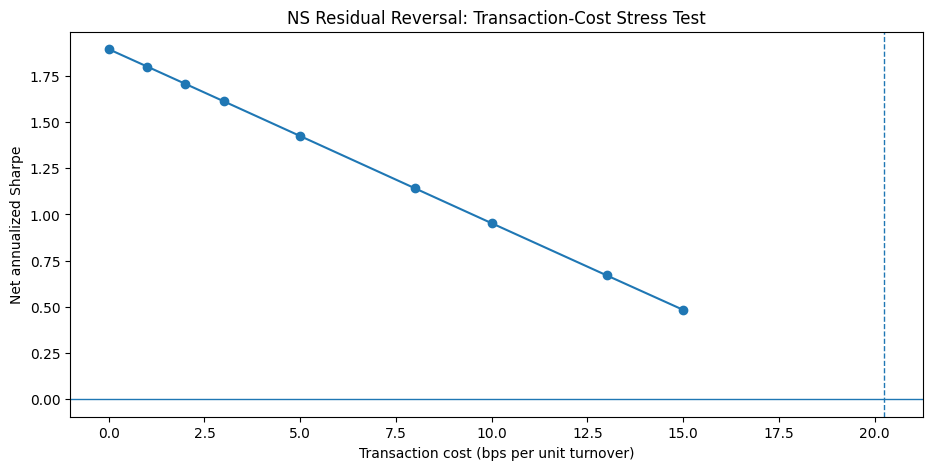

Break-even: 20.2 bps
Turnover is contract-level and includes the roll, so this curve is
the one to quote. Earlier versions of this notebook charged only
Contract-level turnover is the authoritative cost input; rank-level approximations are not used.


In [43]:
# ============================================================
# 7.3d NET SHARPE CURVE
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    residual_cost_dashboard.index,
    residual_cost_dashboard["Sharpe"],
    marker="o",
)

plt.axhline(0, linewidth=1)
plt.axvline(break_even_cost_bps, linestyle="--", linewidth=1)

plt.xlabel("Transaction cost (bps per unit turnover)")
plt.ylabel("Net annualized Sharpe")
plt.title("NS Residual Reversal: Transaction-Cost Stress Test")

plt.show()

print(f"Break-even: {break_even_cost_bps:.1f} bps")
print("Turnover is contract-level and includes the roll, so this curve is")
print("the one to quote. Earlier versions of this notebook charged only")
print("Contract-level turnover is the authoritative cost input; rank-level approximations are not used.")

In [44]:
# ============================================================
# 7.6 REBALANCING / HOLDING-PERIOD TEST
# ============================================================
#
# h = 1 means daily rebalancing.
# h = 5 means update the residual portfolio every fifth trading day
# and hold the most recently formed weights between rebalance dates.
#
# This is intentionally a trading-frequency test rather than a
# forward-return regression.
# ============================================================

def rebalance_every_n_days(weights_by_rank, n_days):
    """Refresh weights on schedule and hold at most until the next scheduled refresh."""
    if n_days == 1:
        return weights_by_rank
    out = {}
    for k, df in weights_by_rank.items():
        keep = np.arange(len(df)) % n_days == 0
        x = df.copy() * np.nan
        x.loc[keep, :] = df.loc[keep, :]
        out[k] = x.ffill(limit=n_days - 1)
    return out


HOLDING_PERIODS = [1, 2, 3, 5, 10]
HOLD_COST_BPS = 2.0

holding_rows = {}

for h in HOLDING_PERIODS:

    held = rebalance_every_n_days(residual_weights_rev, h)

    result = run_residual_portfolio(
        held,
        prices,
        tickers,
        price_universe,
        lag=LAG_BASE,
        cost_bps=HOLD_COST_BPS,
    )

    gross_stats = performance_stats(
        result["gross"].dropna()
    )

    net_stats = performance_stats(
        result["net"].dropna()
    )

    holding_rows[h] = {
        "N": result["net"].notna().sum(),
        "Gross Mean": gross_stats["Mean"],
        "Gross Sharpe": gross_stats["Sharpe ratio"],
        f"Net Mean @ {HOLD_COST_BPS:g}bps": net_stats["Mean"],
        f"Net Sharpe @ {HOLD_COST_BPS:g}bps": net_stats["Sharpe ratio"],
        "Annualized Turnover": result["turnover"].mean() * TRADING_DAYS,
    }


residual_holding_dashboard = (
    pd.DataFrame(holding_rows)
    .T
)

residual_holding_dashboard.index.name = "Rebalance every N days"

display(
    residual_holding_dashboard.round(4)
)

,N,Gross Mean,Gross Sharpe,Net Mean @ 2bps,Net Sharpe @ 2bps,Annualized Turnover
Rebalance every N days,,,,,,
1,4006.0,0.1086,1.8939,0.0979,1.7065,53.6420
2,3967.0,0.0869,1.5238,0.0768,1.3462,50.6001
3,3949.0,0.0731,1.2652,0.0628,1.0860,51.5581
5,3910.0,0.0555,0.9648,0.0458,0.7964,48.4039
10,3864.0,0.0384,0.6683,0.0292,0.5087,45.8359


In [45]:


def expand_roll_window(roll_flags, window):
    """
    True on roll date and +/- window observations around it.
    """
    if window == 0:
        return roll_flags.copy()

    expanded = pd.DataFrame(
        False,
        index=roll_flags.index,
        columns=roll_flags.columns
    )

    for shift_n in range(-window, window + 1):
        expanded = expanded | roll_flags.shift(
            shift_n,
            fill_value=False
        )

    return expanded


ROLL_WINDOWS = [0, 1, 2, 3]
ROLL_COST_BPS = 2.0

roll_rows = {}

for window in ROLL_WINDOWS:

    excluded = expand_roll_window(
        market_roll_flags,
        window
    )

    # Start from the already correctly constructed market-level
    # gross P&L and turnover, then remove market-days close to rolls.
    market_gross = (
        resid_base_trade["market_gross"]
        .where(~excluded)
    )

    market_turnover = (
        resid_base_trade["market_turnover"]
        .where(~excluded)
    )

    available = market_gross.notna().astype(float)

    n_active = (
        available.sum(axis=1)
        .replace(0, np.nan)
    )

    mw = available.div(n_active, axis=0)

    gross = (
        (mw * market_gross)
        .sum(axis=1, min_count=1)
    )

    turnover = (
        (mw * market_turnover)
        .sum(axis=1, min_count=1)
    )

    net = (
        gross
        - (ROLL_COST_BPS / 10000.0)
        * turnover
    )

    gross_stats = performance_stats(
        gross.dropna()
    )

    net_stats = performance_stats(
        net.dropna()
    )

    roll_rows[window] = {
        "N": net.notna().sum(),
        "Gross Mean": gross_stats["Mean"],
        "Gross Sharpe": gross_stats["Sharpe ratio"],
        f"Net Mean @ {ROLL_COST_BPS:g}bps": net_stats["Mean"],
        f"Net Sharpe @ {ROLL_COST_BPS:g}bps": net_stats["Sharpe ratio"],
        "Annualized Turnover": turnover.mean() * TRADING_DAYS,
    }


residual_roll_dashboard = (
    pd.DataFrame(roll_rows)
    .T
)

residual_roll_dashboard.index.name = "+/- observations excluded around roll"

display(
    residual_roll_dashboard.round(4)
)


,N,Gross Mean,Gross Sharpe,Net Mean @ 2bps,Net Sharpe @ 2bps,Annualized Turnover
+/- observations excluded around roll,,,,,,
0,3953.0,0.1114,1.9224,0.1015,1.7522,49.2515
1,3584.0,0.1143,1.9815,0.1075,1.8641,34.0348
2,3207.0,0.1092,1.9124,0.1025,1.7968,33.1071
3,2832.0,0.1065,1.8430,0.0998,1.7282,33.3704


In [46]:
# ============================================================
# 7.8 ASSET-LEVEL NET RESULTS
# ============================================================

ASSET_COST_BPS = 2.0

asset_cost_result = run_residual_portfolio(
    residual_weights_rev, prices, tickers, price_universe,
    lag=LAG_BASE, cost_bps=ASSET_COST_BPS,
)

asset_net_rows = {}

for root in price_universe:

    r = (
        asset_cost_result["market_net"][root]
        .dropna()
    )

    if len(r) < 50:
        continue

    s = performance_stats(r)

    asset_net_rows[root] = {
        "N": s["N"],
        "Net Mean": s["Mean"],
        "Net Volatility": s["Volatility"],
        "Net Sharpe @ 2bps": s["Sharpe ratio"],
        "Maximum drawdown": s["Maximum drawdown"],
        "Annualized Turnover": (
            asset_cost_result["market_turnover"][root].mean()
            * TRADING_DAYS
        ),
    }


residual_asset_net_dashboard = (
    pd.DataFrame(asset_net_rows)
    .T
)

display(
    residual_asset_net_dashboard
    .sort_values(
        "Net Sharpe @ 2bps",
        ascending=False
    )
    .round(4)
)

,N,Net Mean,Net Volatility,Net Sharpe @ 2bps,Maximum drawdown,Annualized Turnover
PHB,3948.0,0.1353,0.0886,1.5266,-0.1443,55.5830
MSP,2535.0,0.1460,0.1020,1.4310,-0.1756,63.2731
UTD,2075.0,0.1063,0.0930,1.1427,-0.1062,55.7162
DFP,2576.0,0.1109,0.1034,1.0729,-0.1306,47.2534
SXD,1798.0,0.1335,0.1307,1.0212,-0.1821,59.7380
ITP,2871.0,0.0638,0.0631,1.0107,-0.0847,57.8237
ZUB,1733.0,0.1062,0.1100,0.9656,-0.1677,59.4725
DET,2111.0,0.0622,0.0703,0.8838,-0.1227,46.0174
PCB,3044.0,0.0625,0.0731,0.8557,-0.1159,47.9631
FAC,3354.0,0.0862,0.1217,0.7086,-0.2805,48.3774


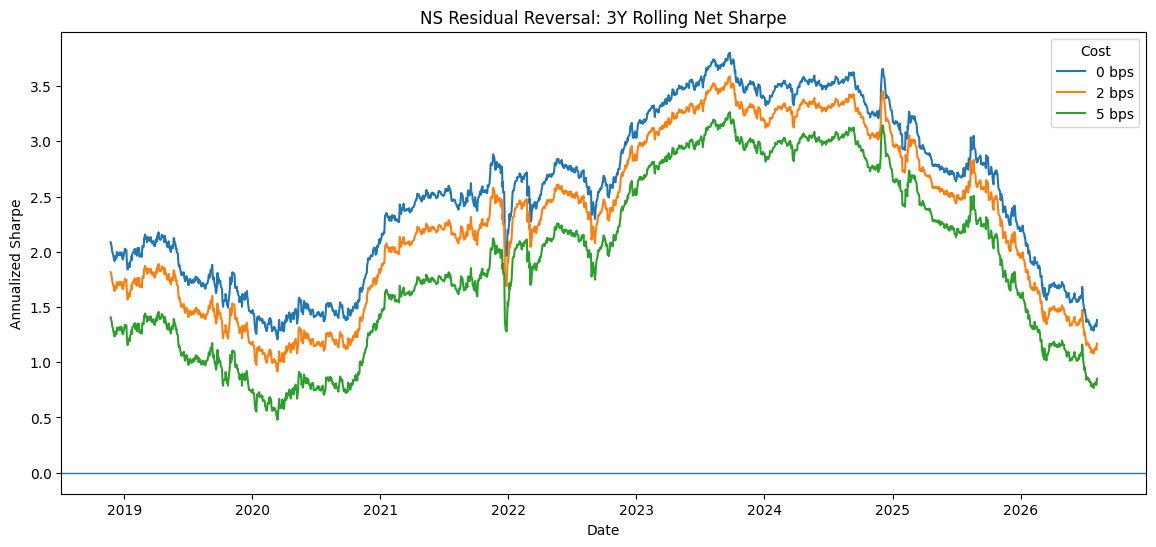

,0 bps,2 bps,5 bps
count,1971.000,1971.000,1971.000
mean,2.522,2.280,1.915
std,0.734,0.758,0.795
min,1.207,0.916,0.479
25%,1.863,1.595,1.195
50%,2.542,2.260,1.880
75%,3.219,3.013,2.696
max,3.802,3.587,3.263


In [47]:
# ============================================================
# 7.9 ROLLING NET SHARPE AT SELECTED COSTS
# ============================================================

ROLLING_COSTS_BPS = [0.0, 2.0, 5.0]

rolling_net = {}

for cost_bps in ROLLING_COSTS_BPS:

    result = run_residual_portfolio(
        residual_weights_rev, prices, tickers, price_universe,
        lag=LAG_BASE, cost_bps=cost_bps,
    )

    rolling_net[f"{cost_bps:g} bps"] = (
        sharpe(result["net"], window=3 * TRADING_DAYS, min_periods=int(0.95 * 3 * TRADING_DAYS))
    )


rolling_net_sharpe = pd.DataFrame(
    rolling_net
)


plt.figure(figsize=(14, 6))

for col in rolling_net_sharpe.columns:
    plt.plot(
        rolling_net_sharpe.index,
        rolling_net_sharpe[col],
        label=col
    )

plt.axhline(0, linewidth=1)

plt.title(
    "NS Residual Reversal: 3Y Rolling Net Sharpe"
)

plt.ylabel("Annualized Sharpe")
plt.xlabel("Date")
plt.legend(title="Cost")

plt.show()


display(
    rolling_net_sharpe
    .describe()
    .round(3)
)


### How to read the dashboard

The residual strategy becomes economically compelling if several things hold together:

- the **break-even cost** is comfortably above a realistic estimate of execution costs;
- net Sharpe decays gradually rather than collapsing immediately as costs are introduced;
- the signal-magnitude diagnostic shows whether discarded |z| contains useful information;
- slower rebalancing retains a meaningful fraction of the gross alpha;
- performance survives excluding wider windows around generic rolls;
- net results have reasonable breadth across power markets rather than being driven by one contract.

The dashboard intentionally does **not** optimize these choices. The threshold, cost, holding-period, and roll-window grids are robustness tests. Any eventual production specification should be chosen out of sample rather than selected because it maximizes the historical Sharpe.


In [48]:
# ============================================================
# ROLLING RESIDUAL CONVERGENCE SPEED
# ============================================================
#
# Regression:
#
#     delta e_(t+1) = alpha + beta * e_t + error
#
# beta < 0  -> residual mean reversion
# more negative beta -> faster convergence
# beta near zero     -> slower convergence / weaker mean reversion
#
# Rolling 2-year window, every market x maturity rank.
#
# The rolling regression uses the closed-form univariate OLS slope rather
# than refitting statsmodels at every date. This is algebraically equivalent
# and materially reduces notebook runtime.
#
# TIMING. The regression is timestamped on the REALISED date:
#     delta e_t = e_t - e_{t-1}  on  e_{t-1}.
# This is algebraically the same one-step convergence relation, but no row
# contains t+1 information stamped at t.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROLLING_WINDOW = 2 * TRADING_DAYS
MIN_OBS = int(ROLLING_WINDOW * 0.80)


def rolling_residual_convergence(
    residual,
    ticker,
    window=ROLLING_WINDOW,
    min_obs=MIN_OBS,
):
    """
    Rolling estimation of

        delta e_t = alpha + beta * e_(t-1) + epsilon_t

    using only observations where the SAME specific contract remains at the
    generic rank from t-1 to t.

    Closed-form rolling OLS. Exactly reproduces the previous per-day
    statsmodels loop, including the min_obs rule and the NaN handling: an
    observation counts only when BOTH the regressor and the dependent
    variable are present, which is what `.dropna()` did.
    """
    residual = pd.Series(residual).copy()
    ticker = ticker.reindex(residual.index)

    future_change = residual - residual.shift(1)

    same_contract = (
        ticker.eq(ticker.shift(1))
        & ticker.notna()
        & ticker.shift(1).notna()
    )

    x = residual.shift(1).where(same_contract)
    y = future_change.where(same_contract)

    valid = x.notna() & y.notna()
    x0 = x.where(valid, 0.0)
    y0 = y.where(valid, 0.0)

    n = valid.astype(float).rolling(window).sum()
    Sx = x0.rolling(window).sum()
    Sy = y0.rolling(window).sum()
    Sxx = (x0 * x0).rolling(window).sum()
    Sxy = (x0 * y0).rolling(window).sum()

    den = Sxx - Sx * Sx / n
    beta = (Sxy - Sx * Sy / n) / den

    keep = (n >= min_obs) & (den.abs() > 1e-12)

    return pd.DataFrame({
        "beta": beta.where(keep),
        "N": n.where(n >= min_obs),
    })

In [49]:
# ============================================================
# RUN FOR ALL POWER MARKET x RANK SERIES
# ============================================================

rolling_beta_dict = {}


for market in price_universe:

    for k in range(1, 5):

        key = (
            market,
            f"M{k}"
        )


        rolling_beta_dict[key] = (
            rolling_residual_convergence(

                residual=
                    ns_residual_by_rank[
                        k
                    ][market],

                ticker=
                    tickers[
                        f"{market}{k}"
                    ],

                window=
                    ROLLING_WINDOW,

                min_obs=
                    MIN_OBS
            )
        )

In [50]:
# ============================================================
# ROLLING BETA PANEL
# ============================================================

rolling_beta_panel = pd.concat(

    {
        key:
            value["beta"]

        for key, value
        in rolling_beta_dict.items()
    },

    axis=1
)


rolling_beta_panel.columns = (
    pd.MultiIndex.from_tuples(
        rolling_beta_panel.columns,
        names=[
            "Market",
            "Rank"
        ]
    )
)


print(
    "Rolling beta panel shape:",
    rolling_beta_panel.shape
)

Rolling beta panel shape: (4418, 40)


In [51]:
# ============================================================
# CROSS-SECTIONAL CONVERGENCE SUMMARY
# ============================================================
pct_negative_beta = (
    (rolling_beta_panel < 0).sum(axis=1)
    /
    rolling_beta_panel.notna().sum(axis=1))

rolling_convergence_summary = pd.DataFrame({

    "Median Beta":
        rolling_beta_panel.median(
            axis=1
        ),

    "Mean Beta":
        rolling_beta_panel.mean(
            axis=1
        ),

    "25th Percentile":
        rolling_beta_panel.quantile(
            0.25,
            axis=1
        ),

    "75th Percentile":
        rolling_beta_panel.quantile(
            0.75,
            axis=1
        ),

    "% Negative Beta" : pct_negative_beta,

    "N Series":
        rolling_beta_panel.notna()
        .sum(
            axis=1
        )
})

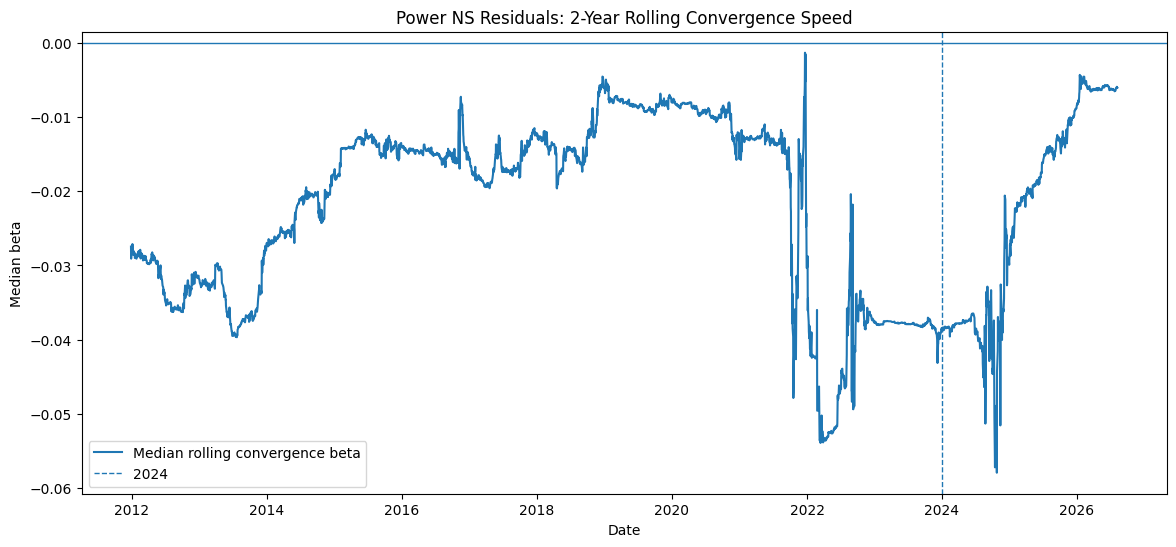

In [52]:
# ============================================================
# PLOT MEDIAN ROLLING CONVERGENCE SPEED
# ============================================================

plt.figure(
    figsize=(14, 6)
)


plt.plot(
    rolling_convergence_summary.index,
    rolling_convergence_summary[
        "Median Beta"
    ],
    label=
        "Median rolling convergence beta"
)


plt.axhline(
    0,
    linewidth=1
)


plt.axvline(
    pd.Timestamp(
        "2024-01-01"
    ),
    linestyle="--",
    linewidth=1,
    label="2024"
)


plt.title(
    "Power NS Residuals: "
    "2-Year Rolling Convergence Speed"
)

plt.ylabel(
    "Median beta"
)

plt.xlabel(
    "Date"
)

plt.legend()

plt.show()

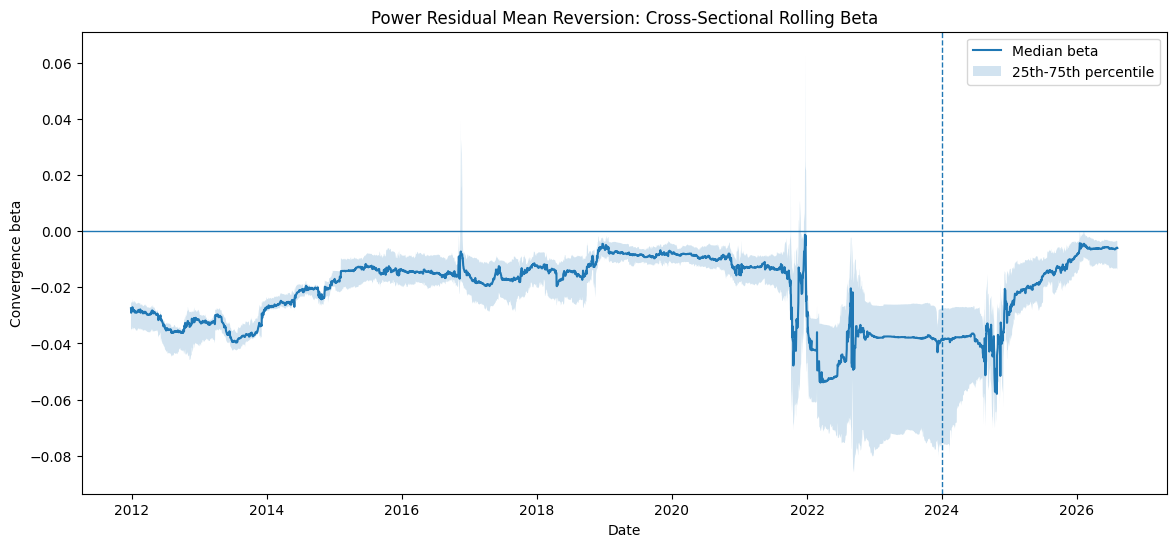

In [53]:
# ============================================================
# MEDIAN + CROSS-SECTIONAL RANGE
# ============================================================

plt.figure(
    figsize=(14, 6)
)


plt.plot(
    rolling_convergence_summary.index,
    rolling_convergence_summary[
        "Median Beta"
    ],
    label="Median beta"
)


plt.fill_between(

    rolling_convergence_summary.index,

    rolling_convergence_summary[
        "25th Percentile"
    ],

    rolling_convergence_summary[
        "75th Percentile"
    ],

    alpha=0.20,

    label=
        "25th-75th percentile"
)


plt.axhline(
    0,
    linewidth=1
)


plt.axvline(
    pd.Timestamp(
        "2024-01-01"
    ),
    linestyle="--",
    linewidth=1
)


plt.title(
    "Power Residual Mean Reversion: "
    "Cross-Sectional Rolling Beta"
)

plt.ylabel(
    "Convergence beta"
)

plt.xlabel(
    "Date"
)

plt.legend()

plt.show()

In [54]:
# ============================================================
# PRE / POST 2024 COMPARISON
# ============================================================

pre24 = (
    rolling_convergence_summary
    .loc[
        :"2023-12-31"
    ]
)


post24 = (
    rolling_convergence_summary
    .loc[
        "2024-01-01":
    ]
)


comparison = pd.DataFrame({

    "Pre-2024": {

        "Median Beta":
            pre24[
                "Median Beta"
            ].median(),

        "Mean Beta":
            pre24[
                "Mean Beta"
            ].mean(),

        "% Negative":
            pre24[
                "% Negative Beta"
            ].mean()
    },


    "2024+": {

        "Median Beta":
            post24[
                "Median Beta"
            ].median(),

        "Mean Beta":
            post24[
                "Mean Beta"
            ].mean(),

        "% Negative":
            post24[
                "% Negative Beta"
            ].mean()
    }

})


display(
    comparison.round(4)
)

,Pre-2024,2024+
Median Beta,-0.0167,-0.0199
Mean Beta,-0.0242,-0.0253
% Negative,0.9428,0.9212


In [55]:
# ============================================================
# YEARLY PERFORMANCE AND MECHANISM STABILITY
# ============================================================
# Performance columns use the same canonical definitions as every other table.
# ============================================================

residual_portfolio = resid_base_trade["gross"].dropna()

yearly_rows = []
for year, x in residual_portfolio.groupby(residual_portfolio.index.year):
    s = performance_stats(x)
    yearly_rows.append({
        "Year": year,
        "N": s["N"],
        "Mean": s["Mean"],
        "Vol": s["Volatility"],
        "Sharpe": s["Sharpe ratio"],
        "MaxDD": s["Maximum drawdown"],
    })

yearly = pd.DataFrame(yearly_rows).set_index("Year")

# ---- convergence beta, estimated within each calendar year -----------------
# Same regression as the convergence diagnostic, restricted to same-contract
# transitions. Average to market level first so ranks from the same curve are
# not treated as independent markets.

beta_rows = []
for root in price_universe:
    for k in range(1, MAX_RANK + 1):

        e = ns_residual_by_rank[k][root]
        tk = tickers[f"{root}{k}"].reindex(e.index)

        d = pd.DataFrame({
            "e": e.shift(1),
            "de": e - e.shift(1),
            "same": tk.eq(tk.shift(1)) & tk.notna() & tk.shift(1).notna(),
        }).dropna()
        d = d[d["same"]]

        for year, chunk in d.groupby(d.index.year):
            if len(chunk) < 100:
                continue
            fit = sm.OLS(chunk["de"], sm.add_constant(chunk["e"])).fit()
            beta_rows.append({"Year": year, "Market": root, "beta": fit.params["e"]})

beta_panel = pd.DataFrame(beta_rows)

by_market_year = beta_panel.groupby(["Year", "Market"])["beta"].mean()
yearly_beta = by_market_year.groupby("Year").agg(
    median_beta="median",
    pct_negative=lambda x: (x < 0).mean(),
    n_markets="count",
)
yearly_beta["halflife"] = np.log(0.5) / np.log(1 + yearly_beta["median_beta"])

yearly = yearly.join(yearly_beta)
yearly = yearly[yearly["N"] > 60]

display(yearly.round(3))

se = np.sqrt(TRADING_DAYS / yearly["N"])
print("Yearly Sharpe point estimates are descriptive; use the block-bootstrap/serial-correlation diagnostics elsewhere for uncertainty.")
print()
print("Read the beta column for decay. A Sharpe that falls while median_beta")
print("holds is variance; a beta rising toward zero is the edge going away.")


,N,Mean,Vol,Sharpe,MaxDD,median_beta,pct_negative,n_markets,halflife
Year,,,,,,,,,
2010,180.0,0.098,0.070,1.398,-0.028,-0.019,1.000,1,35.900
2011,225.0,0.165,0.105,1.568,-0.066,-0.046,1.000,1,14.630
2012,230.0,0.160,0.102,1.565,-0.057,-0.030,1.000,1,22.911
2013,238.0,0.062,0.054,1.136,-0.021,-0.014,1.000,3,49.429
2014,236.0,0.090,0.045,2.011,-0.028,-0.018,1.000,3,38.606
2015,232.0,0.030,0.036,0.835,-0.022,-0.012,1.000,4,57.288
2016,241.0,0.136,0.048,2.836,-0.018,-0.020,1.000,5,34.317
2017,240.0,0.041,0.029,1.414,-0.027,-0.015,0.857,7,47.071
2018,249.0,0.046,0.035,1.332,-0.020,-0.009,1.000,9,73.115


Yearly Sharpe point estimates are descriptive; use the block-bootstrap/serial-correlation diagnostics elsewhere for uncertainty.

Read the beta column for decay. A Sharpe that falls while median_beta
holds is variance; a beta rising toward zero is the edge going away.


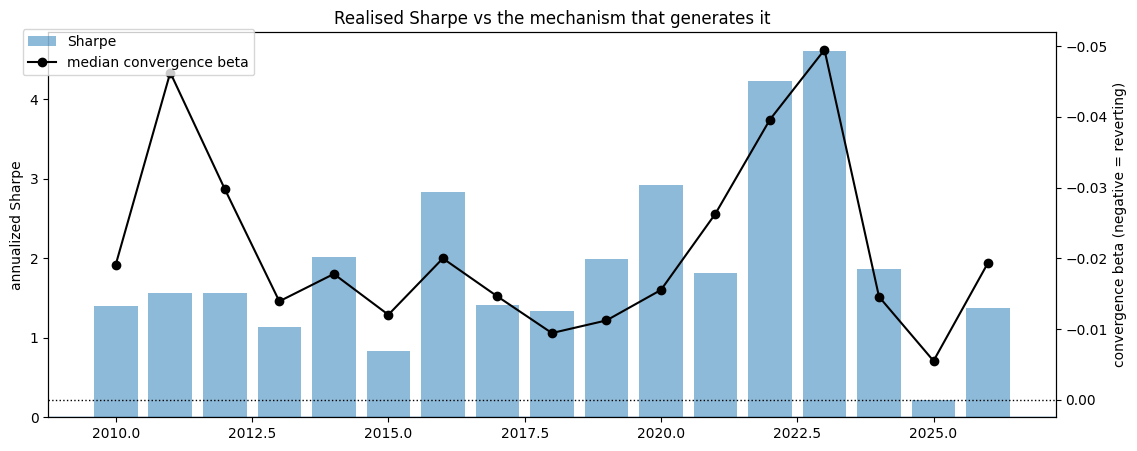

In [56]:
fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.bar(yearly.index, yearly["Sharpe"], alpha=0.5, label="Sharpe")
ax1.axhline(0, linewidth=1)
ax1.set_ylabel("annualized Sharpe")

ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly["median_beta"], marker="o",
         color="black", label="median convergence beta")
ax2.axhline(0, linestyle=":", linewidth=1, color="black")
ax2.set_ylabel("convergence beta (negative = reverting)")
ax2.invert_yaxis()          # more negative beta plots higher, matching Sharpe

ax1.set_title("Realised Sharpe vs the mechanism that generates it")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.9))
plt.show()

# 12 m4-m5

In [57]:
# ============================================================
# 14.1 RAW RESIDUAL CANDIDATES AT TRADE DEPTHS M4-M5
# ============================================================

DYNAMIC_MIN_DEPTH = 4
# ------------------------------------------------------------
# LIQUIDITY GOVERNANCE: TRADE AT MOST THROUGH M5; FIT MAY USE M1-M8.
# ------------------------------------------------------------
# M1-M4 is the core liquid curve. M5 is the only deferred leg eligible for
# production trading, and only when the causal capacity model can support the
# desired allocation. M6-M8 are fit-only inputs. This cap is a frozen liquidity
# governance assumption in this version; the production rule does not consult
# TEST performance.
#
# IMPORTANT: M1-M5 has a two-dimensional NS null space, whereas M1-M4 has one
# dimension. The M5 candidate is therefore an alternate residual portfolio,
# not literally the same fixed butterfly with one extra capacity leg. The
# liquidity rule governs *whether that alternate candidate is eligible*.
# ------------------------------------------------------------
DYNAMIC_MAX_DEPTH = 5
DYNAMIC_DEPTHS = list(range(DYNAMIC_MIN_DEPTH, DYNAMIC_MAX_DEPTH + 1))


def build_depth_residual_weights(
    residual_by_rank,
    ns_results,
    tickers,
    prices,
    universe,
    depth,
    lambda_trade=LAMBDA_TRADE,
):
    """General projected-residual builder; shared with the M1-M4 baseline."""
    return build_projected_residual_weights(
        residual_by_rank=residual_by_rank,
        ns_results=ns_results,
        tickers=tickers,
        prices=prices,
        universe=universe,
        depth=depth,
        lambda_trade=lambda_trade,
    )


candidate_weights_by_depth = {}
candidate_gross_by_depth = {}

for depth in DYNAMIC_DEPTHS:
    w, g = build_depth_residual_weights(
        residual_by_rank=ns_residual_by_rank,
        ns_results=ns_results,
        tickers=tickers,
        prices=prices,
        universe=price_universe,
        depth=depth,
        lambda_trade=LAMBDA_TRADE,
    )
    candidate_weights_by_depth[depth] = w
    candidate_gross_by_depth[depth] = g


# Guardrails: every market must retain the M4 floor; deeper candidates are optional.
_m4_counts = candidate_gross_by_depth[4].notna().sum()
_dead_m4 = _m4_counts[_m4_counts == 0].index.tolist()
if _dead_m4:
    raise ValueError(f"Markets with zero M1-M4 residual candidates: {_dead_m4}")

print("RAW candidate observations by market / traded depth")
display(pd.DataFrame({
    f"M1-M{d}": candidate_gross_by_depth[d].notna().sum()
    for d in DYNAMIC_DEPTHS
}).astype(int))

# Structural diagnostic: with three linearly independent NS factors, the
# projector dimension is depth - 3. Verify the actual design matrices used at
# representative maturities so the M4/M5 distinction is explicit.
_null_dim_rows = []
for _depth in DYNAMIC_DEPTHS:
    _M = np.arange(0.75, 0.75 + _depth, 1.0)
    _sl, _cv = ns_loadings(_M, LAMBDA_TRADE)
    _X = np.column_stack([np.ones(_depth), _sl, _cv])
    _rank = int(np.linalg.matrix_rank(_X))
    _null_dim_rows.append({
        "traded depth": _depth,
        "rank(X)": _rank,
        "null dimension": _depth - _rank,
    })
_null_dimension_table = pd.DataFrame(_null_dim_rows).set_index("traded depth")
print("NS traded-space dimensionality:")
display(_null_dimension_table)
assert _null_dimension_table.loc[4, "null dimension"] == 1
assert _null_dimension_table.loc[5, "null dimension"] == 2


RAW candidate observations by market / traded depth


,M1-M4,M1-M5
ZUB,1735,0
ITP,2874,2613
DET,2114,2114
FAC,3356,2413
DFP,2578,1342
SXD,1800,224
UTD,2076,2076
MSP,2537,2198
PHB,4079,4079
PCB,3131,3092


NS traded-space dimensionality:


,rank(X),null dimension
traded depth,,
4,3,1
5,3,2


In [58]:
# ============================================================
# 14.1c UNCONSTRAINED PRODUCTION VIEW: DYNAMIC M4/M5, NO LIQUIDITY
# ============================================================
# Production depth logic with the capacity test switched off: M5 is traded
# whenever the raw M5 candidate exists, otherwise the M1-M4 floor. No OI/DTV
# cap, no water-filling allocator, no AUM. Each market carries unit gross and
# live markets are equally weighted, exactly as in 7.5, so this table is
# directly comparable to the fixed M1-M4 baseline.
#
# Depth changes are NOT free here: the engine maps legs to specific contracts,
# so an M5 -> M4 switch is charged as real turnover on the same position path.

_have4 = candidate_gross_by_depth[4].notna()
_have5 = candidate_gross_by_depth[5].notna()

uncon_depth = (
    pd.DataFrame(np.nan, index=_have4.index, columns=price_universe, dtype=float)
    .mask(_have4, 4.0)
    .mask(_have5, 5.0)
)

_use5 = uncon_depth.eq(5.0)

uncon_weights = {}
for k in range(1, DYNAMIC_MAX_DEPTH + 1):
    w5 = candidate_weights_by_depth[5][k]
    w4 = (
        candidate_weights_by_depth[4][k]
        if k <= DYNAMIC_MIN_DEPTH
        else pd.DataFrame(np.nan, index=w5.index, columns=w5.columns, dtype=float)
    )
    uncon_weights[k] = w5.where(_use5, w4)

uncon_book = run_contract_positions(
    uncon_weights,
    prices,
    tickers,
    price_universe,
    max_rank=DYNAMIC_MAX_DEPTH,
    depth_panel=uncon_depth,
    min_depth=DYNAMIC_MIN_DEPTH,
    lag=LAG_BASE,
    cost_bps=0.0,
    market_aggregation="equal_available",
)


# ------------------------------------------------------------
# MARKET-LEVEL RESULTS AND CONTRACT TURNOVER
# ------------------------------------------------------------

uncon_asset_stats = pd.DataFrame({
    root: performance_stats(uncon_book["market_gross"][root].dropna())
    for root in price_universe
}).T

uncon_asset_stats["Annualized Turnover"] = pd.Series({
    root: uncon_book["market_turnover"][root].dropna().mean() * TRADING_DAYS
    for root in price_universe
})

uncon_asset_stats["% days at M5"] = (
    _use5.where(uncon_depth.notna()).mean()
)

print("UNCONSTRAINED PRODUCTION VIEW: DYNAMIC M4/M5, NO LIQUIDITY CONSTRAINT")

display(
    uncon_asset_stats[[
        "N",
        "Mean",
        "Alpha t-stat (NW)",
        "Alpha p-value (NW)",
        "Volatility",
        "Sharpe ratio",
        "Maximum drawdown",
        "Annualized Turnover",
        "% days at M5",
    ]]
    .sort_values("Sharpe ratio", ascending=False)
    .round(4)
)


# ------------------------------------------------------------
# BREADTH
# ------------------------------------------------------------

n_markets = len(uncon_asset_stats)

p = uncon_asset_stats["Alpha p-value (NW)"]
positive = uncon_asset_stats["Mean"] > 0

bonferroni = 0.05 / n_markets

uncon_breadth = pd.Series({
    "Number markets": n_markets,
    "% positive mean": positive.mean(),
    "% significant positive at 5%": (positive & (p < 0.05)).mean(),
    f"% significant at {bonferroni:.4f} (Bonferroni)":
        (positive & (p < bonferroni)).mean(),
    "Median market Sharpe": uncon_asset_stats["Sharpe ratio"].median(),
    "Weakest market Sharpe": uncon_asset_stats["Sharpe ratio"].min(),
    "Median annualized turnover": uncon_asset_stats["Annualized Turnover"].median(),
    "Highest annualized turnover": uncon_asset_stats["Annualized Turnover"].max(),
    "Portfolio share of days at M5": _use5.sum().sum() / uncon_depth.notna().sum().sum(),
})

display(uncon_breadth.to_frame("Dynamic M4/M5, unconstrained").round(4))


# ------------------------------------------------------------
# CROSS-MARKET DIVERSIFICATION
# ------------------------------------------------------------

off = uncon_book["market_gross"].corr().values[np.triu_indices(n_markets, 1)]

print(f"average pairwise correlation : {np.nanmean(off):.3f}")
print(f"\n{n_markets} markets are not {n_markets} independent tests.")


# ------------------------------------------------------------
# PORTFOLIO LEVEL, AGAINST THE FIXED M1-M4 BASELINE
# ------------------------------------------------------------

display(
    pd.DataFrame({
        "fixed M1-M4": performance_stats(resid_base_trade["gross"].dropna()),
        "dynamic M4/M5 unconstrained": performance_stats(uncon_book["gross"].dropna()),
    }).round(4)
)

print(
    "annualized turnover  fixed M1-M4 : "
    f"{resid_base_trade['turnover'].mean() * TRADING_DAYS:.1f}"
)
print(
    "annualized turnover  dynamic     : "
    f"{uncon_book['turnover'].mean() * TRADING_DAYS:.1f}"
)

UNCONSTRAINED PRODUCTION VIEW: DYNAMIC M4/M5, NO LIQUIDITY CONSTRAINT


,N,Mean,Alpha t-stat (NW),Alpha p-value (NW),Volatility,Sharpe ratio,Maximum drawdown,Annualized Turnover,% days at M5
ITP,2870.0,0.1782,7.3745,0.0000,0.0778,2.2910,-0.0952,74.3386,0.909186
PHB,3948.0,0.1756,8.4853,0.0000,0.0918,1.9132,-0.1212,64.8175,1.0
MSP,2535.0,0.1955,6.2862,0.0000,0.1022,1.9127,-0.1145,72.1960,0.866378
DFP,2576.0,0.1871,5.7441,0.0000,0.1028,1.8189,-0.0944,59.9542,0.520559
UTD,2075.0,0.1586,4.5796,0.0000,0.0962,1.6477,-0.1276,64.6285,1.0
DET,2111.0,0.1038,3.7515,0.0002,0.0765,1.3564,-0.1021,56.3249,1.0
FAC,3354.0,0.1610,4.7184,0.0000,0.1253,1.2843,-0.3211,54.9898,0.719011
PCB,3042.0,0.0906,4.2138,0.0000,0.0769,1.1782,-0.1171,56.2577,0.987544
SXD,1798.0,0.1504,3.5240,0.0004,0.1304,1.1535,-0.1758,61.7749,0.124444
ZUB,1733.0,0.1181,2.6743,0.0075,0.1100,1.0735,-0.1667,59.4725,0.0


,"Dynamic M4/M5, unconstrained"
Number markets,10.0000
% positive mean,1.0000
% significant positive at 5%,1.0000
% significant at 0.0050 (Bonferroni),0.9000
Median market Sharpe,1.5021
Weakest market Sharpe,1.0735
Median annualized turnover,60.8646
Highest annualized turnover,74.3386
Portfolio share of days at M5,0.7668


average pairwise correlation : 0.179

10 markets are not 10 independent tests.


,fixed M1-M4,dynamic M4/M5 unconstrained
N,4006.0000,4003.0000
Mean,0.1086,0.1493
Alpha daily,0.0004,0.0006
Alpha t-stat (NW),7.6406,9.9415
Alpha p-value (NW),0.0000,0.0000
NW lags,21.0000,21.0000
Volatility,0.0573,0.0576
Downside volatility,0.0425,0.0415
Sharpe ratio,1.8939,2.5932
Skewness,0.1078,0.3847


annualized turnover  fixed M1-M4 : 53.6
annualized turnover  dynamic     : 63.6


,Dynamic M4/M5
N,4003.0000
Mean,0.1493
Alpha daily,0.0006
Alpha t-stat (NW),9.9415
Alpha p-value (NW),0.0000
NW lags,21.0000
Volatility,0.0576
Downside volatility,0.0415
Sharpe ratio,2.5932
Skewness,0.3847


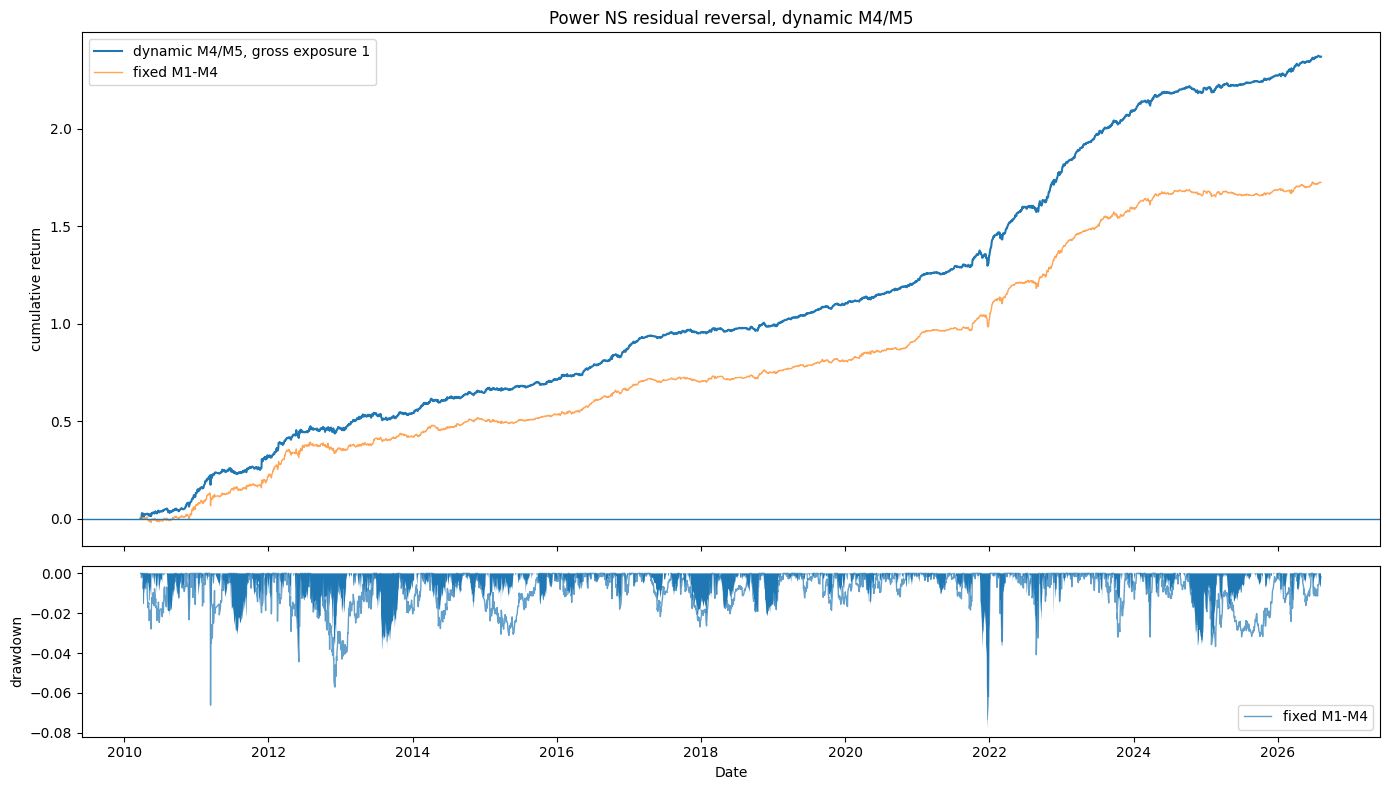

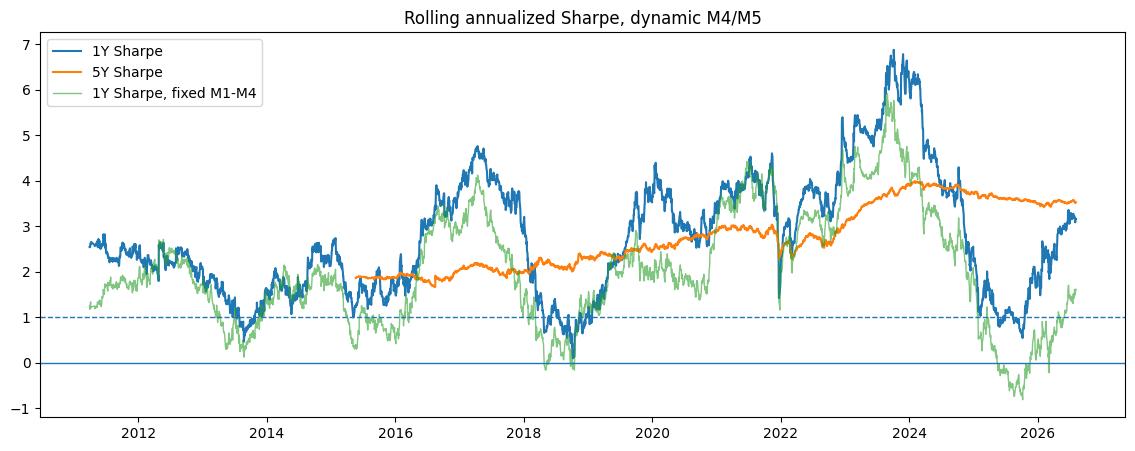

,1Y Sharpe,5Y Sharpe
count,3765.000,2807.000
mean,2.787,2.782
std,1.350,0.690
min,0.098,1.665
25%,1.705,2.136
50%,2.577,2.709
75%,3.731,3.530
max,6.880,3.992


share of 1Y windows below 0 : 0.000
share of 1Y windows below 1 : 0.068
share of 1Y windows below the M1-M4 baseline : 0.078


In [59]:
# ============================================================
# 7.6b PORTFOLIO RESULTS, WEALTH CURVE, ROLLING SHARPE
#      UNCONSTRAINED DYNAMIC M4/M5
# ============================================================

dynamic_portfolio = uncon_book["gross"].dropna()

display(performance_stats(dynamic_portfolio).to_frame("Dynamic M4/M5").round(4))

assert dynamic_portfolio.notna().sum() >= \
    uncon_book["market_gross"].notna().sum().max(), \
    "portfolio N below the largest market N -- stale panel"

# Additive P&L on fixed notional, same as the M1-M4 baseline: the legs are a
# spread with gross exposure 1, so returns are on notional and compounding
# would imply a reinvestment that does not happen.
cum_dyn = dynamic_portfolio.cumsum()
drawdown_dyn = drawdown(dynamic_portfolio)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                       gridspec_kw={"height_ratios": [3, 1]})

ax[0].plot(cum_dyn.index, cum_dyn, label="dynamic M4/M5, gross exposure 1")
ax[0].plot(
    residual_portfolio.cumsum().index,
    residual_portfolio.cumsum(),
    linewidth=1,
    alpha=0.7,
    label="fixed M1-M4",
)
ax[0].axhline(0, linewidth=1)
ax[0].set_ylabel("cumulative return")
ax[0].set_title("Power NS residual reversal, dynamic M4/M5")
ax[0].legend()

ax[1].fill_between(drawdown_dyn.index, drawdown_dyn, 0)
ax[1].plot(drawdown_path.index, drawdown_path, linewidth=1, alpha=0.7,
           label="fixed M1-M4")
ax[1].set_ylabel("drawdown")
ax[1].set_xlabel("Date")
ax[1].legend()

plt.tight_layout()
plt.show()

roll_dyn = pd.DataFrame({
    "1Y Sharpe": sharpe(dynamic_portfolio, window=1 * TRADING_DAYS,
                        min_periods=int(0.95 * TRADING_DAYS)),
    "5Y Sharpe": sharpe(dynamic_portfolio, window=5 * TRADING_DAYS,
                        min_periods=int(0.95 * 5 * TRADING_DAYS)),
})

plt.figure(figsize=(14, 5))
for c in roll_dyn.columns:
    plt.plot(roll_dyn.index, roll_dyn[c], label=c)
plt.plot(roll.index, roll["1Y Sharpe"], linewidth=1, alpha=0.6,
         label="1Y Sharpe, fixed M1-M4")
plt.axhline(0, linewidth=1)
plt.axhline(1, linestyle="--", linewidth=1)
plt.title("Rolling annualized Sharpe, dynamic M4/M5")
plt.legend()
plt.show()

display(roll_dyn.describe().round(3))

print(f"share of 1Y windows below 0 : {(roll_dyn['1Y Sharpe'] < 0).mean():.3f}")
print(f"share of 1Y windows below 1 : {(roll_dyn['1Y Sharpe'] < 1).mean():.3f}")
print(f"share of 1Y windows below the M1-M4 baseline : "
      f"{(roll_dyn['1Y Sharpe'] < roll['1Y Sharpe'].reindex(roll_dyn.index)).mean():.3f}")

# 13. Portfolio construction: risk model and market sizing

Sections 1-12 define the **Dynamic M4/M5 residual-reversal strategy**. This section determines how the market-level strategy sleeves are combined.

The production rule is chosen **ex ante** as **equal risk contribution (risk parity)** using a causal, shrunk EWMA covariance matrix. We deliberately do **not** estimate market-specific expected returns for production sizing: the common cross-market history is limited, while Section 13.5 directly tests whether historical Sharpe dispersion is reliable enough to justify return tilts.

Equal weight, equal-Sharpe and historical/expanding-Sharpe allocations remain in the notebook as **benchmarks and robustness checks only**. They are not used to select the production rule from a short validation Sharpe contest.

The covariance is estimated on the **traded per-market return**, not on the sign-anchored asset. The anchor is only an orientation convention: the traded book and the asset variances are invariant to it, but the asset correlations are not, so an anchored-asset covariance is not identified. 13.1 and 13.2 remain as the decomposition into direction and shape, and 13.9 shows the same matrix under two anchors to document why they are no longer a risk-model input.

The risk model uses only information available before the position date, applies covariance shrinkage and PSD projection, and lags the resulting market weights. There is **no per-market concentration cap**. A hard cap was tested and removed: it changed performance by less than 0.01 Sharpe in every window, and because a fixed cap is infeasible whenever `1/n_live` exceeds it, it silently collapsed the portfolio to equal weight on the low-breadth part of the sample and discarded the covariance matrix there. Concentration is now monitored ex post in 13.9 rather than imposed by a constraint that cannot bind where it is needed and cannot be satisfied where it binds.

In [60]:
# ============================================================
# CHAPTER 13 INPUTS: DYNAMIC M4/M5, PASSED EXPLICITLY
# ============================================================
# Chapter 12 has already built:
#   - uncon_weights : rank-level Dynamic M4/M5 strategy weights
#   - uncon_depth   : selected depth panel (4 or 5)
#   - uncon_book    : exact specific-contract P&L for that strategy
#
# Chapter 13 was originally written against the canonical fixed M1-M4 names and
# was fed by rebinding those module-level names to their Dynamic M4/M5
# equivalents, restoring them only if this cell happened to be executed twice.
# A clean linear run therefore left `resid_base_trade` pointing at `uncon_book`
# for the rest of the notebook, and Section 15.3 silently compared a
# Dynamic M4/M5 book against a fixed-depth one.
#
# No global is rebound now. Chapter 13 reads CH13_* inputs and calls
# ch13_portfolio(); the canonical fixed M1-M4 names keep their Chapter 7
# meaning everywhere in the notebook, whatever order cells are executed in.
# ============================================================

assert DYNAMIC_MIN_DEPTH == 4
assert DYNAMIC_MAX_DEPTH == 5
assert set(pd.unique(uncon_depth.stack().dropna())).issubset({4.0, 5.0})
assert all(k in uncon_weights for k in range(1, DYNAMIC_MAX_DEPTH + 1))

CH13_WEIGHTS = uncon_weights          # rank -> DataFrame of notional weights
CH13_DEPTH = uncon_depth              # selected depth panel, 4 or 5
CH13_MAX_RANK = DYNAMIC_MAX_DEPTH     # deepest rank Chapter 13 may touch
CH13_BASE_BOOK = uncon_book           # the strategy this chapter sizes


def ch13_portfolio(
    weights_by_rank,
    lag=LAG_BASE,
    cost_bps=0.0,
    coverage_floor=COVERAGE_FLOOR,
    ffill_limit=None,
    roll_out_buffer=ROLL_OUT_BUFFER,
):
    """
    Variable-depth contract execution for Chapter 13.

    A thin, explicitly named wrapper over run_contract_positions. It takes the
    depth panel as a bound input rather than reaching for a global that some
    other chapter may have redefined, and it does not shadow
    run_residual_portfolio.
    """
    return run_contract_positions(
        weights_by_rank,
        prices,
        tickers,
        price_universe,
        max_rank=CH13_MAX_RANK,
        depth_panel=CH13_DEPTH,
        min_depth=DYNAMIC_MIN_DEPTH,
        lag=lag,
        cost_bps=cost_bps,
        coverage_floor=coverage_floor,
        ffill_limit=ffill_limit,
        roll_out_buffer=roll_out_buffer,
        market_aggregation="equal_available",
    )


# The canonical names must still mean what Chapter 7 built.
assert MAX_RANK == TRADE_MAX_RANK
assert set(residual_weights_rev) == set(range(1, TRADE_MAX_RANK + 1))
assert resid_base_trade is not uncon_book

_m5_share = CH13_DEPTH.eq(5).sum().sum() / CH13_DEPTH.notna().sum().sum()
print("=" * 65)
print("CHAPTER 13 INPUT")
print("=" * 65)
print("Strategy       : Dynamic M4/M5")
print("Minimum depth  : M4")
print(f"Maximum depth  : M{CH13_MAX_RANK}")
print(f"M5 usage       : {_m5_share:.1%} of eligible market-days")
print("Risk model     : causal shrunk EWMA covariance")
print("Production     : ex-ante risk parity / equal risk contribution")
print("Globals        : none rebound; canonical M1-M4 names untouched")
print("=" * 65)


CHAPTER 13 INPUT
Strategy       : Dynamic M4/M5
Minimum depth  : M4
Maximum depth  : M5
M5 usage       : 76.7% of eligible market-days
Risk model     : causal shrunk EWMA covariance
Production     : ex-ante risk parity / equal risk contribution
Globals        : none rebound; canonical M1-M4 names untouched


In [61]:
# ============================================================
# 13.1 SIGN-ANCHORED DYNAMIC M4/M5 ASSET AND SIGN (RISK-MODEL ANCHOR)
# ============================================================
#
# M1-M4 has a one-dimensional NS null space; M1-M5 has a two-dimensional null
# space. The Dynamic M4/M5 strategy therefore does NOT have one fixed butterfly
# shape. Here we remove only the arbitrary overall orientation; the remaining
# sign-anchored shape is allowed to vary through time and, on M5 days, within
# the two-dimensional null space.
#
# ANCHOR SPECIFICATION. The orientation was previously taken from the sign of a
# single leg (rank 3). That leg is not reliably the dominant one: it carries the
# largest absolute loading on only about a third of observations, and its
# normalised magnitude |w_3| / ||w|| falls below 0.10 on roughly one day in ten.
# On those days the anchor is the sign of a near-zero number, so the asset flips
# orientation on noise, which inflates its estimated volatility and corrupts the
# correlations the sizing rule consumes.
#
# The anchor is therefore the sign of the projection onto a fixed reference
# shape, which is well conditioned unless the whole shape is near-orthogonal to
# the reference rather than merely small in one leg. The reference is the median
# shape over the TRAIN window only, per market, so no test-window information
# enters. The reference is a pure orientation convention: it cannot change the
# traded strategy, and the identity check in 13.2 enforces exactly that.
# ============================================================

SIGN_ANCHOR_RANK = 3          # orientation convention only: reference points -ve here
ANCHOR_COS_FLOOR = 0.10       # diagnostic threshold, not a filter

fixed_shape_weights = {
    k: pd.DataFrame(np.nan, index=prices.index, columns=price_universe, dtype=float)
    for k in range(1, CH13_MAX_RANK + 1)
}
residual_sign = pd.DataFrame(
    np.nan, index=prices.index, columns=price_universe, dtype=float
)
anchor_cosine = pd.DataFrame(
    np.nan, index=prices.index, columns=price_universe, dtype=float
)
legacy_sign = pd.DataFrame(
    np.nan, index=prices.index, columns=price_universe, dtype=float
)
reference_shapes = {}

for market in price_universe:

    w = pd.concat(
        [CH13_WEIGHTS[k][market].rename(k) for k in range(1, CH13_MAX_RANK + 1)],
        axis=1,
    ).reindex(prices.index)

    # Causal reference shape: TRAIN median, unit norm, oriented so that the
    # anchored shape keeps the previous sign convention on rank 3.
    ref = w.loc[:TRAIN_END].median()
    ref_norm = float(np.sqrt((ref ** 2).sum()))
    if not np.isfinite(ref_norm) or ref_norm <= 0:
        raise ValueError(f"degenerate reference shape for {market}")
    ref = ref / ref_norm
    if ref[SIGN_ANCHOR_RANK] > 0:
        ref = -ref
    reference_shapes[market] = ref

    # Projection and cosine on the legs actually present that day, so M4 days
    # are not penalised for the missing rank-5 component of the reference.
    present = w.notna()
    projection = (w * ref).sum(axis=1, min_count=1)
    ref_live_norm = np.sqrt((present * (ref ** 2)).sum(axis=1))
    w_norm = np.sqrt((w ** 2).sum(axis=1, min_count=1))
    anchor_cosine[market] = (
        projection / (ref_live_norm * w_norm).replace(0.0, np.nan)
    ).abs()

    s = np.sign(projection).replace(0, np.nan)

    u = w.div(s, axis=0)
    for k in range(1, CH13_MAX_RANK + 1):
        fixed_shape_weights[k][market] = u[k]

    residual_sign[market] = s
    legacy_sign[market] = np.sign(-w[SIGN_ANCHOR_RANK]).replace(0, np.nan)

shape_table = pd.concat(
    [pd.concat([fixed_shape_weights[k][m].rename(k) for k in range(1, CH13_MAX_RANK + 1)],
               axis=1).dropna()
     for m in price_universe]
).describe(percentiles=[0.05, 0.5, 0.95]).T

print("SIGN-ANCHORED NOTIONAL SHAPE (price-consistent; may drift with price levels)")
display(shape_table[["mean", "std", "5%", "50%", "95%"]].round(4))


def _flip_rate(sign_panel):
    """Flips per observed day, counting only days where both ends are observed."""
    prev = sign_panel.shift(1)
    flip = ((np.sign(sign_panel) != np.sign(prev))
            & sign_panel.notna() & prev.notna())
    return flip.sum().sum() / sign_panel.notna().sum().sum()


# ------------------------------------------------------------
# ANCHOR CONDITIONING: PROJECTION ANCHOR vs THE OLD SINGLE-LEG ANCHOR
# ------------------------------------------------------------
_w_all = pd.concat(
    [pd.concat([CH13_WEIGHTS[k][m].rename(k) for k in range(1, CH13_MAX_RANK + 1)],
               axis=1).dropna()
     for m in price_universe]
)
_leg_ratio = _w_all[SIGN_ANCHOR_RANK].abs() / np.sqrt((_w_all ** 2).sum(axis=1))
_cos = anchor_cosine.stack().dropna()

print("\nANCHOR CONDITIONING (1.0 = perfectly determined, 0.0 = arbitrary sign)")
display(pd.DataFrame({
    "single leg |w3|/||w||": [_leg_ratio.quantile(0.01), _leg_ratio.quantile(0.05),
                              _leg_ratio.median(),
                              float((_leg_ratio < ANCHOR_COS_FLOOR).mean())],
    "projection |cos|":      [_cos.quantile(0.01), _cos.quantile(0.05),
                              _cos.median(),
                              float((_cos < ANCHOR_COS_FLOOR).mean())],
}, index=["p01", "p05", "median", f"share < {ANCHOR_COS_FLOOR:.2f}"]).round(4))

print(f"\nsign flips per observed day, projection anchor : {_flip_rate(residual_sign):.4f}")
print(f"sign flips per observed day, old single leg    : {_flip_rate(legacy_sign):.4f}")
_agree = ((np.sign(residual_sign) == np.sign(legacy_sign))
          & residual_sign.notna() & legacy_sign.notna()).sum().sum()
_both = (residual_sign.notna() & legacy_sign.notna()).sum().sum()
print(f"orientation agreement with the old anchor      : {_agree / _both:.4f}")

print("\nREFERENCE SHAPES (TRAIN median, unit norm)")
display(pd.DataFrame(reference_shapes).T.round(3))


SIGN-ANCHORED NOTIONAL SHAPE (price-consistent; may drift with price levels)


,mean,std,5%,50%,95%
1,-0.0002,0.0458,-0.0651,-0.0007,0.0647
2,0.0135,0.2216,-0.3259,0.0206,0.3238
3,-0.0739,0.2850,-0.4469,-0.1124,0.4249
4,0.1236,0.3071,-0.4510,0.2209,0.4785
5,-0.0634,0.2183,-0.3320,-0.1161,0.3018



ANCHOR CONDITIONING (1.0 = perfectly determined, 0.0 = arbitrary sign)


,single leg |w3|/||w||,projection |cos|
p01,0.0094,0.0166
p05,0.0488,0.0858
median,0.5039,0.7015
share < 0.10,0.0995,0.0580



sign flips per observed day, projection anchor : 0.0857
sign flips per observed day, old single leg    : 0.0863
orientation agreement with the old anchor      : 0.6768

REFERENCE SHAPES (TRAIN median, unit norm)


,1,2,3,4,5
ZUB,-0.077,0.435,-0.813,0.381,NaN
ITP,0.080,-0.342,-0.151,-0.870,0.311
DET,0.090,-0.190,-0.177,-0.009,-0.961
FAC,-0.016,0.160,-0.226,0.683,-0.676
DFP,-0.009,0.188,-0.371,0.821,-0.391
SXD,-0.074,0.450,-0.819,0.348,NaN
UTD,0.098,-0.218,-0.215,0.213,-0.923
MSP,-0.109,0.595,-0.596,0.508,-0.144
PHB,0.045,0.042,-0.216,0.530,-0.818
PCB,-0.090,0.481,-0.445,-0.335,0.671


In [62]:
# ============================================================
# 13.2 ASSET RETURNS: SIGN-ANCHORED DYNAMIC M4/M5 RESIDUAL ASSET
# ============================================================
#
# Running the same engine on the sign-anchored, price-consistent notional hedge
# gives the underlying relative-value asset return with the signal direction
# removed. Any standalone performance is measured below rather than assumed.
# ============================================================

fixed_asset = ch13_portfolio(
    fixed_shape_weights,
    lag=LAG_BASE,
    cost_bps=0.0,
)

asset_returns = fixed_asset["market_gross"]
asset_turnover = fixed_asset["market_turnover"]

print("SIGN-ANCHORED DYNAMIC M4/M5 RESIDUAL ASSET (no view applied)")
display(
    pd.DataFrame({m: performance_stats(asset_returns[m].dropna())
                  for m in price_universe}).T[
        ["N", "Mean", "Volatility", "Sharpe ratio"]
    ].round(4)
)

# Sanity: sign x fixed asset must reproduce the strategy exactly. This is what
# makes the anchor a convention rather than a modelling choice: any anchor that
# passes this check leaves the traded book untouched and changes only the
# decomposition the risk model is estimated on.
_chk = (residual_sign.shift(LAG_BASE) * asset_returns)
_ref = CH13_BASE_BOOK["market_gross"]
_c = [round(float(_chk[m].corr(_ref[m])), 4) for m in price_universe]
print(f"\ncorr(sign x fixed asset, strategy) per market: {_c}")
assert min(_c) > 0.999, "decomposition does not reproduce the strategy"


SIGN-ANCHORED DYNAMIC M4/M5 RESIDUAL ASSET (no view applied)


,N,Mean,Volatility,Sharpe ratio
ZUB,1733.0,0.0454,0.1102,0.4119
ITP,2870.0,-0.0198,0.0786,-0.2524
DET,2111.0,0.0411,0.0768,0.5354
FAC,3354.0,0.0331,0.1257,0.2636
DFP,2576.0,0.0118,0.1035,0.1137
SXD,1798.0,-0.0107,0.1307,-0.0819
UTD,2075.0,0.0636,0.0967,0.6575
MSP,2535.0,-0.0532,0.1029,-0.5173
PHB,3948.0,0.0389,0.0924,0.4214
PCB,3042.0,-0.0317,0.0771,-0.4108



corr(sign x fixed asset, strategy) per market: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


In [63]:
# ============================================================
# 13.3 RISK MODEL
# ============================================================
# Causal EWMA covariance with missing-data pairwise updates. Pairwise updating
# can break positive semidefiniteness, so each updated matrix and each shrunk
# matrix is explicitly projected back to the PSD cone. Pair-observation counts
# are carried alongside the covariance and used as a causal warm-up guard.
#
# COVARIANCE INPUT. The covariance is estimated on the TRADED per-market return,
# sign times anchored asset, not on the anchored asset itself. The anchor is an
# orientation convention: it flips the sign of residual_sign and of the anchored
# asset on the same days, so the traded book is invariant to it, and so are the
# asset variances. The asset CORRELATIONS are not, because cov(s_i a_i, s_j a_j)
# depends on how the two conventions co-move. Estimating on the anchored asset
# therefore fed the sizing rule an off-diagonal block that was a function of an
# arbitrary choice; 13.9 shows the same matrix under two anchors and the two
# disagree on sign for the largest pairs. The traded return is invariant by
# construction, is what the book actually holds, and is the identified object.
# 13.1 and 13.2 are retained as the decomposition into direction and shape, and
# are now presentational rather than risk-model inputs.
# ============================================================

COV_HALFLIFE = 60
COV_SHRINKAGE = 0.40
COV_MIN_OBS = 250
COV_MIN_PAIR_OBS = 60
COV_EXTRA_LAG = 1
COV_RIDGE = 1e-8


def project_psd(S, floor=COV_RIDGE):
    """Symmetrize and clip eigenvalues to obtain a finite PSD matrix."""
    A = np.asarray(S, dtype=float)
    A = np.where(np.isfinite(A), A, 0.0)
    A = 0.5 * (A + A.T)
    vals, vecs = np.linalg.eigh(A)
    vals = np.maximum(vals, float(floor))
    out = (vecs * vals) @ vecs.T
    return 0.5 * (out + out.T)


def ewma_covariance(returns, halflife):
    """
    Causal normalized EWMA covariance plus pair counts; entry i uses data through i-1.

    Numerator and weight matrices are updated separately, so there is no arbitrary
    identity-matrix prior contaminating the burn-in boundary. Pairwise missingness
    can still break PSD, therefore every reported matrix is projected to the PSD cone.
    """
    lam = 0.5 ** (1.0 / halflife)
    n, k = returns.shape
    num = np.zeros((k, k), dtype=float)
    den = np.zeros((k, k), dtype=float)
    pair_counts = np.zeros((k, k), dtype=int)
    out = np.full((n, k, k), np.nan)
    counts = np.zeros((n, k, k), dtype=int)
    X = returns.values

    for i in range(n):
        current = np.divide(num, den, out=np.zeros_like(num), where=den > 1e-12)
        out[i] = project_psd(current)
        counts[i] = pair_counts.copy()

        x = X[i]
        mask = np.isfinite(x)
        pair = np.outer(mask, mask)
        if pair.any():
            xf = np.where(mask, x, 0.0)
            outer = np.outer(xf, xf)
            num = lam * num + (1.0 - lam) * np.where(pair, outer, 0.0)
            den = lam * den + (1.0 - lam) * pair.astype(float)
            pair_counts += pair.astype(int)

    return out, counts


def shrink_covariance(S, delta=COV_SHRINKAGE):
    """Shrink correlations toward their cross-sectional average, then enforce PSD."""
    S = project_psd(S)
    d = np.sqrt(np.clip(np.diag(S), 1e-12, None))
    corr = S / np.outer(d, d); np.fill_diagonal(corr, 1.0)
    off = corr[np.triu_indices(len(corr), 1)]
    target_rho = np.nanmean(off) if np.isfinite(off).any() else 0.0
    target = np.full_like(corr, target_rho); np.fill_diagonal(target, 1.0)
    blended = (1 - delta) * corr + delta * target
    return project_psd(blended * np.outer(d, d), floor=COV_RIDGE)


def covariance_live_set(i):
    """Markets with enough own history and enough pair overlap, using t-1 info only."""
    live = [j for j, m in enumerate(price_universe)
            if np.isfinite(covariance_input[m].iloc[i]) and covariance_pair_counts[i, j, j] >= COV_MIN_OBS]
    while len(live) >= 2:
        pc = covariance_pair_counts[i][np.ix_(live, live)]
        offmask = ~np.eye(len(live), dtype=bool)
        if not offmask.any() or np.nanmin(pc[offmask]) >= COV_MIN_PAIR_OBS:
            break
        # Remove the market with the weakest overlap with the rest.
        mins = []
        for a in range(len(live)):
            others = np.delete(pc[a], a)
            mins.append(np.min(others) if len(others) else np.inf)
        live.pop(int(np.argmin(mins)))
    return live

_COV_CACHE = {}

def live_shrunk_covariance(i):
    """Cache the identical live-set + shrunk covariance used by every sizing rule."""
    if i not in _COV_CACHE:
        live = covariance_live_set(i)
        S = (
            shrink_covariance(covariance_path[i][np.ix_(live, live)])
            if len(live) >= 2 else None
        )
        _COV_CACHE[i] = (live, S)
    return _COV_CACHE[i]


RISK_INDEX = asset_returns.index

# The traded per-market return. Defined here because it is the covariance input;
# 13.4 consumes the same object rather than rebuilding it.
strategy_market_returns = (
    residual_sign.reindex(RISK_INDEX).shift(LAG_BASE) * asset_returns
)
covariance_input = strategy_market_returns

covariance_path, covariance_pair_counts = ewma_covariance(covariance_input, COV_HALFLIFE)
# covariance_live_set references covariance_pair_counts and is called only after
# both arrays above exist; clear any stale cache after rebuilding the path.
_COV_CACHE.clear()
_S = shrink_covariance(covariance_path[-1])
print(f"condition number of the shrunk covariance (last obs): {np.linalg.cond(_S):.1f}")
print(f"minimum eigenvalue (last obs): {np.linalg.eigvalsh(_S).min():.3e}")
print("\nfull-sample correlation of the traded per-market returns:")
display(covariance_input.corr().round(2))
_c = covariance_input.corr().values[np.triu_indices(len(price_universe), 1)]
_ev = np.linalg.eigvalsh(covariance_input.corr().fillna(0).values)[::-1]
print(f"average pairwise correlation : {np.nanmean(_c):.3f}")
print(f"first PC explains            : {_ev[0] / _ev.sum():.1%}")
print(f"effective independent bets   : {len(price_universe) / (1 + (len(price_universe)-1) * max(np.nanmean(_c), 0)):.2f}")


condition number of the shrunk covariance (last obs): 38.4
minimum eigenvalue (last obs): 3.462e-06

full-sample correlation of the traded per-market returns:


,ZUB,ITP,DET,FAC,DFP,SXD,UTD,MSP,PHB,PCB
ZUB,1.00,0.01,0.05,0.12,0.13,0.06,0.05,-0.00,0.01,0.05
ITP,0.01,1.00,0.15,0.17,0.08,0.04,0.12,0.08,0.10,0.13
DET,0.05,0.15,1.00,0.26,0.19,0.21,0.73,0.12,0.57,0.88
FAC,0.12,0.17,0.26,1.00,0.09,0.10,0.16,0.11,0.10,0.17
DFP,0.13,0.08,0.19,0.09,1.00,0.10,0.15,0.06,0.12,0.17
SXD,0.06,0.04,0.21,0.10,0.10,1.00,0.17,0.03,0.13,0.20
UTD,0.05,0.12,0.73,0.16,0.15,0.17,1.00,0.07,0.47,0.68
MSP,-0.00,0.08,0.12,0.11,0.06,0.03,0.07,1.00,0.08,0.10
PHB,0.01,0.10,0.57,0.10,0.12,0.13,0.47,0.08,1.00,0.45
PCB,0.05,0.13,0.88,0.17,0.17,0.20,0.68,0.10,0.45,1.00


average pairwise correlation : 0.179
first PC explains            : 31.8%
effective independent bets   : 3.83


In [64]:
# ============================================================
# 13.4 FIVE SIZING VARIANTS: RISK PARITY + CAUSAL ROBUSTNESS BENCHMARKS
# ============================================================

# The split was fixed in 7.0b from the trading calendar, BEFORE LAMBDA_TRADE
# was chosen, so the parameter cannot influence its own evaluation window.
# The split is frozen in 7.0b. RISK_INDEX must contain both boundary dates and
# they must be adjacent; it is no longer re-derived from sample length, which
# would drift as data is appended.
TRAIN_END_IDX = RISK_INDEX.get_loc(TEST_START)
assert RISK_INDEX[TRAIN_END_IDX - 1] == TRAIN_END, "train boundary moved"
assert RISK_INDEX[TRAIN_END_IDX] == TEST_START, "test boundary moved" 

# NOTE ON IN-SAMPLE USE. train_sharpe is estimated on the train window and
# then applied across the whole sample, so it is in-sample for train by
# construction. It is retained ONLY as a diagnostic benchmark. Production is
# risk parity and therefore does not use realised-return estimates.
train_sharpe = sharpe(strategy_market_returns.loc[:TRAIN_END], min_obs=60)

expanding_sharpe = sharpe(
    strategy_market_returns,
    window="expanding",
    min_periods=COV_MIN_OBS,
).shift(1)


# Long-only is the only weight constraint. Negative raw weights from the
# Sigma^-1 variants are truncated to zero, which is itself a binding constraint,
# so its frequency is counted and reported in 13.9 rather than left silent.
_clip_events = {}


def normalize_market_weights(k, label=None):
    """Truncate to long-only and normalize to sum 1. No concentration cap."""
    k = np.asarray(k, dtype=float)
    if label is not None and np.isfinite(k).all() and (k < 0).any():
        _clip_events[label] = _clip_events.get(label, 0) + 1
    k = np.clip(k, 0.0, None)
    if not np.isfinite(k).all() or k.sum() <= 0:
        return None
    return k / k.sum()


SIZING_VARIANTS = {
    "risk parity":               ("risk_parity", 0.0),
    "equal weight":              ("equal_weight", 0.0),
    "equal Sharpe":              ("equal_sharpe", 0.0),
    "expanding Sharpe":          ("expanding_sharpe", 0.0),
    "expanding, 50% shrunk":     ("expanding_sharpe", 0.5),
}


RP_TOL = 1e-3
_rp_not_converged = 0


def solve_risk_parity(S, n_iter=200, tol=RP_TOL):
    """
    Long-only equal-risk-contribution weights for one live covariance matrix.

    Iteration stops on an explicit risk-contribution dispersion tolerance rather
    than a fixed iteration count, and non-convergence is counted instead of being
    returned silently as if it were a solution.
    """
    global _rp_not_converged
    S = np.asarray(S, dtype=float)
    k = 1.0 / np.sqrt(np.clip(np.diag(S), 1e-16, None))

    for _ in range(n_iter):
        rc = k * (S @ k)
        if not np.isfinite(rc).all() or rc.sum() <= 0:
            return None
        share = rc / rc.sum()
        if share.max() - share.min() < tol:
            break
        k = k * (rc.mean() / np.maximum(rc, 1e-16)) ** 0.5
        if not np.isfinite(k).all() or np.abs(k).sum() <= 0:
            return None
        k = k / np.abs(k).sum()
    else:
        _rp_not_converged += 1

    return normalize_market_weights(k)


def build_all_sizing_weights():
    """
    Build all sizing variants in ONE pass over dates using NumPy storage.

    The live set and shrunk covariance are identical for every variant. NumPy
    arrays also avoid tens of thousands of slow scalar pandas assignments.
    """
    n_dates = len(RISK_INDEX)
    n_mkts = len(price_universe)
    Karr = {
        label: np.full((n_dates, n_mkts), np.nan, dtype=float)
        for label in SIZING_VARIANTS
    }

    exp_s_all = expanding_sharpe.reindex(columns=price_universe).to_numpy(float)

    for i in range(n_dates):
        if i < COV_MIN_OBS:
            continue

        live, S = live_shrunk_covariance(i)
        if len(live) < 2 or S is None:
            continue
        live = np.asarray(live, dtype=int)

        sigma = np.sqrt(np.diag(S))
        exp_s = exp_s_all[i, live]

        candidates = {"equal weight": np.ones(len(live))}

        rp = solve_risk_parity(S)
        if rp is not None:
            candidates["risk parity"] = rp

        rhs_labels = ["equal Sharpe"]
        rhs = [sigma]

        if np.isfinite(exp_s).all():
            rhs_labels += ["expanding Sharpe", "expanding, 50% shrunk"]
            rhs.append(np.clip(exp_s, 0, None) * sigma)
            shr = 0.5 * exp_s + 0.5 * np.nanmean(exp_s)
            rhs.append(np.clip(shr, 0, None) * sigma)

        # One factorization of S for every right-hand side.
        solved = np.linalg.solve(S, np.column_stack(rhs))
        for j, label in enumerate(rhs_labels):
            candidates[label] = solved[:, j]

        for label, raw in candidates.items():
            k = raw if label == "risk parity" else normalize_market_weights(raw, label)
            if k is not None:
                Karr[label][i, live] = k * len(live)

    out = {}
    for label, arr in Karr.items():
        df = pd.DataFrame(arr, index=RISK_INDEX, columns=price_universe)
        out[label] = df.shift(COV_EXTRA_LAG)
    return out


_clip_events.clear()
_rp_not_converged = 0
sizing_weights = build_all_sizing_weights()
print(f"risk-parity solves that hit the iteration limit : {_rp_not_converged}")
print(f"days with a negative raw weight truncated       : {dict(_clip_events)}")


def sized_portfolio(K):
    """
    Full specific-contract execution for every sizing rule.

    The market scalar is folded into the Dynamic M4/M5 contract weights before
    the canonical lag, roll handling, coverage test, P&L and turnover are
    computed. This keeps every portfolio comparison on the same exact
    execution path; no turnover or P&L is reconstructed heuristically.
    """
    final_weights = {
        k: CH13_WEIGHTS[k].reindex(K.index) * K
        for k in range(1, CH13_MAX_RANK + 1)
    }

    res = ch13_portfolio(
        final_weights,
        lag=LAG_BASE,
        cost_bps=0.0,
    )

    contribution = res["market_gross"]
    n_live = res["market_active"].sum(axis=1).replace(0, np.nan)

    return {
        "contribution": contribution,
        "n_live": n_live,
        "gross": res["gross"],
        "turnover": res["turnover"],
        "market_turnover": res["market_turnover"],
        "market_active": res["market_active"],
    }


sizing_results = {
    label: sized_portfolio(K)
    for label, K in sizing_weights.items()
}

rows = []
for label, res in sizing_results.items():
    row = {"variant": label}
    for period, sl in [("train", PERIODS["TRAIN"]),
                       ("test", PERIODS["TEST"])]:
        g = res["gross"].loc[sl]
        t = res["turnover"].loc[sl]
        s_ = performance_stats(g.dropna())
        row[f"{period} Sharpe"] = s_["Sharpe ratio"]
        if period == "test":
            to = t.mean() * TRADING_DAYS
            row["test net@2"] = performance_stats(
                (g - 2 / 1e4 * t).dropna()
            )["Sharpe ratio"]
            row["test net@5"] = performance_stats(
                (g - 5 / 1e4 * t).dropna()
            )["Sharpe ratio"]
            row["turnover"] = to
            row["break-even bps"] = s_["Mean"] / to * 1e4
    rows.append(row)

sizing_table = pd.DataFrame(rows).set_index("variant")
display(sizing_table.round(3))


risk-parity solves that hit the iteration limit : 0
days with a negative raw weight truncated       : {'expanding Sharpe': 1831, 'expanding, 50% shrunk': 1384, 'equal Sharpe': 280}


,train Sharpe,test Sharpe,test net@2,test net@5,turnover,break-even bps
variant,,,,,,
risk parity,2.607,3.645,3.384,2.992,73.992,27.912
equal weight,2.627,3.539,3.295,2.929,72.654,29.112
equal Sharpe,2.652,3.889,3.611,3.192,80.228,27.929
expanding Sharpe,2.705,3.769,3.516,3.135,100.064,29.407
"expanding, 50% shrunk",2.724,3.981,3.710,3.300,91.283,29.004


### Why point estimates are not enough

Sizing variants can look different because of sampling noise. The tables and paired block bootstrap below therefore report the uncertainty directly. Do not select a sizing rule from a frozen number in markdown; use the outputs produced by the current run.

Turnover is always taken from the same contract-level position path that generates P&L, so signal flips, rolls, and market-weight changes are charged once rather than reconstructed from separate approximations.


In [65]:
# ============================================================
# 13.5 IS THE CROSS-MARKET SHARPE DISPERSION REAL?
# ============================================================
#
# Empirical Bayes. If the observed variance of estimated Sharpes is no larger
# than what pure estimation noise produces, there is no true dispersion to
# exploit and the optimal shrinkage is 100%.
#
# Sharpe uncertainty is estimated by circular block bootstrap, not an iid formula.
# ============================================================

n_train = pd.Series(
    {m: strategy_market_returns[m].loc[:TRAIN_END].notna().sum()
     for m in price_universe}
)
years_train = n_train / TRADING_DAYS

# Serial-dependence-aware uncertainty: circular block-bootstrap SE for each
# market's TRAIN Sharpe. This replaces the iid sqrt((1+S^2/2)/T) formula.
sharpe_se = pd.Series({
    m: block_bootstrap_sharpe_se(
        strategy_market_returns[m].loc[:TRAIN_END],
        block_length=21, n_boot=300, seed=1000 + j
    )
    for j, m in enumerate(price_universe)
})

test_sharpe = sharpe(strategy_market_returns.loc[TEST_START:], min_obs=60)

observed_var = train_sharpe.var(ddof=1)
noise_var = (sharpe_se ** 2).mean()
tau_squared = max(observed_var - noise_var, 0.0)
js_weight = tau_squared / (tau_squared + sharpe_se ** 2)

display(pd.DataFrame({
    "train Sharpe": train_sharpe,
    "years": years_train.round(1),
    "block-bootstrap SE": sharpe_se,
    "weight on own estimate": js_weight,
    "test Sharpe": test_sharpe,
}).round(3))

print(f"observed cross-sectional variance of Sharpe : {observed_var:.4f}")
print(f"variance attributable to sampling noise     : {noise_var:.4f}")
print(f"implied TRUE variance (tau^2)               : {observed_var - noise_var:+.4f}"
      f"   -> clipped to {tau_squared:.4f}")
print(f"=> James-Stein optimal shrinkage            : {1 - js_weight.mean():.0%}")

_r = train_sharpe.corr(test_sharpe)
_n = len(price_universe)
_t = _r * np.sqrt((_n - 2) / (1 - _r ** 2)) if abs(_r) < 1 else np.inf
print(f"\ncorr(train Sharpe, test Sharpe) = {_r:.3f}   t = {_t:.2f} on {_n-2} df")
print("\nThe estimated Sharpes cannot be ranked reliably. Whether tilting by")
print("them helps the portfolio is tested separately.")


,train Sharpe,years,block-bootstrap SE,weight on own estimate,test Sharpe
ZUB,1.544,1.7,0.583,0.0,1.064
ITP,1.720,6.2,0.346,0.0,2.829
DET,1.168,3.2,0.529,0.0,1.468
FAC,1.183,8.1,0.329,0.0,1.489
DFP,0.906,5.0,0.307,0.0,2.414
SXD,0.885,3.0,0.515,0.0,1.322
UTD,1.093,3.0,0.452,0.0,1.895
MSP,1.307,4.8,0.314,0.0,2.343
PHB,1.959,10.4,0.220,0.0,1.862
PCB,0.807,6.9,0.320,0.0,1.586


observed cross-sectional variance of Sharpe : 0.1441
variance attributable to sampling noise     : 0.1662
implied TRUE variance (tau^2)               : -0.0221   -> clipped to 0.0000
=> James-Stein optimal shrinkage            : 100%

corr(train Sharpe, test Sharpe) = 0.228   t = 0.66 on 8 df

The estimated Sharpes cannot be ranked reliably. Whether tilting by
them helps the portfolio is tested separately.


In [66]:
# ============================================================
# 13.6 PAIRED BLOCK BOOTSTRAP
# ============================================================
#
# Circular block bootstrap on the per-market P&L contributions, so signal and
# return travel together inside each block. The SAME block indices are applied
# to every variant, which pairs the comparison and removes the "which periods
# got drawn" component of the variance.
#
# Block length 21 days is used to preserve multi-day dependence in the resample.
# ============================================================

N_BOOTSTRAP = 1000
BLOCK_LENGTH = 21


# `circular_blocks` is defined in the core metric infrastructure above.
bootstrap_tables = {}

for period, sl in [("TEST", PERIODS["TEST"]),
                   ("TRAIN", PERIODS["TRAIN"])]:

    panels = {
        label: (res["contribution"].loc[sl].values, res["n_live"].loc[sl].values)
        for label, res in sizing_results.items()
    }
    n_obs = len(panels["equal weight"][0])
    rng = np.random.default_rng(101)

    draws = {label: [] for label in SIZING_VARIANTS}
    for _ in range(N_BOOTSTRAP):
        ix = circular_blocks(n_obs, BLOCK_LENGTH, rng)   # shared across variants
        for label, (c, nl) in panels.items():
            x = np.nansum(c[ix], axis=1) / nl[ix]
            draws[label].append(sharpe(x[np.isfinite(x)], min_obs=60))

    D = pd.DataFrame(draws)
    baseline = D["risk parity"]

    rows = []
    for label in SIZING_VARIANTS:
        diff = D[label] - baseline
        rows.append({
            "variant": label,
            "actual": performance_stats(
                sizing_results[label]["gross"].loc[sl].dropna())["Sharpe ratio"],
            "boot mean": D[label].mean(),
            "boot sd": D[label].std(),
            "5%": D[label].quantile(0.05),
            "95%": D[label].quantile(0.95),
            "vs risk parity": diff.mean(),
            "sd of diff": diff.std(),
            "P(beats risk parity)": (diff > 0).mean(),
        })

    bootstrap_tables[period] = pd.DataFrame(rows).set_index("variant")
    print(f"\n{period}  ({N_BOOTSTRAP} paired draws, block {BLOCK_LENGTH}d)")
    display(bootstrap_tables[period].round(3))

print("\nGovernance note: all bootstrap comparisons are descriptive robustness checks.")
print("Production sizing is fixed ex ante to risk parity; neither TRAIN nor TEST")
print("performance is used to choose the production combination rule.")



TEST  (1000 paired draws, block 21d)


,actual,boot mean,boot sd,5%,95%,vs risk parity,sd of diff,P(beats risk parity)
variant,,,,,,,,
risk parity,3.645,3.698,0.553,2.811,4.614,0.000,0.000,0.000
equal weight,3.539,3.589,0.549,2.725,4.514,-0.109,0.079,0.081
equal Sharpe,3.889,3.952,0.582,3.034,4.930,0.254,0.126,0.982
expanding Sharpe,3.769,3.832,0.530,3.001,4.705,0.134,0.220,0.726
"expanding, 50% shrunk",3.981,4.042,0.553,3.189,4.962,0.345,0.142,0.995



TRAIN  (1000 paired draws, block 21d)


,actual,boot mean,boot sd,5%,95%,vs risk parity,sd of diff,P(beats risk parity)
variant,,,,,,,,
risk parity,2.607,2.561,0.328,2.022,3.059,0.000,0.000,0.000
equal weight,2.627,2.578,0.340,1.989,3.114,0.018,0.066,0.599
equal Sharpe,2.652,2.606,0.329,2.059,3.105,0.045,0.031,0.936
expanding Sharpe,2.705,2.641,0.304,2.151,3.108,0.081,0.169,0.684
"expanding, 50% shrunk",2.724,2.669,0.315,2.155,3.157,0.109,0.101,0.856



Governance note: all bootstrap comparisons are descriptive robustness checks.
Production sizing is fixed ex ante to risk parity; neither TRAIN nor TEST
performance is used to choose the production combination rule.


### 13.7 Sizing governance

Production sizing is **risk parity / equal risk contribution**, fixed ex ante from the risk-management objective rather than selected by the highest realised Sharpe over a short validation window.

The motivation is deliberately asymmetric:

- the covariance matrix is used because volatility and dependence are the objects the risk model is designed to estimate;
- market-specific expected returns are **not** used in production sizing because the available common history is too limited to rank expected Sharpes reliably;
- no per-market concentration cap is imposed. A fixed cap is infeasible whenever `1/n_live` exceeds it, and the clip-and-renormalize fixed point in that case is exactly equal weight, so the cap acted as a hidden equal-weight override on low-breadth days rather than as a concentration control;
- equal weight, equal Sharpe and causal expanding-Sharpe variants remain as robustness checks. The explicitly in-sample train-Sharpe portfolio variants are removed from the sizing contest; train Sharpe is retained only as a diagnostic in Section 13.5.

Section 13.5 provides an explicit empirical check on this choice by comparing observed cross-sectional Sharpe dispersion with its sampling uncertainty. Section 13.6 then compares the resulting portfolio rules without using those comparisons for model selection.

In [67]:
# ============================================================
# 13.8 PRODUCTION SPEC: EX-ANTE RISK PARITY
# ============================================================
# Governance decision:
#   - Production uses causal equal-risk-contribution weights.
#   - No realised-return estimate is used to choose the production rule.
#   - TEST is evaluation only.
#   - A TRAIN-only late-window table is retained as a robustness diagnostic,
#     NOT as a selection mechanism.
# ============================================================

PRODUCTION_SIZING = "risk parity"

# Keep the old late-TRAIN window only as a transparent robustness diagnostic.
_train_full_dates = RISK_INDEX[
    (RISK_INDEX >= UNIVERSE_COMPLETE) & (RISK_INDEX <= TRAIN_END)
]
if len(_train_full_dates) < 120:
    raise ValueError("TRAIN FULL is too short for the robustness window")

ROBUSTNESS_START = _train_full_dates[len(_train_full_dates) // 2]
ROBUSTNESS_SLICE = slice(ROBUSTNESS_START, TRAIN_END)

_robustness_score = pd.Series({
    label: sharpe(
        sizing_results[label]["gross"].loc[ROBUSTNESS_SLICE].dropna(),
        min_obs=60,
    )
    for label in sizing_results
})

print(f"\nEx-ante PRODUCTION_SIZING: {PRODUCTION_SIZING}")

production_weights = sizing_weights[PRODUCTION_SIZING]
production = sizing_results[PRODUCTION_SIZING]

rows = []
for period in ["FULL", "TRAIN", "TEST"]:
    m = book_metrics(production, period=PERIODS[period], cost_bps=0.0)
    rows.append({
        "period": period.lower(),
        "N": m["N"],
        "Sharpe": m["Gross Sharpe"],
        "Mean": m["Net Mean"],
        "Vol": m["Net Vol"],
        "MaxDD (additive)": m["MaxDD (additive)"],
        "Turnover": m["Annual turnover"],
        "Break-even bps": m["Break-even bps"],
    })
production_summary = pd.DataFrame(rows).set_index("period")
display(production_summary.round(4))

print("Net Sharpe by assumed cost:")
for c in [0, 1, 2, 3, 5, 8, 10]:
    n = (production["gross"] - c / 1e4 * production["turnover"]).dropna()
    print(f"  {c:2d} bps : {sharpe(n):6.3f}")

print("\nAverage market weight under risk parity:")
_k = production_weights.div(production_weights.sum(axis=1), axis=0)
risk_parity_weight_summary = pd.DataFrame({
    "avg weight": _k.mean(),
    "median weight": _k.median(),
    "max weight": _k.max(),
    "vol": covariance_input.std() * np.sqrt(TRADING_DAYS),
    "avg corr": covariance_input.corr().apply(
        lambda c: (c.sum() - 1) / (len(price_universe) - 1)
    ),
    "train Sharpe": train_sharpe,
    "test Sharpe": test_sharpe,
})
display(risk_parity_weight_summary.round(3))

# Ex-post risk-contribution diagnostic on the last valid covariance date.
_last_i = next(
    i for i in range(len(RISK_INDEX) - 1, -1, -1)
    if len(live_shrunk_covariance(i)[0]) >= 2
)
_live, _S_live = live_shrunk_covariance(_last_i)
_w_last = production_weights.iloc[_last_i].iloc[_live].to_numpy(float)
_w_last = _w_last / np.nansum(_w_last)
_rc_last = _w_last * (_S_live @ _w_last)
_rc_share_last = _rc_last / np.nansum(_rc_last)

risk_contribution_last = pd.DataFrame({
    "weight": _w_last,
    "risk contribution": _rc_share_last,
}, index=[price_universe[j] for j in _live])
print(f"\nRisk contribution diagnostic at {RISK_INDEX[_last_i].date()}:")
display(risk_contribution_last.round(4))

print("\n" + "=" * 62)
print("CURRENT CONFIGURATION")
print("=" * 62)
for k, v in [
    ("signal", "reversal of signed NS null-space residual"),
    ("traded depth", "Dynamic M4/M5"),
    ("selected lambda", LAMBDA_TRADE),
    ("execution lag", LAG_BASE),
    ("roll-out buffer", ROLL_OUT_BUFFER),
    ("coverage floor", COVERAGE_FLOOR),
    ("covariance", f"EWMA halflife {COV_HALFLIFE}, shrink {COV_SHRINKAGE}"),
    ("burn-in", COV_MIN_OBS),
    ("risk-weight lag", COV_EXTRA_LAG),
    ("production sizing", PRODUCTION_SIZING),
    ("expected-return tilt", "none"),
    ("negative weights", "not applicable; long-only risk weights"),
    ("per-market cap", "none; concentration monitored in 13.9"),
]:
    print(f"  {k:24} {v}")



Ex-ante PRODUCTION_SIZING: risk parity


,N,Sharpe,Mean,Vol,MaxDD (additive),Turnover,Break-even bps
period,,,,,,,
full,3020.0,3.0946,0.1470,0.0475,-0.0650,72.3822,20.3033
train,1704.0,2.6069,0.1010,0.0387,-0.0278,71.1387,14.1915
test,1316.0,3.6450,0.2065,0.0567,-0.0650,73.9922,27.9120


Net Sharpe by assumed cost:
   0 bps :  3.095
   1 bps :  2.942
   2 bps :  2.789
   3 bps :  2.635
   5 bps :  2.328
   8 bps :  1.865
  10 bps :  1.558

Average market weight under risk parity:


,avg weight,median weight,max weight,vol,avg corr,train Sharpe,test Sharpe
ZUB,0.130,0.126,0.216,0.110,0.054,1.544,1.064
ITP,0.173,0.152,0.713,0.078,0.099,1.720,2.829
DET,0.113,0.112,0.464,0.077,0.351,1.168,1.468
FAC,0.136,0.096,0.593,0.125,0.142,1.183,1.489
DFP,0.130,0.106,0.333,0.103,0.124,0.906,2.414
SXD,0.077,0.075,0.152,0.130,0.115,0.885,1.322
UTD,0.095,0.091,0.330,0.096,0.290,1.093,1.895
MSP,0.122,0.125,0.264,0.102,0.073,1.307,2.343
PHB,0.147,0.111,0.508,0.092,0.227,1.959,1.862
PCB,0.185,0.129,0.619,0.077,0.316,0.807,1.586



Risk contribution diagnostic at 2026-08-07:


,weight,risk contribution
ZUB,0.1193,0.1024
ITP,0.1851,0.1013
DET,0.1264,0.1001
FAC,0.0390,0.0997
DFP,0.0986,0.0991
SXD,0.0841,0.0995
UTD,0.0872,0.0995
MSP,0.0675,0.1001
PHB,0.0814,0.0990
PCB,0.1114,0.0995



CURRENT CONFIGURATION
  signal                   reversal of signed NS null-space residual
  traded depth             Dynamic M4/M5
  selected lambda          1.1
  execution lag            1
  roll-out buffer          2
  coverage floor           1.0
  covariance               EWMA halflife 60, shrink 0.4
  burn-in                  250
  risk-weight lag          1
  production sizing        risk parity
  expected-return tilt     none
  negative weights         not applicable; long-only risk weights
  per-market cap           none; concentration monitored in 13.9


,Risk parity,Equal weight
N,1316.0000,1316.0000
Mean,0.2065,0.2115
Alpha daily,0.0008,0.0008
Alpha t-stat (NW),6.2758,6.1356
Alpha p-value (NW),0.0000,0.0000
NW lags,21.0000,21.0000
Volatility,0.0567,0.0598
Downside volatility,0.0421,0.0441
Sharpe ratio,3.6450,3.5386
Skewness,-0.0132,0.0241


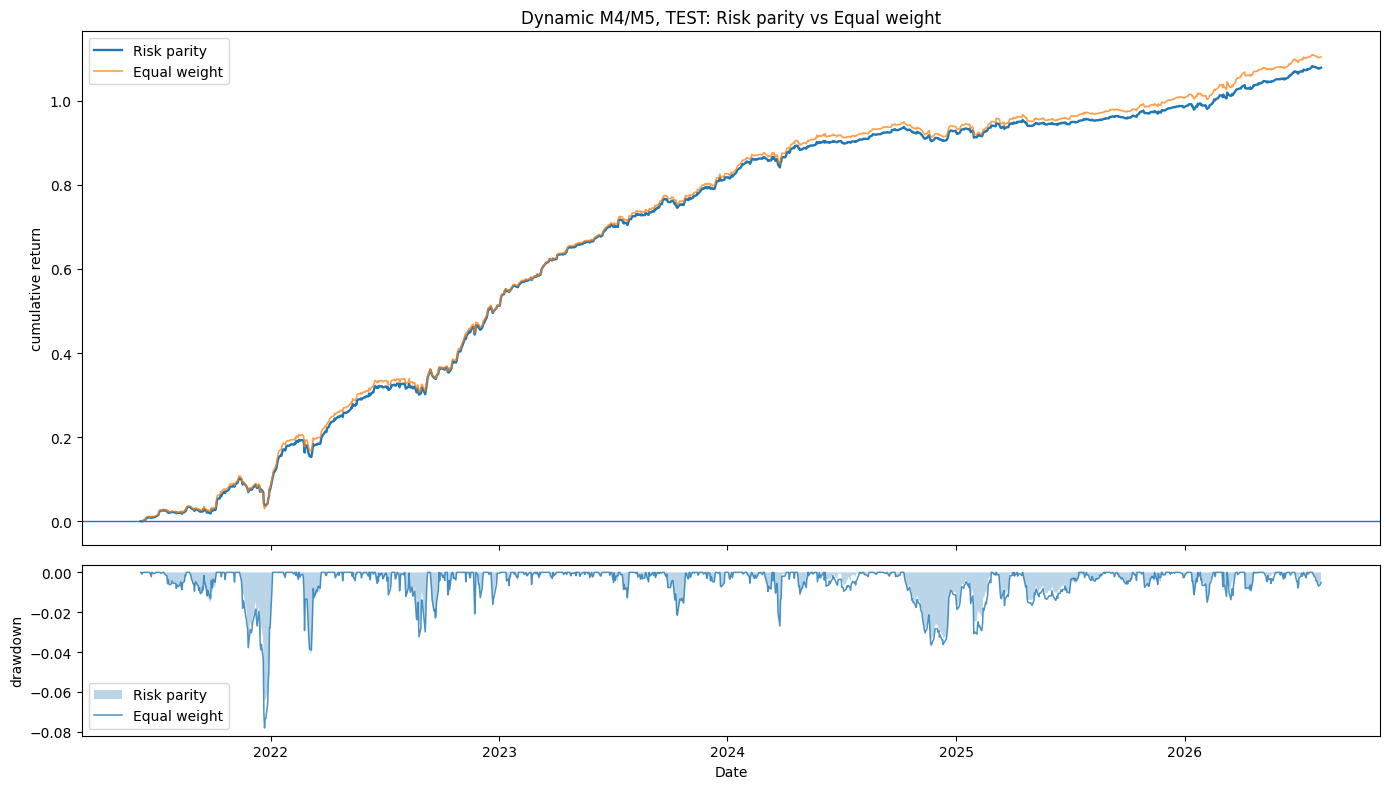

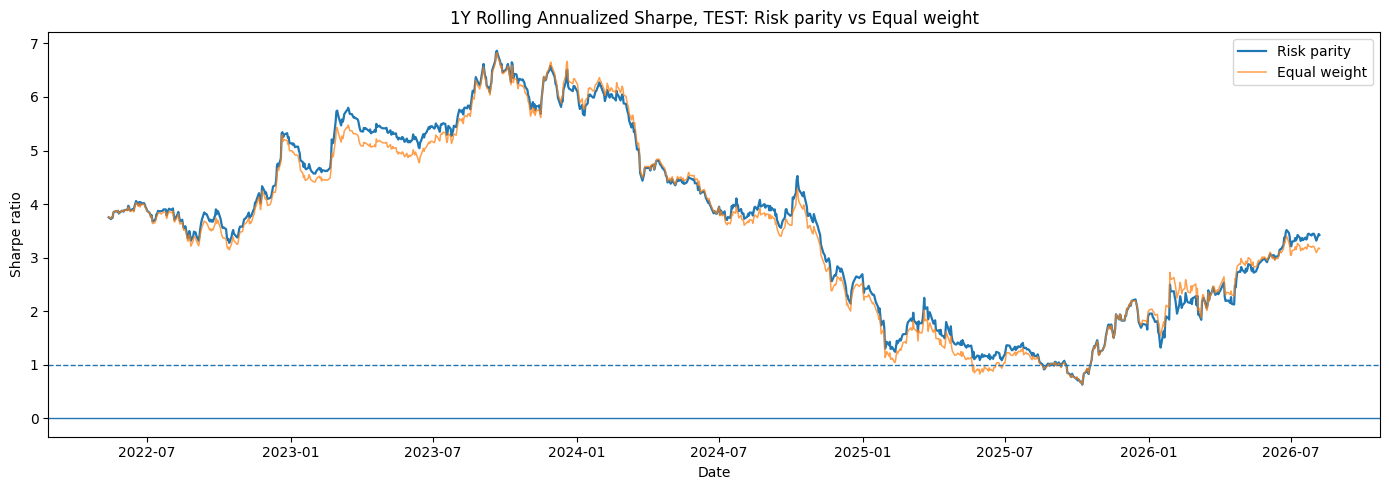

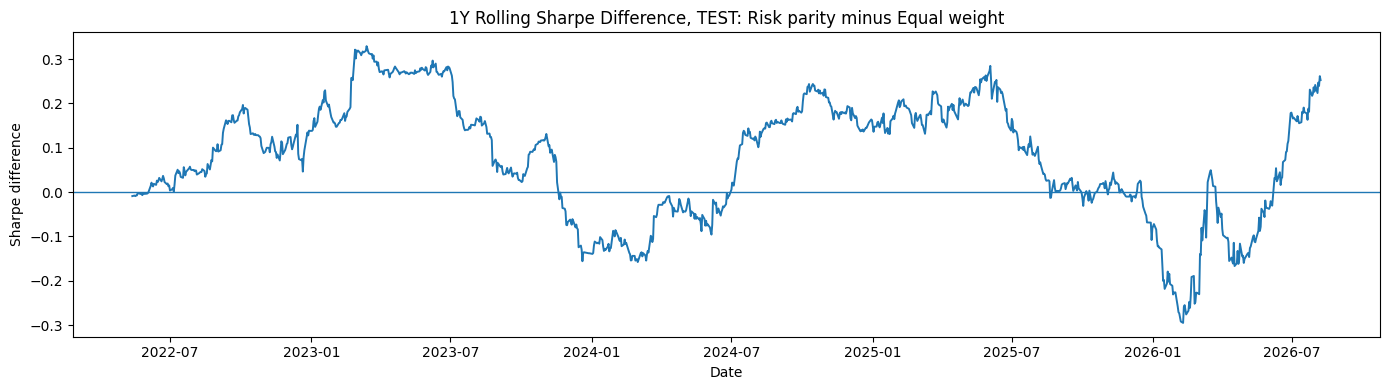

TEST: RISK PARITY vs EQUAL WEIGHT
TEST window                  : 2021-06-07 -> 2026-08-07
N                            : 1316
Risk parity Sharpe           : 3.645
Equal weight Sharpe          : 3.539
Risk parity cumulative return: 107.85%
Equal weight cumulative ret  : 110.45%
Risk parity max drawdown      : -6.50%
Equal weight max drawdown     : -7.81%
RP beats EW in 1Y windows    : 71.2%
Mean 1Y Sharpe advantage     : 0.077
Median 1Y Sharpe advantage   : 0.095


In [68]:
# ============================================================
# 13.X TEST RESULTS, CUMULATIVE RETURNS, ROLLING SHARPE
#      RISK PARITY vs EQUAL WEIGHT
#      DYNAMIC M4/M5
# ============================================================

TEST_SLICE = PERIODS["TEST"]

# ------------------------------------------------------------
# TEST PORTFOLIO RETURNS
# ------------------------------------------------------------

risk_parity_test = (
    sizing_results["risk parity"]["gross"]
    .loc[TEST_SLICE]
    .dropna()
)

equal_weight_test = (
    sizing_results["equal weight"]["gross"]
    .loc[TEST_SLICE]
    .dropna()
)

# Common TEST sample
_common_idx = risk_parity_test.index.intersection(equal_weight_test.index)

risk_parity_test = risk_parity_test.loc[_common_idx]
equal_weight_test = equal_weight_test.loc[_common_idx]

assert len(risk_parity_test) == len(equal_weight_test)
assert len(risk_parity_test) > 0


# ============================================================
# PERFORMANCE STATISTICS
# ============================================================

test_stats = pd.concat(
    {
        "Risk parity": performance_stats(risk_parity_test),
        "Equal weight": performance_stats(equal_weight_test),
    },
    axis=1,
)

display(test_stats.round(4))


# ============================================================
# ADDITIVE CUMULATIVE RETURNS + DRAWDOWN
# ============================================================

cum_rp = risk_parity_test.cumsum()
cum_ew = equal_weight_test.cumsum()

dd_rp = drawdown(risk_parity_test)
dd_ew = drawdown(equal_weight_test)


fig, ax = plt.subplots(
    2,
    1,
    figsize=(14, 8),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

# Cumulative return
ax[0].plot(
    cum_rp.index,
    cum_rp,
    linewidth=1.7,
    label="Risk parity",
)

ax[0].plot(
    cum_ew.index,
    cum_ew,
    linewidth=1.2,
    alpha=0.75,
    label="Equal weight",
)

ax[0].axhline(0, linewidth=1)
ax[0].set_ylabel("cumulative return")
ax[0].set_title(
    "Dynamic M4/M5, TEST: Risk parity vs Equal weight"
)
ax[0].legend()


# Drawdown
ax[1].fill_between(
    dd_rp.index,
    dd_rp,
    0,
    alpha=0.30,
    label="Risk parity",
)

ax[1].plot(
    dd_ew.index,
    dd_ew,
    linewidth=1.1,
    alpha=0.8,
    label="Equal weight",
)

ax[1].set_ylabel("drawdown")
ax[1].set_xlabel("Date")
ax[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# 1Y ROLLING SHARPE — TEST ONLY
# ============================================================

roll_rp_test = sharpe(
    risk_parity_test,
    window=TRADING_DAYS,
    min_periods=int(0.95 * TRADING_DAYS),
)

roll_ew_test = sharpe(
    equal_weight_test,
    window=TRADING_DAYS,
    min_periods=int(0.95 * TRADING_DAYS),
)


plt.figure(figsize=(14, 5))

plt.plot(
    roll_rp_test.index,
    roll_rp_test,
    linewidth=1.6,
    label="Risk parity",
)

plt.plot(
    roll_ew_test.index,
    roll_ew_test,
    linewidth=1.1,
    alpha=0.75,
    label="Equal weight",
)

plt.axhline(0, linewidth=1)
plt.axhline(1, linestyle="--", linewidth=1)

plt.title(
    "1Y Rolling Annualized Sharpe, TEST: "
    "Risk parity vs Equal weight"
)

plt.ylabel("Sharpe ratio")
plt.xlabel("Date")
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# ROLLING SHARPE DIFFERENCE
# ============================================================

_roll_idx = (
    roll_rp_test.dropna().index
    .intersection(roll_ew_test.dropna().index)
)

rp_roll = roll_rp_test.loc[_roll_idx]
ew_roll = roll_ew_test.loc[_roll_idx]

sharpe_diff = rp_roll - ew_roll


plt.figure(figsize=(14, 4))

plt.plot(
    sharpe_diff.index,
    sharpe_diff,
    linewidth=1.4,
)

plt.axhline(0, linewidth=1)

plt.title(
    "1Y Rolling Sharpe Difference, TEST: "
    "Risk parity minus Equal weight"
)

plt.ylabel("Sharpe difference")
plt.xlabel("Date")

plt.tight_layout()
plt.show()


# ============================================================
# TEST DIAGNOSTICS
# ============================================================

print("=" * 65)
print("TEST: RISK PARITY vs EQUAL WEIGHT")
print("=" * 65)

print(
    f"TEST window                  : "
    f"{_common_idx[0].date()} -> {_common_idx[-1].date()}"
)

print(f"N                            : {len(_common_idx)}")

print(
    f"Risk parity Sharpe           : "
    f"{sharpe(risk_parity_test):.3f}"
)

print(
    f"Equal weight Sharpe          : "
    f"{sharpe(equal_weight_test):.3f}"
)

print(
    f"Risk parity cumulative return: "
    f"{risk_parity_test.sum():.2%}"
)

print(
    f"Equal weight cumulative ret  : "
    f"{equal_weight_test.sum():.2%}"
)

print(
    f"Risk parity max drawdown      : "
    f"{dd_rp.min():.2%}"
)

print(
    f"Equal weight max drawdown     : "
    f"{dd_ew.min():.2%}"
)

if len(sharpe_diff) > 0:

    print(
        f"RP beats EW in 1Y windows    : "
        f"{(sharpe_diff > 0).mean():.1%}"
    )

    print(
        f"Mean 1Y Sharpe advantage     : "
        f"{sharpe_diff.mean():.3f}"
    )

    print(
        f"Median 1Y Sharpe advantage   : "
        f"{sharpe_diff.median():.3f}"
    )

In [69]:
# ============================================================
# END OF CHAPTER 13: CANONICAL NAMES ARE UNCHANGED
# ============================================================
# Chapter 13 ran entirely on its CH13_* inputs. Nothing above rebound a
# module-level name, so no teardown is required and no downstream section can
# inherit Chapter 13 state through execution order. This cell asserts that
# rather than assuming it.
# ============================================================

assert MAX_RANK == TRADE_MAX_RANK
assert set(residual_weights_rev) == set(range(1, TRADE_MAX_RANK + 1))
assert resid_base_trade is not uncon_book
assert "_CH13_ORIGINALS" not in globals(), "the global-swapping adapter is back"

_canonical_full = performance_stats(
    (resid_base_trade["gross"] - 2e-4 * resid_base_trade["turnover"]).dropna()
)["Sharpe ratio"]
print("Chapter 13 complete; canonical M1-M4 names never rebound.")
print(f"canonical M1-M4 net@2 Sharpe, FULL: {_canonical_full:.4f}"
      "   (must match Section 7 and the adaptive column of 15.3)")


Chapter 13 complete; canonical M1-M4 names never rebound.
canonical M1-M4 net@2 Sharpe, FULL: 1.7065   (must match Section 7 and the adaptive column of 15.3)


# 14. Liquidity-aware residual depth: M4 is the floor, M5 is the production ceiling

The Nelson-Siegel curve is always estimated on the **deepest valid contiguous strip**
available that day, up to M8. The production trade is different: it must be able to
carry real dollars.

For each market/date this section constructs five candidate residual portfolios:

- depth 4: trade M1-M4
- depth 5: trade M1-M5
- depth 6: trade M1-M6
- depth 7: trade M1-M7
- depth 8: trade M1-M8

Every candidate is the **raw** NS residual projected into the null space of that
depth's level/slope/curvature loadings, then normalised to unit gross. There is no
EWMA and no rolling mean.

The traded depth is selected causally:

1. M1-M4 is the minimum candidate.
2. Starting at M5, accept a deeper candidate only if all required data exist and
   its causal OI-based book capacity can support that market's desired dollar
   allocation.
3. Continue sequentially through M8. If M7 is affordable but M8 is not, trade M1-M7.
4. After depth selection, the normal water-filling allocator enforces the selected
   market capacities across the whole portfolio.
5. The resulting variable-depth leg positions are mapped to **specific contracts**.
   P&L and turnover come from the same position path, so changing from M7 to M6 is
   not free and roll costs are not reconstructed heuristically.

The capacity inputs are the same production-safe rules already used in notebook B:
5% OI cap, rolling-median OI level, continuous staleness haircut, trailing causal
95th-percentile absolute leg weight, unknown capacity excluded, and a one-day lag.

For a clean experiment the **market risk-parity target remains anchored to the
Dynamic M4/M5 sign-anchored residual covariance model from section 13**. Thus the comparison below
isolates residual depth rather than simultaneously changing both depth and market
sizing.


In [70]:
# ============================================================
# 14.0 TRADABLE UNIVERSE AND CAPACITY BASIS
# ============================================================
# Two governance decisions, both made here and applied to everything below.
#
# 1. DTV IS NOT USED AS A CAPACITY CONSTRAINT. The available volume panel
#    reports M1 on under 20% of price days in every market, which is not a
#    credible description of the front contract and is a limitation of the
#    data rather than of the market. A constraint that is NaN for the most
#    liquid leg everywhere caps nothing and gives a false impression of two
#    independent tests. Capacity below is open interest only.
#
# 2. ZUB IS NOT TRADABLE. The M1-M4 trade requires all four legs. ZUB4 has 58
#    open-interest prints in the whole sample and four inside the trailing
#    250-day capacity window, so its fourth leg cannot be sized. A leg that
#    cannot be sized cannot be held, and the spread is a complete hedge, so
#    the market has no depth-4 capacity at all. It is excluded from the
#    tradable universe rather than being assigned a number.
#
# The research universe stays at ten markets. Everything from here on runs on
# the tradable universe, and the two counts are reported separately.

USE_DTV_CAP = False

# ------------------------------------------------------------
# CAPACITY CONSTANTS AND THE CAUSAL DTV BUILDER
# ------------------------------------------------------------
# These live here, at top level, because two different things need them:
#   - the POSITION cap (14.1 / 14.2), governed by USE_DTV_CAP
#   - the TRADE cap diagnostic (14.6b), which is independent of that switch
# Defining them inside a `USE_DTV_CAP` branch left 14.6b with no builder.
#
# VOL_MIN_COVER is the share of its own listed span on which a leg must print
# volume before it earns a DTV cap. Measured coverage is bimodal: the M2-M4
# legs of the deep markets sit near 0.6-0.99, everything else below 0.35, and
# every M1 below 0.25. 0.50 separates the two groups, and it is the reason
# note 1 above rejects DTV as a position constraint.
# ------------------------------------------------------------

OI_CAP = 0.05
MWH_PER_CONTRACT = 736.0

VOL_ROLL_WINDOW = 90
VOL_MIN_PRINTS = 250        # prints required BEFORE a leg gets a volume cap
VOL_MIN_COVER = 0.50


def causal_dtv_notional(col, index, window):
    """
    Rolling dollar volume for one contract rank, using only past data.

    Eligibility is expanding, and the zero-fill starts at the first observed
    print with no reference to the end of the series, so neither looks forward.
    Returns NaN wherever the leg has not yet qualified, so callers can fall
    back to the OI cap without a separate eligibility test.
    """
    if col not in volume.columns or col not in prices.columns:
        return None

    raw = volume[col].reindex(index)
    seen = raw.notna()
    if not seen.any():
        return None

    first = seen.idxmax()

    # an omitted day after the first print is a no-trade day, not missing data
    filled = raw.copy()
    filled.loc[first:] = filled.loc[first:].fillna(0.0)
    dtv = filled.rolling(window, min_periods=20).mean()

    n_prints = seen.cumsum()
    elapsed = pd.Series(np.arange(len(index)), index=index) - index.get_loc(first)
    coverage = n_prints / elapsed.clip(lower=1)
    eligible = (n_prints >= VOL_MIN_PRINTS) & (coverage >= VOL_MIN_COVER)

    return (dtv * prices[col].reindex(index) * MWH_PER_CONTRACT).where(eligible)


NON_TRADABLE_MARKETS = {
    "ZUB": "M4 open interest unmeasurable in the capacity window; no depth-4 trade exists",
}

TRADABLE_UNIVERSE = [m for m in price_universe if m not in NON_TRADABLE_MARKETS]

print(f"research universe  ({len(price_universe)}): {price_universe}")
print(f"tradable universe  ({len(TRADABLE_UNIVERSE)}): {TRADABLE_UNIVERSE}")
for _m, _why in NON_TRADABLE_MARKETS.items():
    print(f"  excluded {_m}: {_why}")

# Evidence for the exclusion, from open interest alone.
# Build this table locally rather than relying on a scratch variable from an
# earlier interactive cell.  In a clean kernel `_ev` is the risk-model
# eigenvalue vector, not an OI evidence table.
_win = prices.index[-250:]
_legs = [f"M{k}" for k in range(1, DYNAMIC_MAX_DEPTH + 1)]
_ev_rows = []
for _m in price_universe:
    for _k in range(1, DYNAMIC_MAX_DEPTH + 1):
        _col = f"{_m}{_k}"
        _raw = (
            open_interest[_col].reindex(prices.index)
            if _col in open_interest.columns
            else pd.Series(np.nan, index=prices.index, dtype=float)
        )
        _ev_rows.append({
            "Market": _m,
            "Leg": f"M{_k}",
            "OI prints, all": int(_raw.notna().sum()),
            "OI prints, window": int(_raw.reindex(_win).notna().sum()),
        })
_ev_df = pd.DataFrame(_ev_rows)

_oi_prints_all = (
    _ev_df.pivot(index="Market", columns="Leg", values="OI prints, all")
    .reindex(columns=_legs)
)
_oi_prints = (
    _ev_df.pivot(index="Market", columns="Leg", values="OI prints, window")
    .reindex(columns=_legs)
)

_px_days = pd.DataFrame({
    f"M{k}": {
        m: prices[f"{m}{k}"].notna().sum() if f"{m}{k}" in prices.columns else 0
        for m in price_universe
    }
    for k in range(1, DYNAMIC_MAX_DEPTH + 1)
})

print("\nOI prints, full sample:")
display(_oi_prints_all)

print(f"\nOI prints inside the {len(_win)}-day capacity window:")
display(_oi_prints)

print("\nOI prints as a share of days the contract was priced, full sample:")
display((_oi_prints_all / _px_days.replace(0, np.nan)).round(3))

research universe  (10): ['ZUB', 'ITP', 'DET', 'FAC', 'DFP', 'SXD', 'UTD', 'MSP', 'PHB', 'PCB']
tradable universe  (9): ['ITP', 'DET', 'FAC', 'DFP', 'SXD', 'UTD', 'MSP', 'PHB', 'PCB']
  excluded ZUB: M4 open interest unmeasurable in the capacity window; no depth-4 trade exists

OI prints, full sample:


Leg,M1,M2,M3,M4,M5
Market,,,,,
DET,2254,2361,2359,2326,2265
DFP,2649,2755,2626,2194,1035
FAC,3504,3605,3525,3112,2083
ITP,3024,3112,3120,2950,2109
MSP,2805,2928,2763,2190,1610
PCB,2167,2110,1510,411,93
PHB,2357,2339,2060,1333,635
SXD,2437,2197,1334,315,58
UTD,1910,1961,1566,851,290



OI prints inside the 250-day capacity window:


Leg,M1,M2,M3,M4,M5
Market,,,,,
DET,240,250,250,250,250
DFP,241,250,250,249,195
FAC,241,250,250,250,250
ITP,240,250,250,250,193
MSP,241,250,250,250,235
PCB,241,250,214,66,7
PHB,241,250,248,163,71
SXD,242,248,209,79,32
UTD,241,250,242,154,24



OI prints as a share of days the contract was priced, full sample:


Leg,M1,M2,M3,M4,M5
Market,,,,,
DET,0.950,0.993,0.992,0.979,0.953
DFP,0.929,0.966,0.922,0.773,0.648
FAC,0.950,0.986,0.969,0.861,0.780
ITP,0.944,0.991,0.988,0.935,0.733
MSP,0.901,0.979,0.951,0.782,0.654
PCB,0.525,0.509,0.363,0.114,0.026
PHB,0.542,0.535,0.470,0.305,0.145
SXD,0.855,0.773,0.473,0.153,0.123
UTD,0.818,0.840,0.671,0.365,0.124


In [71]:
# ============================================================
# 14.2 CAUSAL CAPACITY FOR EACH CANDIDATE DEPTH: OPEN INTEREST ONLY
# ============================================================

LEG_WEIGHT_Q = 0.95
LEG_WEIGHT_WINDOW = 500
LEG_WEIGHT_MIN_OBS = 60
LEG_WEIGHT_FLOOR = 1e-3

OI_PRINT_WINDOW = 20
OI_STALENESS_HALFLIFE = 60.0

_pos = pd.Series(np.arange(len(RISK_INDEX)), index=RISK_INDEX)

oi_notional_base = {}
oi_quality_dynamic = {}

for market in TRADABLE_UNIVERSE:
    q = {}
    for k in range(1, DYNAMIC_MAX_DEPTH + 1):
        col = f"{market}{k}"
        if col not in open_interest.columns or col not in prices.columns:
            continue

        raw = open_interest[col].reindex(RISK_INDEX)
        level = (
            raw.dropna()
            .rolling(OI_PRINT_WINDOW, min_periods=1)
            .median()
            .reindex(RISK_INDEX)
            .ffill()
        )
        stale = _pos - _pos.where(raw.notna()).ffill()
        haircut = np.power(0.5, stale / OI_STALENESS_HALFLIFE)
        px = prices[col].reindex(RISK_INDEX)

        oi_notional_base[(market, k)] = (
            OI_CAP * level * px * MWH_PER_CONTRACT * haircut
        )

        q[f"M{k} print cov"] = raw.loc[TEST_START:].notna().mean()
        q[f"M{k} haircut"] = haircut.loc[TEST_START:].mean()
    oi_quality_dynamic[market] = q


capacity_by_depth = {}
binding_leg_by_depth = {}

for depth in DYNAMIC_DEPTHS:
    C = pd.DataFrame(np.nan, index=RISK_INDEX, columns=price_universe, dtype=float)
    B = pd.DataFrame(np.nan, index=RISK_INDEX, columns=price_universe, dtype=float)

    for market in TRADABLE_UNIVERSE:
        legs = {}
        for k in range(1, depth + 1):
            if (market, k) not in oi_notional_base:
                legs = {}
                break

            wk = (
                candidate_weights_by_depth[depth][k][market]
                .abs()
                .rolling(LEG_WEIGHT_WINDOW, min_periods=LEG_WEIGHT_MIN_OBS)
                .quantile(LEG_WEIGHT_Q)
                .ffill()
                .clip(lower=LEG_WEIGHT_FLOOR)
            )
            legs[k] = oi_notional_base[(market, k)] / wk

        if legs:
            caps = pd.concat(legs, axis=1)
            # A leg with no reachable OI print is UNKNOWN, not infinite. A
            # candidate whose every leg is not priced is NaN, which the depth
            # selector rejects and water_fill excludes.
            C[market] = caps.min(axis=1).where(caps.notna().all(axis=1))
            ok = caps.notna().any(axis=1)
            if ok.any():
                B.loc[ok, market] = caps.loc[ok].idxmin(axis=1).astype(float)

    # The depth decision at t may use capacity information only through t-1.
    capacity_by_depth[depth] = C.shift(1)
    binding_leg_by_depth[depth] = B.shift(1)


print("Median candidate book capacity in TEST ($m), open-interest cap only")
display(pd.concat(
    {f"M1-M{d}": capacity_by_depth[d].loc[TEST_START:].median() / 1e6
     for d in DYNAMIC_DEPTHS},
    axis=1,
).round(3))

print("\nBinding leg by depth, share of TEST days")
for d in DYNAMIC_DEPTHS:
    _b = binding_leg_by_depth[d].loc[TEST_START:]
    print(f"  M1-M{d}: " + "  ".join(
        f"M{int(k)} {(_b == k).sum().sum() / _b.notna().sum().sum():.0%}"
        for k in range(1, d + 1)
    ))

Median candidate book capacity in TEST ($m), open-interest cap only


,M1-M4,M1-M5
ZUB,NaN,NaN
ITP,3.116,0.634
DET,46.583,10.679
FAC,7.986,1.785
DFP,0.893,0.204
SXD,0.130,0.043
UTD,0.054,0.008
MSP,1.677,0.440
PHB,0.403,0.070
PCB,0.121,0.019



Binding leg by depth, share of TEST days
  M1-M4: M1 0%  M2 1%  M3 21%  M4 78%
  M1-M5: M1 0%  M2 0%  M3 4%  M4 25%  M5 72%


In [72]:
# ============================================================
# 14.1 RAW MARKET CAPACITY AT A CAP ON OPEN INTEREST
# ============================================================
#
# Covers M1-M5, the legs the book can actually hold (DYNAMIC_MAX_DEPTH).
#
# The window is a fixed span of TRADING DAYS, common to every leg. The earlier
# version used .tail(CAPACITY_LOOKBACK) on each column independently, which
# takes the last N live OBSERVATIONS rather than the last N days: a leg that
# prints open interest at quarter ends reached back years while a dense leg
# reached back one. That is not a like-for-like snapshot, and it is exactly
# the error that makes a thin deferred leg look tradable.
#
# "prints" counts actual OI observations inside the window. A leg with a
# handful of prints has a capacity number, not a capacity measurement.
# ============================================================

OI_CAP = 0.05
MWH_PER_CONTRACT = 736.0
CAPACITY_LOOKBACK = 250          # trading days, common to every leg

CAPACITY_MAX_RANK = DYNAMIC_MAX_DEPTH
_window = prices.index[-CAPACITY_LOOKBACK:]
LEGS = [f"M{k}" for k in range(1, CAPACITY_MAX_RANK + 1)]

rows = []
for market in price_universe:
    for k in range(1, CAPACITY_MAX_RANK + 1):
        col = f"{market}{k}"
        if col not in open_interest.columns or col not in prices.columns:
            continue

        raw = open_interest[col].reindex(_window)
        oi_series = raw.ffill(limit=5)  # OI staleness assumption, not execution-data ffill
        px_series = prices[col].reindex(_window)
        live = oi_series.notna() & px_series.notna()
        if live.sum() < 20:
            continue

        oi_lots = oi_series[live].median()
        price = px_series[live].median()
        dollars_per_lot = price * MWH_PER_CONTRACT

        rows.append({
            "Market": market, "Leg": f"M{k}",
            "prints": int(raw.notna().sum()),
            "cover": live.mean(),
            "OI (lots)": oi_lots,
            "Price ($/MWh)": price,
            "$ per lot": dollars_per_lot,
            "Total OI ($m)": oi_lots * dollars_per_lot / 1e6,
            "Max lots": OI_CAP * oi_lots,
            "Max $m": OI_CAP * oi_lots * dollars_per_lot / 1e6,
        })

capacity_table = pd.DataFrame(rows).set_index(["Market", "Leg"])
print(f"WINDOW {_window[0].date()} -> {_window[-1].date()} "
      f"({CAPACITY_LOOKBACK} trading days), same for every leg")
display(capacity_table.round(2))

capacity_grid = capacity_table["Max $m"].unstack("Leg").reindex(columns=LEGS)
capacity_grid["total"] = capacity_grid.sum(axis=1, min_count=1)
capacity_grid = capacity_grid.sort_values("total", ascending=False)
capacity_grid.loc["TOTAL"] = capacity_grid.sum(min_count=1)

print(f"\nMAX $m TRADABLE AT {OI_CAP:.0%} OF OPEN INTEREST, M1-M{CAPACITY_MAX_RANK}")
display(capacity_grid.round(2))

_leg = capacity_table.groupby("Leg")["Max $m"].sum().reindex(LEGS).fillna(0.0)
_share = _leg / _leg.sum()
print("\nshare of tradable capacity by leg:")
print("  " + "   ".join(f"{l} {_share[l]:5.1%}" for l in LEGS))
print(f"M1+M2 hold {_share[['M1','M2']].sum():.1%}; "
      f"M4+M5 hold {_share[['M4','M5']].sum():.1%}")

_mkt = capacity_grid["total"].drop("TOTAL")
print(f"top market {_mkt.idxmax()} = {_mkt.max()/_mkt.sum():.0%} of total; "
      f"top 3 = {_mkt.nlargest(3).sum()/_mkt.sum():.0%}")


WINDOW 2025-08-15 -> 2026-08-07 (250 trading days), same for every leg


prints  cover  OI (lots)  Price ($/MWh)  $ per lot  Total OI ($m)  \
Market Leg                                                                      
ZUB    M1      177   0.77       60.0          91.24   67148.96           4.03   
       M2      183   0.77       15.0          92.68   68212.48           1.02   
       M3       74   0.42       70.0          94.90   69842.72           4.89   
ITP    M1      240   1.00    44307.0         119.18   87716.48        3886.45   
       M2      250   1.00    39874.0         115.98   85361.28        3403.70   
       M3      250   1.00     2629.0         115.09   84706.24         222.69   
       M4      250   1.00      240.0         114.62   84360.32          20.25   
       M5      193   0.85       47.0         116.92   86053.12           4.04   
DET    M1      240   1.00   285415.0          96.95   71355.20       20365.84   
       M2      250   1.00   257828.5          97.32   71623.84       18466.67   
       M3      250   1.00    24545.0          96.70   71167.52        1746.81   
       M4      250   1.00     4554.0          94.70   69695.52         317.39   
       M5      250   1.00      954.0          96.99   71384.64          68.10   
FAC    M1      241   1.00    85806.0          57.80   42537.12        3649.94   
       M2      250   1.00    66099.5          60.66   44645.76        2951.06   
       M3      250   1.00    10071.0          64.03   47126.08         474.61   
       M4      250   1.00     1519.5          58.82   43291.52          65.78   
       M5      250   1.00      317.0          60.88   44807.68          14.20   
DFP    M1      241   1.00    11328.0          93.43   68760.80         778.92   
       M2      250   1.00    10289.5          94.92   69861.12         718.84   
       M3      250   1.00      741.0          95.93   70604.48          52.32   
       M4      249   1.00      129.0          96.88   71307.36           9.20   
       M5      195   0.84       48.0          98.12   72212.64           3.47   
SXD    M1      242   1.00     2877.0          88.85   65393.60         188.14   
       M2      248   1.00     2440.0          92.74   68260.32         166.56   
       M3      209   0.89       72.5          91.13   67071.68           4.86   
       M4       79   0.42       10.0          91.72   67502.24           0.68   
       M5       32   0.19        9.0          82.41   60653.76           0.55   
UTD    M1      241   1.00     3279.0         107.66   79237.76         259.82   
       M2      250   1.00     2338.0         102.70   75587.20         176.72   
       M3      242   1.00      117.0         104.10   76617.60           8.96   
       M4      154   0.73       20.0         104.44   76864.16           1.54   
       M5       24   0.16       20.0         113.78   83742.08           1.67   
MSP    M1      241   1.00    17160.0          64.29   47321.12         812.03   
       M2      250   1.00    14115.5          67.87   49952.32         705.10   
       M3      250   1.00     1530.5          71.32   52491.52          80.34   
       M4      250   1.00      338.5          74.17   54585.44          18.48   
       M5      235   0.98       77.0          75.23   55369.28           4.26   
PHB    M1      241   1.00    12407.0         116.08   85434.88        1059.99   
       M2      250   1.00    10712.5         120.22   88481.92         947.86   
       M3      248   1.00      572.0         118.98   87565.60          50.09   
       M4      163   0.76       53.0         116.80   85964.80           4.56   
       M5       71   0.36       21.0         113.35   83425.60           1.75   
PCB    M1      241   1.00     2077.0         104.49   76904.64         159.73   
       M2      250   1.00     1817.0         102.62   75532.00         137.24   
       M3      214   0.95       72.0         105.02   77291.04           5.56   
       M4       66   0.36       16.0         108.81   80084.16           1.28   

            Max lots   Max $m  
Market Leg


MAX $m TRADABLE AT 5% OF OPEN INTEREST, M1-M5


Leg,M1,M2,M3,M4,M5,total
Market,,,,,,
DET,1018.29,923.33,87.34,15.87,3.41,2048.24
ITP,194.32,170.18,11.13,1.01,0.20,376.86
FAC,182.50,147.55,23.73,3.29,0.71,357.78
PHB,53.00,47.39,2.50,0.23,0.09,103.21
MSP,40.60,35.26,4.02,0.92,0.21,81.01
DFP,38.95,35.94,2.62,0.46,0.17,78.14
UTD,12.99,8.84,0.45,0.08,0.08,22.44
SXD,9.41,8.33,0.24,0.03,0.03,18.04
PCB,7.99,6.86,0.28,0.06,NaN,15.19



share of tradable capacity by leg:
  M1 50.2%   M2 44.6%   M3  4.3%   M4  0.7%   M5  0.2%
M1+M2 hold 94.9%; M4+M5 hold 0.9%
top market DET = 66% of total; top 3 = 90%


In [73]:
# ============================================================
# 14.1b RAW MARKET CAPACITY AT A CAP ON DAILY VOLUME
# ============================================================
#
# The exact mirror of 14.1, on DTV90 instead of open interest, so the two are
# read side by side.
#
# The cap here is a POSITION limit expressed as an exit time:
#
#     max position = EXIT_DAYS x PARTICIP x DTV90 x price x MWh
#
# i.e. never hold more than you could liquidate in EXIT_DAYS at PARTICIP of
# that contract's average daily volume. The two constants only ever appear as
# their product, so 10 days at 5% and 5 days at 10% are the same cap. Stating
# it as a product makes the assumption visible.
#
# "prints" counts actual volume observations inside the window. Legs below
# VOL_MIN_COVER are excluded entirely rather than shown with a fabricated
# number.
# ============================================================

if not USE_DTV_CAP:
    print("DTV capacity diagnostic skipped: USE_DTV_CAP=False; production capacity is OI-only.")
else:
    VOL_EXIT_DAYS = 10.0
    VOL_PARTICIP = 0.05

    _vwindow = prices.index[-CAPACITY_LOOKBACK:]

    rows = []
    for market in price_universe:
        for k in range(1, CAPACITY_MAX_RANK + 1):
            col = f"{market}{k}"
            if col not in volume.columns or col not in prices.columns:
                continue

            raw = volume[col]
            span = raw.notna()
            if span.sum() < 250:
                continue
            first, last = span.idxmax(), span[::-1].idxmax()
            cover_own = span.loc[first:last].mean()
            if cover_own < VOL_MIN_COVER:
                continue

            filled = raw.copy()
            filled.loc[first:last] = filled.loc[first:last].fillna(0.0)
            dtv = filled.rolling(VOL_ROLL_WINDOW, min_periods=20).mean().reindex(_vwindow)
            px_series = prices[col].reindex(_vwindow).ffill(limit=5)

            live = dtv.notna() & px_series.notna()
            if live.sum() < 20:
                continue

            dtv_lots = dtv[live].median()
            price = px_series[live].median()
            dollars_per_lot = price * MWH_PER_CONTRACT

            rows.append({
                "Market": market, "Leg": f"M{k}",
                "prints": int(raw.reindex(_vwindow).notna().sum()),
                "cover": live.mean(),
                "DTV90 (lots)": dtv_lots,
                "Price ($/MWh)": price,
                "$ per lot": dollars_per_lot,
                "DTV90 ($m)": dtv_lots * dollars_per_lot / 1e6,
                "Max lots": VOL_EXIT_DAYS * VOL_PARTICIP * dtv_lots,
                "Max $m": VOL_EXIT_DAYS * VOL_PARTICIP * dtv_lots * dollars_per_lot / 1e6,
            })

    volume_capacity_table = pd.DataFrame(rows).set_index(["Market", "Leg"])
    print(f"WINDOW {_vwindow[0].date()} -> {_vwindow[-1].date()} "
          f"({CAPACITY_LOOKBACK} trading days), same for every leg")
    print(f"cap = {VOL_EXIT_DAYS:.0f} days x {VOL_PARTICIP:.0%} of DTV{VOL_ROLL_WINDOW}"
          f" = {VOL_EXIT_DAYS * VOL_PARTICIP:.2f} x one day's volume")
    display(volume_capacity_table.round(2))

    volume_capacity_grid = (
        volume_capacity_table["Max $m"].unstack("Leg").reindex(columns=LEGS)
    )
    volume_capacity_grid["total"] = volume_capacity_grid.sum(axis=1, min_count=1)
    volume_capacity_grid = volume_capacity_grid.sort_values("total", ascending=False)
    volume_capacity_grid.loc["TOTAL"] = volume_capacity_grid.sum(min_count=1)

    print(f"\nMAX $m TRADABLE AT {VOL_EXIT_DAYS:.0f}d x {VOL_PARTICIP:.0%} OF DTV"
          f"{VOL_ROLL_WINDOW}, M1-M{CAPACITY_MAX_RANK}")
    display(volume_capacity_grid.round(2))

    _vleg = (volume_capacity_table.groupby("Leg")["Max $m"].sum()
             .reindex(LEGS).fillna(0.0))
    _vshare = _vleg / _vleg.sum()
    print("\nshare of tradable capacity by leg:")
    print("  " + "   ".join(f"{l} {_vshare[l]:5.1%}" for l in LEGS))

    _vmkt = volume_capacity_grid["total"].drop("TOTAL")
    print(f"top market {_vmkt.idxmax()} = {_vmkt.max()/_vmkt.sum():.0%} of total; "
          f"top 3 = {_vmkt.nlargest(3).sum()/_vmkt.sum():.0%}")

    # ------------------------------------------------------------
    # side by side with 14.1: which constraint is tighter, per leg
    # ------------------------------------------------------------
    _cmp = pd.concat(
        {"OI $m": capacity_table["Max $m"], "DTV $m": volume_capacity_table["Max $m"]},
        axis=1,
    )
    _cmp["binds"] = np.where(
        _cmp["DTV $m"].isna(), "OI (no volume)",
        np.where(_cmp["DTV $m"] < _cmp["OI $m"], "DTV", "OI"),
    )
    _cmp["DTV / OI"] = _cmp["DTV $m"] / _cmp["OI $m"]
    print("\nWHICH CONSTRAINT IS TIGHTER, PER LEG")
    display(_cmp.round(3))
    print("The table above shows which constraint is tighter by market and leg on the current data.")
    print("No hardcoded dominance assumption is used downstream.")


DTV capacity diagnostic skipped: USE_DTV_CAP=False; production capacity is OI-only.


In [74]:
# ============================================================
# 14.2 CAUSAL CAPACITY FOR EACH CANDIDATE DEPTH: min(OI, DTV)
# ============================================================

if not USE_DTV_CAP:
    print("DTV constraint disabled: retaining the OI-only capacity_by_depth built in Section 14.2.")
else:
    LEG_WEIGHT_Q = 0.95
    LEG_WEIGHT_WINDOW = 500
    LEG_WEIGHT_MIN_OBS = 60
    LEG_WEIGHT_FLOOR = 1e-3

    OI_PRINT_WINDOW = 20
    OI_STALENESS_HALFLIFE = 60.0

    _pos = pd.Series(np.arange(len(RISK_INDEX)), index=RISK_INDEX)

    # OI_CAP, MWH_PER_CONTRACT, VOL_* and causal_dtv_notional come from 14.0.

    # Dollar notional that each individual rank can support BEFORE dividing by
    # the candidate portfolio's leg weight. This part is common to every depth.
    oi_notional_base = {}
    oi_quality_dynamic = {}

    for market in TRADABLE_UNIVERSE:
        q = {}
        for k in range(1, DYNAMIC_MAX_DEPTH + 1):
            col = f"{market}{k}"
            if col not in open_interest.columns or col not in prices.columns:
                continue

            raw = open_interest[col].reindex(RISK_INDEX)
            level = (
                raw.dropna()
                .rolling(OI_PRINT_WINDOW, min_periods=1)
                .median()
                .reindex(RISK_INDEX)
                .ffill()
            )
            stale = _pos - _pos.where(raw.notna()).ffill()
            haircut = np.power(0.5, stale / OI_STALENESS_HALFLIFE)
            px = prices[col].reindex(RISK_INDEX)

            cap_oi = OI_CAP * level * px * MWH_PER_CONTRACT * haircut

            # ----------------------------------------------------------
            # SECOND CONSTRAINT: never hold more than VOL_EXIT_DAYS of
            # exit at VOL_PARTICIP of average daily volume.
            #
            # Open interest bounds what can be HELD; volume bounds what can be
            # TRADED. For a high-turnover strategy the flow constraint can be the binding
            # one. The relative tightness of OI and DTV caps is measured from the current run.
            # Legs below VOL_MIN_COVER keep the OI cap alone (see 14.0 note 2).
            # ----------------------------------------------------------
            _dtv = causal_dtv_notional(col, RISK_INDEX, VOL_ROLL_WINDOW)
            cap_vol = None #if _dtv is None else VOL_EXIT_DAYS * VOL_PARTICIP * _dtv

            # A NaN in cap_vol means the leg has not yet earned a volume cap on
            # that date, so it falls back to the OI cap rather than being excluded.
            oi_notional_base[(market, k)] = (
                cap_oi if cap_vol is None
                else pd.concat([cap_oi, cap_vol.fillna(np.inf)], axis=1).min(axis=1)
            )
            q[f"M{k} vol-bound"] = (
                np.nan if cap_vol is None
                else float((cap_vol < cap_oi).loc[TEST_START:].mean())
            )

            q[f"M{k} print cov"] = raw.loc[TEST_START:].notna().mean()
            q[f"M{k} haircut"] = haircut.loc[TEST_START:].mean()
        oi_quality_dynamic[market] = q


    capacity_by_depth = {}
    binding_leg_by_depth = {}

    for depth in DYNAMIC_DEPTHS:
        C = pd.DataFrame(np.nan, index=RISK_INDEX, columns=price_universe, dtype=float)
        B = pd.DataFrame(np.nan, index=RISK_INDEX, columns=price_universe, dtype=float)

        for market in TRADABLE_UNIVERSE:
            legs = {}
            for k in range(1, depth + 1):
                if (market, k) not in oi_notional_base:
                    legs = {}
                    break

                wk = (
                    candidate_weights_by_depth[depth][k][market]
                    .abs()
                    .rolling(
                        LEG_WEIGHT_WINDOW,
                        min_periods=LEG_WEIGHT_MIN_OBS,
                    )
                    .quantile(LEG_WEIGHT_Q)
                    .ffill()
                    .clip(lower=LEG_WEIGHT_FLOOR)
                )
                legs[k] = oi_notional_base[(market, k)] / wk

            if legs:
                caps = pd.concat(legs, axis=1)
                # FIX: a leg with no reachable OI print is an UNKNOWN, not an
                # infinity. `caps.min(axis=1)` skips NaN, so such a leg was
                # silently treated as unconstrained and could make a deep
                # candidate look affordable when it is not. A candidate whose
                # every leg is not priced is now NaN, which the depth selector
                # rejects and water_fill excludes.
                C[market] = caps.min(axis=1).where(caps.notna().all(axis=1))
                ok = caps.notna().any(axis=1)
                if ok.any():
                    B.loc[ok, market] = caps.loc[ok].idxmin(axis=1).astype(float)

        # The depth decision at t may use capacity information only through t-1.
        capacity_by_depth[depth] = C.shift(1)
        binding_leg_by_depth[depth] = B.shift(1)


    print("Share of TEST days on which the VOLUME cap is the binding one")
    display(pd.DataFrame(oi_quality_dynamic).T
            [[c for c in pd.DataFrame(oi_quality_dynamic).T.columns
              if "vol-bound" in c]].round(2))

    print("\nMedian candidate book capacity in TEST ($m)")
    _cap_med = pd.concat(
        {
            f"M1-M{d}": capacity_by_depth[d].loc[TEST_START:].median() / 1e6
            for d in DYNAMIC_DEPTHS
        },
        axis=1,
    )
    display(_cap_med.round(2))


DTV constraint disabled: retaining the OI-only capacity_by_depth built in Section 14.2.


In [75]:
# ============================================================
# 14.3 ALLOCATOR + VARIABLE-DEPTH SPECIFIC-CONTRACT ENGINE
# ============================================================


def water_fill(target_weights, capacities, aum, max_passes=20):
    """Allocate dollars subject to known capacities; unknown capacity = excluded."""
    live = np.isfinite(target_weights) & (target_weights > 0)
    known = np.isfinite(capacities)
    if not live.any():
        return np.zeros_like(target_weights), np.zeros_like(live, dtype=bool)

    cap = np.where(known, capacities, 0.0)
    w = np.where(live, target_weights, 0.0)
    if w.sum() <= 0:
        return np.zeros_like(w), np.zeros_like(live, dtype=bool)
    w = w / w.sum()

    alloc = np.zeros_like(w)
    free = live.copy()
    budget = float(aum)

    for _ in range(max_passes):
        if not free.any() or budget <= 1e-9:
            break
        wf = np.where(free, w, 0.0)
        if wf.sum() <= 0:
            break
        wf = wf / wf.sum()
        proposed = alloc + budget * wf
        over = free & (proposed > cap)
        if not over.any():
            alloc = np.where(free, proposed, alloc)
            break
        alloc = np.where(over, cap, np.where(free, proposed, alloc))
        budget = aum - alloc.sum()
        free &= ~over

    capped = known & (alloc >= cap - 1e-9) & live
    return alloc, capped


# Keep exactly the market risk target established in Chapter 13.
# This isolates the depth/capacity experiment from the market-combination rule.
DYNAMIC_RISK_PARITY = sizing_weights["risk parity"].copy()

def run_variable_depth_portfolio(
    weights_by_rank,
    depth_panel,
    cost_bps=0.0,
    lag=LAG_BASE,
    coverage_floor=COVERAGE_FLOOR,
    roll_out_buffer=ROLL_OUT_BUFFER,
    trade_cap=None,
    trade_aum=None,
):
    """Thin variable-depth wrapper around the canonical contract engine."""
    return run_contract_positions(
        weights_by_rank,
        prices,
        tickers,
        price_universe,
        index=RISK_INDEX,
        max_rank=DYNAMIC_MAX_DEPTH,
        depth_panel=depth_panel,
        min_depth=DYNAMIC_MIN_DEPTH,
        lag=lag,
        cost_bps=cost_bps,
        coverage_floor=coverage_floor,
        ffill_limit=None,
        roll_out_buffer=roll_out_buffer,
        market_aggregation="sum",
        trade_cap=trade_cap,
        trade_aum=trade_aum,
    )


def build_dynamic_depth_book(
    K,
    aum,
    mode="liquidity_aware",
    cost_bps=2.0,
    allocation="reallocated",
):
    """
    mode (depth selection):
      fixed4          -> always M1-M4
      blind_deepest   -> deepest data-valid candidate, regardless of whether
                         that deeper residual can carry the desired allocation
      liquidity_aware -> go deeper sequentially only if candidate capacity is
                         >= the unconstrained desired market dollar allocation

    allocation (how a capacity shortfall is handled):
      reallocated -> PRODUCTION. water_fill redistributes the shortfall across
                     markets still below their ceilings, in proportion to the
                     original positive target weights.
      strict      -> each market is capped independently at its own target,
                     A_i = min(AUM * w_i, C_i), and the shortfall stays in cash.
                     Liquidity can only reduce a position, never create an
                     overweight elsewhere. This measures how much of the
                     INTENDED portfolio is executable, with no liquidity-driven
                     cross-sectional view. Diagnostic only; production is
                     "reallocated".
    """
    if allocation not in ("reallocated", "strict"):
        raise ValueError(f"Unknown allocation: {allocation}")
    Kn = K.div(K.sum(axis=1), axis=0)

    selected_depth = pd.DataFrame(
        np.nan, index=RISK_INDEX, columns=price_universe, dtype=float
    )
    selected_capacity = pd.DataFrame(
        np.nan, index=RISK_INDEX, columns=price_universe, dtype=float
    )

    for root in price_universe:
        valid4 = (
            candidate_gross_by_depth[4][root].notna()
            & capacity_by_depth[4][root].notna()
        )
        selected_depth.loc[valid4, root] = 4
        selected_capacity.loc[valid4, root] = capacity_by_depth[4].loc[valid4, root]

        target_dollars = aum * Kn[root]

        if mode == "fixed4":
            continue

        for depth in range(5, DYNAMIC_MAX_DEPTH + 1):
            valid = (
                candidate_gross_by_depth[depth][root].notna()
                & capacity_by_depth[depth][root].notna()
            )

            if mode == "blind_deepest":
                choose = valid
            elif mode == "liquidity_aware":
                choose = (
                    valid
                    & target_dollars.notna()
                    & (capacity_by_depth[depth][root] >= target_dollars)
                )
            else:
                raise ValueError(f"Unknown mode: {mode}")

            selected_depth.loc[choose, root] = depth
            selected_capacity.loc[choose, root] = capacity_by_depth[depth].loc[choose, root]

    Kv = Kn.to_numpy(float)
    Cv = selected_capacity.to_numpy(float)
    A = np.zeros_like(Kv)
    C = np.zeros_like(Kv, dtype=bool)

    for i in range(len(RISK_INDEX)):
        if not np.isfinite(Kv[i]).any():
            A[i] = np.nan
            continue
        if allocation == "strict":
            k_i = np.where(np.isfinite(Kv[i]), Kv[i], 0.0)
            c_i = np.where(np.isfinite(Cv[i]), Cv[i], 0.0)
            A[i] = np.minimum(k_i * aum, c_i)
            C[i] = (k_i * aum) > (c_i + 1e-9)
        else:
            A[i], C[i] = water_fill(Kv[i], Cv[i], aum)

    alloc = pd.DataFrame(A, index=RISK_INDEX, columns=price_universe) / aum
    capped = pd.DataFrame(C, index=RISK_INDEX, columns=price_universe)

    # Fold the selected depth, candidate weights and market allocation into one
    # final rank-position path. Ranks above selected depth are exactly zero.
    final_weights = {
        k: pd.DataFrame(0.0, index=RISK_INDEX, columns=price_universe)
        for k in range(1, DYNAMIC_MAX_DEPTH + 1)
    }

    for root in price_universe:
        for depth in DYNAMIC_DEPTHS:
            m = selected_depth[root].eq(depth)
            if not m.any():
                continue
            for k in range(1, depth + 1):
                final_weights[k].loc[m, root] = (
                    candidate_weights_by_depth[depth][k].loc[m, root]
                    * alloc.loc[m, root]
                )

    res = run_variable_depth_portfolio(
        final_weights,
        selected_depth,
        cost_bps=cost_bps,
    )

    return {
        "selected_depth": selected_depth,
        "selected_capacity": selected_capacity,
        "alloc": alloc,
        "capped": capped,
        "final_weights": final_weights,
        **res,
    }


OPEN-INTEREST DATA QUALITY
Latest 250 trading days: 2025-08-15 -> 2026-08-07

Actual OI prints:


,M1,M2,M3,M4,M5
ZUB,177.0,183.0,74.0,4.0,0.0
ITP,240.0,250.0,250.0,250.0,193.0
DET,240.0,250.0,250.0,250.0,250.0
FAC,241.0,250.0,250.0,250.0,250.0
DFP,241.0,250.0,250.0,249.0,195.0
SXD,242.0,248.0,209.0,79.0,32.0
UTD,241.0,250.0,242.0,154.0,24.0
MSP,241.0,250.0,250.0,250.0,235.0
PHB,241.0,250.0,248.0,163.0,71.0
PCB,241.0,250.0,214.0,66.0,7.0



OI print coverage relative to priced days:


,M1,M2,M3,M4,M5
ZUB,0.708,0.732,0.296,0.017,NaN
ITP,0.964,1.000,1.000,1.000,0.772
DET,0.964,1.000,1.000,1.000,1.000
FAC,0.964,1.000,1.000,1.000,1.000
DFP,0.964,1.000,1.000,0.996,0.780
SXD,0.968,0.992,0.836,0.316,0.128
UTD,0.964,1.000,0.968,0.616,0.096
MSP,0.964,1.000,1.000,1.000,0.940
PHB,0.964,1.000,0.992,0.652,0.284
PCB,0.964,1.000,0.856,0.264,0.028


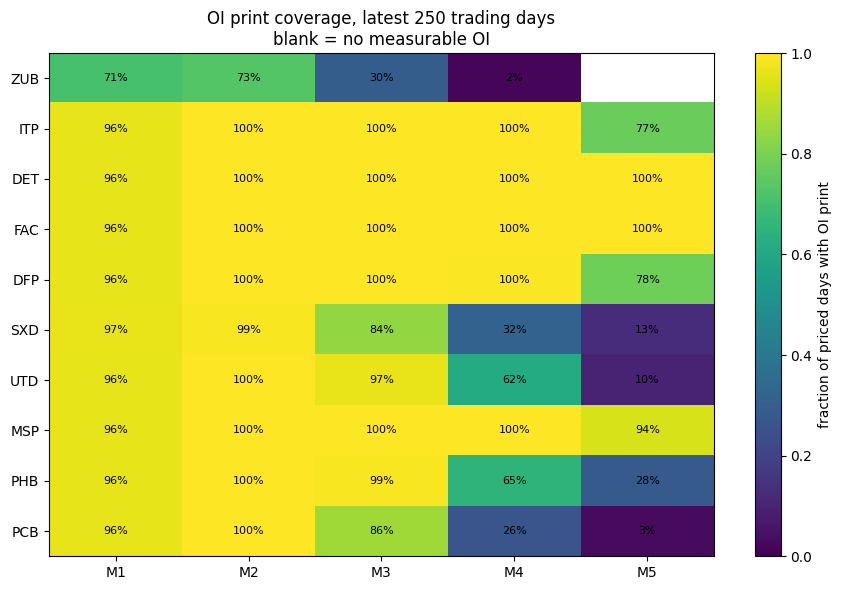


ZUB LIQUIDITY EVIDENCE


,full-sample OI prints,latest-250 OI prints
M1,1721,177
M2,1564,183
M3,698,74
M4,58,4
M5,0,0



ZUB is excluded from the tradable universe because M4 is required for every strategy position and its M4 OI cannot be measured reliably.

Research universe : ['ZUB', 'ITP', 'DET', 'FAC', 'DFP', 'SXD', 'UTD', 'MSP', 'PHB', 'PCB']
Tradable universe : ['ITP', 'DET', 'FAC', 'DFP', 'SXD', 'UTD', 'MSP', 'PHB', 'PCB']

RAW LEG CAPACITY AT 5% OF OPEN INTEREST


Leg,M1,M2,M3,M4,M5
Market,,,,,
ZUB,0.201,0.051,0.244,NaN,NaN
ITP,194.323,170.185,11.135,1.012,0.202
DET,1018.292,923.333,87.340,15.870,3.405
FAC,182.497,147.553,23.730,3.289,0.710
DFP,38.946,35.942,2.616,0.460,0.173
SXD,9.407,8.328,0.243,0.034,0.027
UTD,12.991,8.836,0.448,0.077,0.084
MSP,40.602,35.255,4.017,0.924,0.213
PHB,53.000,47.393,2.504,0.228,0.088


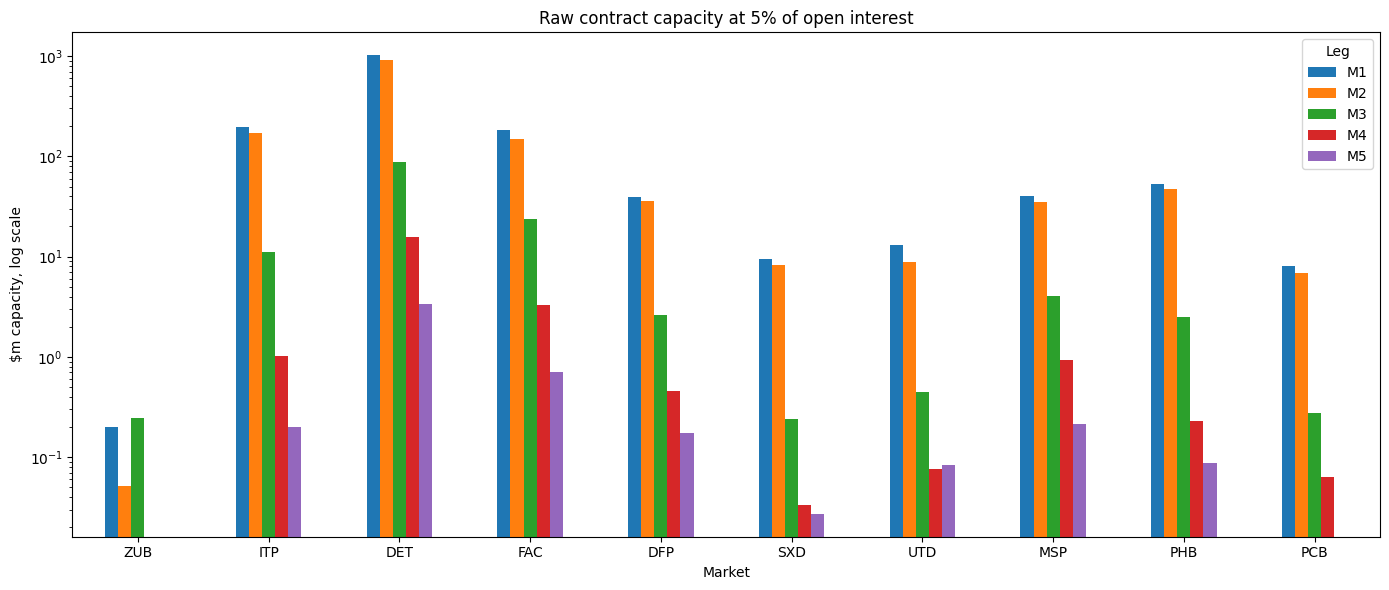

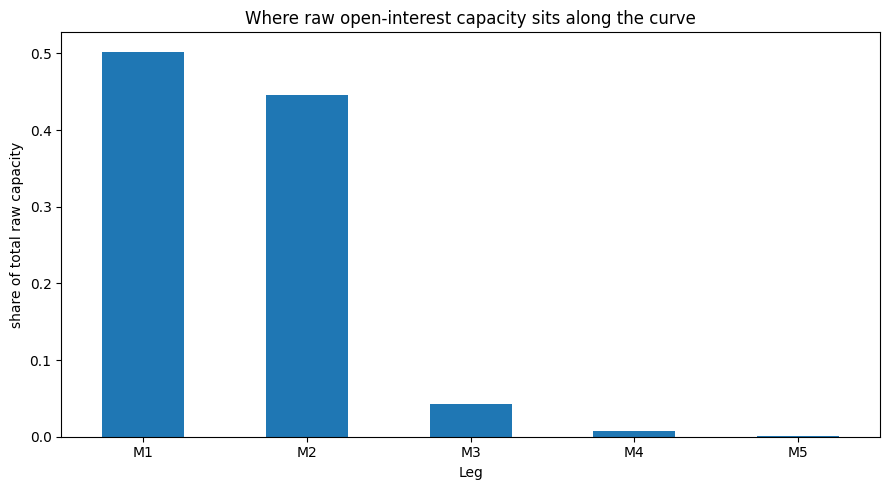

,$m raw capacity,share
Leg,,
M1,1558.2450,0.5024
M2,1383.7384,0.4462
M3,132.5565,0.0427
M4,21.9573,0.0071
M5,4.9026,0.0016



MEDIAN TEST STRATEGY CAPACITY ($m)


,M1-M4,M1-M5
ZUB,NaN,NaN
ITP,3.116,0.634
DET,46.583,10.679
FAC,7.986,1.785
DFP,0.893,0.204
SXD,0.130,0.043
UTD,0.054,0.008
MSP,1.677,0.440
PHB,0.403,0.070
PCB,0.121,0.019


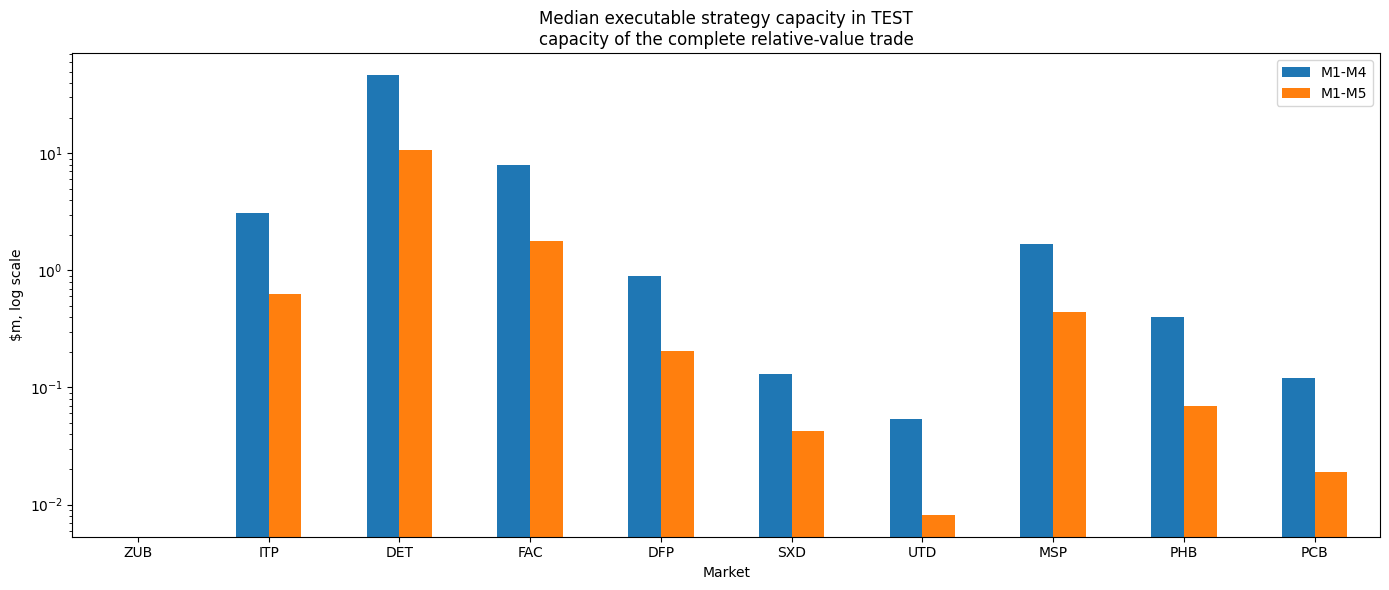

depth,M1-M4,M1-M5
binding leg,,
M1,0.000,0.000
M2,0.006,0.002
M3,0.210,0.036
M4,0.784,0.246
M5,0.000,0.716


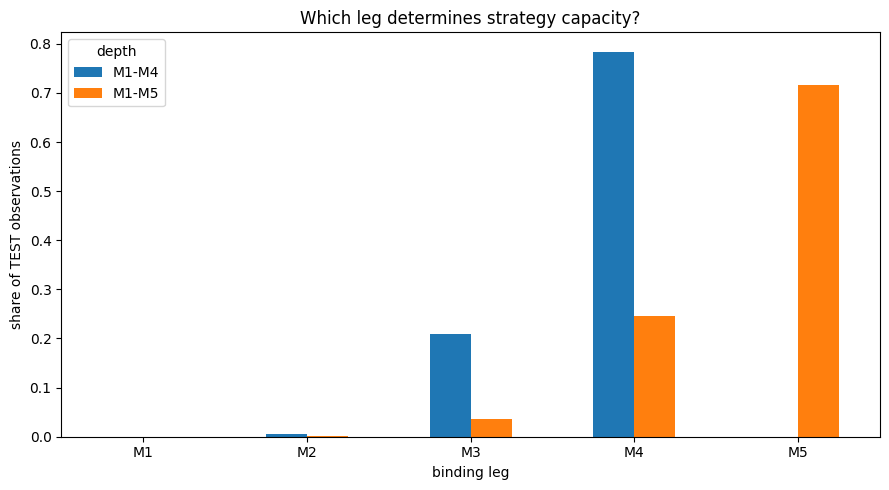

In [76]:
# ============================================================
# 14.4 LIQUIDITY AND CAPACITY — PRODUCTION DIAGNOSTICS
#      TEST ONLY, ZERO TRANSACTION COSTS
# ============================================================

LIQ_AUM_GRID = [10e6, 15e6, 25e6, 50e6, 100e6]
LIQ_TEST = PERIODS["TEST"]

# Everything in this section is GROSS / zero transaction costs.
LIQ_COST_BPS = 0.0


# ============================================================
# A. DATA QUALITY: OI PRINTS IN THE LATEST 250 DAYS
# ============================================================

LIQ_LOOKBACK = 250
_liq_window = RISK_INDEX[-LIQ_LOOKBACK:]

_oi_prints_250 = pd.DataFrame(
    index=price_universe,
    columns=[f"M{k}" for k in range(1, DYNAMIC_MAX_DEPTH + 1)],
    dtype=float,
)

_oi_cover_250 = _oi_prints_250.copy()

for market in price_universe:
    for k in range(1, DYNAMIC_MAX_DEPTH + 1):

        col = f"{market}{k}"

        if col not in open_interest.columns or col not in prices.columns:
            continue

        oi = open_interest[col].reindex(_liq_window)
        px = prices[col].reindex(_liq_window)

        priced = px.notna().sum()

        _oi_prints_250.loc[market, f"M{k}"] = oi.notna().sum()

        _oi_cover_250.loc[market, f"M{k}"] = (
            oi.notna().sum() / priced
            if priced > 0
            else np.nan
        )


print("=" * 72)
print("OPEN-INTEREST DATA QUALITY")
print("=" * 72)

print(
    f"Latest {LIQ_LOOKBACK} trading days: "
    f"{_liq_window[0].date()} -> {_liq_window[-1].date()}"
)

print("\nActual OI prints:")
display(_oi_prints_250)

print("\nOI print coverage relative to priced days:")
display(_oi_cover_250.round(3))


# ------------------------------------------------------------
# HEATMAP: OI PRINT COVERAGE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(
    _oi_cover_250.values,
    aspect="auto",
    vmin=0,
    vmax=1,
)

ax.set_xticks(range(len(_oi_cover_250.columns)))
ax.set_xticklabels(_oi_cover_250.columns)

ax.set_yticks(range(len(_oi_cover_250.index)))
ax.set_yticklabels(_oi_cover_250.index)

for i in range(len(_oi_cover_250.index)):
    for j in range(len(_oi_cover_250.columns)):
        x = _oi_cover_250.iloc[i, j]

        if np.isfinite(x):
            ax.text(
                j,
                i,
                f"{x:.0%}",
                ha="center",
                va="center",
                fontsize=8,
            )

ax.set_title(
    "OI print coverage, latest 250 trading days\n"
    "blank = no measurable OI"
)

plt.colorbar(im, ax=ax, label="fraction of priced days with OI print")
plt.tight_layout()
plt.show()


# ============================================================
# B. ZUB EXCLUSION
# ============================================================

print("\n" + "=" * 72)
print("ZUB LIQUIDITY EVIDENCE")
print("=" * 72)

zub_evidence = pd.DataFrame({
    "full-sample OI prints": [
        open_interest[f"ZUB{k}"].notna().sum()
        if f"ZUB{k}" in open_interest.columns else 0
        for k in range(1, DYNAMIC_MAX_DEPTH + 1)
    ],
    "latest-250 OI prints": [
        open_interest[f"ZUB{k}"].reindex(_liq_window).notna().sum()
        if f"ZUB{k}" in open_interest.columns else 0
        for k in range(1, DYNAMIC_MAX_DEPTH + 1)
    ],
}, index=[f"M{k}" for k in range(1, DYNAMIC_MAX_DEPTH + 1)])

display(zub_evidence)

print(
    "\nZUB is excluded from the tradable universe because M4 is required "
    "for every strategy position and its M4 OI cannot be measured reliably."
)

print(f"\nResearch universe : {price_universe}")
print(f"Tradable universe : {TRADABLE_UNIVERSE}")


# ============================================================
# C. RAW OI CAPACITY BY CONTRACT LEG
# ============================================================

raw_leg_capacity = (
    capacity_table["Max $m"]
    .unstack("Leg")
    .reindex(index=price_universe)
    .reindex(columns=[f"M{k}" for k in range(1, DYNAMIC_MAX_DEPTH + 1)])
)

print("\n" + "=" * 72)
print(f"RAW LEG CAPACITY AT {OI_CAP:.0%} OF OPEN INTEREST")
print("=" * 72)

display(raw_leg_capacity.round(3))


# ------------------------------------------------------------
# RAW CAPACITY BY MARKET / LEG
# Log scale is necessary because dispersion is enormous.
# ------------------------------------------------------------

ax = raw_leg_capacity.plot(
    kind="bar",
    figsize=(14, 6),
    logy=True,
)

ax.set_title(
    f"Raw contract capacity at {OI_CAP:.0%} of open interest"
)
ax.set_ylabel("$m capacity, log scale")
ax.set_xlabel("Market")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# WHERE DOES RAW CAPACITY SIT ALONG THE CURVE?
# ------------------------------------------------------------

_capacity_by_leg = raw_leg_capacity.sum(axis=0, min_count=1)
_capacity_share_by_leg = _capacity_by_leg / _capacity_by_leg.sum()

fig, ax = plt.subplots(figsize=(9, 5))

_capacity_share_by_leg.plot(
    kind="bar",
    ax=ax,
)

ax.set_ylabel("share of total raw capacity")
ax.set_title("Where raw open-interest capacity sits along the curve")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(
    pd.DataFrame({
        "$m raw capacity": _capacity_by_leg,
        "share": _capacity_share_by_leg,
    }).round(4)
)


# ============================================================
# D. STRATEGY CAPACITY: M1-M4 vs M1-M5
# ============================================================

strategy_capacity_test = pd.concat(
    {
        "M1-M4": (
            capacity_by_depth[4]
            .loc[LIQ_TEST]
            .median()
            / 1e6
        ),
        "M1-M5": (
            capacity_by_depth[5]
            .loc[LIQ_TEST]
            .median()
            / 1e6
        ),
    },
    axis=1,
).reindex(price_universe)


print("\nMEDIAN TEST STRATEGY CAPACITY ($m)")
display(strategy_capacity_test.round(3))


ax = strategy_capacity_test.plot(
    kind="bar",
    figsize=(14, 6),
    logy=True,
)

ax.set_title(
    "Median executable strategy capacity in TEST\n"
    "capacity of the complete relative-value trade"
)
ax.set_ylabel("$m, log scale")
ax.set_xlabel("Market")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# ============================================================
# E. WHICH LEG ACTUALLY BINDS?
# ============================================================

binding_rows = []

for depth in DYNAMIC_DEPTHS:

    b = (
        binding_leg_by_depth[depth]
        .loc[LIQ_TEST]
        .stack()
        .dropna()
        .astype(int)
    )

    for k in range(1, depth + 1):

        binding_rows.append({
            "depth": f"M1-M{depth}",
            "binding leg": f"M{k}",
            "share": (b == k).mean(),
        })

binding_table = pd.DataFrame(binding_rows)

display(
    binding_table.pivot(
        index="binding leg",
        columns="depth",
        values="share",
    ).fillna(0).round(3)
)

binding_table.pivot(
    index="binding leg",
    columns="depth",
    values="share",
).fillna(0).plot(
    kind="bar",
    figsize=(9, 5),
)

plt.ylabel("share of TEST observations")
plt.title("Which leg determines strategy capacity?")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [77]:
# ============================================================
# 14.5 UNCONSTRAINED vs LIQUIDITY-CONSTRAINED
#      RISK PARITY, TEST ONLY, ZERO TC
# ============================================================


# ============================================================
# A. ORIGINAL RESEARCH UNCONSTRAINED BOOK — 10 MARKETS
# ============================================================

research_unconstrained = sizing_results["risk parity"]


# ============================================================
# B. UNCONSTRAINED TRADABLE-UNIVERSE BOOK — ZUB REMOVED
# ============================================================
#
# Same Dynamic M4/M5 alpha.
# Same risk-parity target.
# No liquidity cap.
# ZUB removed and remaining target weights renormalized.
#
# This is the clean counterfactual for measuring the liquidity effect.
# ============================================================

K_uncon_tradable = DYNAMIC_RISK_PARITY.copy()

_nontradable = [
    m for m in price_universe
    if m not in TRADABLE_UNIVERSE
]

K_uncon_tradable.loc[:, _nontradable] = 0.0

K_uncon_tradable = K_uncon_tradable.div(
    K_uncon_tradable[TRADABLE_UNIVERSE].sum(axis=1),
    axis=0,
)


uncon_tradable_depth = uncon_depth.copy()
uncon_tradable_depth.loc[:, _nontradable] = np.nan


uncon_tradable_weights = {
    k: (
        uncon_weights[k]
        .reindex(K_uncon_tradable.index)
        * K_uncon_tradable
    )
    for k in range(1, DYNAMIC_MAX_DEPTH + 1)
}


uncon_tradable_book = run_variable_depth_portfolio(
    uncon_tradable_weights,
    uncon_tradable_depth,
    cost_bps=0.0,
)


# ============================================================
# C. LIQUIDITY-CONSTRAINED BOOKS
# ============================================================
# CORRECTED: must be built on K_uncon_tradable (the 9-market renormalized
# target from Part B above), not the raw 10-market DYNAMIC_RISK_PARITY.
# The un-renormalized target leaves ZUB's uninvestable share stranded in
# the denominator, which understates deployment and overstates Sharpe --
# the same failure mode fixed in prod_book (Section 15). Section 14.5b
# below quantifies the size of this effect explicitly (it rebuilds its
# own local 10-market comparator for that one purpose only); everything
# else in the notebook, including the plots in 14.6 and 14.7 that key off
# `liquidity_books`, must see the corrected target here.

liquidity_books = {}

for aum in LIQ_AUM_GRID:

    liquidity_books[aum] = build_dynamic_depth_book(
        K_uncon_tradable,
        aum,
        mode="liquidity_aware",
        cost_bps=0.0,
    )

    # Explicit zero-TC check
    assert np.allclose(
        liquidity_books[aum]["gross"].fillna(0),
        liquidity_books[aum]["net"].fillna(0),
    )


# ============================================================
# D. STRATEGY-LEVEL TABLE
# ============================================================

def strategy_liquidity_metrics(series):

    x = series.loc[LIQ_TEST].dropna()
    s = performance_stats(x)

    return {
        "N": len(x),
        "Sharpe": s["Sharpe ratio"],
        "Ann return": s["Mean"],
        "Ann vol": s["Volatility"],
        "Max DD": s["Maximum drawdown"],
        "Cumulative return": x.sum(),
    }


rows = []


# Original 10-market research result
m = strategy_liquidity_metrics(
    research_unconstrained["gross"]
)

rows.append({
    "Portfolio": "Unconstrained research, 10 markets",
    "AUM $m": np.nan,
    **m,
    "Mean utilisation": 1.0,
    "Avg markets capped": 0.0,
})


# ZUB removed, but no liquidity constraint
m = strategy_liquidity_metrics(
    uncon_tradable_book["gross"]
)

rows.append({
    "Portfolio": "Unconstrained tradable, 9 markets",
    "AUM $m": np.nan,
    **m,
    "Mean utilisation": 1.0,
    "Avg markets capped": 0.0,
})


# Capacity constrained
for aum in LIQ_AUM_GRID:

    bk = liquidity_books[aum]

    m = strategy_liquidity_metrics(
        bk["gross"]
    )

    rows.append({
        "Portfolio": f"Liquidity constrained ${aum/1e6:.0f}m",
        "AUM $m": aum / 1e6,
        **m,

        # fraction of total AUM actually deployed
        "Mean utilisation": (
            bk["alloc"]
            .loc[LIQ_TEST]
            .sum(axis=1)
            .mean()
        ),

        "Avg markets capped": (
            bk["capped"]
            .loc[LIQ_TEST]
            .sum(axis=1)
            .mean()
        ),
    })


liquidity_strategy_table = (
    pd.DataFrame(rows)
    .set_index("Portfolio")
)

display(liquidity_strategy_table.round(4))

,AUM $m,N,Sharpe,Ann return,Ann vol,Max DD,Cumulative return,Mean utilisation,Avg markets capped
Portfolio,,,,,,,,,
"Unconstrained research, 10 markets",NaN,1316,3.6450,0.2065,0.0567,-0.0650,1.0785,1.0000,0.0000
"Unconstrained tradable, 9 markets",NaN,1316,3.6241,0.2174,0.0600,-0.0597,1.1355,1.0000,0.0000
Liquidity constrained $10m,10.0,1316,2.8585,0.1688,0.0591,-0.0562,0.8816,0.9770,5.6667
Liquidity constrained $15m,15.0,1316,2.5687,0.1517,0.0591,-0.0540,0.7921,0.9580,6.3115
Liquidity constrained $25m,25.0,1316,2.3289,0.1311,0.0563,-0.0717,0.6845,0.8804,7.3560
Liquidity constrained $50m,50.0,1316,1.7246,0.0966,0.0560,-0.1207,0.5043,0.7021,8.1546
Liquidity constrained $100m,100.0,1316,1.6444,0.0871,0.0530,-0.1076,0.4548,0.5544,8.4125


## 14.5b Two capacity definitions: strict versus reallocated

Once a market hits its ceiling the portfolio can either hold the original risk target and leave the shortfall in cash, or let capital migrate to markets with spare capacity. These are different portfolios answering different questions, so both are reported. **Production is the reallocated book**; strict is the measure of how much of the *intended* strategy is executable without letting liquidity create a new cross-sectional view.

Both books are targeted on the **nine-market renormalized** risk-parity weights. ZUB is not capacity-certifiable, so leaving its target share in the denominator would strand it permanently in cash and understate deployment.


In [78]:
RECON_AUM = 15e6

# ============================================================
# 14.5b STRICT vs REALLOCATED CAPACITY
# ============================================================
# Target: K_uncon_tradable, the 9-market renormalized risk-parity weights from
# 14.5. Using the 10-market DYNAMIC_RISK_PARITY instead leaves ZUB's target
# share stranded in cash, since ZUB has no capacity print, which lowers measured
# deployment and inflates the apparent reallocation share. The reconciliation
# printed below quantifies that.
#
# TEST only, zero transaction costs, so the comparison isolates capacity and
# substitution. Cost sensitivity is in 14.6.
# ============================================================

ALLOCATION_MODES = ["strict", "reallocated"]
PRODUCTION_ALLOCATION = "reallocated"

_K9 = K_uncon_tradable.div(K_uncon_tradable.sum(axis=1), axis=0)

capacity_mode_books = {}
_rows = []

for aum in LIQ_AUM_GRID:
    for allocation in ALLOCATION_MODES:

        bk = build_dynamic_depth_book(
            K_uncon_tradable,
            aum,
            mode="liquidity_aware",
            cost_bps=0.0,
            allocation=allocation,
        )
        capacity_mode_books[(aum, allocation)] = bk

        gross = bk["gross"].loc[LIQ_TEST].dropna()
        alloc = bk["alloc"].reindex(gross.index)

        deployed = alloc.sum(axis=1)
        # Reallocation share: the part of the deployed book that exists only
        # because a market was pushed above its original target weight.
        overweight = (alloc - _K9.reindex(gross.index)).clip(lower=0).sum(axis=1)

        stats = performance_stats(gross)

        _rows.append({
            "AUM $m": aum / 1e6,
            "Mode": allocation,
            "Sharpe": stats["Sharpe ratio"],
            "Cum. return": float(gross.sum()),
            "Mean deployed": float(deployed.mean()),
            "Deployed $m": float(deployed.mean() * aum / 1e6),
            "Reallocation": float((overweight / deployed.replace(0, np.nan)).mean()),
            "Max DD": stats["Maximum drawdown"],
            # Cumulative return earned per unit of capital actually put to work.
            # Without it, strict looks better on Sharpe and worse on cumulative
            # return purely because it deploys roughly half as much capital.
            "Return per deployed $": float(gross.sum() / deployed.mean()),
        })

capacity_mode_table = pd.DataFrame(_rows).set_index(["AUM $m", "Mode"]).sort_index()

print("STRICT vs REALLOCATED CAPACITY — TEST, zero TC, 9-market target")
display(capacity_mode_table.round(4))

assert (
    capacity_mode_table.xs("strict", level="Mode")["Reallocation"].abs().max() < 1e-12
), "strict allocation must never overweight a market"

_strict = capacity_mode_table.xs("strict", level="Mode")
_realloc = capacity_mode_table.xs("reallocated", level="Mode")
print("\nStrict beats reallocated on Sharpe at every AUM:",
      bool((_strict["Sharpe"] > _realloc["Sharpe"]).all()))
print("Reallocated deploys more capital at every AUM   :",
      bool((_realloc["Deployed $m"] > _strict["Deployed $m"]).all()))

# ------------------------------------------------------------
# RECONCILIATION: 9-market vs 10-market target
# ------------------------------------------------------------
_bk10 = build_dynamic_depth_book(
    DYNAMIC_RISK_PARITY, RECON_AUM, mode="liquidity_aware",
    cost_bps=0.0, allocation="reallocated",
)
_g10 = _bk10["gross"].loc[LIQ_TEST].dropna()
_recon = pd.DataFrame({
    "10-market target (uncorrected baseline)": {
        "Sharpe": performance_stats(_g10)["Sharpe ratio"],
        "Mean deployed": float(_bk10["alloc"].reindex(_g10.index).sum(axis=1).mean()),
    },
    "9-market renormalized target": {
        "Sharpe": capacity_mode_table.loc[(RECON_AUM / 1e6, "reallocated"), "Sharpe"],
        "Mean deployed": capacity_mode_table.loc[(RECON_AUM / 1e6, "reallocated"), "Mean deployed"],
    },
})
print(f"\nRECONCILIATION AT ${RECON_AUM/1e6:.0f}m, reallocated, TEST")
display(_recon.round(4))
print("The two differ only in whether ZUB's uninvestable target share is left")
print("in the denominator. Section 14.5 (liquidity_books) and prod_book (Section 15)")
print("both use the 9-market column; the 10-market column is rebuilt here only to")
print("size the historical bug and is not used anywhere else in the notebook.")


STRICT vs REALLOCATED CAPACITY — TEST, zero TC, 9-market target


Sharpe  Cum. return  Mean deployed  Deployed $m  \
AUM $m Mode                                                           
10.0   reallocated  2.8585       0.8816         0.9778       9.7784   
       strict       3.1882       0.6300         0.6228       6.2285   
15.0   reallocated  2.5687       0.7921         0.9583      14.3745   
       strict       3.0309       0.5425         0.5641       8.4616   
25.0   reallocated  2.3289       0.6845         0.8807      22.0164   
       strict       2.7229       0.4329         0.4891      12.2272   
50.0   reallocated  1.7246       0.5043         0.7026      35.1305   
       strict       2.1799       0.2977         0.3867      19.3328   
100.0  reallocated  1.6444       0.4548         0.5552      55.5211   
       strict       1.9784       0.2238         0.2990      29.8976   

                    Reallocation  Max DD  Return per deployed $  
AUM $m Mode                                                      
10.0   reallocated        0.3617 -0.0562                 0.9016  
       strict             0.0000 -0.0351                 1.0115  
15.0   reallocated        0.4092 -0.0540                 0.8266  
       strict             0.0000 -0.0326                 0.9618  
25.0   reallocated        0.4315 -0.0717                 0.7772  
       strict             0.0000 -0.0294                 0.8852  
50.0   reallocated        0.4040 -0.1207                 0.7178  
       strict             0.0000 -0.0306                 0.7699  
100.0  reallocated        0.3689 -0.1076                 0.8191  
       strict             0.0000 -0.0295                 0.7487


Strict beats reallocated on Sharpe at every AUM: True
Reallocated deploys more capital at every AUM   : True



RECONCILIATION AT $15m, reallocated, TEST


,10-market target (uncorrected baseline),9-market renormalized target
Sharpe,2.6427,2.5687
Mean deployed,0.9523,0.9583


The two differ only in whether ZUB's uninvestable target share is left
in the denominator. Section 14.5 (liquidity_books) and prod_book (Section 15)
both use the 9-market column; the 10-market column is rebuilt here only to
size the historical bug and is not used anywhere else in the notebook.


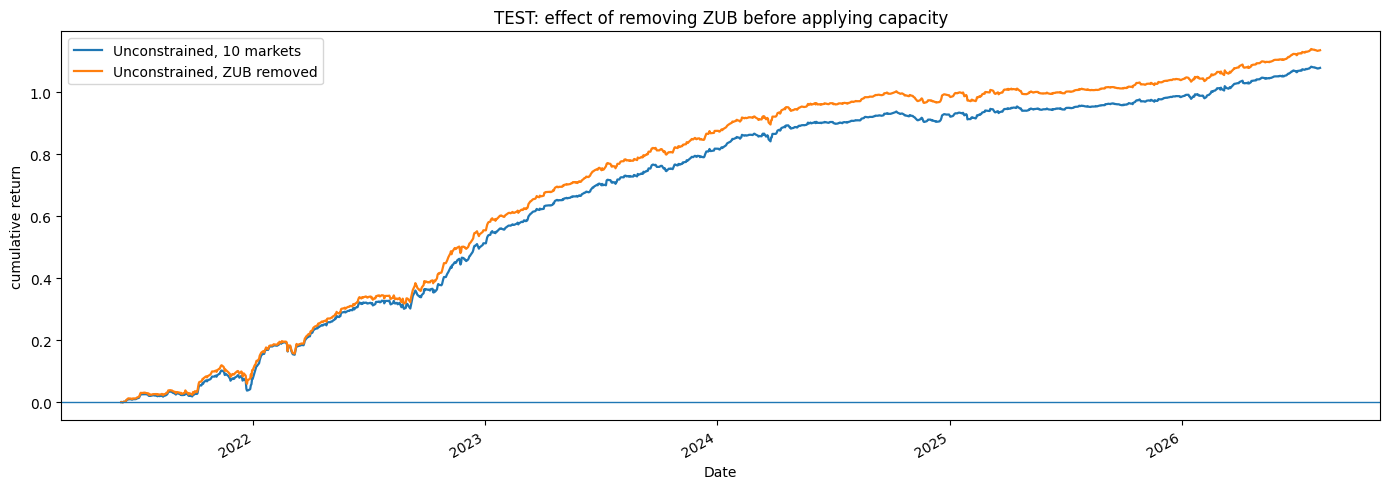

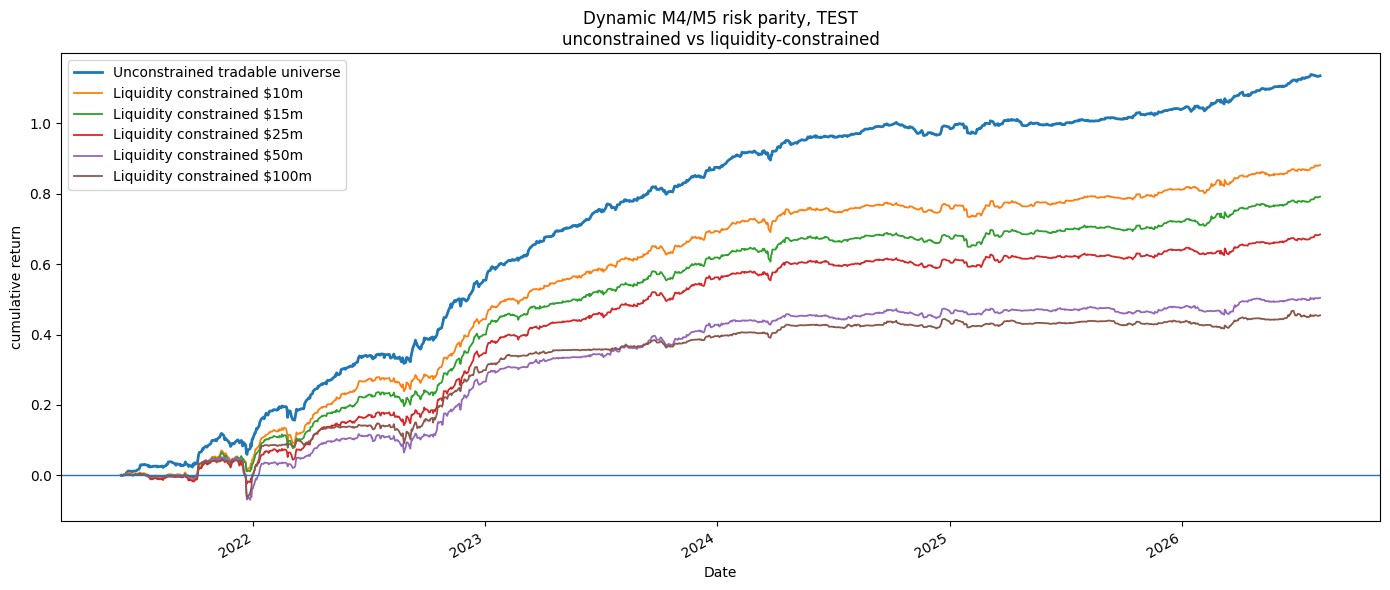

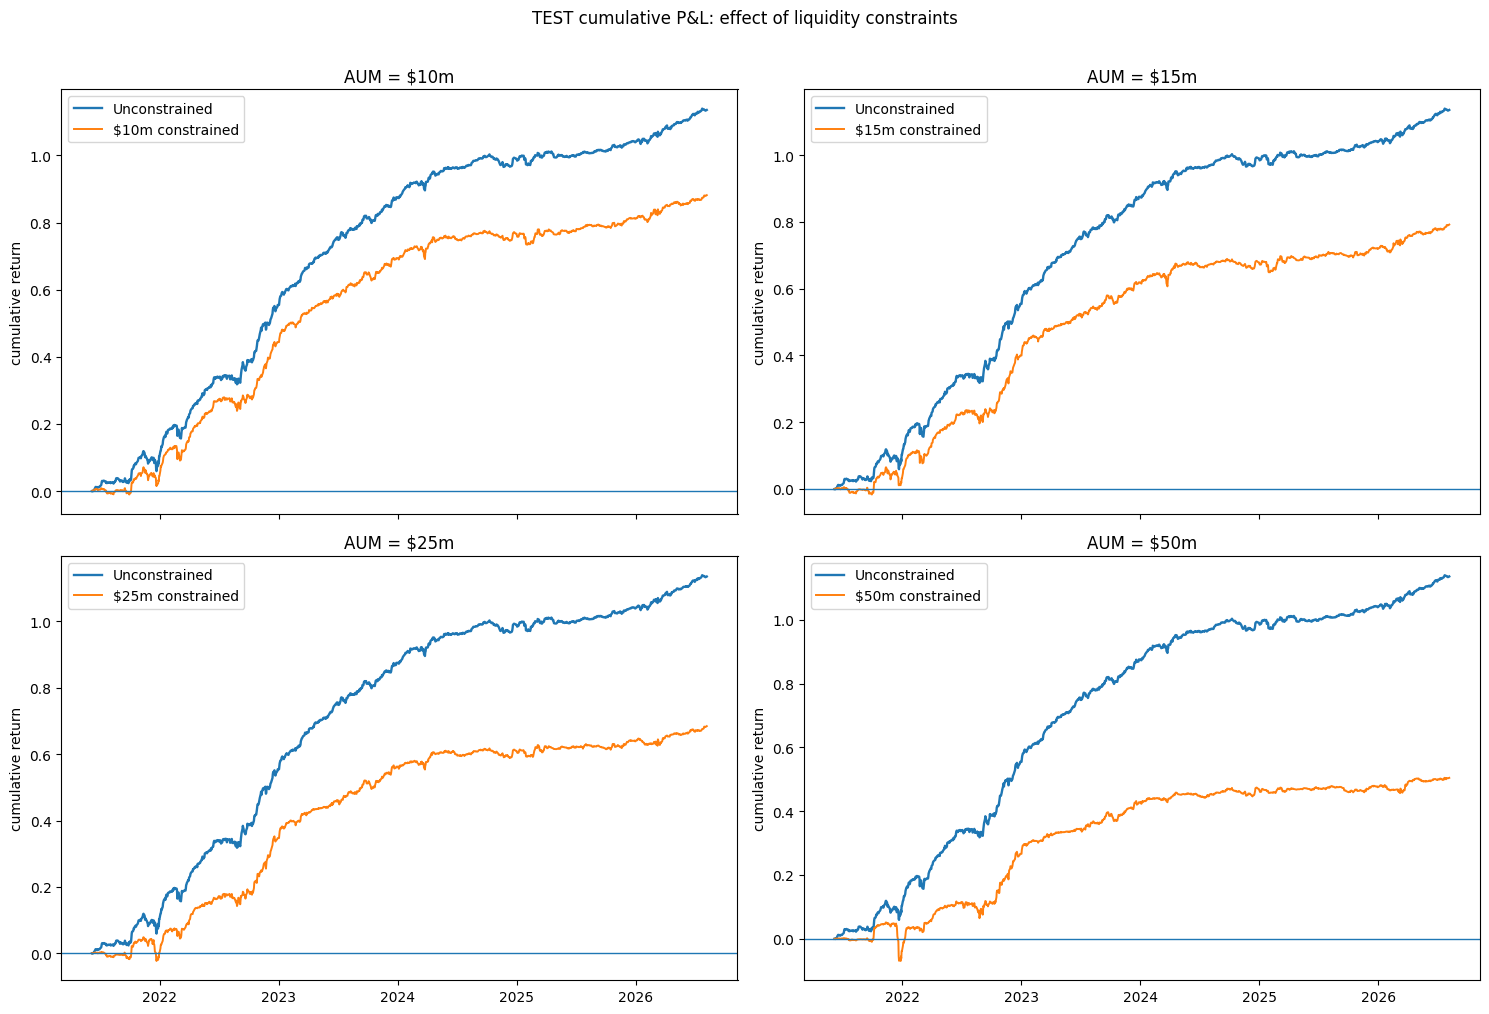

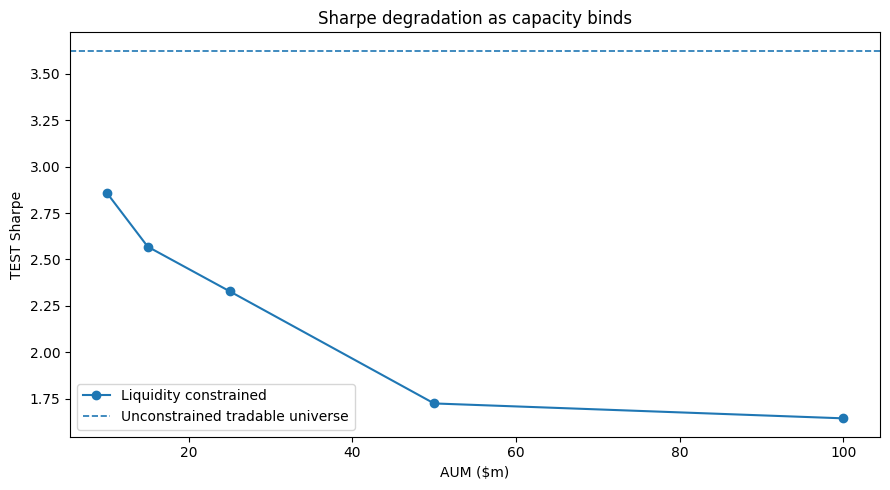

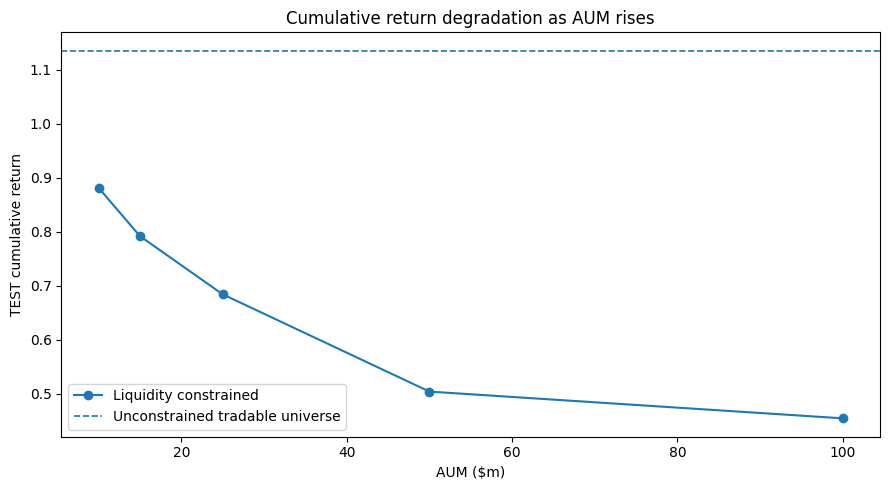

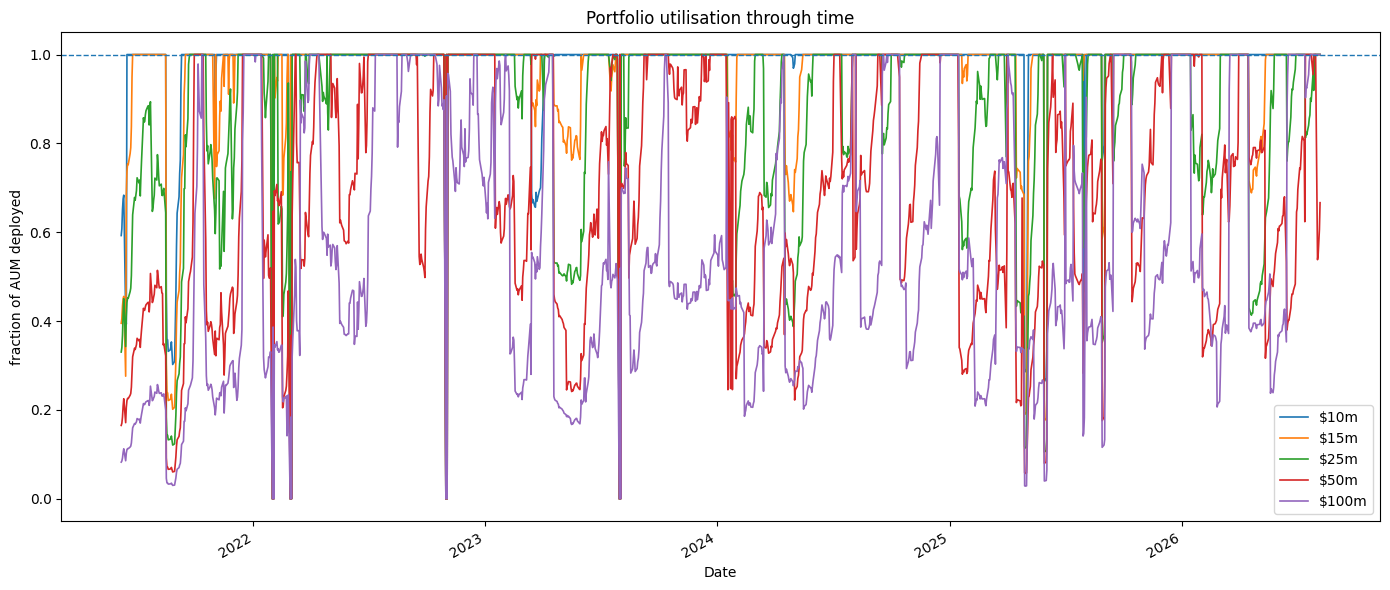

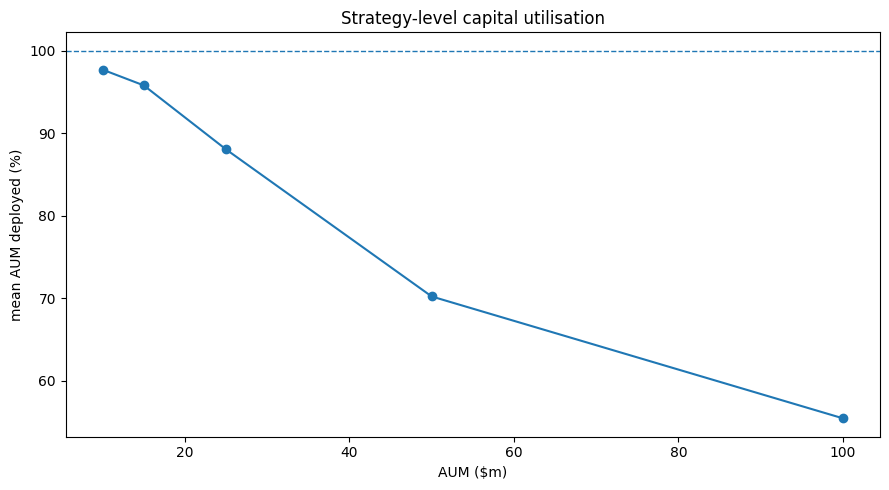

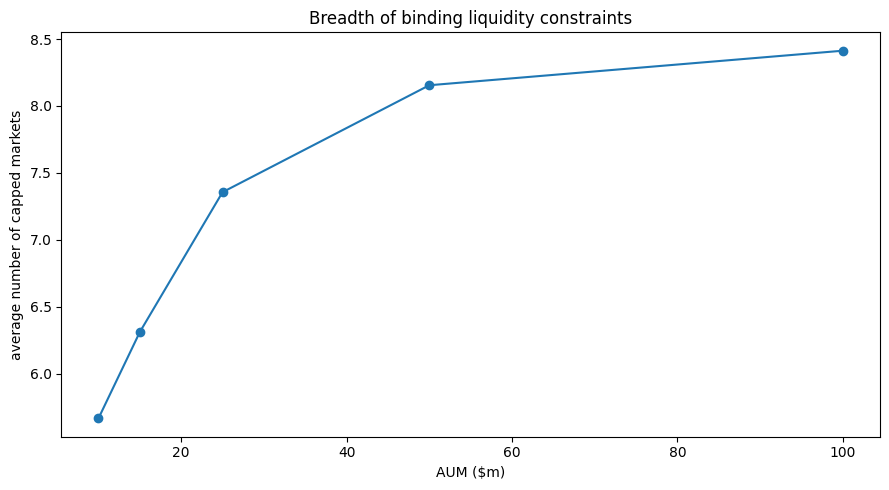

In [79]:
# ============================================================
# 14.6 STRATEGY-LEVEL SCALING PLOTS
# ============================================================

test_uncon_10 = (
    research_unconstrained["gross"]
    .loc[LIQ_TEST]
    .dropna()
)

test_uncon_9 = (
    uncon_tradable_book["gross"]
    .loc[LIQ_TEST]
    .dropna()
)


# ============================================================
# 1. EFFECT OF DROPPING ZUB
# ============================================================

_common = test_uncon_10.index.intersection(test_uncon_9.index)

plt.figure(figsize=(14, 5))

test_uncon_10.loc[_common].cumsum().plot(
    linewidth=1.6,
    label="Unconstrained, 10 markets",
)

test_uncon_9.loc[_common].cumsum().plot(
    linewidth=1.6,
    label="Unconstrained, ZUB removed",
)

plt.axhline(0, linewidth=1)
plt.ylabel("cumulative return")
plt.title("TEST: effect of removing ZUB before applying capacity")
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 2. CUMULATIVE RETURNS — ALL AUM LEVELS
# ============================================================

plt.figure(figsize=(14, 6))

test_uncon_9.cumsum().plot(
    linewidth=2.0,
    label="Unconstrained tradable universe",
)

for aum in LIQ_AUM_GRID:

    x = (
        liquidity_books[aum]["gross"]
        .loc[LIQ_TEST]
        .dropna()
    )

    x.cumsum().plot(
        linewidth=1.3,
        label=f"Liquidity constrained ${aum/1e6:.0f}m",
    )

plt.axhline(0, linewidth=1)

plt.ylabel("cumulative return")
plt.title(
    "Dynamic M4/M5 risk parity, TEST\n"
    "unconstrained vs liquidity-constrained"
)

plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 3. ONE PANEL PER AUM
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10),
    sharex=True,
)

for ax, aum in zip(axes.flat, LIQ_AUM_GRID):

    constrained = (
        liquidity_books[aum]["gross"]
        .loc[LIQ_TEST]
        .dropna()
    )

    idx = test_uncon_9.index.intersection(constrained.index)

    ax.plot(
        idx,
        test_uncon_9.loc[idx].cumsum(),
        linewidth=1.7,
        label="Unconstrained",
    )

    ax.plot(
        idx,
        constrained.loc[idx].cumsum(),
        linewidth=1.4,
        label=f"${aum/1e6:.0f}m constrained",
    )

    ax.axhline(0, linewidth=1)

    ax.set_title(f"AUM = ${aum/1e6:.0f}m")
    ax.set_ylabel("cumulative return")
    ax.legend()

plt.suptitle(
    "TEST cumulative P&L: effect of liquidity constraints",
    y=1.01,
)

plt.tight_layout()
plt.show()


# ============================================================
# 4. SHARPE vs AUM
# ============================================================

_aum_rows = (
    liquidity_strategy_table[
        liquidity_strategy_table["AUM $m"].notna()
    ]
    .sort_values("AUM $m")
)

_uncon_sharpe = performance_stats(
    test_uncon_9
)["Sharpe ratio"]


plt.figure(figsize=(9, 5))

plt.plot(
    _aum_rows["AUM $m"],
    _aum_rows["Sharpe"],
    marker="o",
    label="Liquidity constrained",
)

plt.axhline(
    _uncon_sharpe,
    linestyle="--",
    linewidth=1.2,
    label="Unconstrained tradable universe",
)

plt.xlabel("AUM ($m)")
plt.ylabel("TEST Sharpe")
plt.title("Sharpe degradation as capacity binds")
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 5. CUMULATIVE RETURN vs AUM
# ============================================================

_uncon_cum = test_uncon_9.sum()

plt.figure(figsize=(9, 5))

plt.plot(
    _aum_rows["AUM $m"],
    _aum_rows["Cumulative return"],
    marker="o",
    label="Liquidity constrained",
)

plt.axhline(
    _uncon_cum,
    linestyle="--",
    linewidth=1.2,
    label="Unconstrained tradable universe",
)

plt.xlabel("AUM ($m)")
plt.ylabel("TEST cumulative return")
plt.title("Cumulative return degradation as AUM rises")
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 6. STRATEGY UTILISATION THROUGH TIME
# ============================================================

plt.figure(figsize=(14, 6))

for aum in LIQ_AUM_GRID:

    util = (
        liquidity_books[aum]["alloc"]
        .loc[LIQ_TEST]
        .sum(axis=1)
    )

    util.plot(
        linewidth=1.2,
        label=f"${aum/1e6:.0f}m",
    )

plt.axhline(
    1.0,
    linestyle="--",
    linewidth=1,
)

plt.ylabel("fraction of AUM deployed")
plt.title("Portfolio utilisation through time")
plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 7. MEAN UTILISATION vs AUM
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    _aum_rows["AUM $m"],
    100 * _aum_rows["Mean utilisation"],
    marker="o",
)

plt.axhline(100, linestyle="--", linewidth=1)

plt.xlabel("AUM ($m)")
plt.ylabel("mean AUM deployed (%)")
plt.title("Strategy-level capital utilisation")

plt.tight_layout()
plt.show()


# ============================================================
# 8. NUMBER OF CAPPED MARKETS vs AUM
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    _aum_rows["AUM $m"],
    _aum_rows["Avg markets capped"],
    marker="o",
)

plt.xlabel("AUM ($m)")
plt.ylabel("average number of capped markets")
plt.title("Breadth of binding liquidity constraints")

plt.tight_layout()
plt.show()

In [80]:
# ============================================================
# 14.7 ASSET-LEVEL LIQUIDITY DIAGNOSTICS
# ============================================================
#
# CORRECTED: source the 9-market renormalized reallocated book
# (capacity_mode_books) at each AUM, not the 10-market liquidity_books
# object. This is the table/heatmap data behind Section 7.6 and Figure 16;
# on the 10-market target the $50m per-market contributions summed to
# 51.57% of AUM instead of the 50.43% the paper quotes from Table 9/11.

markets = price_universe
aum_labels = [
    f"${aum/1e6:.0f}m"
    for aum in LIQ_AUM_GRID
]


# ------------------------------------------------------------
# Unconstrained risk-parity target after ZUB removal.
# This is the economically relevant target against which to
# measure how much the liquidity allocator changes the book.
# ------------------------------------------------------------

target_tradable = DYNAMIC_RISK_PARITY.copy()
target_tradable.loc[:, _nontradable] = 0.0

target_tradable = target_tradable.div(
    target_tradable[TRADABLE_UNIVERSE].sum(axis=1),
    axis=0,
)


mean_alloc = pd.DataFrame(
    index=markets,
    columns=aum_labels,
    dtype=float,
)

capacity_utilisation = mean_alloc.copy()
target_fill = mean_alloc.copy()
capped_frequency = mean_alloc.copy()
cum_contribution = mean_alloc.copy()
asset_sharpe = mean_alloc.copy()


for aum, label in zip(LIQ_AUM_GRID, aum_labels):

    bk = capacity_mode_books[(aum, "reallocated")]

    alloc = bk["alloc"].loc[LIQ_TEST]

    selected_capacity = (
        bk["selected_capacity"]
        .loc[LIQ_TEST]
    )

    contribution = (
        bk["market_gross"]
        .loc[LIQ_TEST]
    )


    # ========================================================
    # 1. ACTUAL ALLOCATION AS % OF TOTAL AUM
    # ========================================================

    mean_alloc[label] = alloc.mean()


    # ========================================================
    # 2. FRACTION OF EACH MARKET'S SELECTED CAPACITY USED
    #
    # actual market dollars / selected executable capacity
    # ========================================================

    cap_util = (
        alloc * aum
    ) / selected_capacity

    cap_util = cap_util.where(
        selected_capacity > 0
    )

    capacity_utilisation[label] = cap_util.mean()


    # ========================================================
    # 3. ACTUAL ALLOCATION / UNCONSTRAINED RP TARGET
    #
    # >100% is possible because water_fill redistributes
    # dollars released by capacity-constrained markets.
    # ========================================================

    desired = target_tradable.loc[alloc.index]

    fill = (
        alloc / desired
    ).where(desired > 0)

    target_fill[label] = fill.mean()


    # ========================================================
    # 4. SHARE OF TEST DAYS MARKET IS AT ITS CAP
    # ========================================================

    capped_frequency[label] = (
        bk["capped"]
        .loc[LIQ_TEST]
        .mean()
    )


    # ========================================================
    # 5. CUMULATIVE CONTRIBUTION TO PORTFOLIO P&L
    # ========================================================

    cum_contribution[label] = (
        contribution
        .fillna(0.0)
        .sum()
    )


    # ========================================================
    # 6. SHARPE OF EACH MARKET'S ACTUAL BOOK CONTRIBUTION
    # ========================================================

    for market in markets:

        s = contribution[market].dropna()

        asset_sharpe.loc[market, label] = (
            sharpe(s, min_obs=60)
            if len(s) >= 60
            else np.nan
        )


# ============================================================
# TABLES
# ============================================================

print("AVERAGE ACTUAL ALLOCATION, % OF AUM")
display((100 * mean_alloc).round(2))

print("\nAVERAGE FRACTION OF SELECTED MARKET CAPACITY USED")
display((100 * capacity_utilisation).round(1))

print("\nAVERAGE FILL RELATIVE TO UNCONSTRAINED RP TARGET")
print(">100% means capital was reallocated into that market")
display((100 * target_fill).round(1))

print("\nSHARE OF TEST DAYS AT CAPACITY")
display((100 * capped_frequency).round(1))

print("\nCUMULATIVE CONTRIBUTION TO BOOK RETURN")
display(cum_contribution.round(4))

print("\nASSET-LEVEL SHARPE OF ACTUAL BOOK CONTRIBUTION")
display(asset_sharpe.round(3))

AVERAGE ACTUAL ALLOCATION, % OF AUM


,$10m,$15m,$25m,$50m,$100m
ZUB,0.00,0.00,0.00,0.00,0.00
ITP,18.87,17.51,14.27,9.93,5.21
DET,27.76,32.18,34.89,32.04,31.43
FAC,15.62,16.15,16.54,14.19,10.17
DFP,8.90,7.73,6.01,3.24,1.63
SXD,1.69,1.14,0.69,0.35,0.17
UTD,1.95,1.30,0.78,0.39,0.20
MSP,12.33,10.61,7.41,3.99,2.02
PHB,6.41,4.90,3.19,1.60,0.80
PCB,4.45,4.56,4.51,4.70,3.98



AVERAGE FRACTION OF SELECTED MARKET CAPACITY USED


,$10m,$15m,$25m,$50m,$100m
ZUB,NaN,NaN,NaN,NaN,NaN
ITP,77.2,85.0,92.9,99.0,99.6
DET,31.2,47.8,72.5,89.4,93.6
FAC,57.1,68.3,84.9,92.2,97.8
DFP,87.6,91.4,97.9,99.6,99.7
SXD,98.9,98.9,99.0,99.0,99.0
UTD,100.0,100.0,100.0,100.0,100.0
MSP,86.4,93.4,97.9,99.5,99.7
PHB,94.6,98.1,99.9,99.9,99.9
PCB,89.2,92.2,92.5,95.5,99.7



AVERAGE FILL RELATIVE TO UNCONSTRAINED RP TARGET
>100% means capital was reallocated into that market


...

,$10m,$15m,$25m,$50m,$100m
ZUB,0.0,0.0,0.0,0.0,0.0
ITP,53.5,66.0,81.4,96.0,98.1
DET,5.1,15.5,42.3,75.3,82.0
FAC,27.5,41.0,66.6,82.7,91.3
DFP,74.8,79.7,89.8,98.3,98.6
SXD,77.1,77.1,77.3,77.3,77.3
UTD,99.1,99.4,99.4,99.4,99.4
MSP,65.5,78.1,94.0,97.9,98.6
PHB,84.0,91.9,98.6,99.2,99.2
PCB,80.0,82.6,86.2,89.3,96.8



CUMULATIVE CONTRIBUTION TO BOOK RETURN


,$10m,$15m,$25m,$50m,$100m
ZUB,0.0000,0.0000,0.0000,0.0000,0.0000
ITP,0.1423,0.1273,0.0836,0.0659,0.0374
DET,0.1034,0.1288,0.1574,0.1767,0.1868
FAC,0.1819,0.1546,0.1497,0.0564,0.0740
DFP,0.1105,0.0799,0.0539,0.0283,0.0139
SXD,0.0247,0.0164,0.0099,0.0050,0.0025
UTD,0.0171,0.0115,0.0069,0.0035,0.0017
MSP,0.1956,0.1590,0.1168,0.0676,0.0331
PHB,0.0475,0.0446,0.0317,0.0159,0.0080
PCB,0.0582,0.0697,0.0744,0.0850,0.0974



ASSET-LEVEL SHARPE OF ACTUAL BOOK CONTRIBUTION


,$10m,$15m,$25m,$50m,$100m
ZUB,NaN,NaN,NaN,NaN,NaN
ITP,1.996,1.792,1.231,1.338,1.398
DET,0.832,0.905,1.083,1.240,1.231
FAC,1.408,1.152,1.041,0.341,0.501
DFP,1.493,1.166,0.976,0.898,0.865
SXD,0.742,0.711,0.678,0.678,0.678
UTD,0.627,0.634,0.634,0.634,0.634
MSP,2.131,1.924,1.844,1.814,1.751
PHB,1.133,1.276,1.262,1.262,1.262
PCB,1.300,1.458,1.572,1.422,1.335


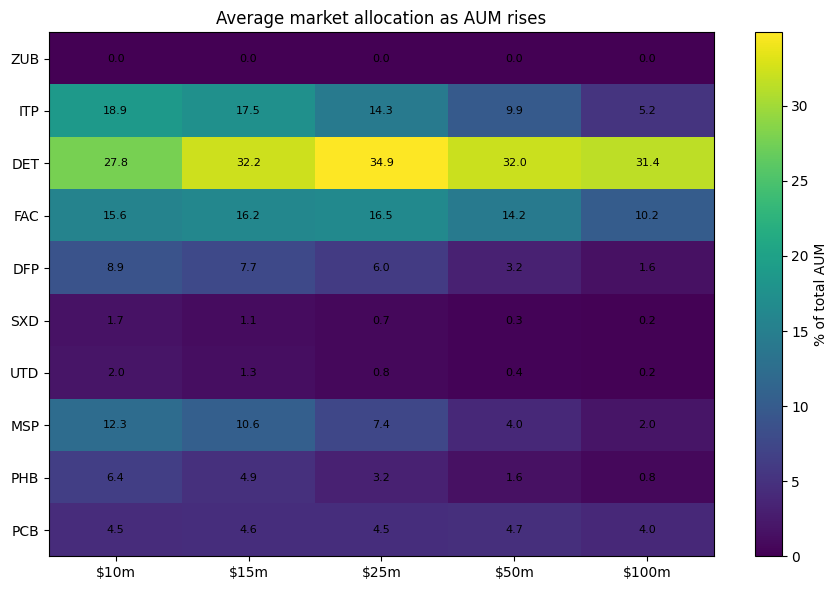

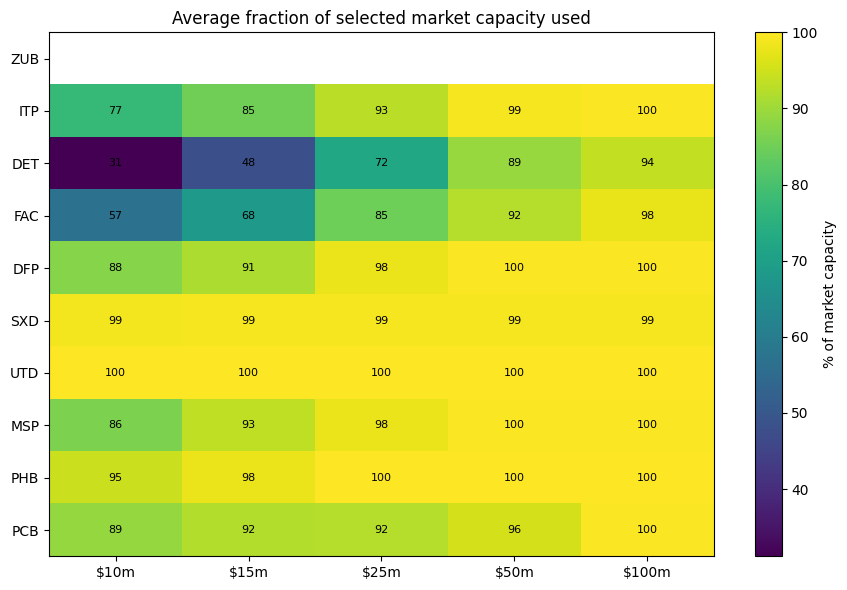

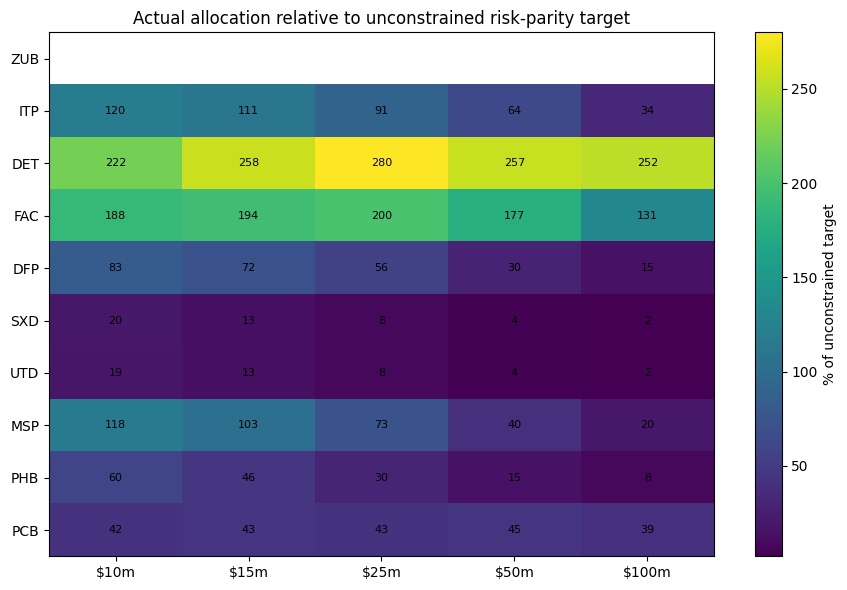

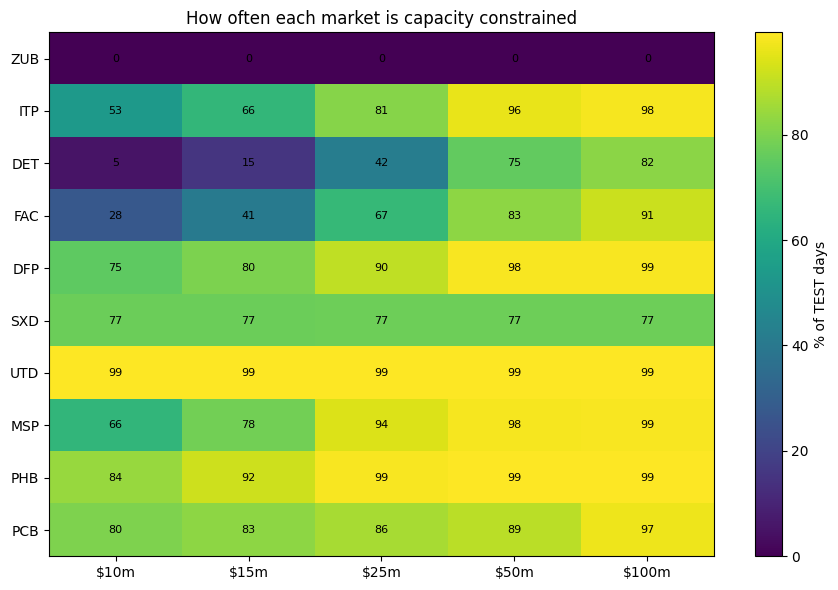

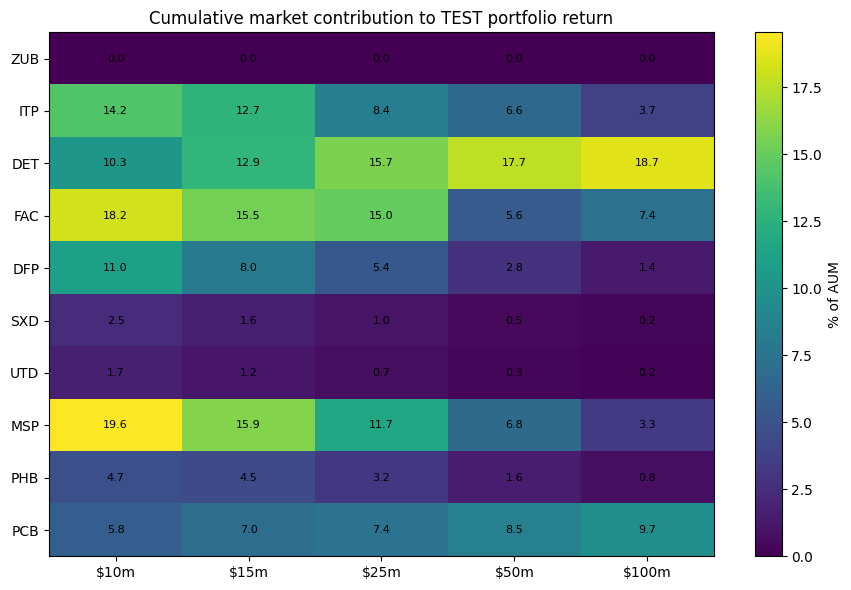

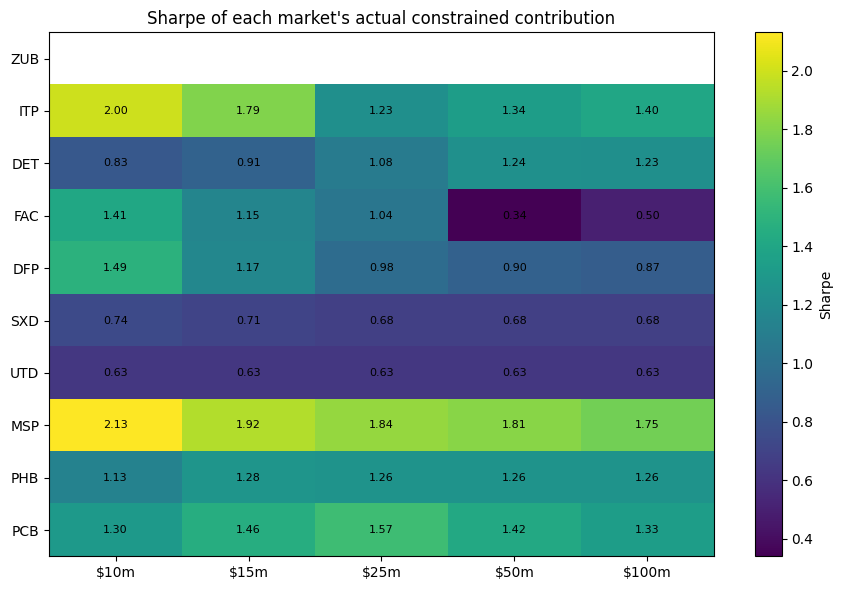

In [81]:
# ============================================================
# HEATMAP HELPER
# ============================================================

def plot_liquidity_heatmap(
    df,
    title,
    fmt=".1f",
    scale=1.0,
    colorbar_label=None,
):

    z = df.astype(float) * scale

    fig, ax = plt.subplots(
        figsize=(9, 6)
    )

    im = ax.imshow(
        z.values,
        aspect="auto",
    )

    ax.set_xticks(
        range(len(z.columns))
    )
    ax.set_xticklabels(
        z.columns
    )

    ax.set_yticks(
        range(len(z.index))
    )
    ax.set_yticklabels(
        z.index
    )

    for i in range(len(z.index)):
        for j in range(len(z.columns)):

            x = z.iloc[i, j]

            if np.isfinite(x):

                ax.text(
                    j,
                    i,
                    format(x, fmt),
                    ha="center",
                    va="center",
                    fontsize=8,
                )

    ax.set_title(title)

    plt.colorbar(
        im,
        ax=ax,
        label=colorbar_label,
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 1. ACTUAL AUM ALLOCATION
# ------------------------------------------------------------

plot_liquidity_heatmap(
    mean_alloc,
    "Average market allocation as AUM rises",
    scale=100,
    fmt=".1f",
    colorbar_label="% of total AUM",
)


# ------------------------------------------------------------
# 2. CAPACITY UTILISATION
# ------------------------------------------------------------

plot_liquidity_heatmap(
    capacity_utilisation,
    "Average fraction of selected market capacity used",
    scale=100,
    fmt=".0f",
    colorbar_label="% of market capacity",
)


# ------------------------------------------------------------
# 3. TARGET FILL
# ------------------------------------------------------------

plot_liquidity_heatmap(
    target_fill,
    "Actual allocation relative to unconstrained risk-parity target",
    scale=100,
    fmt=".0f",
    colorbar_label="% of unconstrained target",
)


# ------------------------------------------------------------
# 4. CAPPED-DAY FREQUENCY
# ------------------------------------------------------------

plot_liquidity_heatmap(
    capped_frequency,
    "How often each market is capacity constrained",
    scale=100,
    fmt=".0f",
    colorbar_label="% of TEST days",
)


# ------------------------------------------------------------
# 5. CUMULATIVE P&L CONTRIBUTION
# ------------------------------------------------------------

plot_liquidity_heatmap(
    cum_contribution,
    "Cumulative market contribution to TEST portfolio return",
    scale=100,
    fmt=".1f",
    colorbar_label="% of AUM",
)


# ------------------------------------------------------------
# 6. ACTUAL ASSET SHARPE
# ------------------------------------------------------------

plot_liquidity_heatmap(
    asset_sharpe,
    "Sharpe of each market's actual constrained contribution",
    scale=1,
    fmt=".2f",
    colorbar_label="Sharpe",
)

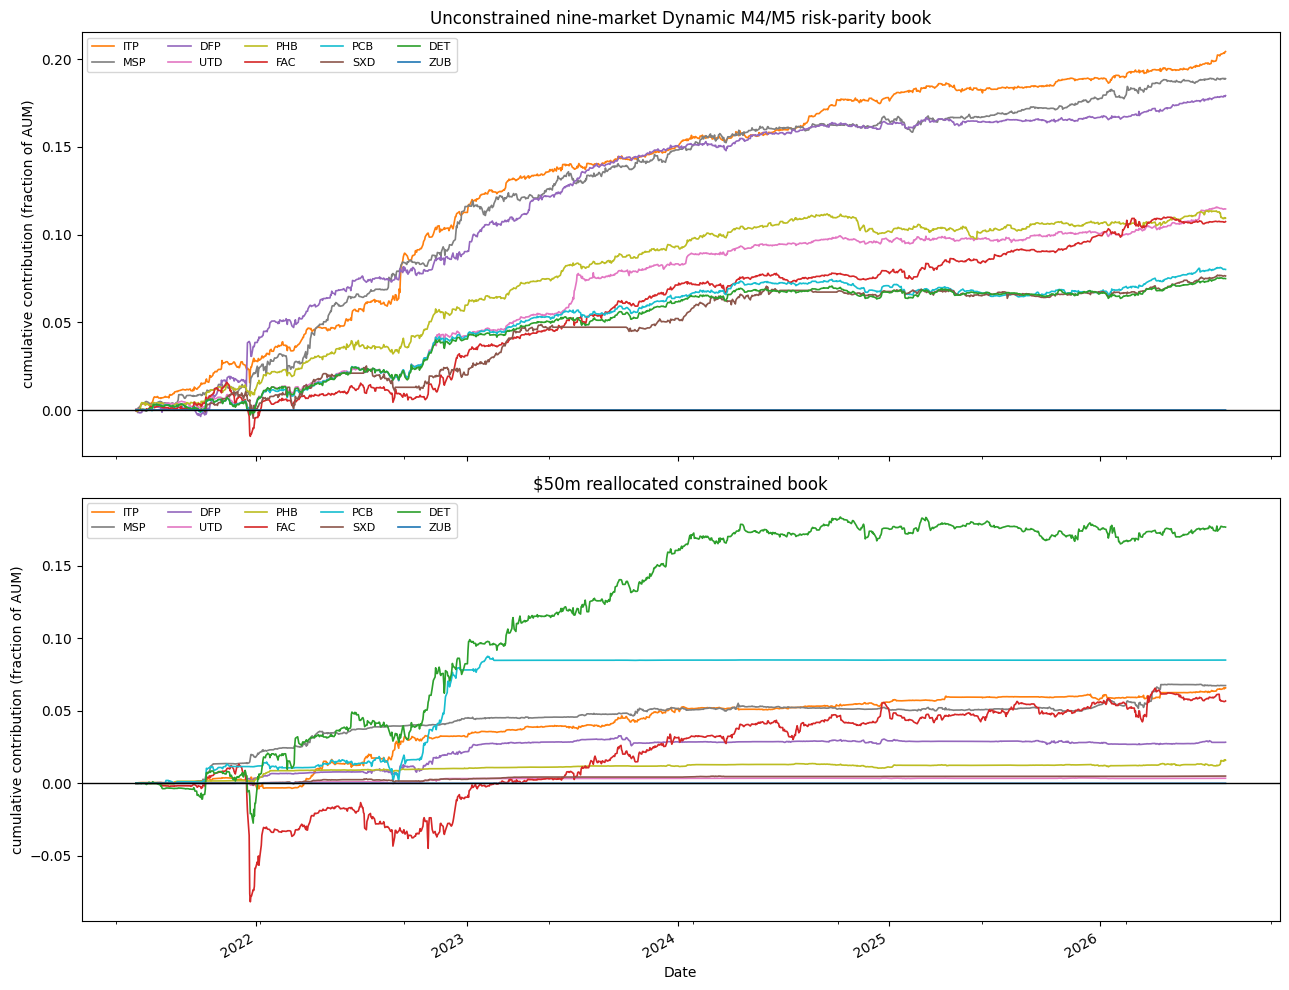

UNCONSTRAINED NINE-MARKET BOOK, cumulative contribution (% of AUM)


ITP    20.4
MSP    18.9
DFP    17.9
UTD    11.5
PHB    10.9
FAC    10.7
PCB     8.0
SXD     7.6
DET     7.5
ZUB     0.0
Name: % of AUM, dtype: float64

Total TEST gross return, unconstrained nine-market book: 113.55%

$50m REALLOCATED CONSTRAINED BOOK, cumulative contribution (% of AUM)


DET    17.7
PCB     8.5
MSP     6.7
ITP     6.6
FAC     5.7
DFP     2.8
PHB     1.6
SXD     0.5
UTD     0.3
ZUB     0.0
Name: % of AUM, dtype: float64

Total TEST gross return, $50m reallocated constrained book: 50.43%


In [82]:
# ============================================================
# FIGURE 16 REBUILD (paper Section 7.6): PER-MARKET CUMULATIVE CONTRIBUTION
# Unconstrained nine-market book (upper) vs $50m reallocated constrained
# book (lower).
#
# CORRECTED on two counts:
#  1. The constrained panel must be the 9-market renormalized reallocated
#     target (capacity_mode_books), not the 10-market liquidity_books
#     object -- on the wrong target the $50m per-market shares summed to
#     51.57% of AUM instead of the 50.43% Table 9/11 quotes.
#  2. Each market keeps the SAME color in both panels (fixed by
#     MARKET_COLORS), so a market can be tracked visually between the
#     unconstrained and constrained panel even though the two panels rank
#     markets differently.
# ============================================================

FIG16_AUM = 50e6

# Restrict to the exact valid TEST date set the canonical Sharpe/cumulative
# tables use (uncon_tradable_book["gross"]/capacity_mode_books[...]["gross"]
# dropna()'d), THEN fill remaining per-market NaNs with 0. Filling before
# restricting to valid dates would silently add dates the headline 113.55%/
# 50.43% totals do not include.
_uncon_valid = uncon_tradable_book["gross"].loc[LIQ_TEST].dropna().index
_mkt_uncon = uncon_tradable_book["market_gross"].loc[_uncon_valid].fillna(0.0)

_constrained_book = capacity_mode_books[(FIG16_AUM, "reallocated")]
_constrained_valid = _constrained_book["gross"].loc[LIQ_TEST].dropna().index
_mkt_constrained = _constrained_book["market_gross"].loc[_constrained_valid].fillna(0.0)

# Order is fixed from the unconstrained panel's ranking and reused, unchanged,
# for the constrained panel; color is fixed globally by MARKET_COLORS.
_fig16_order = _mkt_uncon.sum().sort_values(ascending=False).index

fig, ax = plt.subplots(2, 1, figsize=(13, 10), sharex=True)

for m in _fig16_order:
    _mkt_uncon[m].cumsum().plot(ax=ax[0], linewidth=1.2, label=m, color=MARKET_COLORS.get(m))
ax[0].axhline(0, color="black", linewidth=1)
ax[0].set_ylabel("cumulative contribution (fraction of AUM)")
ax[0].set_title("Unconstrained nine-market Dynamic M4/M5 risk-parity book")
ax[0].legend(loc="upper left", ncol=5, fontsize=8)

for m in _fig16_order:
    _mkt_constrained[m].cumsum().plot(ax=ax[1], linewidth=1.2, label=m, color=MARKET_COLORS.get(m))
ax[1].axhline(0, color="black", linewidth=1)
ax[1].set_ylabel("cumulative contribution (fraction of AUM)")
ax[1].set_title(f"${FIG16_AUM/1e6:.0f}m reallocated constrained book")
ax[1].legend(loc="upper left", ncol=5, fontsize=8)

plt.tight_layout()
plt.show()

# Reported as raw cumulative contribution, % of AUM (the paper's convention,
# matching the y-axis above) -- NOT normalized to the book's own total, so
# the market shares below sum to the book's total cumulative return, not 100%.
print("UNCONSTRAINED NINE-MARKET BOOK, cumulative contribution (% of AUM)")
_uc_sum = _mkt_uncon.sum()
display((100 * _uc_sum).round(1).sort_values(ascending=False).rename("% of AUM"))
print(f"Total TEST gross return, unconstrained nine-market book: {_uc_sum.sum():.2%}")

print(f"\n${FIG16_AUM/1e6:.0f}m REALLOCATED CONSTRAINED BOOK, cumulative contribution (% of AUM)")
_c_sum = _mkt_constrained.sum()
display((100 * _c_sum).round(1).sort_values(ascending=False).rename("% of AUM"))
print(f"Total TEST gross return, ${FIG16_AUM/1e6:.0f}m reallocated constrained book: {_c_sum.sum():.2%}")


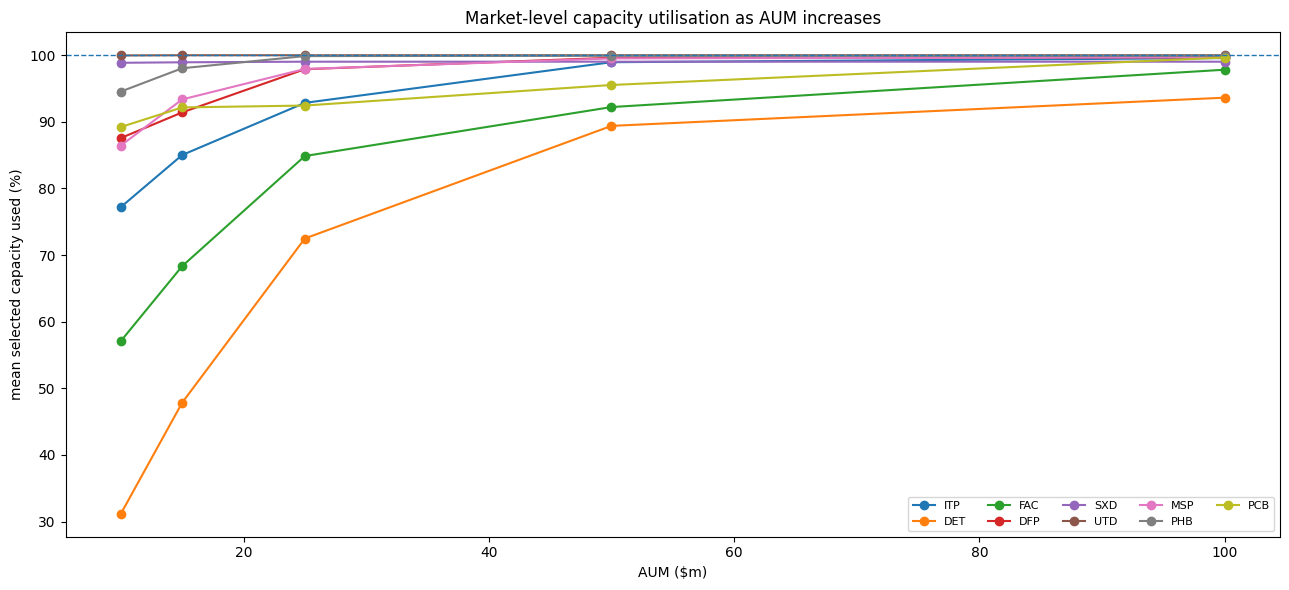

In [83]:
# ============================================================
# ASSET-LEVEL CAPACITY UTILISATION vs AUM
# ============================================================

plt.figure(figsize=(13, 6))

x = np.array([
    aum / 1e6
    for aum in LIQ_AUM_GRID
])

for market in TRADABLE_UNIVERSE:

    plt.plot(
        x,
        100 * capacity_utilisation.loc[market].values,
        marker="o",
        label=market,
    )

plt.axhline(100, linestyle="--", linewidth=1)

plt.xlabel("AUM ($m)")
plt.ylabel("mean selected capacity used (%)")
plt.title("Market-level capacity utilisation as AUM increases")

plt.legend(
    ncol=5,
    fontsize=8,
)

plt.tight_layout()
plt.show()

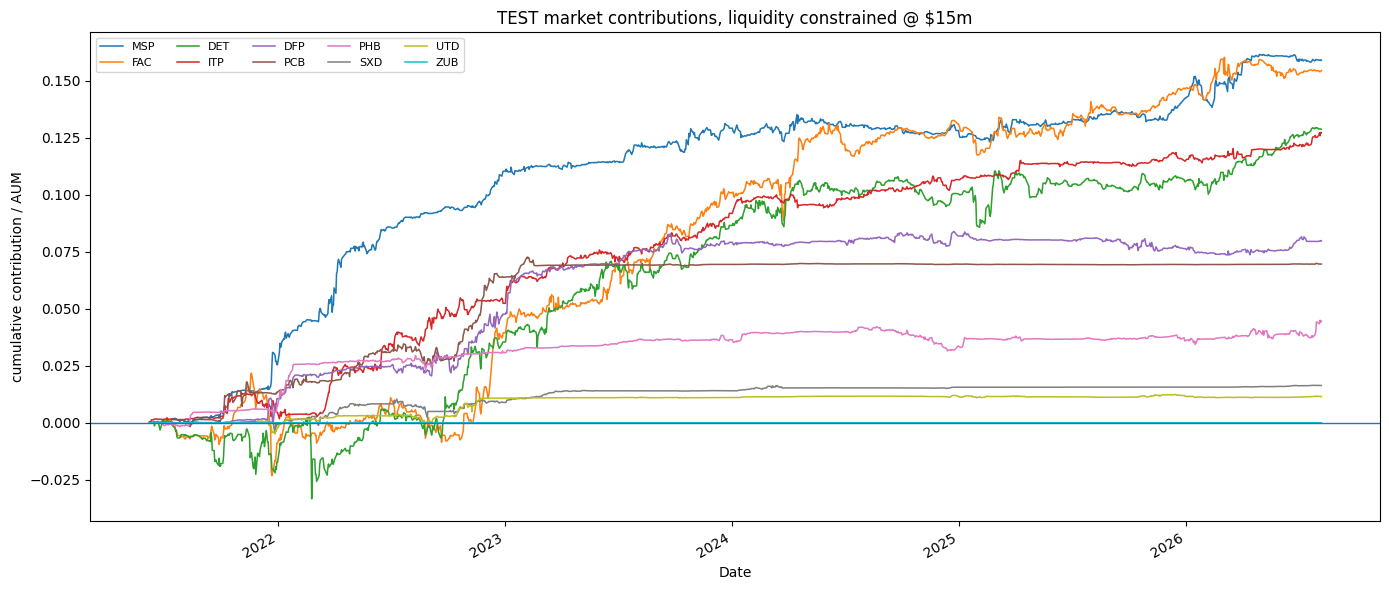

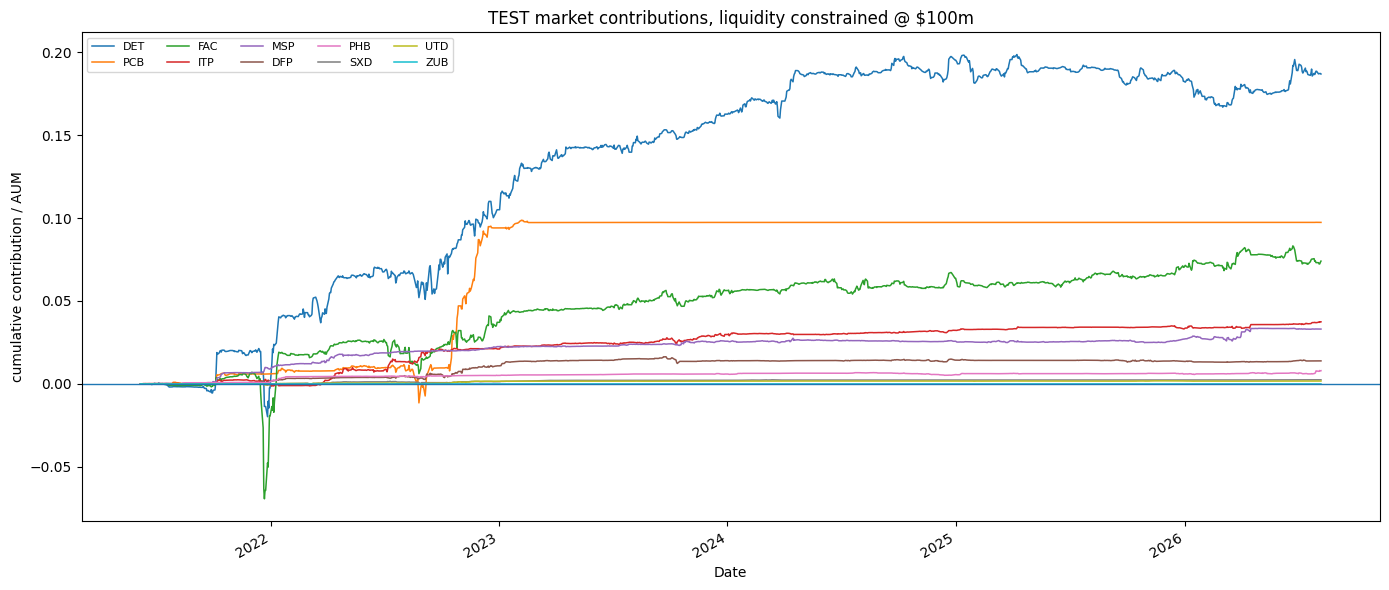

In [84]:
# ============================================================
# PER-MARKET CUMULATIVE CONTRIBUTION:
# $15m vs $100m
# ============================================================

for aum in [15e6, 100e6]:

    bk = liquidity_books[aum]

    mkt = (
        bk["market_gross"]
        .loc[LIQ_TEST]
        .fillna(0.0)
    )

    order = (
        mkt.sum()
        .sort_values(ascending=False)
        .index
    )

    plt.figure(figsize=(14, 6))

    for market in order:

        mkt[market].cumsum().plot(
            linewidth=1.1,
            label=market,
        )

    plt.axhline(0, linewidth=1)

    plt.ylabel("cumulative contribution / AUM")

    plt.title(
        f"TEST market contributions, liquidity constrained @ "
        f"${aum/1e6:.0f}m"
    )

    plt.legend(
        ncol=5,
        fontsize=8,
    )

    plt.tight_layout()
    plt.show()
    

In [85]:
# ============================================================
# 14.5 WHAT DEPTH DOES THE LIQUIDITY-AWARE RULE ACTUALLY TRADE?
# ============================================================

mix_rows = []
market_mix_rows = []

for aum in LIQ_AUM_GRID:
    bk = liquidity_books[aum]

    for period, sl in [
        ("TEST", slice(TEST_START, None)),
        ("latest 250", slice(RISK_INDEX[-250], None)),
    ]:
        s = bk["selected_depth"].loc[sl].stack().dropna().astype(int)
        vc = s.value_counts(normalize=True)
        mix_rows.append({
            "AUM $m": aum / 1e6,
            "period": period,
            "avg depth": s.mean(),
            **{f"M{d}": vc.get(d, 0.0) for d in DYNAMIC_DEPTHS},
        })

    if aum in (15e6, 25e6):
        for root in price_universe:
            s = (
                bk["selected_depth"][root]
                .loc[RISK_INDEX[-250]:]
                .dropna()
                .astype(int)
            )
            vc = s.value_counts(normalize=True)
            market_mix_rows.append({
                "AUM $m": aum / 1e6,
                "market": root,
                "avg depth": s.mean() if len(s) else np.nan,
                **{f"M{d}": vc.get(d, 0.0) for d in DYNAMIC_DEPTHS},
            })


dynamic_depth_mix = pd.DataFrame(mix_rows)
dynamic_depth_market_mix = pd.DataFrame(market_mix_rows)

print("DEPTH MIX")
display(dynamic_depth_mix.round(3))

print("\nLATEST-250 MARKET MIX AT $15m / $25m")
display(dynamic_depth_market_mix.round(3))


DEPTH MIX


,AUM $m,period,avg depth,M4,M5
0,10.0,TEST,4.249,0.751,0.249
1,10.0,latest 250,4.252,0.748,0.252
2,15.0,TEST,4.207,0.793,0.207
3,15.0,latest 250,4.206,0.794,0.206
4,25.0,TEST,4.174,0.826,0.174
5,25.0,latest 250,4.179,0.821,0.179
6,50.0,TEST,4.118,0.882,0.118
7,50.0,latest 250,4.117,0.883,0.117
8,100.0,TEST,4.056,0.944,0.056
9,100.0,latest 250,4.043,0.957,0.043



LATEST-250 MARKET MIX AT $15m / $25m


,AUM $m,market,avg depth,M4,M5
0,15.0,ZUB,NaN,0.000,0.000
1,15.0,ITP,4.016,0.984,0.016
2,15.0,DET,4.996,0.004,0.996
3,15.0,FAC,4.716,0.284,0.716
4,15.0,DFP,4.032,0.968,0.032
5,15.0,SXD,4.000,1.000,0.000
6,15.0,UTD,4.000,1.000,0.000
7,15.0,MSP,4.096,0.904,0.096
8,15.0,PHB,4.000,1.000,0.000
9,15.0,PCB,4.000,1.000,0.000


,gross Sharpe,turnover,break-even bps,utilisation,net@0,net@1,net@2,net@3,net@5,net@8,net@10,net@15
AUM $m,,,,,,,,,,,,
10.0,2.859,72.905,23.156,0.978,2.859,2.736,2.613,2.489,2.242,1.870,1.622,1.002
15.0,2.569,70.003,21.669,0.958,2.569,2.451,2.333,2.214,1.977,1.620,1.382,0.787
25.0,2.329,63.221,20.732,0.881,2.329,2.217,2.105,1.993,1.769,1.431,1.205,0.642
50.0,1.725,53.601,18.017,0.703,1.725,1.630,1.535,1.440,1.250,0.962,0.770,0.290
100.0,1.644,41.701,20.883,0.555,1.644,1.567,1.489,1.411,1.254,1.018,0.860,0.464


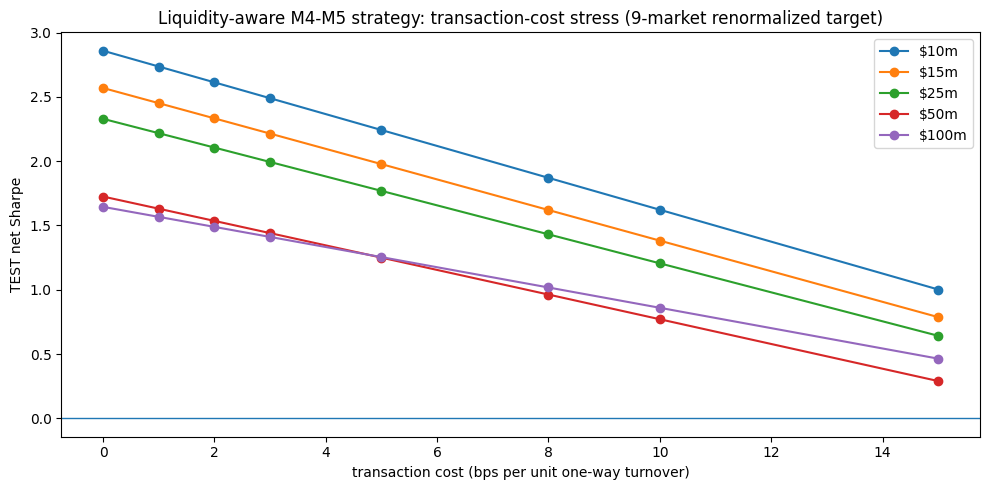

In [86]:
# ============================================================
# 14.6 TRANSACTION-COST STRESS: LIQUIDITY-AWARE DYNAMIC DEPTH
# ============================================================
# CORRECTED: this table is Chapter 8 of the paper (and Appendix C's cost x
# AUM grid), and Chapter 8 is specified on the 9-market renormalized target
# (the "selected" book), not the 10-market DYNAMIC_RISK_PARITY target. Use
# capacity_mode_books[(aum, "reallocated")] -- the same object Table 9/11
# and prod_book are built from -- at every AUM in the grid, so this table
# is internally consistent with the rest of the paper.
#
# The positions are fixed. Costs are applied to the exact contract-level
# turnover from the same position path. No turnover reconstruction.
# ============================================================

COST_GRID_DYNAMIC = [0, 1, 2, 3, 5, 8, 10, 15]

tc_rows = []
for aum in LIQ_AUM_GRID:
    bk = capacity_mode_books[(aum, "reallocated")]
    base = book_metrics(bk, period=PERIODS["TEST"], aum=aum, cost_bps=0.0)

    row = {
        "AUM $m": aum / 1e6,
        "gross Sharpe": base["Gross Sharpe"],
        "turnover": base["Annual turnover"],
        "break-even bps": base["Break-even bps"],
        "utilisation": base.get("Mean utilisation", np.nan),
    }

    for c in COST_GRID_DYNAMIC:
        row[f"net@{c}"] = book_metrics(
            bk, period=PERIODS["TEST"], aum=aum, cost_bps=c
        )["Net Sharpe"]

    tc_rows.append(row)


dynamic_tc_table = pd.DataFrame(tc_rows).set_index("AUM $m")
display(dynamic_tc_table.round(3))

plt.figure(figsize=(10, 5))
for aum in dynamic_tc_table.index:
    plt.plot(
        COST_GRID_DYNAMIC,
        [dynamic_tc_table.loc[aum, f"net@{c}"] for c in COST_GRID_DYNAMIC],
        marker="o",
        label=f"${aum:.0f}m",
    )
plt.axhline(0, linewidth=1)
plt.xlabel("transaction cost (bps per unit one-way turnover)")
plt.ylabel("TEST net Sharpe")
plt.title("Liquidity-aware M4-M5 strategy: transaction-cost stress (9-market renormalized target)")
plt.legend()
plt.tight_layout()
plt.show()


In [87]:
# ============================================================
# 15. PRODUCTION CANDIDATE: RAW RESIDUAL + LIQUIDITY-AWARE M4-M5
# ============================================================
# CORRECTED: production must be built on K_uncon_tradable (the 9-market
# renormalized risk-parity target used throughout Section 14.5b/7.3.1),
# not on the 10-market DYNAMIC_RISK_PARITY target. The two targets differ
# only in whether ZUB's uninvestable target share is left stranded in the
# denominator (Section 14.5b reconciliation), but that difference alone
# moved the quoted gross Sharpe from 2.569 to 2.643 and the cumulative
# return from 79.21% to 81.40% -- i.e. every figure/table built downstream
# of the OLD prod_book was not the book the paper's text describes as
# "selected". This cell, and everything from here on that reads
# `prod_book`, now uses the correct target at the correct 5 bps
# transaction-cost assumption used in Chapter 8 / Table 14 of the paper.
# ============================================================

PROD_AUM = 15e6
PROD_COST_BPS = 5.0
PROD_MODE = "liquidity_aware"
PROD_ALLOCATION = "reallocated"

prod_book = build_dynamic_depth_book(
    K_uncon_tradable,
    PROD_AUM,
    mode=PROD_MODE,
    cost_bps=PROD_COST_BPS,
    allocation=PROD_ALLOCATION,
)

# The cost parameter changes net P&L only; gross must reproduce the zero-TC
# 9-market renormalized reallocated book from Section 14.5b exactly.
assert np.allclose(
    prod_book["gross"].fillna(0.0),
    capacity_mode_books[(PROD_AUM, "reallocated")]["gross"].fillna(0.0),
), "prod_book must reproduce the 9-market renormalized reallocated book exactly"

prod_alloc = prod_book["alloc"]
prod_capped = prod_book["capped"]
prod_depth = prod_book["selected_depth"]
prod_gross = prod_book["gross"]
prod_turnover = prod_book["turnover"]
prod_net = prod_book["net"].dropna()
prod_util = prod_alloc.sum(axis=1)

# TEST only, so this reconciles directly against Table 14 of the paper
# rather than mixing in TRAIN-period performance under an unlabeled summary.
summary = book_metrics(prod_book, period=PERIODS["TEST"], aum=PROD_AUM)
summary = summary.rename({
    "N": "N days",
    "Net Mean": "Net return / AUM",
    "Net Vol": "Realised vol / AUM",
    "MaxDD (additive)": "Max drawdown (% AUM)",
})
summary = summary.rename({"Net Sharpe": f"Net Sharpe @{PROD_COST_BPS:g}bps"})

display(summary.to_frame("Dynamic depth production candidate, TEST only").round(4))


,"Dynamic depth production candidate, TEST only"
N days,1.316000e+03
Gross Sharpe,2.568700e+00
Net Sharpe @5bps,1.976800e+00
Net return / AUM,1.167000e-01
Realised vol / AUM,5.900000e-02
Max drawdown (% AUM),-5.840000e-02
Annual turnover,7.000280e+01
Break-even bps,2.166860e+01
AUM,1.500000e+07
Annual $ P&L,1.750271e+06


## 15.1–15.3 Additional identification diagnostics

These diagnostics answer three distinct questions without changing the production specification.

1. **Executed P&L by formation rank.** The production book is decomposed after dynamic M4/M5 selection, market allocation, roll flattening, specific-contract mapping and execution lag. Gross rank contributions must sum back to production gross P&L to numerical precision. This is an accounting attribution, not a counterfactual "remove one leg" strategy, which would destroy the hedge.
2. **Liquidity-aware long-power benchmark.** The benchmark is long M1 in every causally eligible market, equal-weighted subject to the same causal OI/DTV capacity framework, $15m AUM, specific-contract return mapping, roll-out rule, strict coverage and transaction-cost convention. It is designed to test whether residual-reversal returns are simply disguised long-power beta.
3. **Adaptive versus fixed fit lambda.** Production intentionally retains `LAMBDA_FIT=None`. The diagnostic refits the curve with `LAMBDA_FIT=LAMBDA_TRADE` and compares the canonical M1-M4 residual strategy. This isolates whether depth-adaptive fit lambda is mechanically manufacturing the signal; it does **not** re-select `LAMBDA_TRADE` and does not alter production.

All empirical values below are generated by code on the current data rather than frozen into markdown.

In [88]:
# ============================================================
# 15.1 EXACT EXECUTED P&L ATTRIBUTION BY FORMATION RANK
# ============================================================
# Attribute the ACTUAL production target path, not generic returns. Positions
# are mapped to specific contracts and lagged exactly as in run_contract_positions.
# The main production book has no partial-fill trade cap, so the formation rank
# of each contract position is uniquely attributable before any generic relabel.
# ============================================================

def executed_rank_attribution(book, weights_by_rank, depth_panel, *, max_rank=DYNAMIC_MAX_DEPTH):
    idx = RISK_INDEX
    rank_market_pnl = {
        k: pd.DataFrame(np.nan, index=idx, columns=price_universe, dtype=float)
        for k in range(1, max_rank + 1)
    }
    rank_market_turn = {
        k: pd.DataFrame(np.nan, index=idx, columns=price_universe, dtype=float)
        for k in range(1, max_rank + 1)
    }

    for root in price_universe:
        emap = execution_contract_map(prices, tickers, root, idx, max_rank)
        tk, labels, contracts, P = emap["tk"], emap["labels"], emap["contracts"], emap["P"]
        dep = depth_panel[root].reindex(idx)
        active = np.column_stack([dep.to_numpy(float) >= k for k in range(1, max_rank + 1)])
        W0 = np.column_stack([
            weights_by_rank[k][root].reindex(idx).to_numpy(float)
            for k in range(1, max_rank + 1)
        ])
        required_ok = (~active) | (np.isfinite(W0) & tk.notna().to_numpy())
        formed = dep.ge(DYNAMIC_MIN_DEPTH).fillna(False).to_numpy() & required_ok.all(axis=1)
        W = np.where(active, np.nan_to_num(W0, nan=0.0), 0.0)

        if ROLL_OUT_BUFFER:
            surv = surviving_legs(tickers, root, idx, ROLL_OUT_BUFFER, max_rank).to_numpy()
            roll_flat = formed & ~((~active) | surv).all(axis=1)
            W[roll_flat] = 0.0

        n, C = len(idx), len(contracts)
        labmat = labels.reshape(n, max_rank)
        pos_by_rank = {k: np.zeros((n, C)) for k in range(1, max_rank + 1)}

        for j, k in enumerate(range(1, max_rank + 1)):
            lab = labmat[:, j]
            wv = W[:, j]
            valid = (lab >= 0) & np.isfinite(wv) & (wv != 0) & formed
            rr = np.flatnonzero(valid)
            np.add.at(pos_by_rank[k], (rr, lab[valid]), wv[valid])

            raw = pos_by_rank[k].copy()
            pos_by_rank[k].fill(0.0)
            if LAG_BASE > 0:
                pos_by_rank[k][LAG_BASE:] = raw[:-LAG_BASE]
            else:
                pos_by_rank[k][:] = raw

        ret = np.full_like(P, np.nan)
        ret[1:] = P[1:] / P[:-1] - 1.0
        market_valid = book["market_gross"][root].notna().to_numpy()

        for k in range(1, max_rank + 1):
            pk = pos_by_rank[k]
            pnl = np.where(np.isfinite(ret), pk * ret, 0.0).sum(axis=1)
            turn = np.r_[np.abs(pk[0]).sum(), np.abs(np.diff(pk, axis=0)).sum(axis=1)]
            rank_market_pnl[k][root] = pd.Series(np.where(market_valid, pnl, np.nan), index=idx)

            # Match the canonical execution engine exactly at MARKET level:
            # turnover generated on an unmeasurable market date is carried to
            # the next measurable market-P&L date rather than discarded.
            charged = np.full(n, np.nan)
            bucket = 0.0
            for i in range(n):
                bucket += float(turn[i])
                if market_valid[i]:
                    charged[i] = bucket
                    bucket = 0.0
            rank_market_turn[k][root] = pd.Series(charged, index=idx)

    portfolio_ok = book["portfolio_complete"].reindex(idx).fillna(False)
    rank_pnl = {
        k: rank_market_pnl[k].sum(axis=1, min_count=1).where(portfolio_ok)
        for k in range(1, max_rank + 1)
    }

    # Match the canonical engine again at PORTFOLIO level.  A market-level
    # charged turnover that lands on an incomplete portfolio day must itself be
    # carried to the next valid portfolio day.  Do this separately by rank so
    # the rank shares are available on the exact date production TC is charged.
    rank_turn = {}
    for k in range(1, max_rank + 1):
        raw_rank_turn = rank_market_turn[k].sum(axis=1, min_count=1)
        charged_rank_turn = pd.Series(np.nan, index=idx, dtype=float)
        bucket = 0.0
        for i, dt in enumerate(idx):
            if np.isfinite(raw_rank_turn.iloc[i]):
                bucket += float(raw_rank_turn.iloc[i])
            if bool(portfolio_ok.iloc[i]) and np.isfinite(book["gross"].reindex(idx).iloc[i]):
                charged_rank_turn.iloc[i] = bucket
                bucket = 0.0
        rank_turn[k] = charged_rank_turn

    gross_reconstructed = sum(rank_pnl.values())
    recon_err = (gross_reconstructed - book["gross"].reindex(idx)).abs().dropna().max()
    assert recon_err < 1e-12, f"rank P&L does not reconstruct production gross: {recon_err:.3e}"

    # Net P&L by rank needs an accounting convention because turnover can net
    # across generic-rank relabels of the same specific contract. Allocate the
    # ACTUAL portfolio TC pro-rata to rank turnover each day; this reconciles
    # exactly to production net P&L and is reported explicitly as an allocation.
    total_turn = book["turnover"].reindex(idx)
    rank_turn_sum = sum(x.fillna(0.0) for x in rank_turn.values())

    # If production charges turnover, there must be some rank-level turnover
    # available to allocate that cost.  This is the invariant the old code
    # violated by dropping turnover on missing-mark dates.
    bad_cost_dates = total_turn.fillna(0.0).gt(1e-14) & rank_turn_sum.le(1e-14)
    assert not bad_cost_dates.any(), (
        "Production turnover exists on dates with zero attributable rank turnover: "
        f"{bad_cost_dates[bad_cost_dates].index.tolist()}"
    )

    rank_cost, rank_net = {}, {}
    for k in range(1, max_rank + 1):
        cost_share = (rank_turn[k].fillna(0.0) / rank_turn_sum.replace(0.0, np.nan)).fillna(0.0)
        rank_cost[k] = (PROD_COST_BPS / 1e4) * total_turn * cost_share
        rank_net[k] = rank_pnl[k] - rank_cost[k]

    actual_cost = (PROD_COST_BPS / 1e4) * total_turn
    allocated_cost = sum(rank_cost.values())
    cost_err = (allocated_cost - actual_cost).abs().dropna().max()
    assert cost_err < 1e-12, f"rank TC allocation does not reconstruct production cost: {cost_err:.3e}"

    net_err = (sum(rank_net.values()) - book["net"].reindex(idx)).abs().dropna().max()
    assert net_err < 1e-12, f"rank net attribution does not reconstruct production net: {net_err:.3e}"

    return rank_market_pnl, rank_market_turn, rank_pnl, rank_turn, rank_net


(rank_market_pnl, rank_market_turn, rank_pnl, rank_turn, rank_net) = executed_rank_attribution(
    prod_book, prod_book["final_weights"], prod_book["selected_depth"]
)

_leg_rows = []
_test_gross_sum = prod_book["gross"].loc[TEST_START:].sum()
for k in range(1, DYNAMIC_MAX_DEPTH + 1):
    pnl = rank_pnl[k].loc[TEST_START:].dropna()
    net = rank_net[k].loc[TEST_START:].dropna()
    exposure = pd.concat(
        [prod_book["final_weights"][k][m].abs() for m in price_universe], axis=1
    ).sum(axis=1).loc[TEST_START:]
    mean_exp = exposure.mean()
    ann_gross = pnl.mean() * TRADING_DAYS
    _leg_rows.append({
        "Rank": f"M{k}",
        "Gross P&L share": pnl.sum() / _test_gross_sum,
        "Ann gross contribution": ann_gross,
        "Ann net contribution*": net.mean() * TRADING_DAYS,
        "Mean abs portfolio weight": mean_exp,
        "Gross return / unit exposure": ann_gross / mean_exp if mean_exp > 0 else np.nan,
        "Annualized rank turnover": rank_turn[k].loc[TEST_START:].mean() * TRADING_DAYS,
    })

leg_attribution_test = pd.DataFrame(_leg_rows).set_index("Rank")
print("TEST executed P&L attribution by formation rank")
print("* net rank contribution allocates actual portfolio TC pro-rata to rank turnover")
display(leg_attribution_test.round(4))

print("\nTEST gross P&L contribution by market and rank")
_rank_market_test = pd.DataFrame({
    f"M{k}": rank_market_pnl[k].loc[TEST_START:].sum(axis=0)
    for k in range(1, DYNAMIC_MAX_DEPTH + 1)
})
display(_rank_market_test.round(4))

print("\nReconciliation checks")
print(f"  max |sum rank gross - production gross| = "
      f"{(sum(rank_pnl.values()) - prod_book['gross']).abs().dropna().max():.3e}")
print(f"  max |sum rank net   - production net|   = "
      f"{(sum(rank_net.values()) - prod_book['net']).abs().dropna().max():.3e}")

TEST executed P&L attribution by formation rank
* net rank contribution allocates actual portfolio TC pro-rata to rank turnover


,Gross P&L share,Ann gross contribution,Ann net contribution*,Mean abs portfolio weight,Gross return / unit exposure,Annualized rank turnover
Rank,,,,,,
M1,0.0843,0.0128,0.0113,0.0405,0.3156,3.0703
M2,-0.0579,-0.0088,-0.0171,0.2195,-0.0400,16.5328
M3,0.9106,0.1381,0.1254,0.3459,0.3993,25.5463
M4,-0.2283,-0.0346,-0.0437,0.2599,-0.1333,18.0718
M5,0.2913,0.0442,0.0408,0.0922,0.4793,6.7816



TEST gross P&L contribution by market and rank


,M1,M2,M3,M4,M5
ZUB,0.0000,0.0000,0.0000,0.0000,0.0000
ITP,0.0141,-0.0533,0.1481,0.0209,-0.0026
DET,0.0112,-0.0881,0.2064,-0.0602,0.0594
FAC,0.0207,0.0549,0.0048,-0.0302,0.1043
DFP,0.0061,-0.0312,0.1496,-0.0442,-0.0003
SXD,0.0014,0.0102,0.0039,0.0008,0.0000
UTD,0.0011,-0.0044,0.0261,-0.0113,0.0000
MSP,0.0095,0.0372,0.0639,0.0377,0.0107
PHB,-0.0017,0.0190,0.0290,-0.0016,0.0000
PCB,0.0043,0.0107,0.0863,-0.0909,0.0593



Reconciliation checks
  max |sum rank gross - production gross| = 2.407e-17
  max |sum rank net   - production net|   = 2.862e-17


## 15.1b Leg-regime investigation

The aggregate TRAIN/TEST leg attribution can hide rotation through time. This section therefore separates four questions without changing the production strategy:

1. **Time stability:** annual and rolling 252-day gross contribution by formation rank.
2. **Exposure versus payoff:** contribution per unit of average absolute rank exposure. A leg can dominate because the book owns more of it or because each unit earns more.
3. **Dynamic-depth interaction:** attribution conditional on the executed market being in the M4 or M5 state. This tests whether a change in leg attribution is merely caused by switching to the two-dimensional M5 residual.
4. **Structural-break evidence:** an exploratory one-break scan on monthly `M3 - M4` contribution, with a circular block-bootstrap p-value that accounts for searching over the break date and for serial dependence.

The purpose is diagnostic. No leg is removed or reweighted based on these results.

Annualized gross contribution by formation rank


Rank,M1,M2,M3,M4,M5
Year,,,,,
2009,NaN,NaN,NaN,NaN,NaN
2010,NaN,NaN,NaN,NaN,NaN
2011,NaN,NaN,NaN,NaN,NaN
2012,NaN,NaN,NaN,NaN,NaN
2013,NaN,NaN,NaN,NaN,NaN
2014,-0.0002,-0.0076,0.0074,-0.0035,0.0000
2015,0.0006,-0.0030,-0.0033,0.0010,0.0000
2016,-0.0042,0.0613,-0.0487,0.0225,0.0000
2017,0.0113,-0.0220,0.0324,-0.0027,0.0000



Contribution per unit of average absolute rank exposure


Rank,M1,M2,M3,M4,M5
Year,,,,,
2009,NaN,NaN,NaN,NaN,NaN
2010,NaN,NaN,NaN,NaN,NaN
2011,NaN,NaN,NaN,NaN,NaN
2012,NaN,NaN,NaN,NaN,NaN
2013,NaN,NaN,NaN,NaN,NaN
2014,-0.477,-2.581,1.337,-1.257,NaN
2015,0.204,-0.197,-0.134,0.084,NaN
2016,-0.710,1.788,-0.847,0.848,NaN
2017,1.030,-0.383,0.359,-0.063,NaN



Number of markets with positive rank contribution


Rank,M1,M2,M3,M4,M5
Year,,,,,
2009,0,0,0,0,0
2010,0,0,0,0,0
2011,0,0,0,0,0
2012,0,0,0,0,0
2013,0,0,0,0,0
2014,0,0,1,0,0
2015,1,0,0,1,0
2016,0,2,0,2,0
2017,3,4,2,3,0


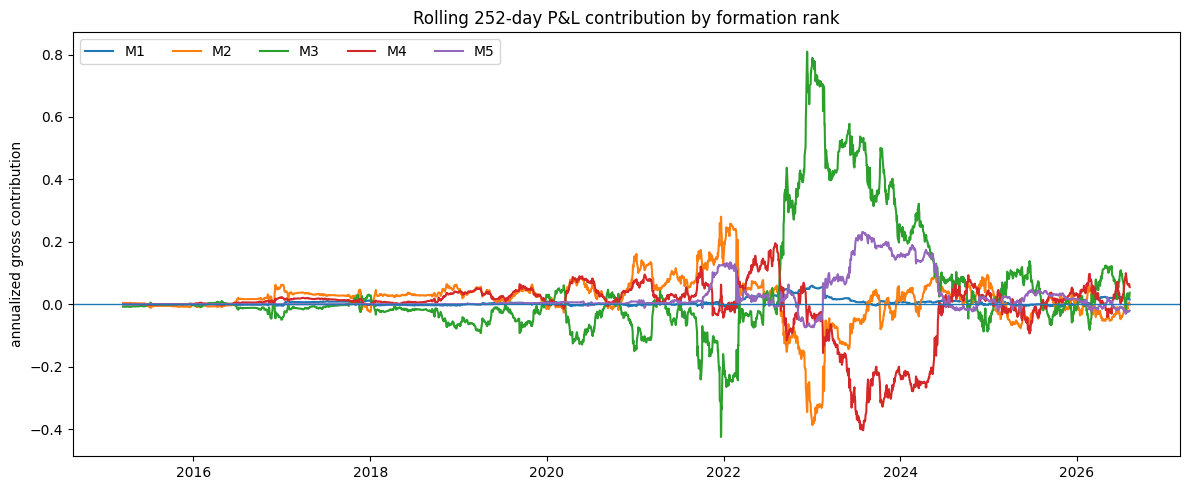


TRAIN FULL versus TEST: contribution, exposure and efficiency


Ann contribution            Mean abs exposure             \
Period             TEST TRAIN FULL              TEST TRAIN FULL   
Rank                                                              
M1               0.0128    -0.0005            0.0405     0.0343   
M2              -0.0088     0.0664            0.2194     0.1970   
M3               0.1381    -0.0452            0.3457     0.3264   
M4              -0.0346     0.0355            0.2597     0.1855   
M5               0.0442     0.0041            0.0922     0.0263   

       Contribution / exposure             
Period                    TEST TRAIN FULL  
Rank                                       
M1                      0.3158    -0.0149  
M2                     -0.0400     0.3372  
M3                      0.3996    -0.1385  
M4                     -0.1333     0.1915  
M5                      0.4794     0.1552


Market-level TRAIN FULL -> TEST change in annualized rank contribution


,M1 TRAIN FULL,M1 TEST,M1 delta,M2 TRAIN FULL,M2 TEST,M2 delta,M3 TRAIN FULL,M3 TEST,M3 delta,M4 TRAIN FULL,M4 TEST,M4 delta,M5 TRAIN FULL,M5 TEST,M5 delta
Market,,,,,,,,,,,,,,,
ZUB,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ITP,0.0018,0.0027,0.0009,0.0008,-0.0103,-0.0111,0.0048,0.0286,0.0239,0.0047,0.0040,-0.0006,0.0000,-0.0005,-0.0005
DET,-0.0027,0.0022,0.0048,0.0688,-0.0170,-0.0858,-0.0697,0.0399,0.1096,0.0270,-0.0116,-0.0386,0.0072,0.0115,0.0043
FAC,-0.0002,0.0040,0.0042,0.0008,0.0105,0.0097,0.0027,0.0009,-0.0018,0.0028,-0.0058,-0.0085,-0.0021,0.0199,0.0221
DFP,0.0001,0.0012,0.0011,-0.0016,-0.0060,-0.0044,0.0032,0.0289,0.0257,-0.0009,-0.0085,-0.0077,0.0000,-0.0001,-0.0001
SXD,-0.0001,0.0004,0.0004,0.0008,0.0025,0.0017,-0.0020,0.0010,0.0030,0.0010,0.0002,-0.0008,0.0000,0.0000,0.0000
UTD,0.0002,0.0002,-0.0000,-0.0045,-0.0008,0.0036,0.0039,0.0050,0.0011,-0.0023,-0.0022,0.0002,0.0000,0.0000,0.0000
MSP,-0.0001,0.0018,0.0019,0.0044,0.0072,0.0028,0.0023,0.0123,0.0100,0.0039,0.0073,0.0033,0.0000,0.0021,0.0021
PHB,0.0003,-0.0003,-0.0006,0.0035,0.0036,0.0001,0.0003,0.0055,0.0053,0.0035,-0.0003,-0.0038,0.0005,0.0000,-0.0005



Rank contribution conditional on executed M4 versus M5 state


...

Rank,M1,M2,M3,M4,M5
Period,,,,,
2021H2-2022,0.0306,-0.0914,0.3188,-0.0326,0.0357
POST 2022,0.0046,0.0363,0.0460,-0.0274,0.0485
PRE 2021H2,0.0016,0.0286,-0.0193,0.0176,0.0015



Subperiod contribution per unit exposure


Rank,M1,M2,M3,M4,M5
Period,,,,,
2021H2-2022,0.817,-0.419,0.912,-0.128,0.428
POST 2022,0.110,0.165,0.133,-0.104,0.497
PRE 2021H2,0.156,0.498,-0.203,0.345,0.369



Exploratory M3-M4 structural-break diagnostic


,value
candidate break after,2022-02-28 00:00:00
pre-break monthly M3-M4,-0.00667
post-break monthly M3-M4,0.022232
sup-F,5.628047
SSE reduction,0.037614
12m block-bootstrap p,0.0835


In [89]:
# ============================================================
# 15.1b LEG-REGIME INVESTIGATION
# ============================================================

# Aggregate daily rank P&L from the exact accounting attribution above.
_leg_daily = pd.DataFrame(
    {f"M{k}": rank_pnl[k] for k in range(1, DYNAMIC_MAX_DEPTH + 1)},
    index=RISK_INDEX,
)

# Execution-date absolute portfolio exposure by rank. `final_weights` lives on
# formation dates, while `rank_pnl` is realised on execution dates. Shift the
# exposure by the same canonical lag before forming contribution/exposure ratios.
# This keeps annual, subperiod and rolling efficiency diagnostics internally
# aligned with the P&L they divide.
_leg_exposure = pd.DataFrame(
    {
        f"M{k}": pd.concat(
            [prod_book["final_weights"][k][m].abs() for m in price_universe],
            axis=1,
        ).sum(axis=1).reindex(RISK_INDEX).shift(LAG_BASE)
        for k in range(1, DYNAMIC_MAX_DEPTH + 1)
    },
    index=RISK_INDEX,
)

# ------------------------------------------------------------
# A. Annual contribution / exposure / efficiency / breadth
# ------------------------------------------------------------
_leg_annual_rows = []
for year in sorted(pd.Index(RISK_INDEX.year).unique()):
    dates = RISK_INDEX[RISK_INDEX.year == year]
    if len(dates) < 50:
        continue
    total_pnl = prod_book["gross"].reindex(dates).sum(skipna=True)

    for k in range(1, DYNAMIC_MAX_DEPTH + 1):
        pnl = rank_pnl[k].reindex(dates).dropna()
        exp = _leg_exposure[f"M{k}"].reindex(dates).dropna()

        market_ann = []
        for m in price_universe:
            x = rank_market_pnl[k][m].reindex(dates).dropna()
            if len(x) >= 20:
                market_ann.append(x.mean() * TRADING_DAYS)

        ann = pnl.mean() * TRADING_DAYS if len(pnl) else np.nan
        mean_exp = exp.mean() if len(exp) else np.nan
        _leg_annual_rows.append({
            "Year": year,
            "Rank": f"M{k}",
            "Ann gross contribution": ann,
            "P&L share": pnl.sum() / total_pnl if total_pnl != 0 else np.nan,
            "Mean abs exposure": mean_exp,
            "Contribution / exposure": ann / mean_exp if mean_exp and mean_exp > 0 else np.nan,
            "Markets positive": int(np.sum(np.asarray(market_ann) > 0)) if market_ann else 0,
            "Markets observed": len(market_ann),
        })

leg_regime_annual = pd.DataFrame(_leg_annual_rows)
leg_regime_contrib = leg_regime_annual.pivot(
    index="Year", columns="Rank", values="Ann gross contribution"
)
leg_regime_efficiency = leg_regime_annual.pivot(
    index="Year", columns="Rank", values="Contribution / exposure"
)
leg_regime_breadth = leg_regime_annual.pivot(
    index="Year", columns="Rank", values="Markets positive"
)

print("Annualized gross contribution by formation rank")
display(leg_regime_contrib.round(4))
print("\nContribution per unit of average absolute rank exposure")
display(leg_regime_efficiency.round(3))
print("\nNumber of markets with positive rank contribution")
display(leg_regime_breadth)

# Rolling view makes clear whether TRAIN/TEST averages hide temporary episodes.
leg_regime_rolling252 = _leg_daily.rolling(252, min_periods=180).mean() * TRADING_DAYS
leg_regime_rolling_efficiency = leg_regime_rolling252 / _leg_exposure.rolling(
    252, min_periods=180
).mean().replace(0.0, np.nan)

plt.figure(figsize=(12, 5))
for c in leg_regime_rolling252.columns:
    plt.plot(leg_regime_rolling252.index, leg_regime_rolling252[c], label=c)
plt.axhline(0.0, linewidth=1)
plt.ylabel("annualized gross contribution")
plt.title("Rolling 252-day P&L contribution by formation rank")
plt.legend(ncol=5)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# B. TRAIN FULL -> TEST: exposure versus per-unit payoff
# ------------------------------------------------------------
_leg_period_rows = []
for period_name, sl in {
    "TRAIN FULL": PERIODS["TRAIN FULL"],
    "TEST": PERIODS["TEST"],
}.items():
    for k in range(1, DYNAMIC_MAX_DEPTH + 1):
        pnl = rank_pnl[k].loc[sl].dropna()
        exp = _leg_exposure[f"M{k}"].loc[sl].dropna()
        ann = pnl.mean() * TRADING_DAYS
        mean_exp = exp.mean()
        _leg_period_rows.append({
            "Period": period_name,
            "Rank": f"M{k}",
            "Ann contribution": ann,
            "Mean abs exposure": mean_exp,
            "Contribution / exposure": ann / mean_exp if mean_exp > 0 else np.nan,
        })
leg_train_test_decomposition = pd.DataFrame(_leg_period_rows)
print("\nTRAIN FULL versus TEST: contribution, exposure and efficiency")
display(
    leg_train_test_decomposition.pivot(
        index="Rank", columns="Period",
        values=["Ann contribution", "Mean abs exposure", "Contribution / exposure"],
    ).round(4)
)

# Market-level breadth of the change.
_market_shift_rows = []
for m in price_universe:
    row = {"Market": m}
    for k in range(1, DYNAMIC_MAX_DEPTH + 1):
        a = rank_market_pnl[k][m].loc[PERIODS["TRAIN FULL"]].dropna()
        b = rank_market_pnl[k][m].loc[PERIODS["TEST"]].dropna()
        train_ann = a.mean() * TRADING_DAYS if len(a) else np.nan
        test_ann = b.mean() * TRADING_DAYS if len(b) else np.nan
        row[f"M{k} TRAIN FULL"] = train_ann
        row[f"M{k} TEST"] = test_ann
        row[f"M{k} delta"] = test_ann - train_ann
    _market_shift_rows.append(row)
leg_market_shift = pd.DataFrame(_market_shift_rows).set_index("Market")
print("\nMarket-level TRAIN FULL -> TEST change in annualized rank contribution")
display(leg_market_shift.round(4))

# ------------------------------------------------------------
# C. Is the leg rotation just a consequence of M5 becoming active?
# ------------------------------------------------------------
_depth_state_rows = []
for period_name, sl in {
    "TRAIN FULL": PERIODS["TRAIN FULL"],
    "TEST": PERIODS["TEST"],
    "FULL": PERIODS["FULL"],
}.items():
    for state in [4, 5]:
        for k in range(1, DYNAMIC_MAX_DEPTH + 1):
            pieces = []
            for m in price_universe:
                # selected depth is a formation-date object; shift to execution date
                # to condition the realised P&L on the state actually being held.
                dep_exec = prod_book["selected_depth"][m].shift(LAG_BASE)
                mask = dep_exec.eq(state)
                x = rank_market_pnl[k][m].loc[sl].where(mask.loc[sl]).dropna()
                if len(x):
                    pieces.append(x)
            xx = pd.concat(pieces) if pieces else pd.Series(dtype=float)
            _depth_state_rows.append({
                "Period": period_name,
                "Executed depth": state,
                "Rank": f"M{k}",
                "N market-days": len(xx),
                "Ann contribution / market-day": xx.mean() * TRADING_DAYS if len(xx) else np.nan,
            })

leg_by_depth_state = pd.DataFrame(_depth_state_rows)
print("\nRank contribution conditional on executed M4 versus M5 state")
display(
    leg_by_depth_state.pivot_table(
        index=["Period", "Executed depth"],
        columns="Rank",
        values="Ann contribution / market-day",
    ).round(4)
)

# Causal M5 activation frequency through time.
_m5_activation = []
for year in sorted(pd.Index(RISK_INDEX.year).unique()):
    dates = RISK_INDEX[RISK_INDEX.year == year]
    held_states = []
    for m in price_universe:
        d = prod_book["selected_depth"][m].shift(LAG_BASE).reindex(dates)
        held_states.extend((d == 5).dropna().tolist())
    if held_states:
        _m5_activation.append({
            "Year": year,
            "M5-active market-day share": np.mean(held_states),
            "N": len(held_states),
        })
m5_activation_by_year = pd.DataFrame(_m5_activation).set_index("Year")
print("\nExecuted M5 activation rate")
display(m5_activation_by_year.round(4))

# ------------------------------------------------------------
# D. Crisis / post-crisis attribution
# ------------------------------------------------------------
_subperiods = {
    "PRE 2021H2": slice(None, pd.Timestamp("2021-06-30")),
    "2021H2-2022": slice(pd.Timestamp("2021-07-01"), pd.Timestamp("2022-12-31")),
    "POST 2022": slice(pd.Timestamp("2023-01-01"), None),
}
_sub_rows = []
for period_name, sl in _subperiods.items():
    for k in range(1, DYNAMIC_MAX_DEPTH + 1):
        x = rank_pnl[k].loc[sl].dropna()
        e = _leg_exposure[f"M{k}"].loc[sl].dropna()
        ann = x.mean() * TRADING_DAYS if len(x) else np.nan
        mean_exp = e.mean() if len(e) else np.nan
        _sub_rows.append({
            "Period": period_name,
            "Rank": f"M{k}",
            "Ann contribution": ann,
            "Mean exposure": mean_exp,
            "Contribution / exposure": ann / mean_exp if mean_exp and mean_exp > 0 else np.nan,
        })
leg_crisis_regime = pd.DataFrame(_sub_rows)
print("\nSubperiod rank contribution")
display(leg_crisis_regime.pivot(index="Period", columns="Rank", values="Ann contribution").round(4))
print("\nSubperiod contribution per unit exposure")
display(leg_crisis_regime.pivot(index="Period", columns="Rank", values="Contribution / exposure").round(3))

# ------------------------------------------------------------
# E. Exploratory one-break test on monthly M3-M4 contribution
# ------------------------------------------------------------
# Search over all break dates with at least 36 months on each side. The p-value
# is from a circular 12-month block bootstrap under a constant-mean null, and
# therefore accounts for both the break-date search and serial dependence.
_monthly_leg = _leg_daily.resample(MONTH_END).sum(min_count=10)
_break_series = (_monthly_leg["M3"] - _monthly_leg["M4"]).dropna()
_BREAK_MIN_MONTHS = 36
_BREAK_BOOTSTRAP_B = 1999
_BREAK_BLOCK = 12


def _sup_mean_break(x, min_segment=_BREAK_MIN_MONTHS):
    x = np.asarray(x, float)
    n = len(x)
    if n < 2 * min_segment + 1:
        return None
    c1 = np.concatenate([[0.0], np.cumsum(x)])
    c2 = np.concatenate([[0.0], np.cumsum(x * x)])
    ss0 = c2[n] - c1[n] ** 2 / n

    j = np.arange(min_segment, n - min_segment)      # break AFTER index j
    na, nb = j + 1, n - j - 1
    ssa = c2[na] - c1[na] ** 2 / na
    ssb = (c2[n] - c2[na]) - (c1[n] - c1[na]) ** 2 / nb
    ss = ssa + ssb
    F = (ss0 - ss) / (ss / max(n - 2, 1))

    i = int(np.argmax(F))
    jb, nab = int(j[i]), int(na[i])
    return (float(F[i]), jb,
            float(c1[nab] / nab),
            float((c1[n] - c1[nab]) / (n - nab)),
            float(1.0 - ss[i] / ss0))

_obs_break = _sup_mean_break(_break_series.to_numpy())
_rng = np.random.default_rng(20260831)
_centered = _break_series.to_numpy() - _break_series.mean()
_boot_stats = np.empty(_BREAK_BOOTSTRAP_B)
for b in range(_BREAK_BOOTSTRAP_B):
    vals = []
    while len(vals) < len(_centered):
        start = _rng.integers(0, len(_centered))
        ii = np.arange(start, start + _BREAK_BLOCK) % len(_centered)
        vals.extend(_centered[ii].tolist())
    xb = np.asarray(vals[:len(_centered)]) + _break_series.mean()
    _boot_stats[b] = _sup_mean_break(xb)[0]

_break_F, _break_j, _break_pre, _break_post, _break_sse_reduction = _obs_break
_break_p = (1 + np.sum(_boot_stats >= _break_F)) / (_BREAK_BOOTSTRAP_B + 1)
leg_break_diagnostic = pd.Series({
    "candidate break after": _break_series.index[_break_j],
    "pre-break monthly M3-M4": _break_pre,
    "post-break monthly M3-M4": _break_post,
    "sup-F": _break_F,
    "SSE reduction": _break_sse_reduction,
    "12m block-bootstrap p": _break_p,
})
print("\nExploratory M3-M4 structural-break diagnostic")
display(leg_break_diagnostic.to_frame("value"))


In [90]:
# ============================================================
# 15.2 LIQUIDITY-AWARE EQUAL-WEIGHT LONG-M1 POWER BENCHMARK
# ============================================================
# Equal weight is the target. Liquidity only caps markets that cannot carry
# their equal share; unused dollars are water-filled across eligible markets.
# The benchmark uses the SAME causal M1 OI/DTV capacity, specific-contract
# engine, lag, all-or-nothing roll rule, strict coverage and TC convention.
# ============================================================

# The benchmark is the opportunity cost of the production book, so it is held
# on the SAME tradable universe. `oi_notional_base` is only built for
# TRADABLE_UNIVERSE, and indexing it with price_universe raised KeyError.
BENCHMARK_UNIVERSE = TRADABLE_UNIVERSE

m1_benchmark_capacity = pd.DataFrame(
    {m: oi_notional_base[(m, 1)] for m in BENCHMARK_UNIVERSE},
    index=RISK_INDEX,
).shift(1)  # capacity information through t-1 only

m1_benchmark_eligible = m1_benchmark_capacity.notna() & pd.DataFrame(
    {
        m: prices[f"{m}1"].reindex(RISK_INDEX).notna()
           & tickers[f"{m}1"].reindex(RISK_INDEX).notna()
        for m in BENCHMARK_UNIVERSE
    },
    index=RISK_INDEX,
)

benchmark_alloc_dollars = pd.DataFrame(0.0, index=RISK_INDEX, columns=BENCHMARK_UNIVERSE)
benchmark_capped = pd.DataFrame(False, index=RISK_INDEX, columns=BENCHMARK_UNIVERSE)

for dt in RISK_INDEX:
    live = m1_benchmark_eligible.loc[dt].to_numpy(bool)
    target = np.where(live, 1.0, 0.0)  # equal-weight target across live markets
    caps = m1_benchmark_capacity.loc[dt].to_numpy(float)
    if live.any():
        a, c = water_fill(target, caps, PROD_AUM)
        benchmark_alloc_dollars.loc[dt] = a
        benchmark_capped.loc[dt] = c

benchmark_weights = {1: benchmark_alloc_dollars / PROD_AUM}
benchmark_depth = pd.DataFrame(
    np.where(m1_benchmark_eligible, 1.0, np.nan),
    index=RISK_INDEX,
    columns=BENCHMARK_UNIVERSE,
)

long_m1_benchmark = run_contract_positions(
    benchmark_weights,
    prices,
    tickers,
    BENCHMARK_UNIVERSE,
    index=RISK_INDEX,
    max_rank=1,
    depth_panel=benchmark_depth,
    min_depth=1,
    lag=LAG_BASE,
    cost_bps=PROD_COST_BPS,
    coverage_floor=1.0,
    ffill_limit=None,
    roll_out_buffer=ROLL_OUT_BUFFER,
    market_aggregation="sum",
)

_bench_rows = []
for name in ["FULL", "TRAIN", "TRAIN FULL", "TEST"]:
    sl = PERIODS[name]
    strat = prod_book["net"].loc[sl].dropna()
    bench = long_m1_benchmark["net"].loc[sl].dropna()
    j = strat.index.intersection(bench.index)
    _bench_rows.append({
        "Period": name,
        "Strategy Sharpe": sharpe(strat),
        "Long M1 Sharpe": sharpe(bench),
        "Long M1 ann return": bench.mean() * TRADING_DAYS,
        "Long M1 ann vol": bench.std(ddof=1) * np.sqrt(TRADING_DAYS),
        "Strategy / benchmark corr": strat.loc[j].corr(bench.loc[j]),
        "Long M1 mean utilisation": benchmark_alloc_dollars.loc[sl].sum(axis=1).mean() / PROD_AUM,
    })

long_m1_benchmark_table = pd.DataFrame(_bench_rows).set_index("Period")
print("Liquidity-aware equal-weight long-M1 benchmark")
display(long_m1_benchmark_table.round(4))

_crisis = slice(pd.Timestamp("2021-07-01"), pd.Timestamp("2022-12-31"))
_bench_test = long_m1_benchmark["net"].loc[TEST_START:].dropna()
_crisis_mask = (_bench_test.index >= pd.Timestamp("2021-07-01")) & (_bench_test.index <= pd.Timestamp("2022-12-31"))
long_m1_crisis = pd.DataFrame({
    "N": [len(_bench_test), (~_crisis_mask).sum(), _crisis_mask.sum()],
    "Sharpe": [
        sharpe(_bench_test),
        sharpe(_bench_test.loc[~_crisis_mask]),
        sharpe(_bench_test.loc[_crisis_mask]),
    ],
    "Ann return": [
        _bench_test.mean() * TRADING_DAYS,
        _bench_test.loc[~_crisis_mask].mean() * TRADING_DAYS,
        _bench_test.loc[_crisis_mask].mean() * TRADING_DAYS,
    ],
}, index=["TEST", "TEST ex 2021H2-2022", "2021H2-2022 only"])
print("\nLong-M1 benchmark crisis decomposition")
display(long_m1_crisis.round(4))

Liquidity-aware equal-weight long-M1 benchmark


,Strategy Sharpe,Long M1 Sharpe,Long M1 ann return,Long M1 ann vol,Strategy / benchmark corr,Long M1 mean utilisation
Period,,,,,,
FULL,1.4129,-0.3383,-0.0969,0.2864,-0.1694,0.6994
TRAIN,0.7380,-0.4583,-0.0938,0.2047,-0.1165,0.5705
TRAIN FULL,0.9351,-0.8523,-0.2359,0.2768,-0.1701,1.0000
TEST,1.9768,-0.2629,-0.1022,0.3885,-0.1895,1.0000



Long-M1 benchmark crisis decomposition


,N,Sharpe,Ann return
TEST,1324,-0.2629,-0.1022
TEST ex 2021H2-2022,935,0.2861,0.0907
2021H2-2022 only,389,-1.0848,-0.5656


In [91]:
# ============================================================
# 14.6b DAILY TRADE LIMIT: WHAT THE BACKTEST ASSUMES IT CAN EXECUTE
# ============================================================
#
# Two different constraints, and only the first is in the book above.
#
#   POSITION limit (14.2)   |position|       <= min(OI cap, DTV exit cap)
#   TRADE    limit (here)   |d position|/day <= PARTICIP x DTV
#
# The engine otherwise assumes requested trades can be filled. This table
# stress-tests that assumption by refilling the SAME target path under a
# daily participation cap, with partial fills.
#
# HOW TO READ IT. A measurement, not a constraint to adopt. Imposing it does
# not make money; it says the headline Sharpe assumes fills you may not get.
# Do not hard-cap live either: you can exceed a participation rate at a worse
# price, so a hard wall is wrong in the opposite direction to free fills. The
# realistic number sits between the top row and the row matching whatever
# participation you can actually achieve.
#
# The book CHASES the target rather than adding an undocumented smoothing
# overlay. Alternative smoothing rules should be evaluated as separate
# specifications rather than justified by stale backtest numbers.
# ============================================================

TRADE_PARTICIP_GRID = [0.25, 0.20, 0.15, 0.10, 0.05]
TRADE_ROLL_WINDOWS = [90, 60]


def dtv_daily_notional(window):
    """Prior-day dollar-volume estimate for a causal same-day trade limit."""
    out = {}
    for market in price_universe:
        for k in range(1, DYNAMIC_MAX_DEPTH + 1):
            col = f"{market}{k}"
            if col not in volume.columns or col not in prices.columns:
                continue
            d = causal_dtv_notional(col, RISK_INDEX, window)
            if d is None or not d.notna().any():
                continue
            # not-yet-eligible days get no cap rather than a zero cap
            out[(market, k)] = d.shift(1).fillna(np.inf)
    return out


_dtv_by_window = {w: dtv_daily_notional(w) for w in TRADE_ROLL_WINDOWS}

_specs = [("no trade limit", None, None)]
_specs += [(f"DTV90 @ {p:.0%}", 90, p) for p in TRADE_PARTICIP_GRID]
_specs += [(f"DTV60 @ {p:.0%}", 60, p) for p in [0.10]]

trade_rows = []
for label, window, particip in _specs:
    tc = (None if window is None
          else {k: particip * v for k, v in _dtv_by_window[window].items()})

    res = run_variable_depth_portfolio(
        prod_book["final_weights"],
        prod_book["selected_depth"],
        cost_bps=PROD_COST_BPS,
        trade_cap=tc,
        trade_aum=PROD_AUM,
    )

    row = {"spec": label}
    for name in ["TRAIN", "TRAIN FULL", "TEST"]:
        row[f"{name} Sharpe"] = sharpe(res["net"].loc[PERIODS[name]].dropna())
    row["TEST turn"] = res["turnover"].loc[PERIODS["TEST"]].mean() * TRADING_DAYS
    row["mean unfilled"] = res["unfilled"].loc[PERIODS["TEST"]].mean()
    row["p95 unfilled"] = res["unfilled"].loc[PERIODS["TEST"]].quantile(0.95)

    if window is None:
        assert (res["gross"].dropna() - prod_book["gross"].dropna()).abs().max() < 1e-12, \
            "trade-limit plumbing changed the unconstrained book"

    trade_rows.append(row)

trade_limit_table = pd.DataFrame(trade_rows).set_index("spec")
print(f"DAILY TRADE LIMIT, ${PROD_AUM/1e6:.0f}m production book")
print("control: trade_cap=None reproduces prod_book exactly (asserted)")
display(trade_limit_table.round(4))


DAILY TRADE LIMIT, $15m production book
control: trade_cap=None reproduces prod_book exactly (asserted)


,TRAIN Sharpe,TRAIN FULL Sharpe,TEST Sharpe,TEST turn,mean unfilled,p95 unfilled
spec,,,,,,
no trade limit,0.7380,0.9351,1.9768,70.0028,0.0000,0.0000
DTV90 @ 25%,0.2992,0.4320,1.8589,67.9548,0.0114,0.0705
DTV90 @ 20%,0.3686,0.4348,1.8284,67.2279,0.0158,0.0851
DTV90 @ 15%,0.4511,0.5864,1.7409,66.1064,0.0232,0.1161
DTV90 @ 10%,0.5860,0.7229,1.6352,64.1016,0.0384,0.1744
DTV90 @ 5%,0.8291,0.6743,1.5386,59.5469,0.0769,0.2798
DTV60 @ 10%,0.5404,0.7206,1.6262,64.1727,0.0386,0.1771


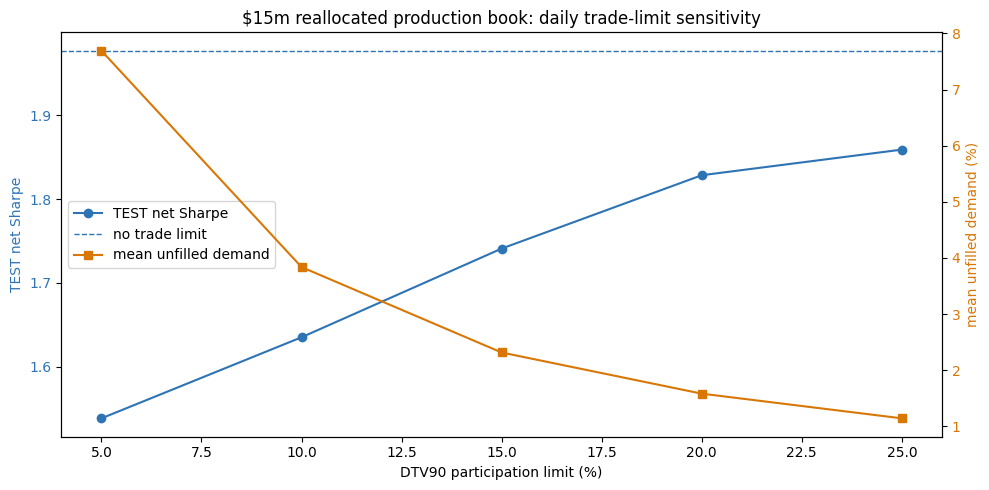

In [92]:
# ============================================================
# FIGURE A1 (paper Appendix A.1): DAILY TRADE-LIMIT SENSITIVITY
# ============================================================
# No plotting cell previously existed for this table in the notebook, so
# Appendix A.1's chart was not reproducible from executable code. Added here,
# built directly from trade_limit_table above (now correctly on the 9-market
# renormalized, 5 bps production book).
# ============================================================

_a1 = trade_limit_table.drop(index="no trade limit").copy()
_a1_x = [int(s.split("@")[1].strip().rstrip("%")) for s in _a1.index if "DTV90" in s]
_a1_dtv90 = _a1.loc[[s for s in _a1.index if "DTV90" in s]]

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(_a1_x, _a1_dtv90["TEST Sharpe"], marker="o", color="#2E74B5", label="TEST net Sharpe")
ax1.axhline(trade_limit_table.loc["no trade limit", "TEST Sharpe"], linestyle="--", linewidth=1,
            color="#2E74B5", label="no trade limit")
ax1.set_xlabel("DTV90 participation limit (%)")
ax1.set_ylabel("TEST net Sharpe", color="#2E74B5")
ax1.tick_params(axis="y", labelcolor="#2E74B5")

ax2 = ax1.twinx()
ax2.plot(_a1_x, 100 * _a1_dtv90["mean unfilled"], marker="s", color="#D97706", label="mean unfilled demand")
ax2.set_ylabel("mean unfilled demand (%)", color="#D97706")
ax2.tick_params(axis="y", labelcolor="#D97706")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center left")

plt.title(f"${PROD_AUM/1e6:.0f}m reallocated production book: daily trade-limit sensitivity")
plt.tight_layout()
plt.show()


In [93]:
# ============================================================
# 15.1 PRODUCTION CANDIDATE — TEST PERIOD ONLY
# ============================================================

summary_test = book_metrics(prod_book, period=PERIODS["TEST"], aum=PROD_AUM)
summary_test = summary_test.rename({
    "N": "N days",
    "Net Mean": "Net return / AUM",
    "Net Vol": "Realised vol / AUM",
    "MaxDD (additive)": "Max drawdown (% AUM)",
})
summary_test = summary_test.rename({"Net Sharpe": f"Net Sharpe @{PROD_COST_BPS:g}bps"})

display(summary_test.to_frame("Dynamic depth — TEST ONLY").round(4))


,Dynamic depth — TEST ONLY
N days,1.316000e+03
Gross Sharpe,2.568700e+00
Net Sharpe @5bps,1.976800e+00
Net return / AUM,1.167000e-01
Realised vol / AUM,5.900000e-02
Max drawdown (% AUM),-5.840000e-02
Annual turnover,7.000280e+01
Break-even bps,2.166860e+01
AUM,1.500000e+07
Annual $ P&L,1.750271e+06


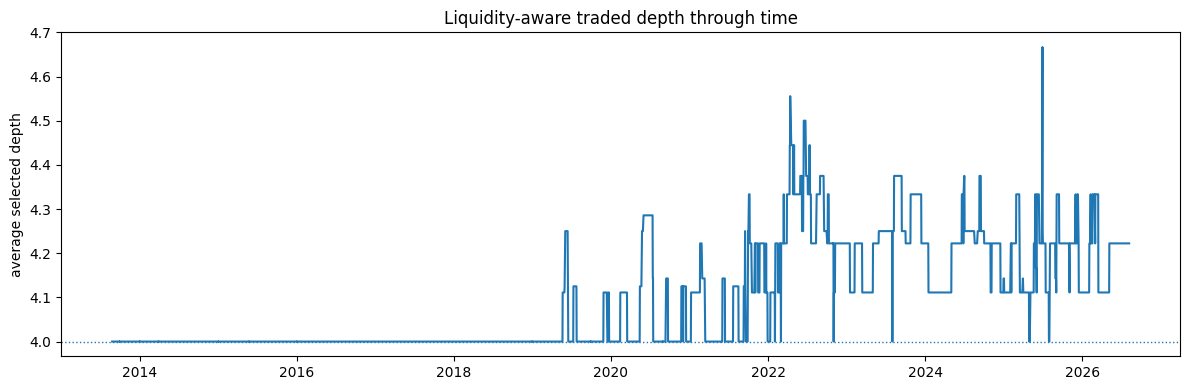

In [94]:
# ============================================================
# 15.2 PRODUCTION DEPTH THROUGH TIME
# ============================================================

avg_selected_depth = prod_depth.mean(axis=1, skipna=True)

plt.figure(figsize=(12, 4))
plt.plot(avg_selected_depth.index, avg_selected_depth, linewidth=1.5)
plt.axhline(4, linewidth=1, linestyle=":")
plt.ylabel("average selected depth")
plt.title("Liquidity-aware traded depth through time")
plt.tight_layout()
plt.show()


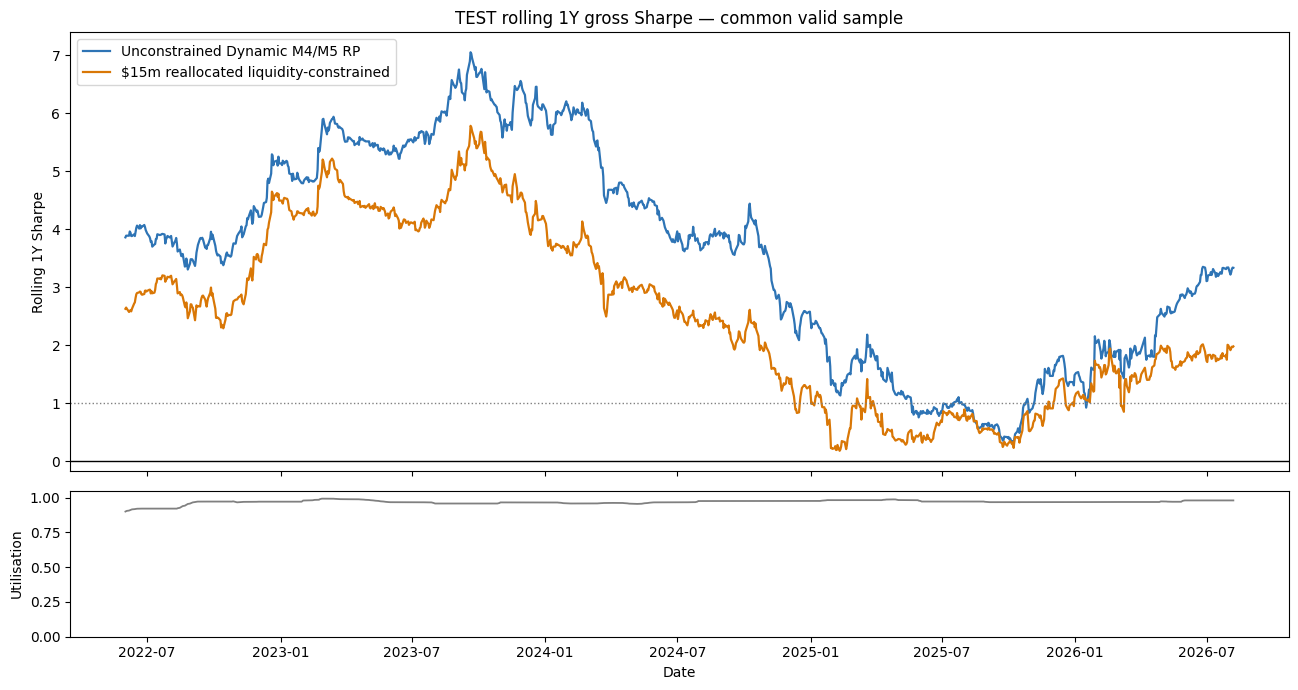

Common TEST returns: 2021-06-07 to 2026-08-07 (1316 observations)
Plotted rolling window: 2022-06-01 to 2026-08-07 (1065 observations)


,Unconstrained Dynamic M4/M5 RP,$15m reallocated liquidity-constrained
Date,,
2026-08-03,3.218,1.915
2026-08-04,3.256,1.958
2026-08-05,3.315,1.975
2026-08-06,3.339,1.966
2026-08-07,3.335,1.980


In [95]:
# ============================================================
# 15.2b CORRECTED ROLLING SHARPE COMPARISON
# ============================================================
# Apples-to-apples construction:
#   1. Same nine-market tradable universe.
#   2. Same Dynamic M4/M5 signals and risk-parity target.
#   3. Unconstrained book removes only the liquidity cap.
#   4. Reallocated book uses the $15m water-fill implementation.
#   5. TEST only, zero transaction costs, common valid dates.
#
# CORRECTED: the reallocated side must be the 9-market renormalized target
# (capacity_mode_books), matching Table 9/11 and prod_book -- not the
# 10-market liquidity_books object, which is a different, higher-Sharpe book.
# ============================================================

SHARPE_WINDOW = TRADING_DAYS

rolling_inputs = pd.concat(
    {
        "Unconstrained Dynamic M4/M5 RP": uncon_tradable_book["gross"],
        "$15m reallocated liquidity-constrained": capacity_mode_books[(PROD_AUM, "reallocated")]["gross"],
    },
    axis=1,
).loc[TEST_START:]

# Never let one book contribute observations when the other is unavailable.
rolling_inputs = rolling_inputs.dropna(how="any")

assert rolling_inputs.index.min() >= pd.Timestamp(TEST_START)
assert rolling_inputs.notna().all().all()
assert len(rolling_inputs) >= SHARPE_WINDOW
assert np.allclose(
    capacity_mode_books[(PROD_AUM, "reallocated")]["gross"].reindex(rolling_inputs.index),
    capacity_mode_books[(PROD_AUM, "reallocated")]["net"].reindex(rolling_inputs.index),
    equal_nan=False,
), "Section 14.5b liquidity comparison is required to be zero-TC."

rolling_sharpe_common = sharpe(
    rolling_inputs,
    window=SHARPE_WINDOW,
    min_periods=SHARPE_WINDOW,
).dropna(how="any")

utilisation_15m_common = (
    capacity_mode_books[(PROD_AUM, "reallocated")]["alloc"]
    .sum(axis=1)
    .reindex(rolling_inputs.index)
    .rolling(SHARPE_WINDOW, min_periods=SHARPE_WINDOW)
    .mean()
    .reindex(rolling_sharpe_common.index)
)

assert rolling_sharpe_common.notna().all().all()
assert utilisation_15m_common.notna().all()
assert rolling_sharpe_common.index.equals(utilisation_15m_common.index)

fig, ax = plt.subplots(
    2, 1,
    figsize=(13, 7),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)

colors = ["#2E74B5", "#D97706"]
for col, color in zip(rolling_sharpe_common.columns, colors):
    ax[0].plot(
        rolling_sharpe_common.index,
        rolling_sharpe_common[col],
        linewidth=1.6,
        label=col,
        color=color,
    )

ax[0].axhline(0, color="black", linewidth=1)
ax[0].axhline(1, color="grey", linestyle=":", linewidth=1)
ax[0].set_ylabel("Rolling 1Y Sharpe")
ax[0].set_title("TEST rolling 1Y gross Sharpe — common valid sample")
ax[0].legend(loc="upper left")

ax[1].plot(
    utilisation_15m_common.index,
    utilisation_15m_common,
    linewidth=1.3,
    color="grey",
)
ax[1].set_ylabel("Utilisation")
ax[1].set_ylim(0, 1.05)
ax[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

print(
    "Common TEST returns:",
    rolling_inputs.index.min().date(), "to", rolling_inputs.index.max().date(),
    f"({len(rolling_inputs)} observations)",
)
print(
    "Plotted rolling window:",
    rolling_sharpe_common.index.min().date(), "to", rolling_sharpe_common.index.max().date(),
    f"({len(rolling_sharpe_common)} observations)",
)
display(rolling_sharpe_common.tail().round(3))


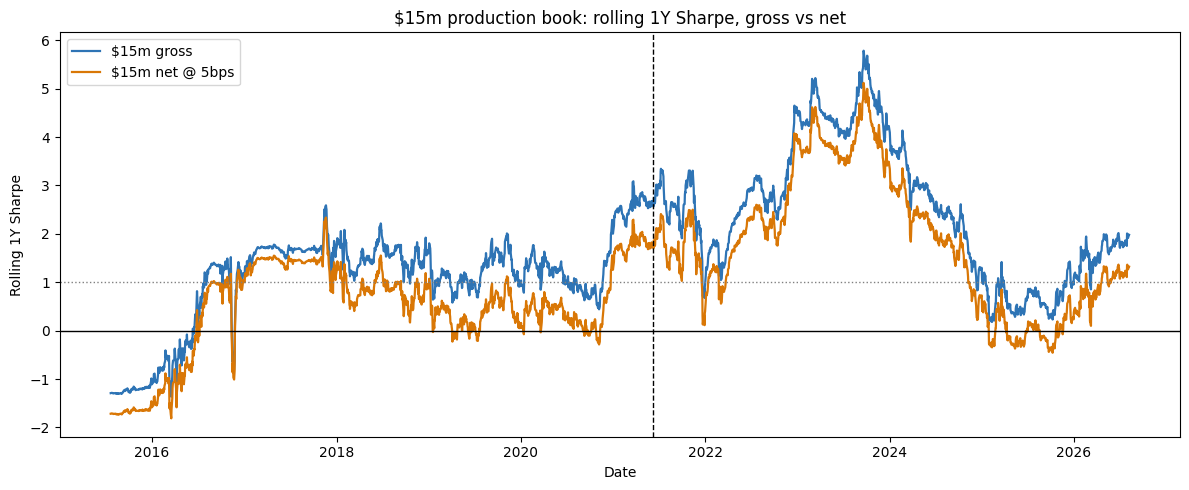

capacity available from 2013-08-26
rolling window 252d, first value 2015-07-21, last 2026-08-07
       $15m gross  $15m net @ 5bps
count    2776.000         2776.000
mean        1.753            1.134
std         1.366            1.347
min        -1.365           -1.812
25%         1.016            0.306
50%         1.595            0.979
75%         2.516            1.801
max         5.783            5.119


In [96]:
# ============================================================
# 15.2c $15m PRODUCTION BOOK: ROLLING 1Y GROSS vs NET @ 2bps
# ============================================================
# Separate figure from 15.2b. That chart isolates the liquidity effect at zero
# cost; this one shows what the deployed book delivers after transaction costs.
# `prod_book` is the only book in the notebook built with PROD_COST_BPS, so its
# "net" series is the costed path rather than a re-derived one.
# ============================================================

# The water-filled book only means anything once capacity exists. Open interest
# begins part-way through the sample, so dates before the first finite capacity
# print are dropped rather than plotted as a deployed book that could not have
# been sized.
_cap_available = capacity_by_depth[DYNAMIC_MIN_DEPTH].notna().any(axis=1)
CAPACITY_START = _cap_available.idxmax()
assert bool(_cap_available.loc[CAPACITY_START])

prod_rolling = pd.concat(
    {
        f"${PROD_AUM/1e6:.0f}m gross": prod_book["gross"],
        f"${PROD_AUM/1e6:.0f}m net @ {PROD_COST_BPS:.0f}bps": prod_book["net"],
    },
    axis=1,
).loc[CAPACITY_START:].dropna(how="any")

prod_rolling_sharpe = sharpe(
    prod_rolling,
    window=SHARPE_WINDOW,
    min_periods=SHARPE_WINDOW,
).dropna(how="any")

assert prod_rolling_sharpe.notna().all().all()

fig, ax = plt.subplots(figsize=(12, 5))
for col, color in zip(prod_rolling_sharpe.columns, ["#2E74B5", "#D97706"]):
    ax.plot(prod_rolling_sharpe.index, prod_rolling_sharpe[col],
            linewidth=1.6, label=col, color=color)
ax.axhline(0, color="black", linewidth=1)
ax.axhline(1, color="grey", linestyle=":", linewidth=1)
ax.axvline(pd.Timestamp(TEST_START), color="black", linestyle="--", linewidth=1)
ax.set_ylabel("Rolling 1Y Sharpe")
ax.set_xlabel("Date")
ax.set_title(f"${PROD_AUM/1e6:.0f}m production book: rolling 1Y Sharpe, gross vs net")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"capacity available from {CAPACITY_START.date()}")
print(f"rolling window {SHARPE_WINDOW}d, first value {prod_rolling_sharpe.index[0].date()}, "
      f"last {prod_rolling_sharpe.index[-1].date()}")
print(prod_rolling_sharpe.describe().round(3).to_string())


## Production decision after liquidity-aware depth testing

The research specification is:

\[\boxed{\text{deepest valid NS fit up to M8} \rightarrow \text{raw residual} \rightarrow \text{liquidity-aware traded depth M4 or M5}}\]

M1-M4 is the permanent floor. M5 is eligible only when its own causal liquidity/capacity can support the desired market allocation. M6-M8 are estimation inputs only and never become production legs. In this version the M5 cap is a frozen liquidity/governance rule and TEST Sharpe is not an input to depth selection.

The same specific-contract position path supplies gross P&L, turnover and transaction costs. The AUM and cost grids below are therefore the source of truth for current performance.


/tmp/ipykernel_1749/3480155869.py:32: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0, 0].boxplot([_alloc[m].dropna().values for m in _ord],
/tmp/ipykernel_1749/3480155869.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax[0, 1].boxplot(_leg_vals, labels=[f"M{k}" for k in _ranks],


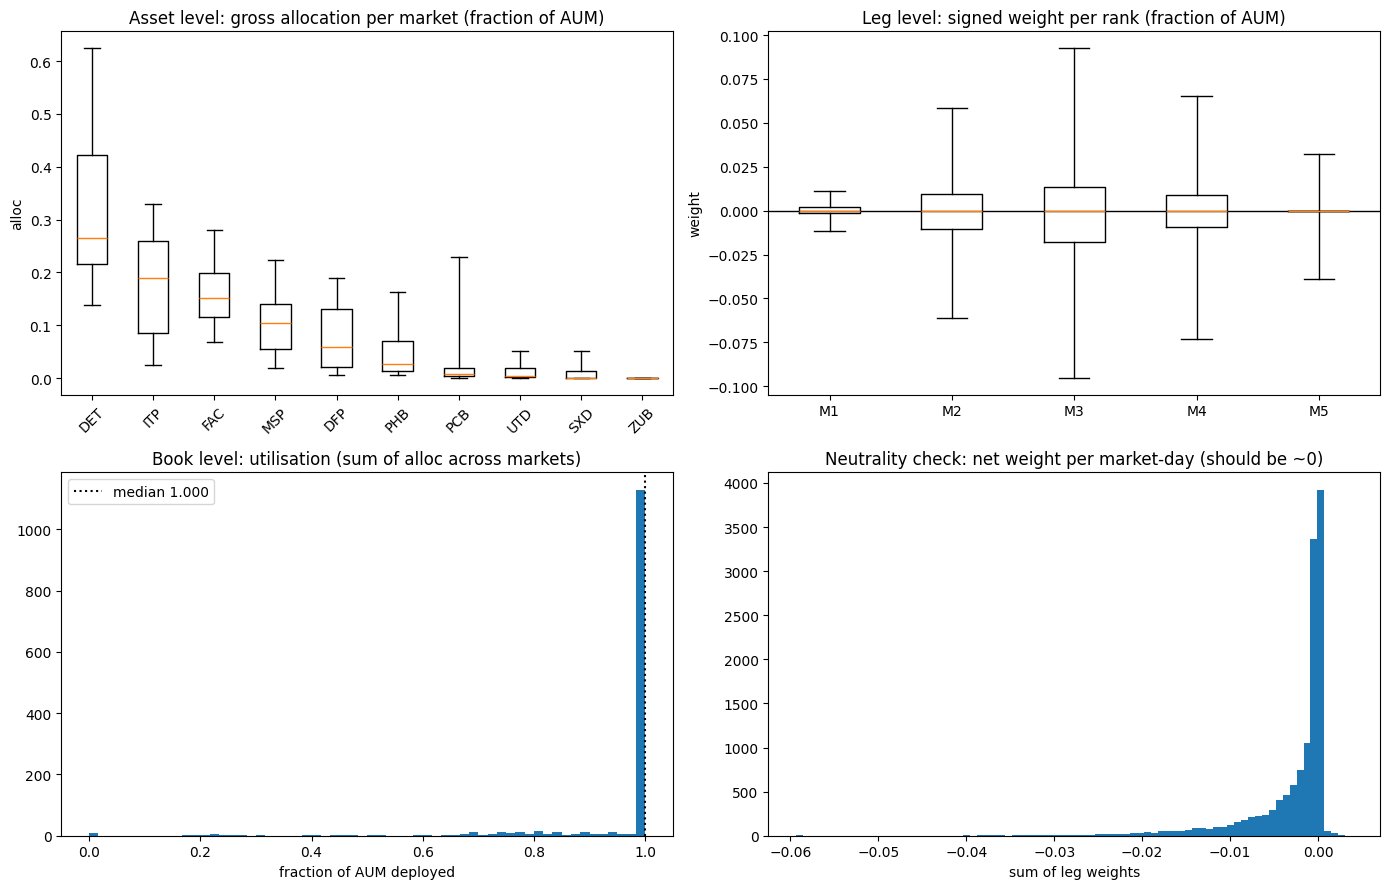

test window 2021-06-07 -> 2026-08-07  (1316 days)

ASSET LEVEL, gross allocation per market (fraction of AUM)


,mean,5%,50%,95%,max
DET,0.3219,0.1381,0.2661,0.6251,0.7968
ITP,0.1757,0.0243,0.1902,0.3292,0.4123
FAC,0.1613,0.0672,0.1509,0.2812,0.8085
MSP,0.1062,0.0195,0.1036,0.2251,0.3310
DFP,0.0774,0.0066,0.0586,0.1892,0.2638
PHB,0.0492,0.0050,0.0271,0.1629,0.2346
PCB,0.0453,0.0008,0.0078,0.2298,0.4097
UTD,0.0129,0.0004,0.0035,0.0522,0.0971
SXD,0.0113,0.0000,0.0011,0.0511,0.1245
ZUB,0.0000,0.0000,0.0000,0.0000,0.0000



LEG LEVEL, signed weight pooled across markets


,mean,5%,50%,95%
M1,0.00013,-0.01157,0.0,0.01108
M2,-0.00088,-0.06126,0.0,0.05856
M3,-0.00077,-0.09535,0.0,0.09275
M4,-0.00009,-0.07324,0.0,0.06541
M5,-0.00133,-0.03882,0.0,0.03222



LEG LEVEL, share of gross by rank


M1    0.042
M2    0.229
M3    0.361
M4    0.271
M5    0.096
dtype: float64


BOOK LEVEL
  utilisation   mean 0.958  p5 0.735  p95 1.000  max 1.000
  markets held  mean 8.67
  max |net weight| per market-day: 5.94e-02


In [97]:
# ============================================================
# POSITION DISTRIBUTIONS, TEST WINDOW
# ============================================================
#
# Three levels, because they answer different questions:
#
#   LEG      final_weights[k][m] is the signed weight on rank k of market m as
#            a fraction of AUM. This is what hits an order book, and where the
#            capacity caps bite.
#   ASSET    alloc[m] is the market's gross allocation, unsigned, since the
#            direction lives in the legs. The butterfly is level/slope/curvature
#            neutral, so per-market NET weight is ~0 by construction and is
#            plotted only as a correctness check.
#   BOOK     utilisation = sum of alloc across markets, i.e. how much of AUM is
#            deployed on a given day.
# ============================================================

import matplotlib.pyplot as plt

_idx = prod_book["net"].loc[TEST_START:].dropna().index
_alloc = prod_book["alloc"].loc[_idx]
_fw = prod_book["final_weights"]
_ranks = sorted(_fw)

_legs = {k: _fw[k].loc[_idx] for k in _ranks}
_net_by_mkt = sum(_legs[k] for k in _ranks)
_util = _alloc.sum(axis=1)

fig, ax = plt.subplots(2, 2, figsize=(14, 9))

_ord = _alloc.median().sort_values(ascending=False).index
ax[0, 0].boxplot([_alloc[m].dropna().values for m in _ord],
                 labels=list(_ord), showfliers=False, whis=(5, 95))
ax[0, 0].set_title("Asset level: gross allocation per market (fraction of AUM)")
ax[0, 0].set_ylabel("alloc")
ax[0, 0].tick_params(axis="x", rotation=45)

_leg_vals = [pd.concat([_legs[k][m] for m in _alloc.columns]).dropna().values
             for k in _ranks]
ax[0, 1].boxplot(_leg_vals, labels=[f"M{k}" for k in _ranks],
                 showfliers=False, whis=(5, 95))
ax[0, 1].axhline(0, color="black", linewidth=1)
ax[0, 1].set_title("Leg level: signed weight per rank (fraction of AUM)")
ax[0, 1].set_ylabel("weight")

ax[1, 0].hist(_util.dropna().values, bins=60)
ax[1, 0].axvline(_util.median(), linestyle=":", color="black",
                 label=f"median {_util.median():.3f}")
ax[1, 0].set_title("Book level: utilisation (sum of alloc across markets)")
ax[1, 0].set_xlabel("fraction of AUM deployed")
ax[1, 0].legend()

ax[1, 1].hist(_net_by_mkt.values.ravel()[np.isfinite(_net_by_mkt.values.ravel())],
              bins=80)
ax[1, 1].set_title("Neutrality check: net weight per market-day (should be ~0)")
ax[1, 1].set_xlabel("sum of leg weights")

plt.tight_layout()
plt.show()

print(f"test window {_idx[0].date()} -> {_idx[-1].date()}  ({len(_idx)} days)\n")

print("ASSET LEVEL, gross allocation per market (fraction of AUM)")
display(_alloc.describe(percentiles=[.05, .5, .95]).T
        .loc[_ord, ["mean", "5%", "50%", "95%", "max"]].round(4))

print("\nLEG LEVEL, signed weight pooled across markets")
_lt = pd.DataFrame({f"M{k}": pd.concat([_legs[k][m] for m in _alloc.columns]).describe(
    percentiles=[.05, .5, .95]) for k in _ranks}).T
display(_lt[["mean", "5%", "50%", "95%"]].round(5))

print("\nLEG LEVEL, share of gross by rank")
_gross_by_leg = pd.Series({f"M{k}": _legs[k].abs().sum().sum() for k in _ranks})
display((_gross_by_leg / _gross_by_leg.sum()).round(3))

print("\nBOOK LEVEL")
print(f"  utilisation   mean {_util.mean():.3f}  p5 {_util.quantile(.05):.3f}  "
      f"p95 {_util.quantile(.95):.3f}  max {_util.max():.3f}")
print(f"  markets held  mean {(_alloc > 1e-9).sum(axis=1).mean():.2f}")
print(f"  max |net weight| per market-day: {np.nanmax(np.abs(_net_by_mkt.values)):.2e}")

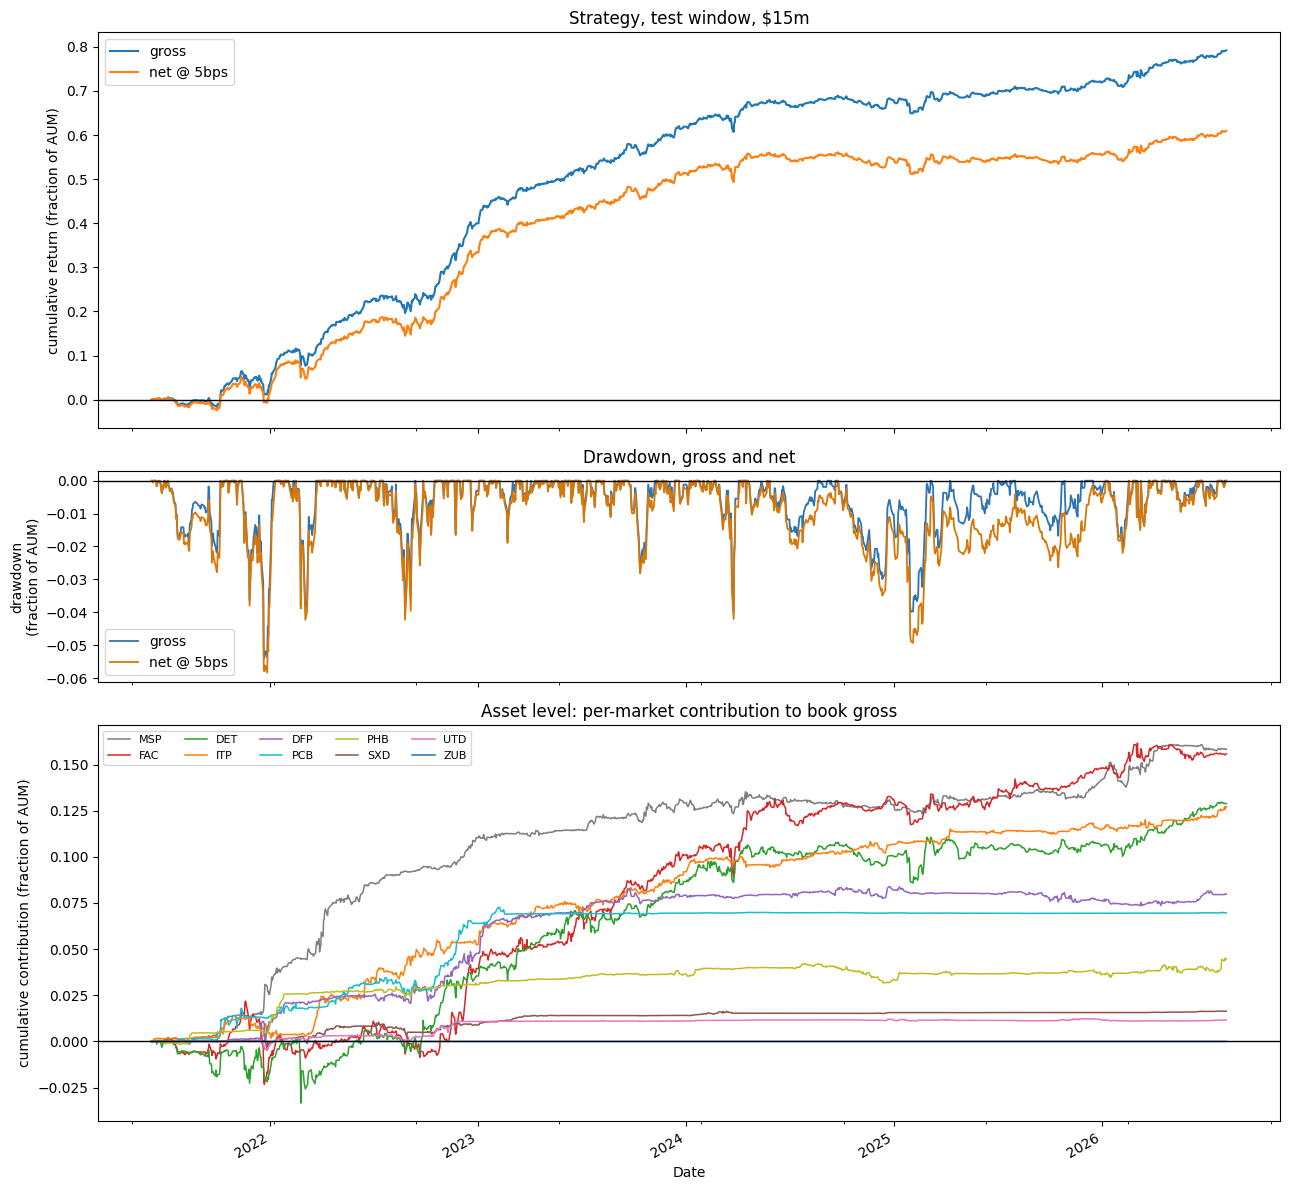

test window 2021-06-07 -> 2026-08-07  (1316 days)

STRATEGY LEVEL
  realised vol, gross : 5.91% annualised
  realised vol, net   : 5.90% annualised
  cumulative gross    : 79.21% of AUM   ($11.88m)
  cumulative net      : 60.94% of AUM   ($9.14m)
  Sharpe, net         : 1.977
  max drawdown, gross : -5.40% of AUM
  max drawdown, net   : -5.84% of AUM

ASSET LEVEL


,cum contrib,$m,share of gross,vol (ann),vol share,Sharpe,days live
Market,,,,,,,
MSP,0.1583,2.3743,0.1998,0.0160,0.2701,1.9162,1305
FAC,0.1558,2.3368,0.1967,0.0257,0.4346,1.1625,1316
DET,0.1288,1.9319,0.1626,0.0275,0.4656,0.9052,1304
ITP,0.1271,1.9068,0.1605,0.0137,0.2328,1.7896,1302
DFP,0.0799,1.1981,0.1008,0.0132,0.2240,1.1663,1305
PCB,0.0696,1.0447,0.0879,0.0093,0.1575,1.4586,1294
PHB,0.0448,0.6714,0.0565,0.0067,0.1134,1.2816,1314
SXD,0.0163,0.2452,0.0206,0.0057,0.0960,0.7108,1022
UTD,0.0115,0.1729,0.0146,0.0035,0.0590,0.6333,1316


sum of per-market vols 12.12% (9/10 markets live) vs book vol 5.91%  -> diversification ratio 2.05x


In [98]:
# ============================================================
# CUMULATIVE RETURNS, TEST WINDOW
# ============================================================
#
# Cumulative SUM, not compounded. The book runs at a fixed PROD_AUM and every
# series here is already a fraction of that AUM, so market_gross sums across
# markets to the book gross. Summing keeps the attribution additive: each
# market's line is its contribution to the book line. Compounding would break
# that and would also imply reinvestment the capacity model does not allow.
#
# Volatility is the annualised standard deviation of DAILY returns over the
# same window, so it is directly comparable across panels.
#
# CORRECTED: a drawdown panel is added (gross and net) between the cumulative
# return panel and the per-market attribution panel, so the production book's
# drawdown path -- previously left out of this figure -- is shown explicitly.
# ============================================================

import matplotlib.pyplot as plt

_idx = prod_book["net"].loc[TEST_START:].dropna().index
_net = prod_book["net"].loc[_idx]
_gross = prod_book["gross"].loc[_idx]
_mkt = prod_book["market_gross"].loc[_idx]

_ann = lambda s: s.std() * np.sqrt(TRADING_DAYS)

_gross_cum = _gross.cumsum()
_net_cum = _net.cumsum()
_gross_dd = _gross_cum - _gross_cum.cummax()
_net_dd = _net_cum - _net_cum.cummax()

fig, ax = plt.subplots(
    3, 1, figsize=(13, 12), sharex=True,
    gridspec_kw={"height_ratios": [3, 1.6, 3]},
)

_gross_cum.plot(ax=ax[0], linewidth=1.5, label="gross")
_net_cum.plot(ax=ax[0], linewidth=1.5, label=f"net @ {PROD_COST_BPS:.0f}bps")
ax[0].axhline(0, color="black", linewidth=1)
ax[0].set_ylabel("cumulative return (fraction of AUM)")
ax[0].set_title(f"Strategy, test window, ${PROD_AUM/1e6:.0f}m")
ax[0].legend(loc="upper left")

_gross_dd.plot(ax=ax[1], linewidth=1.3, label="gross", color="#2E74B5")
_net_dd.plot(ax=ax[1], linewidth=1.3, label=f"net @ {PROD_COST_BPS:.0f}bps", color="#D97706")
ax[1].axhline(0, color="black", linewidth=1)
ax[1].set_ylabel("drawdown\n(fraction of AUM)")
ax[1].set_title("Drawdown, gross and net")
ax[1].legend(loc="lower left")

_ordered = _mkt.sum().sort_values(ascending=False).index
for m in _ordered:
    _mkt[m].fillna(0.0).cumsum().plot(ax=ax[2], linewidth=1.1, label=m, color=MARKET_COLORS.get(m))
ax[2].axhline(0, color="black", linewidth=1)
ax[2].set_ylabel("cumulative contribution (fraction of AUM)")
ax[2].set_title("Asset level: per-market contribution to book gross")
ax[2].legend(loc="upper left", ncol=5, fontsize=8)

plt.tight_layout()
plt.show()

print(f"test window {_idx[0].date()} -> {_idx[-1].date()}  ({len(_idx)} days)\n")

print("STRATEGY LEVEL")
print(f"  realised vol, gross : {_ann(_gross):.2%} annualised")
print(f"  realised vol, net   : {_ann(_net):.2%} annualised")
print(f"  cumulative gross    : {_gross.sum():.2%} of AUM   "
      f"(${_gross.sum() * PROD_AUM / 1e6:.2f}m)")
print(f"  cumulative net      : {_net.sum():.2%} of AUM   "
      f"(${_net.sum() * PROD_AUM / 1e6:.2f}m)")
print(f"  Sharpe, net         : {_net.mean() / _net.std() * np.sqrt(TRADING_DAYS):.3f}")
print(f"  max drawdown, gross : {_gross_dd.min():.2%} of AUM")
print(f"  max drawdown, net   : {_net_dd.min():.2%} of AUM")

print("\nASSET LEVEL")
_mkt_vols = {m: _ann(_mkt[m].dropna()) for m in _ordered}
_rows = []
for m in _ordered:
    s = _mkt[m].dropna()
    _rows.append({
        "Market": m,
        "cum contrib": _mkt[m].fillna(0.0).sum(),
        "$m": _mkt[m].fillna(0.0).sum() * PROD_AUM / 1e6,
        "share of gross": _mkt[m].fillna(0.0).sum() / _gross.sum(),
        "vol (ann)": _mkt_vols[m],
        "vol share": _mkt_vols[m] / _ann(_gross),
        "Sharpe": s.mean() / s.std() * np.sqrt(TRADING_DAYS) if s.std() > 0 else np.nan,
        "days live": int(s.notna().sum()),
    })
display(pd.DataFrame(_rows).set_index("Market").round(4))

# Markets with no live day in the window have no measurable vol. Skipping them
# is not the same as calling them zero-vol, so the count is printed alongside.
_vol_sum = sum(v for v in _mkt_vols.values() if np.isfinite(v))
_n_vol = sum(np.isfinite(v) for v in _mkt_vols.values())
print(f"sum of per-market vols {_vol_sum:.2%} ({_n_vol}/{len(_mkt_vols)} markets live) "
      f"vs book vol {_ann(_gross):.2%}  -> diversification ratio "
      f"{_vol_sum / _ann(_gross):.2f}x")


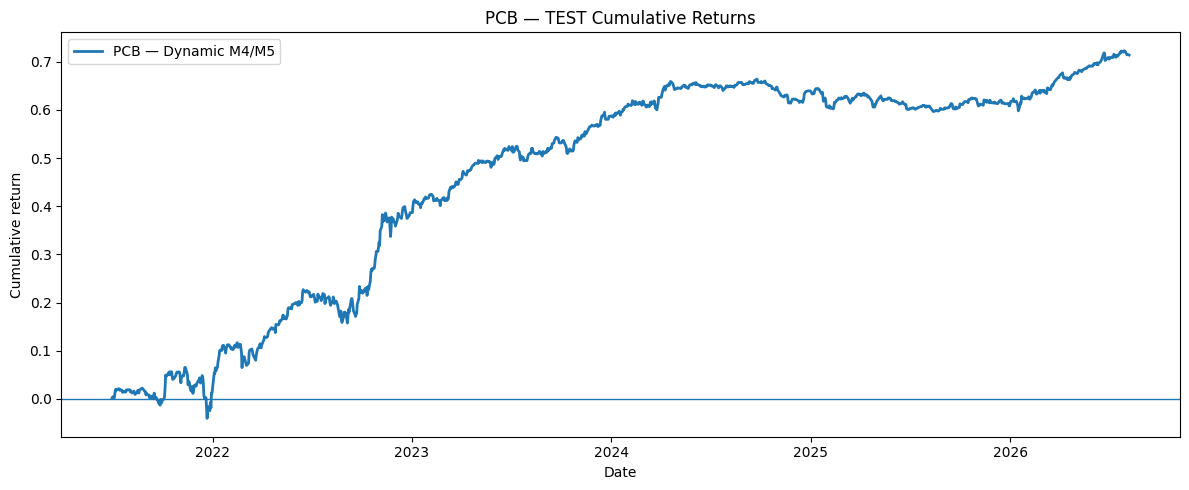

,PCB TEST
N,1303.0000
Mean,0.1381
Alpha daily,0.0005
Alpha t-stat (NW),3.3612
Alpha p-value (NW),0.0008
NW lags,21.0000
Volatility,0.0871
Downside volatility,0.0609
Sharpe ratio,1.5855
Skewness,0.5098


TEST start       : 2021-07-01
TEST end         : 2026-08-07
N                : 1303
Cumulative return: 71.40%
Sharpe           : 1.586


In [99]:
# ============================================================
# PCB — TEST CUMULATIVE RETURNS
# Dynamic M4/M5 standalone market strategy
# ============================================================

pcb_test = (
    uncon_book["market_gross"]["PCB"]
    .loc[TEST_START:]
    .dropna()
)

pcb_cum = pcb_test.cumsum()

plt.figure(figsize=(12, 5))

plt.plot(
    pcb_cum.index,
    pcb_cum,
    linewidth=2,
    label="PCB — Dynamic M4/M5"
)

plt.axhline(0, linewidth=1)

plt.title("PCB — TEST Cumulative Returns")
plt.ylabel("Cumulative return")
plt.xlabel("Date")
plt.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# TEST statistics
# ------------------------------------------------------------

pcb_stats = performance_stats(pcb_test)

display(
    pcb_stats.to_frame("PCB TEST").round(4)
)

print(f"TEST start       : {pcb_test.index[0].date()}")
print(f"TEST end         : {pcb_test.index[-1].date()}")
print(f"N                : {len(pcb_test)}")
print(f"Cumulative return: {pcb_test.sum():.2%}")
print(
    f"Sharpe           : "
    f"{pcb_test.mean() / pcb_test.std() * np.sqrt(TRADING_DAYS):.3f}"
)

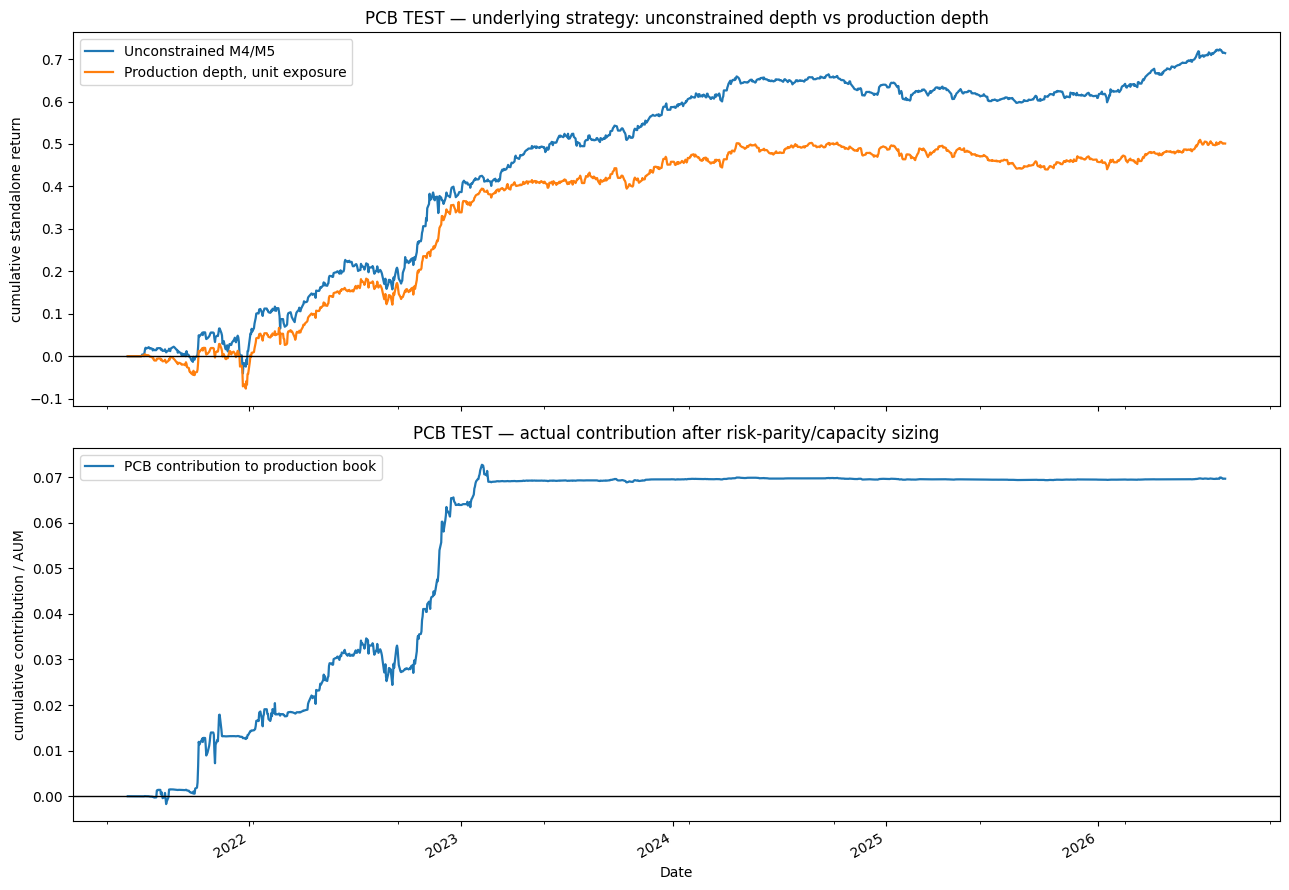

PCB TEST DEPTH USAGE
--------------------
Unconstrained M5 share : 100.00%
Production M5 share    : 13.20%
Depth differs          : 1131 days

PCB PRODUCTION ALLOCATION
-------------------------
Mean allocation : 4.56%
Median          : 0.78%
95th percentile : 23.17%
Min             : 0.00%
Max             : 40.97%

PCB TEST SHARPE
----------------
Unconstrained M4/M5                  : 1.586
Production depth, unit exposure      : 1.205
Actual production contribution       : 1.458


In [100]:
# ============================================================
# PCB — DECOMPOSE UNCONSTRAINED VS PRODUCTION
# TEST WINDOW
# ============================================================

PCB = "PCB"

# ------------------------------------------------------------
# 1. UNCONSTRAINED PCB
#    M5 whenever the raw M5 candidate is available
# ------------------------------------------------------------

pcb_uncon = (
    uncon_book["market_gross"][PCB]
    .loc[TEST_START:]
)


# ------------------------------------------------------------
# 2. REBUILD PCB USING THE PRODUCTION DEPTH PATH,
#    BUT REMOVE PORTFOLIO ALLOCATION
#
#    This isolates the effect of:
#        unconstrained depth selection
#             vs
#        liquidity-aware production depth selection
# ------------------------------------------------------------

pcb_prod_depth_weights = {
    k: pd.DataFrame(
        0.0,
        index=RISK_INDEX,
        columns=price_universe,
    )
    for k in range(1, DYNAMIC_MAX_DEPTH + 1)
}

for depth in DYNAMIC_DEPTHS:

    use_depth = prod_depth[PCB].eq(depth)

    for k in range(1, depth + 1):

        pcb_prod_depth_weights[k].loc[use_depth, PCB] = (
            candidate_weights_by_depth[depth][k]
            .loc[use_depth, PCB]
        )


# Only PCB needs to carry positions here.
# Other markets stay zero.

pcb_prod_depth_book = run_contract_positions(
    pcb_prod_depth_weights,
    prices,
    tickers,
    price_universe,
    index=RISK_INDEX,
    max_rank=DYNAMIC_MAX_DEPTH,
    depth_panel=prod_depth,
    min_depth=DYNAMIC_MIN_DEPTH,
    lag=LAG_BASE,
    cost_bps=0.0,
    market_aggregation="sum",
)

pcb_prod_depth_raw = (
    pcb_prod_depth_book["market_gross"][PCB]
    .loc[TEST_START:]
)


# ------------------------------------------------------------
# 3. ACTUAL PRODUCTION CONTRIBUTION
#    Includes risk-parity + capacity allocation
# ------------------------------------------------------------

pcb_prod_contrib = (
    prod_book["market_gross"][PCB]
    .loc[TEST_START:]
)


# ------------------------------------------------------------
# ALIGN
# ------------------------------------------------------------

pcb_compare = pd.concat(
    {
        "Unconstrained M4/M5": pcb_uncon,
        "Production depth, unit exposure": pcb_prod_depth_raw,
        "Actual production contribution": pcb_prod_contrib,
    },
    axis=1,
)


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(2, 1, figsize=(13, 9), sharex=True)


# ------------------------------------------------------------
# TOP:
# Compare underlying PCB strategy
# ------------------------------------------------------------

pcb_compare[
    [
        "Unconstrained M4/M5",
        "Production depth, unit exposure",
    ]
].fillna(0.0).cumsum().plot(
    ax=ax[0],
    linewidth=1.6,
)

ax[0].axhline(0, color="black", linewidth=1)
ax[0].set_ylabel("cumulative standalone return")
ax[0].set_title(
    "PCB TEST — underlying strategy: "
    "unconstrained depth vs production depth"
)


# ------------------------------------------------------------
# BOTTOM:
# Actual contribution to $15m book
# ------------------------------------------------------------

pcb_compare[
    "Actual production contribution"
].fillna(0.0).cumsum().plot(
    ax=ax[1],
    linewidth=1.6,
    label="PCB contribution to production book",
)

ax[1].axhline(0, color="black", linewidth=1)
ax[1].set_ylabel("cumulative contribution / AUM")
ax[1].set_title(
    "PCB TEST — actual contribution after risk-parity/capacity sizing"
)
ax[1].legend()

plt.tight_layout()
plt.show()


# ============================================================
# DIAGNOSTICS
# ============================================================

print("PCB TEST DEPTH USAGE")
print("--------------------")

_u = uncon_depth[PCB].loc[TEST_START:]
_p = prod_depth[PCB].loc[TEST_START:]

print(
    f"Unconstrained M5 share : "
    f"{_u.eq(5).sum() / _u.notna().sum():.2%}"
)

print(
    f"Production M5 share    : "
    f"{_p.eq(5).sum() / _p.notna().sum():.2%}"
)

print(
    f"Depth differs          : "
    f"{((_u != _p) & _u.notna() & _p.notna()).sum()} days"
)


print("\nPCB PRODUCTION ALLOCATION")
print("-------------------------")

pcb_alloc_test = prod_alloc[PCB].loc[TEST_START:].dropna()

print(f"Mean allocation : {pcb_alloc_test.mean():.2%}")
print(f"Median          : {pcb_alloc_test.median():.2%}")
print(f"95th percentile : {pcb_alloc_test.quantile(0.95):.2%}")
print(f"Min             : {pcb_alloc_test.min():.2%}")
print(f"Max             : {pcb_alloc_test.max():.2%}")


print("\nPCB TEST SHARPE")
print("----------------")

for col in [
    "Unconstrained M4/M5",
    "Production depth, unit exposure",
    "Actual production contribution",
]:
    x = pcb_compare[col].dropna()

    sr = (
        x.mean() / x.std() * np.sqrt(TRADING_DAYS)
        if x.std() > 0
        else np.nan
    )

    print(f"{col:37s}: {sr:.3f}")

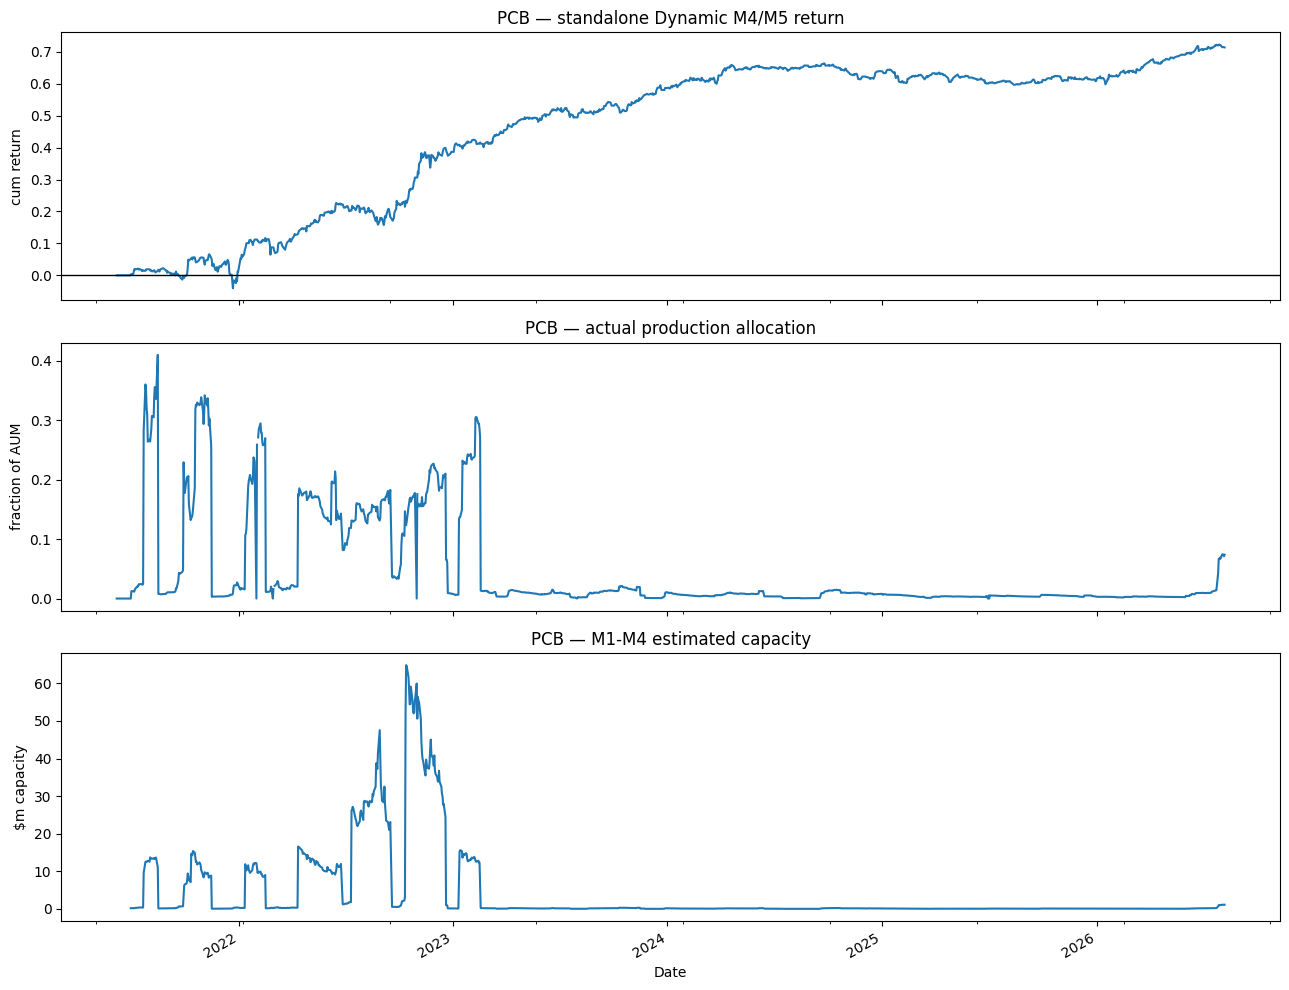

In [101]:
# ============================================================
# PCB — WHY DOES PRODUCTION CONTRIBUTION FLATTEN?
# ============================================================

fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True)

# 1. Standalone PCB alpha
pcb_raw = uncon_book["market_gross"]["PCB"].loc[TEST_START:]
pcb_raw.fillna(0).cumsum().plot(
    ax=ax[0],
    linewidth=1.5,
)

ax[0].axhline(0, color="black", linewidth=1)
ax[0].set_title("PCB — standalone Dynamic M4/M5 return")
ax[0].set_ylabel("cum return")


# 2. Actual production allocation
prod_alloc["PCB"].loc[TEST_START:].plot(
    ax=ax[1],
    linewidth=1.5,
)

ax[1].set_title("PCB — actual production allocation")
ax[1].set_ylabel("fraction of AUM")


# 3. PCB M1-M4 capacity
(
    capacity_by_depth[4]["PCB"]
    .loc[TEST_START:]
    / 1e6
).plot(
    ax=ax[2],
    linewidth=1.5,
)

ax[2].set_title("PCB — M1-M4 estimated capacity")
ax[2].set_ylabel("$m capacity")

plt.tight_layout()
plt.show()

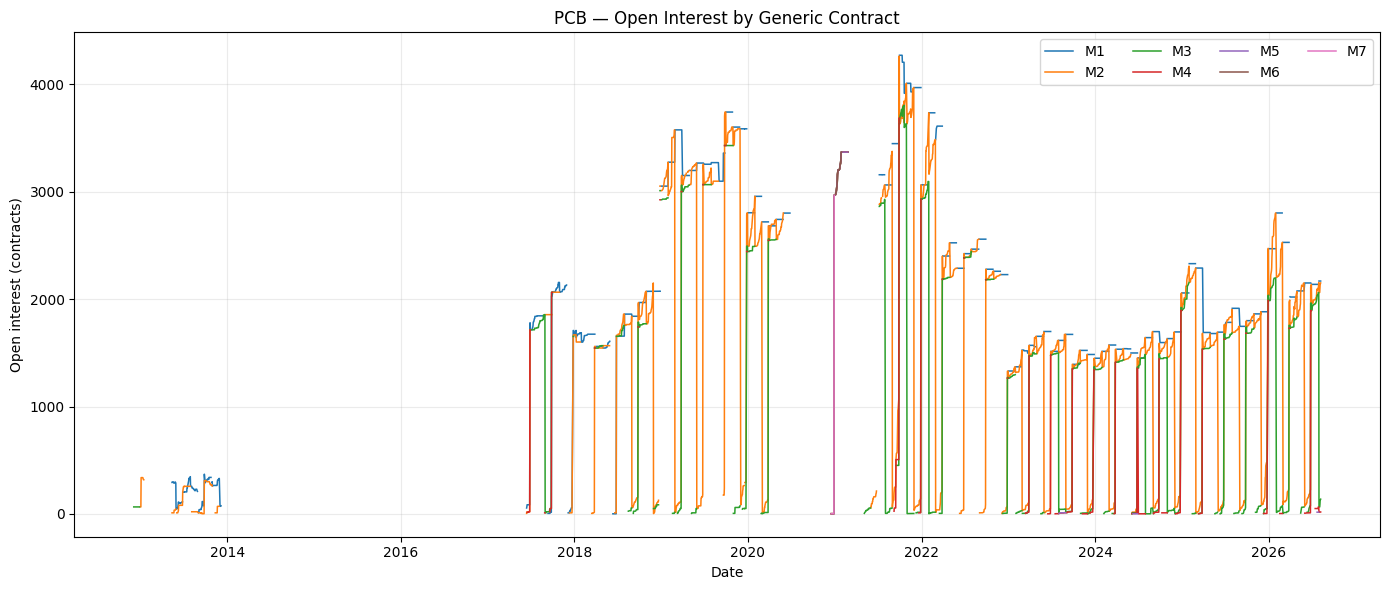

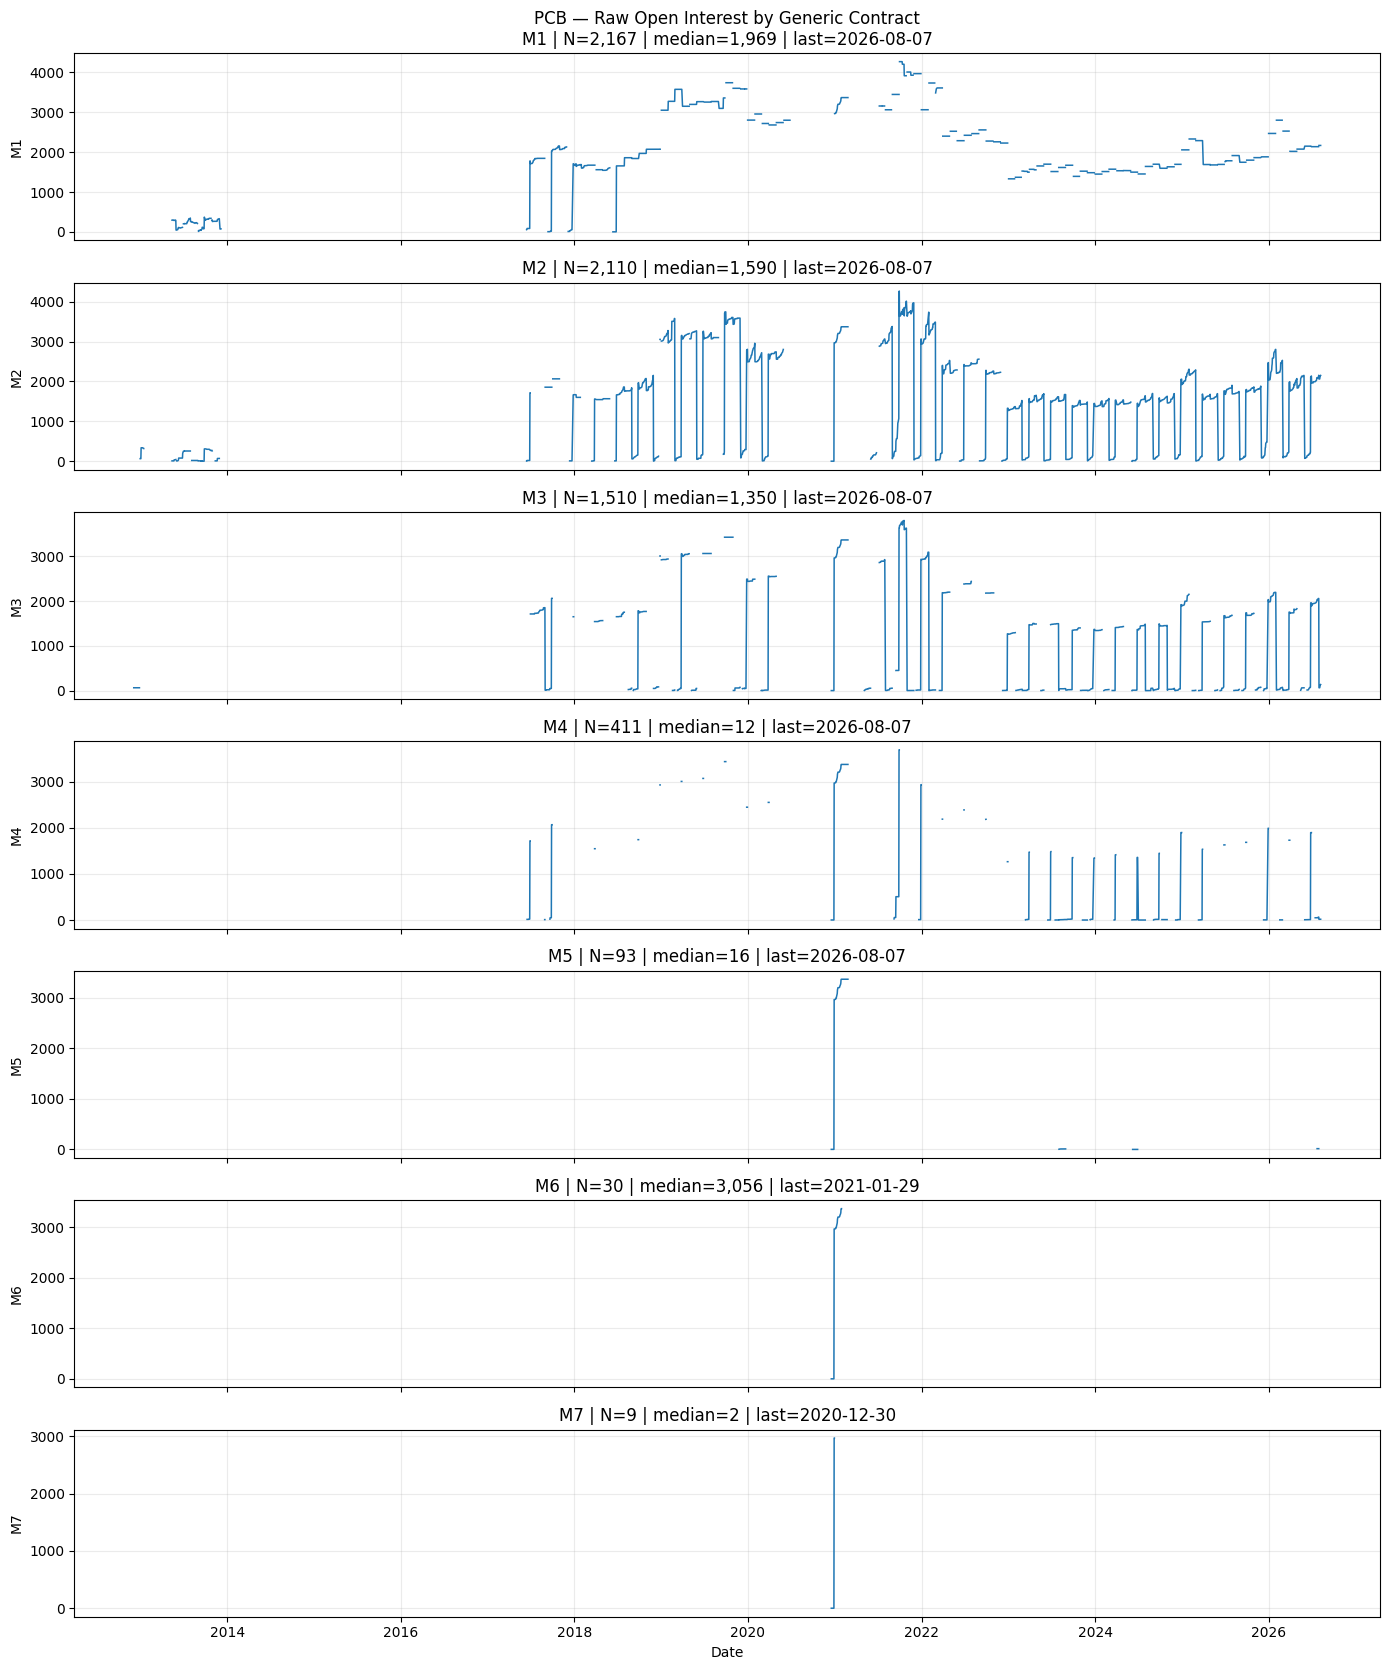

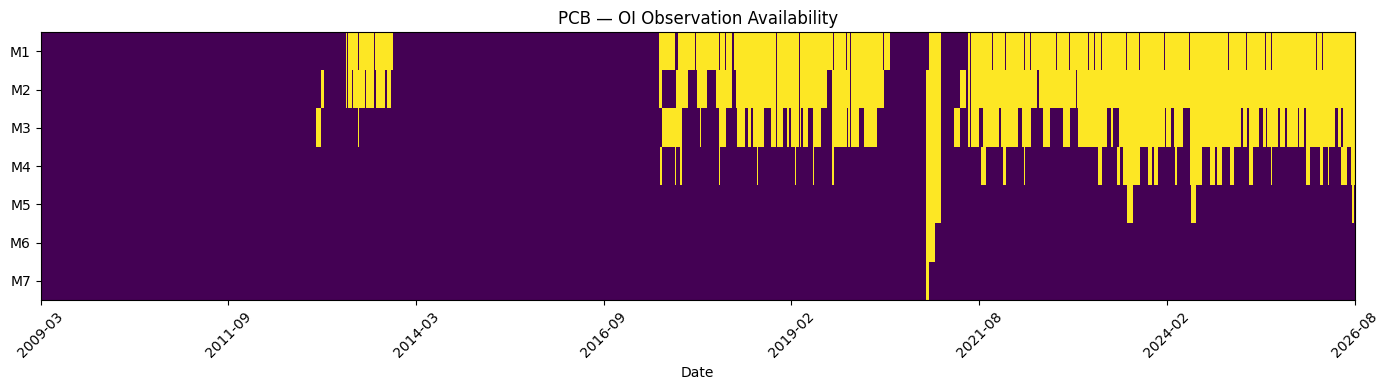

/tmp/ipykernel_1749/2119598179.py:164: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(pcb_oi_summary.round(2))


,N prints,Start,End,Mean OI,Median OI,P25 OI,P75 OI,Max OI,% coverage
Contract,,,,,,,,,
M1,2167,2013-05-03,2026-08-07,2102.37,1969.0,1596.00,2802.00,4272.0,0.49
M2,2110,2012-12-31,2026-08-07,1538.65,1590.0,139.25,2288.00,4265.0,0.48
M3,1510,2012-12-04,2026-08-07,1137.17,1350.0,20.00,1948.25,3806.0,0.34
M4,411,2017-06-16,2026-08-07,714.26,12.0,4.00,1384.50,3686.0,0.09
M5,93,2020-12-17,2026-08-07,1471.15,16.0,2.00,3268.00,3370.0,0.02
M6,30,2020-12-17,2021-01-29,2415.47,3055.5,2968.00,3206.75,3370.0,0.01
M7,9,2020-12-17,2020-12-30,661.11,2.0,2.00,2.00,2968.0,0.00


In [102]:
# ============================================================
# PCB — OPEN INTEREST BY GENERIC CONTRACT
# ============================================================

PCB_OI_COLS = [
    c for c in [f"PCB{k}" for k in range(1, 8)]
    if c in open_interest.columns
]

pcb_oi = open_interest[PCB_OI_COLS].copy()


# ============================================================
# 1. ALL CONTRACTS — SAME AXIS
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

for col in PCB_OI_COLS:
    ax.plot(
        pcb_oi.index,
        pcb_oi[col],
        linewidth=1.1,
        label=col.replace("PCB", "M")
    )

ax.set_title("PCB — Open Interest by Generic Contract")
ax.set_ylabel("Open interest (contracts)")
ax.set_xlabel("Date")
ax.legend(ncol=4)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ============================================================
# 2. EACH CONTRACT SEPARATELY
# ============================================================

n = len(PCB_OI_COLS)

fig, axes = plt.subplots(
    n,
    1,
    figsize=(14, 2.4 * n),
    sharex=True
)

for ax, col in zip(axes, PCB_OI_COLS):

    s = pcb_oi[col]

    # Raw Bloomberg observations only.
    # Do NOT forward-fill: gaps should remain visible.
    ax.plot(
        s.index,
        s,
        linewidth=1.1
    )

    ax.set_ylabel(col.replace("PCB", "M"))
    ax.grid(alpha=0.25)

    valid = s.dropna()

    if len(valid):
        ax.set_title(
            f"{col.replace('PCB', 'M')} | "
            f"N={len(valid):,} | "
            f"median={valid.median():,.0f} | "
            f"last={valid.index[-1].date()}"
        )

axes[0].set_title(
    "PCB — Raw Open Interest by Generic Contract\n"
    + axes[0].get_title()
)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()


# ============================================================
# 3. OI PRINT AVAILABILITY
#    Important: distinguishes LOW OI from MISSING OI
# ============================================================

fig, ax = plt.subplots(figsize=(14, 4))

availability = pcb_oi.notna().astype(int)

ax.imshow(
    availability.T,
    aspect="auto",
    interpolation="nearest",
    extent=[
        pcb_oi.index[0].toordinal(),
        pcb_oi.index[-1].toordinal(),
        len(PCB_OI_COLS) - 0.5,
        -0.5,
    ],
)

ax.set_yticks(range(len(PCB_OI_COLS)))
ax.set_yticklabels(
    [c.replace("PCB", "M") for c in PCB_OI_COLS]
)

# Convert ordinal positions back into readable dates
ticks = np.linspace(
    pcb_oi.index[0].toordinal(),
    pcb_oi.index[-1].toordinal(),
    8
)

ax.set_xticks(ticks)
ax.set_xticklabels(
    [
        pd.Timestamp.fromordinal(int(x)).strftime("%Y-%m")
        for x in ticks
    ],
    rotation=45
)

ax.set_title("PCB — OI Observation Availability")
ax.set_xlabel("Date")

plt.tight_layout()
plt.show()


# ============================================================
# 4. SUMMARY TABLE
# ============================================================

summary = []

for col in PCB_OI_COLS:

    s = pcb_oi[col]
    x = s.dropna()

    summary.append({
        "Contract": col.replace("PCB", "M"),
        "N prints": len(x),
        "Start": x.index.min() if len(x) else pd.NaT,
        "End": x.index.max() if len(x) else pd.NaT,
        "Mean OI": x.mean(),
        "Median OI": x.median(),
        "P25 OI": x.quantile(0.25),
        "P75 OI": x.quantile(0.75),
        "Max OI": x.max(),
        "% coverage": s.notna().mean(),
    })

pcb_oi_summary = (
    pd.DataFrame(summary)
    .set_index("Contract")
)

display(pcb_oi_summary.round(2))